In [1]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (12, 7),
    "figure.dpi": 160,
    "axes.labelsize": 14,
    "axes.titlesize": 18,
    "legend.fontsize": 11,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "lines.markersize": 5,
    "axes.grid": False,
})

In [2]:
import numpy as np
import lightkurve as lk
from scipy.optimize import least_squares



# ----------------------------
# 1) Download one sector PDCSAP
# ----------------------------
TIC = "TIC 356896561"   # <-- replace with your target
SECTOR = None           # set to an int to force a sector, else picks the first available

sr = lk.search_lightcurve(TIC, mission="TESS", author="SPOC")
lcs = sr.download_all()

if SECTOR is not None:
    lc = [x for x in lcs if getattr(x, "sector", None) == SECTOR][0]
else:
    lc = lcs[0]  # quick start

# PDCSAP + quality mask
lc = lc.remove_nans().remove_outliers(sigma=7)
if hasattr(lc, "pdcsap_flux"):
    flux = lc.pdcsap_flux.value
    flux_err = lc.pdcsap_flux_err.value
else:
    flux = lc.flux.value
    flux_err = lc.flux_err.value if lc.flux_err is not None else np.ones_like(flux)*np.std(flux)

t = lc.time.value  # BTJD
# normalize by median per paper
flux = flux / np.nanmedian(flux)
flux_err = flux_err / np.nanmedian(flux)

# ----------------------------
# 2) Model pieces (paper-style)
# ----------------------------
def phase_fold(t, T0, P):
    # phase in [-0.5, 0.5)
    phi = ((t - T0) / P) % 1.0
    phi = np.where(phi >= 0.5, phi - 1.0, phi)
    return phi

def mikulasek_profile(x, d, Gamma, C):
    """
    x = (t - T) / d
    Using the paper's chosen Mikulášek form (their Eq. 7).
    We implement the 'shape-only' part; scale & baseline handled outside.
    """
    # Safe numeric handling
    z = np.cosh(x)
    inner = 1.0 - np.exp(1.0 - z)
    inner = np.clip(inner, 0.0, 1.0)  # prevent negatives from numeric issues
    return (1.0 - (inner**Gamma))**C

def model_flux(t, params):
    """
    Minimal 2-eclipse model:
    params = [T0, P, a0, a1, a2, d1, d2, G1, G2, C1, C2]
    a0 baseline, a1 depth scale primary, a2 depth scale secondary
    """
    T0, P, a0, a1, a2, d1, d2, G1, G2, C1, C2 = params

    # primary at phase 0, secondary at phase 0.5 (for circular orbit assumption in template stage)
    phi = phase_fold(t, T0, P)

    # Convert phase to time offset: dt = phi * P
    dt = phi * P

    # Primary eclipse centered at dt=0
    psi1 = mikulasek_profile(dt / d1, d=1.0, Gamma=G1, C=C1)
    # Secondary centered at dt = +P/2  => in dt-coordinates, center at +P/2 then wrap
    # easiest: shift dt by -P/2 and wrap to nearest
    dt2 = dt - 0.5 * P
    # wrap dt2 into [-P/2, P/2)
    dt2 = (dt2 + 0.5 * P) % P - 0.5 * P
    psi2 = mikulasek_profile(dt2 / d2, d=1.0, Gamma=G2, C=C2)

    # Build flux: baseline + scaled eclipse depressions.
    # mikulasek_profile returns something like an eclipse "shape"; we turn it into a dip by (1 - psi)
    return a0 - a1 * (1.0 - psi1) - a2 * (1.0 - psi2)

def residuals(params, t, f, ferr):
    m = model_flux(t, params)
    return (f - m) / ferr

# ----------------------------
# 3) Initial guesses
# ----------------------------
# Quick crude guesses:
T0_guess = t[np.argmin(flux)]   # rough primary minimum
P_guess = getattr(lc, "period", None)
P_guess = float(P_guess) if P_guess is not None else 1.0  # replace if known

p0 = np.array([
    T0_guess, P_guess,
    1.0,      # a0 baseline ~1 after normalization
    0.1, 0.05,# a1,a2 depths
    0.05, 0.05,# d1,d2 (days) rough
    2.0, 2.0, # Gamma
    2.0, 2.0  # C
])

# Bounds to keep things sane
lower = np.array([t.min(),  0.05,  0.5,  0.0,  0.0,  1e-3, 1e-3, 0.2, 0.2, 0.2, 0.2])
upper = np.array([t.max(), 50.0,  1.5,  2.0,  2.0,  1.0,  1.0, 20.0,20.0,20.0,20.0])

# ----------------------------
# 4) Fit (template stage: Δk=0)
# ----------------------------
res = least_squares(residuals, p0, bounds=(lower, upper), args=(t, flux, flux_err), max_nfev=2000)
best = res.x
print("Best-fit params:", best)
print("Reduced chi2 ~", np.sum(res.fun**2)/(len(res.fun)-len(best)))


/Users/admin-victor/Documents/.venv/lib/python3.14/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


Best-fit params: [1.71020129e+03 1.00204317e+00 9.95744807e-01 6.21970208e-03
 6.03707214e-03 5.08901828e-03 1.13785274e-01 2.00420657e-01
 5.71272695e+00 1.32141041e+01 2.88578637e+00]
Reduced chi2 ~ 3.5851921861189232e-06


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# ---- GLOBAL PLOT STYLE ----
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "font.size": 14,
    "axes.labelsize": 18,
    "axes.titlesize": 20,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 12,
    "lines.markersize": 5,
    "axes.linewidth": 1.2,
    "savefig.dpi": 300,
})

Flux std: 0.04207774
Resid std: 0.04202299678789993
Median flux_err: 23.725777
Min flux_err: 20.616035 Max flux_err: 26.89641


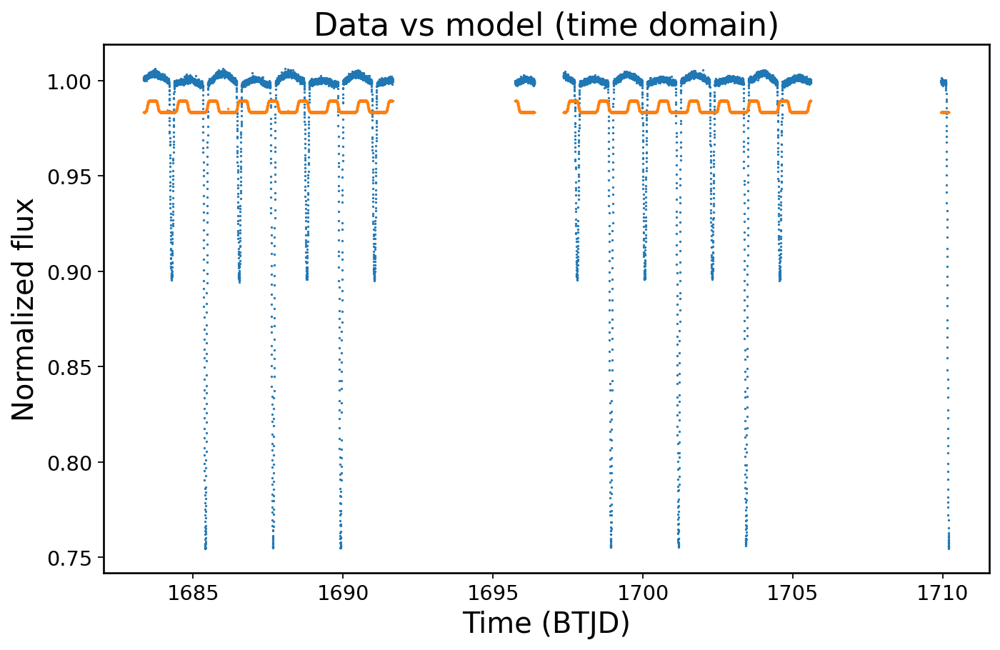

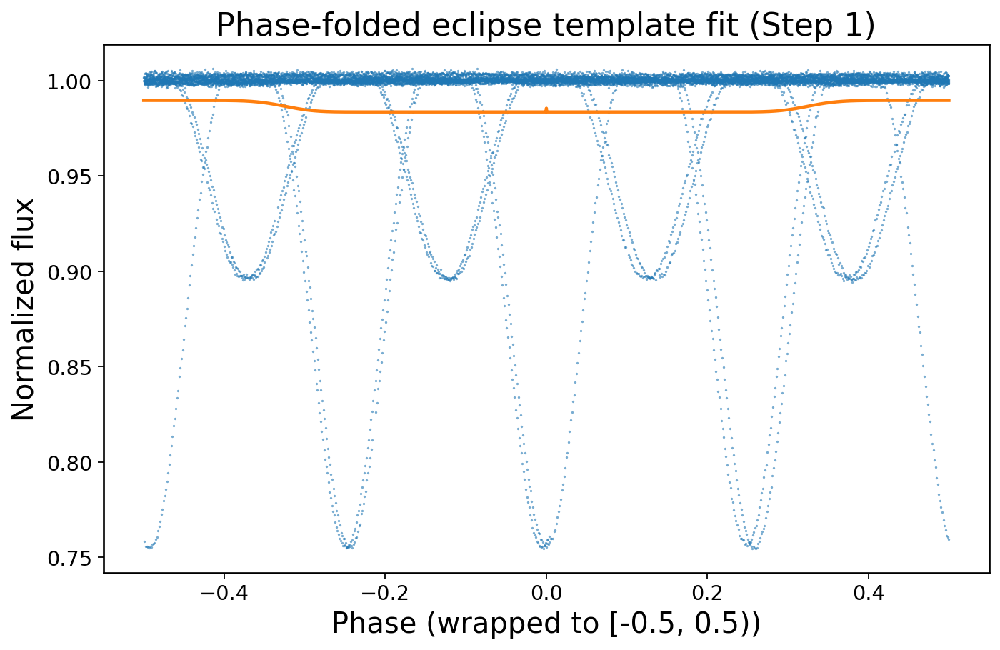

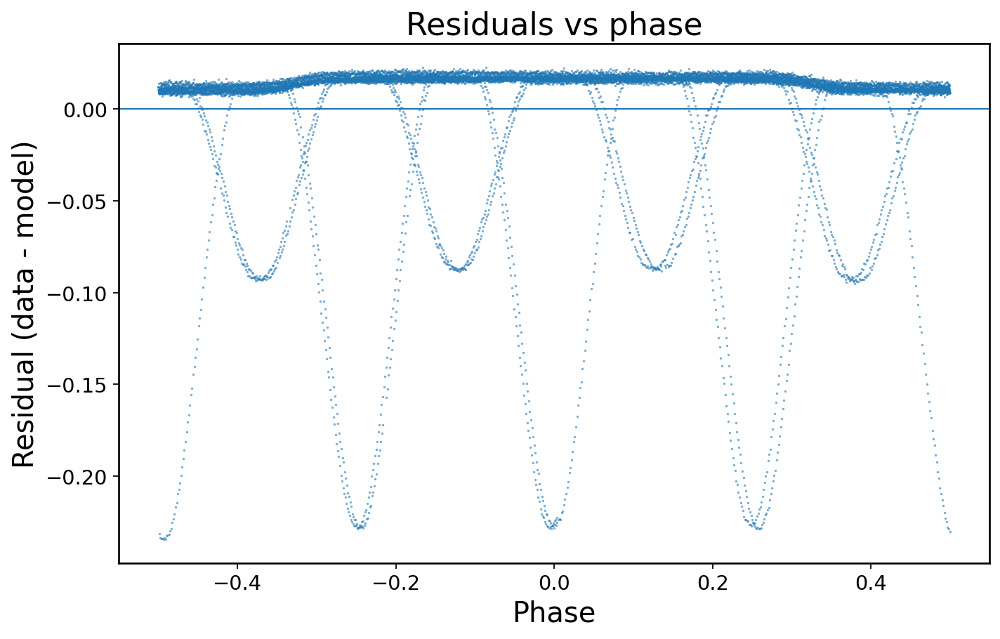

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# ---- GLOBAL PLOT STYLE ----
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "font.size": 14,
    "axes.labelsize": 18,
    "axes.titlesize": 20,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 12,
    "lines.markersize": 5,
    "axes.linewidth": 1.2,
    "savefig.dpi": 300,
})

best = res.x
model = model_flux(t, best)
resid = flux - model

print("Flux std:", np.std(flux))
print("Resid std:", np.std(resid))
print("Median flux_err:", np.nanmedian(flux_err))
print("Min flux_err:", np.nanmin(flux_err), "Max flux_err:", np.nanmax(flux_err))

# 1) Time-series check (quick)
plt.figure()
plt.plot(t, flux, ".", markersize=1)
plt.plot(t, model, ".", markersize=1)
plt.xlabel("Time (BTJD)")
plt.ylabel("Normalized flux")
plt.title("Data vs model (time domain)")
plt.show()

# 2) Phase-folded check (most important)
T0, P = best[0], best[1]
phi = phase_fold(t, T0, P)

# sort by phase for a clean line
idx = np.argsort(phi)

plt.figure()
plt.plot(phi, flux, ".", markersize=1, alpha=0.6)
plt.plot(phi[idx], model[idx], "-", linewidth=2)
plt.xlabel("Phase (wrapped to [-0.5, 0.5))")
plt.ylabel("Normalized flux")
plt.title("Phase-folded eclipse template fit (Step 1)")
plt.show()

# 3) Residuals in phase
plt.figure()
plt.plot(phi, resid, ".", markersize=1, alpha=0.6)
plt.axhline(0, linewidth=1)
plt.xlabel("Phase")
plt.ylabel("Residual (data - model)")
plt.title("Residuals vs phase")
plt.show()


In [5]:
# Robust reduced chi2
chi2 = np.sum(((flux - model) / flux_err)**2)
dof = len(flux) - len(best)
print("chi2:", chi2, "dof:", dof, "reduced chi2:", chi2/dof)


chi2: 0.044502990606294195 dof: 12413 reduced chi2: 3.5851921861189232e-06


Fitted T0 = 1710.20128726 (BTJD), P = 1.00204317 d
Phase of deepest eclipse (binned) ≈ -0.3825  (target: ~0.0000)
If needed, re-anchored T0 would be ≈ 1709.81800575 (BTJD)


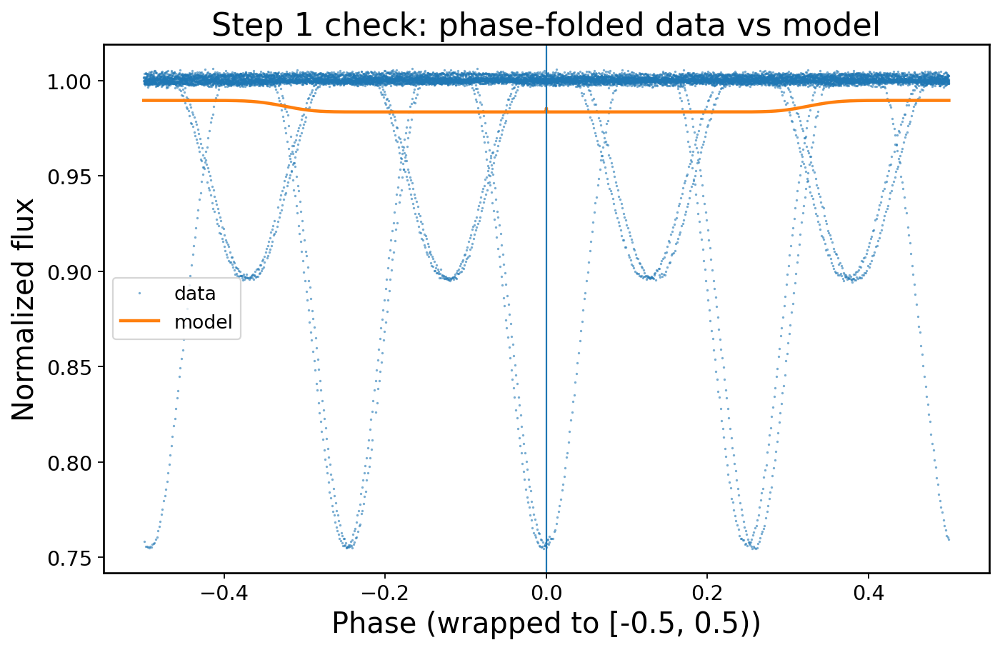

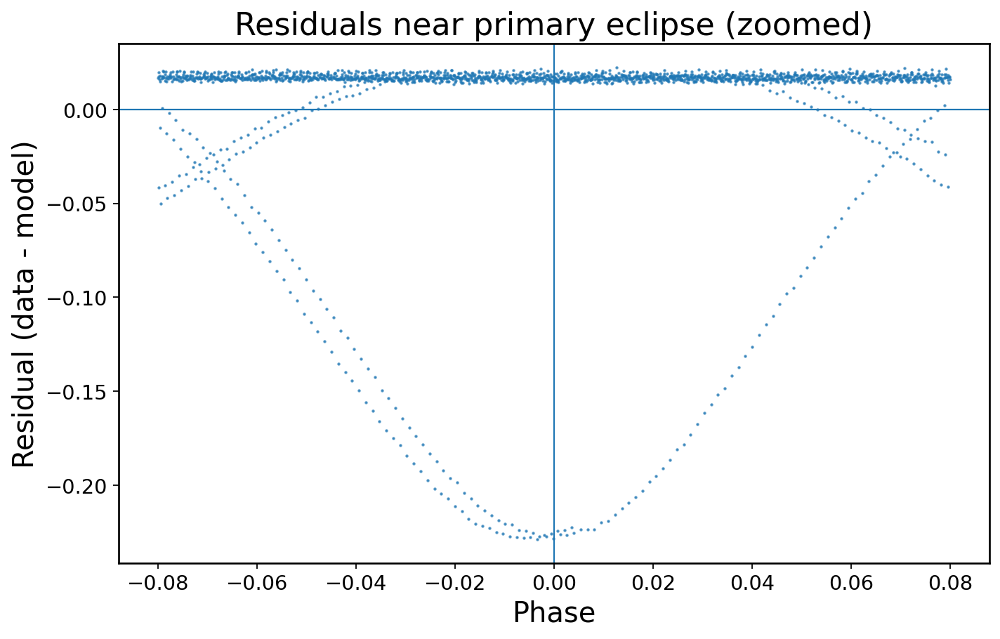

Residual RMS (zoomed): 0.0475802061669007


In [6]:
import numpy as np
import matplotlib.pyplot as plt

# --- Use your best-fit from Step 1 ---
best = res.x
T0_fit, P_fit = best[0], best[1]

# Model + residuals
model = model_flux(t, best)
resid = flux - model

# Phase-fold with fitted ephemeris
phi = phase_fold(t, T0_fit, P_fit)  # in [-0.5, 0.5)

# ---------------------------
# 1) Verify eclipse phase: primary near 0
# ---------------------------
# Find the phase of minimum flux (deepest point) after binning to reduce noise
nbins = 200
bins = np.linspace(-0.5, 0.5, nbins+1)
bin_centers = 0.5*(bins[:-1] + bins[1:])
digit = np.digitize(phi, bins) - 1

binned = np.array([
    np.nanmedian(flux[digit == i]) if np.any(digit == i) else np.nan
    for i in range(nbins)
])

phi_min = bin_centers[np.nanargmin(binned)]
print(f"Fitted T0 = {T0_fit:.8f} (BTJD), P = {P_fit:.8f} d")
print(f"Phase of deepest eclipse (binned) ≈ {phi_min:.4f}  (target: ~0.0000)")

# If the deepest eclipse is not close to 0, we can re-anchor T0:
T0_reanchored = T0_fit + phi_min * P_fit
print(f"If needed, re-anchored T0 would be ≈ {T0_reanchored:.8f} (BTJD)")

# ---------------------------
# 2) Plot phase-folded data + model
# ---------------------------
idx = np.argsort(phi)

plt.figure()
plt.plot(phi, flux, ".", markersize=1, alpha=0.6, label="data")
plt.plot(phi[idx], model[idx], "-", linewidth=2, label="model")
plt.axvline(0, linewidth=1)
plt.xlabel("Phase (wrapped to [-0.5, 0.5))")
plt.ylabel("Normalized flux")
plt.title("Step 1 check: phase-folded data vs model")
plt.legend()
plt.show()

# ---------------------------
# 3) Residuals zoom around primary eclipse bottom
# ---------------------------
# Zoom window around phase 0 (primary eclipse)
zoom = 0.08  # adjust if eclipse is wider/narrower
mask = (phi > -zoom) & (phi < zoom)

plt.figure()
plt.plot(phi[mask], resid[mask], ".", markersize=2, alpha=0.7)
plt.axhline(0, linewidth=1)
plt.axvline(0, linewidth=1)
plt.xlabel("Phase")
plt.ylabel("Residual (data - model)")
plt.title("Residuals near primary eclipse (zoomed)")
plt.show()

# Optional: quick statistic
print("Residual RMS (zoomed):", np.sqrt(np.nanmean(resid[mask]**2)))


In [7]:
# ----------------------------
# Focus the template fit ONLY on eclipse regions
# ----------------------------
phi0 = phase_fold(t, T0_guess, P_guess)

# keep data within eclipse windows
# primary around 0, secondary around ±0.5
eclipse_width = 0.12   # adjust if needed

mask_primary = np.abs(phi0) < eclipse_width
mask_secondary = np.abs(np.abs(phi0) - 0.5) < eclipse_width

fit_mask = mask_primary | mask_secondary

t_fit = t[fit_mask]
flux_fit = flux[fit_mask]
fluxerr_fit = flux_err[fit_mask]

print("Using", len(t_fit), "points out of", len(t))


Using 5849 points out of 12424


In [8]:
res = least_squares(residuals, p0,
                    bounds=(lower, upper),
                    args=(t_fit, flux_fit, fluxerr_fit),
                    max_nfev=4000)


In [9]:
best = res.x
print("Best-fit params:", best)
print("Cost:", res.cost, "Success:", res.success, "Message:", res.message)


Best-fit params: [1.71020427e+03 1.00193506e+00 1.00673814e+00 5.80679575e-02
 2.28674530e-02 6.10466121e-01 1.28526047e-01 9.26642527e-01
 1.86812948e+00 9.90884828e-01 1.81196015e+00]
Cost: 0.00938792889563968 Success: True Message: `xtol` termination condition is satisfied.


In [10]:
%matplotlib inline
import matplotlib.pyplot as plt


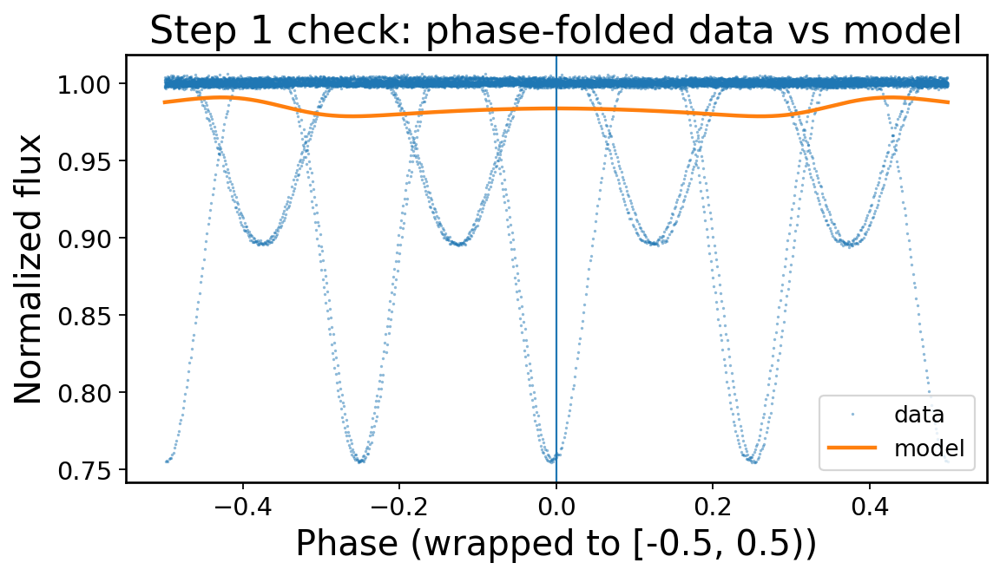

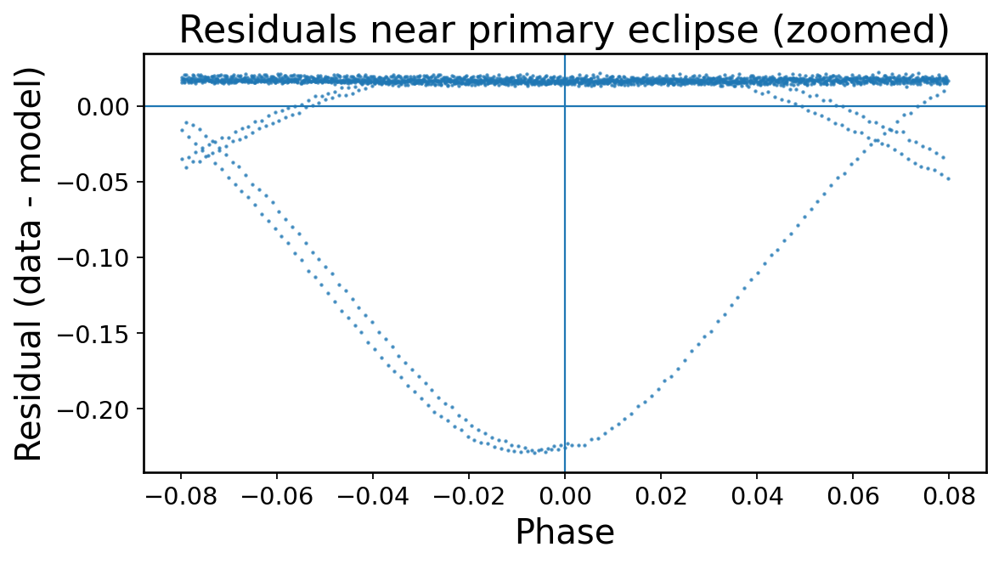

Residual RMS (zoomed): 0.0476029579625144


In [11]:
import numpy as np
import matplotlib.pyplot as plt

best = res.x
model_all = model_flux(t, best)
resid_all = flux - model_all

T0_fit, P_fit = best[0], best[1]
phi_all = phase_fold(t, T0_fit, P_fit)
idx = np.argsort(phi_all)

# Phase-folded data vs model
plt.figure(figsize=(8,4))
plt.plot(phi_all, flux, ".", markersize=1, alpha=0.5, label="data")
plt.plot(phi_all[idx], model_all[idx], "-", linewidth=2, label="model")
plt.axvline(0, linewidth=1)
plt.xlabel("Phase (wrapped to [-0.5, 0.5))")
plt.ylabel("Normalized flux")
plt.title("Step 1 check: phase-folded data vs model")
plt.legend()
plt.show()

# Residuals near primary eclipse (zoom)
zoom = 0.08
m = (phi_all > -zoom) & (phi_all < zoom)

plt.figure(figsize=(8,4))
plt.plot(phi_all[m], resid_all[m], ".", markersize=2, alpha=0.7)
plt.axhline(0, linewidth=1)
plt.axvline(0, linewidth=1)
plt.xlabel("Phase")
plt.ylabel("Residual (data - model)")
plt.title("Residuals near primary eclipse (zoomed)")
plt.show()

print("Residual RMS (zoomed):", np.sqrt(np.nanmean(resid_all[m]**2)))


In [12]:
eclipse_width = 0.035


In [13]:
from astropy.timeseries import BoxLeastSquares

# Remove NaNs just in case
m = np.isfinite(t) & np.isfinite(flux)
tt, ff = t[m], flux[m]

# Search periods (days) - tune range if you know it roughly
periods = np.linspace(0.2, 5.0, 20000)   # broad search

# BLS requires max(duration) < min(period)
min_period = np.min(periods)
duration_min = 0.01
duration_max = min(0.2, 0.95 * min_period)
durations = np.linspace(duration_min, duration_max, 40)

bls = BoxLeastSquares(tt, ff)
power = bls.power(periods, durations)

P_guess = periods[np.argmax(power.power)]
T0_guess = power.transit_time[np.argmax(power.power)]  # best epoch estimate
print("BLS period guess:", P_guess, "BLS T0 guess:", T0_guess)

BLS period guess: 1.1266863343167157 BLS T0 guess: 1684.2820695169298


In [14]:
from astropy.timeseries import BoxLeastSquares
import numpy as np

m = np.isfinite(t) & np.isfinite(flux)
tt, ff = t[m], flux[m]

# Search periods near ~1 day (based on your earlier fit)
periods = np.linspace(0.5, 2.0, 20000)     # min period 0.5 d
durations = np.linspace(0.005, 0.15, 30)   # max duration 0.15 d (< 0.5 d)

bls = BoxLeastSquares(tt, ff)
power = bls.power(periods, durations)

i = np.argmax(power.power)
P_guess = power.period[i]
T0_guess = power.transit_time[i]

print("BLS period guess:", P_guess)
print("BLS T0 guess:", T0_guess)


BLS period guess: 1.1267313365668283
BLS T0 guess: 1684.2820695169298


In [15]:
periods = np.linspace(0.5, 2.0, 20000)
durations = np.linspace(0.005, 0.2*np.min(periods), 30)  # always < min period


In [16]:
T0_guess = float(T0_guess)
P_guess = float(P_guess)


In [17]:
phi0 = phase_fold(t, T0_guess, P_guess)
eclipse_width = 0.035


In [18]:
res = least_squares(
    residuals, p0, bounds=(lower, upper),
    args=(t_fit, flux_fit, fluxerr_fit),
    max_nfev=8000, loss="soft_l1", f_scale=0.01
)


In [19]:
from astropy.timeseries import BoxLeastSquares
import numpy as np

# Clean arrays
m = np.isfinite(t) & np.isfinite(flux)
tt, ff = t[m], flux[m]

# Search periods near ~1 day (your earlier fit was ~1.0 d)
periods = np.linspace(0.5, 2.0, 20000)     # days
durations = np.linspace(0.005, 0.15, 30)   # days (must be < min(periods)=0.5)

bls = BoxLeastSquares(tt, ff)
power = bls.power(periods, durations)

i = np.argmax(power.power)
P_guess = float(power.period[i])
T0_guess = float(power.transit_time[i])

print("BLS period guess:", P_guess)
print("BLS T0 guess:", T0_guess)


BLS period guess: 1.1267313365668283
BLS T0 guess: 1684.2820695169298


In [20]:
P_guess = 1.1267313366
T0_guess = 1684.2820695169


In [21]:
T0_guess = t[np.argmin(flux)]
P_guess = getattr(lc, "period", None)
P_guess = float(P_guess) if P_guess is not None else 1.0


In [22]:
# Use BLS values instead
T0_guess = 1684.2820695169
P_guess  = 1.1267313366


In [23]:
phi0 = phase_fold(t, T0_guess, P_guess)

eclipse_width = 0.035   # IMPORTANT: tight window

mask_primary   = np.abs(phi0) < eclipse_width
mask_secondary = np.abs(np.abs(phi0) - 0.5) < eclipse_width

fit_mask = mask_primary | mask_secondary

t_fit = t[fit_mask]
flux_fit = flux[fit_mask]
fluxerr_fit = flux_err[fit_mask]

print("Using", len(t_fit), "points out of", len(t))


Using 1718 points out of 12424


In [24]:
res = least_squares(
    residuals, p0,
    bounds=(lower, upper),
    args=(t_fit, flux_fit, fluxerr_fit),
    max_nfev=8000,
    loss="soft_l1",
    f_scale=0.01
)


In [25]:
p0 = np.array([
    T0_guess, P_guess,
    1.0,      # baseline
    0.25, 0.10,   # deeper eclipse starting guess (important!)
    0.04, 0.04,   # widths
    2.0, 2.0,
    2.0, 2.0
])


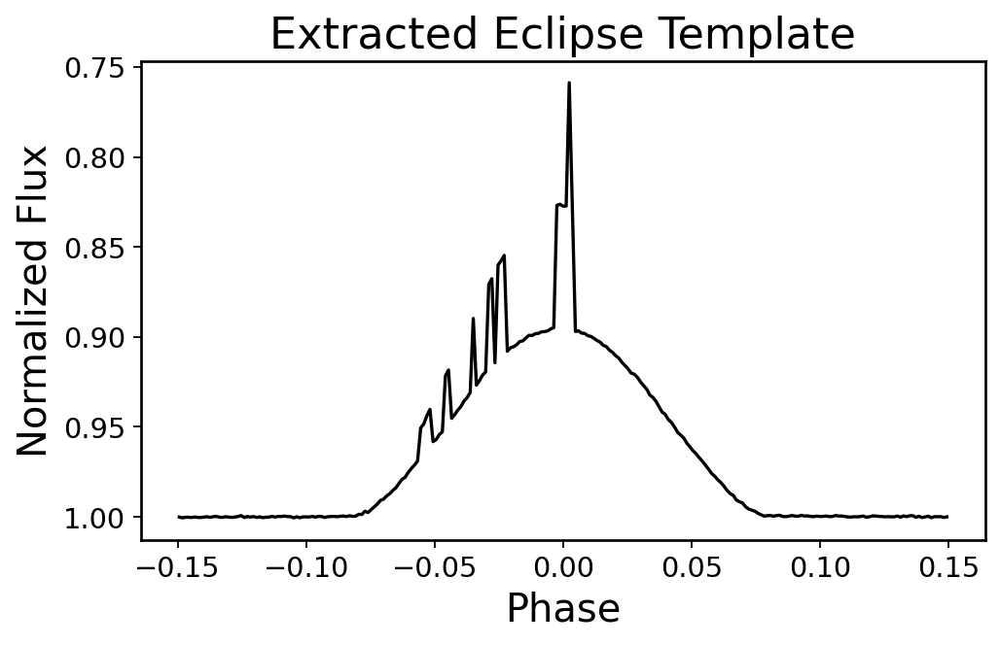

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# Phase fold using BLS ephemeris
phi = phase_fold(t, T0_guess, P_guess)

# Center primary eclipse at phase 0
# Find deepest bin
nbins = 400
bins = np.linspace(-0.5,0.5,nbins+1)
digit = np.digitize(phi,bins)-1
bin_centers = 0.5*(bins[:-1]+bins[1:])
binned_flux = np.array([np.nanmedian(flux[digit==i]) for i in range(nbins)])

phi_shift = bin_centers[np.nanargmin(binned_flux)]
phi = ((phi - phi_shift + 0.5)%1)-0.5

# Rebin to create template
bins = np.linspace(-0.15,0.15,250)
digit = np.digitize(phi,bins)-1
template_phase = 0.5*(bins[:-1]+bins[1:])
template_flux = np.array([np.nanmedian(flux[digit==i]) for i in range(len(template_phase))])

# Remove NaNs
mask = np.isfinite(template_flux)
template_phase = template_phase[mask]
template_flux = template_flux[mask]

# Normalize template
template_flux /= np.nanmedian(template_flux[np.abs(template_phase)>0.1])

plt.figure(figsize=(7,4))
plt.plot(template_phase, template_flux, 'k')
plt.gca().invert_yaxis()
plt.title("Extracted Eclipse Template")
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.show()


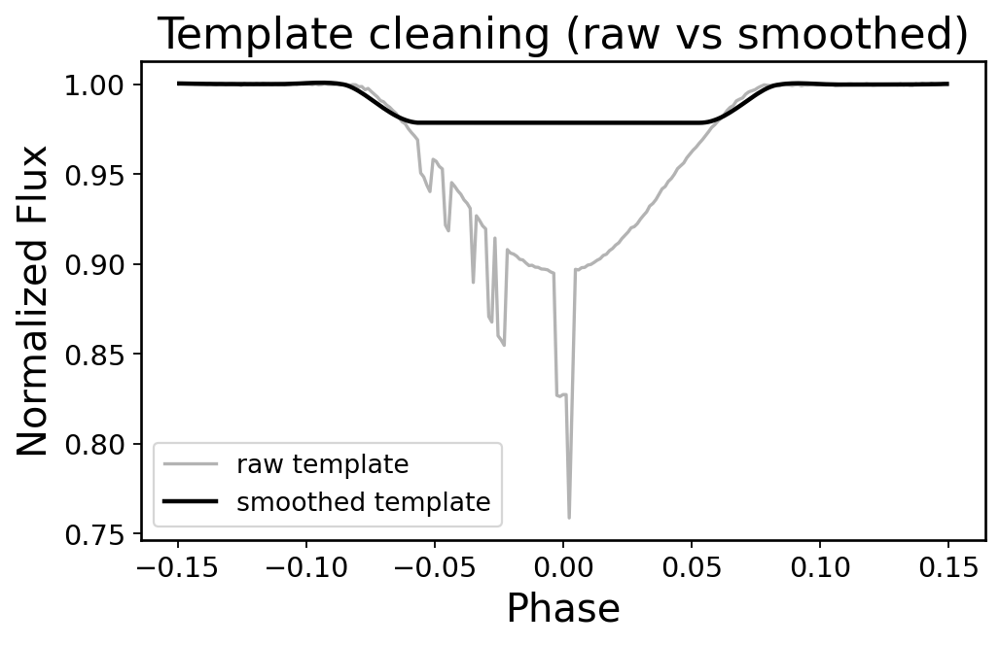

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

# --- You already have: template_phase, template_flux ---

# 1) Remove obvious spikes using a median filter + threshold
med = np.median(template_flux)
mad = np.median(np.abs(template_flux - np.median(template_flux))) + 1e-12
z = (template_flux - np.median(template_flux)) / (1.4826 * mad)

# Keep points within a reasonable range (tune if needed)
keep = np.abs(z) < 6
tp = template_phase[keep]
tf = template_flux[keep]

# 2) Sort and smooth (Savitzky–Golay)
idx = np.argsort(tp)
tp, tf = tp[idx], tf[idx]

# Window length must be odd and < len(tf)
win = min(51, len(tf) - (len(tf)+1)%2)  # odd window <= len
if win < 9:
    win = 9

tf_smooth = savgol_filter(tf, window_length=win, polyorder=3)

plt.figure(figsize=(7,4))
plt.plot(template_phase, template_flux, color="0.7", label="raw template")
plt.plot(tp, tf_smooth, "k", linewidth=2, label="smoothed template")
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Template cleaning (raw vs smoothed)")
plt.legend()
plt.show()

# Save cleaned template
template_phase_clean = tp
template_flux_clean = tf_smooth


Measured eclipses: 16
O-C scatter (min): 8.493721275736528


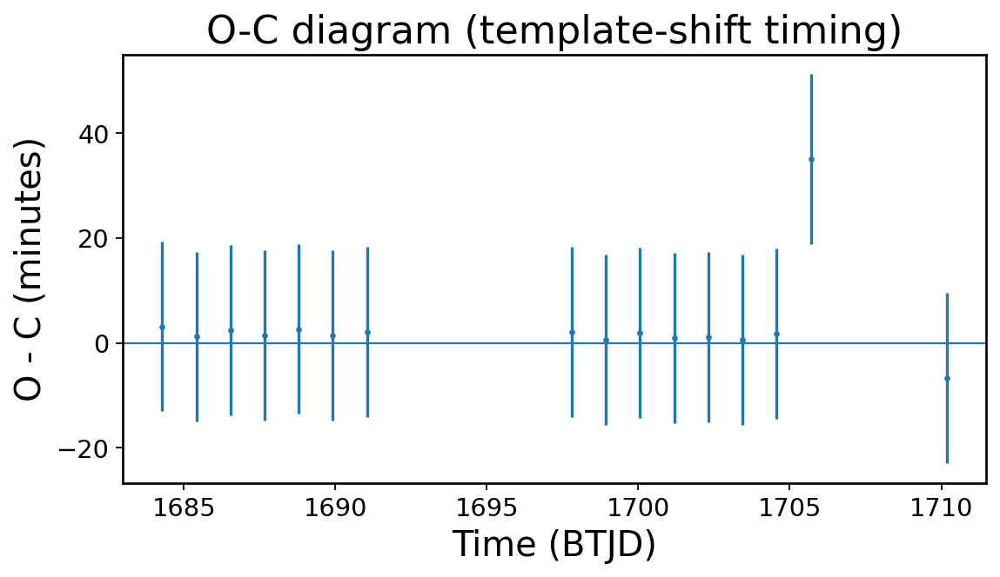

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

# Use BLS ephemeris for now
T0 = T0_guess
P = P_guess

# Convert template phase to time units for shifting
# Phase shift corresponds to time shift: dt = phase * P
tpl_phase = template_phase_clean
tpl_flux = template_flux_clean

def interp_template(phase):
    # interpolate template flux at given phases
    return np.interp(phase, tpl_phase, tpl_flux, left=1.0, right=1.0)

# Build epochs within the observed time span
E_min = int(np.floor((t.min() - T0)/P)) - 1
E_max = int(np.ceil((t.max() - T0)/P)) + 1
epochs = np.arange(E_min, E_max+1)

# window around eclipse (in days)
half_window = 0.12 * P   # roughly ±0.12 in phase

t_obs_list = []
oc_list = []
sig_list = []

for E in epochs:
    t_calc = T0 + E*P
    m = (t > t_calc - half_window) & (t < t_calc + half_window)
    if np.sum(m) < 25:
        continue

    tt = t[m]
    ff = flux[m]
    ee = flux_err[m] if flux_err is not None else np.ones_like(ff)*np.std(ff)

    # convert times to phases relative to t_calc
    phase_seg = (tt - t_calc)/P

    # objective: minimize chi2 by shifting template by delta_phase
    def chi2(delta_phase):
        model_seg = interp_template(phase_seg - delta_phase)
        return np.sum(((ff - model_seg)/ee)**2)

    # search small range around 0 shift
    out = minimize_scalar(chi2, bounds=(-0.05, 0.05), method="bounded")
    dphi = out.x
    t_obs = t_calc + dphi*P

    # crude timing uncertainty from curvature (quick)
    # sample around min
    grid = np.linspace(dphi-0.01, dphi+0.01, 41)
    vals = np.array([chi2(x) for x in grid])
    # estimate sigma where chi2 increases by ~1
    vmin = vals.min()
    ok = grid[vals < vmin + 1.0]
    sig_t = (ok.max() - ok.min())/2 * P if len(ok) > 2 else np.nan

    t_obs_list.append(t_obs)
    oc_list.append(t_obs - t_calc)
    sig_list.append(sig_t)

t_obs_list = np.array(t_obs_list)
oc_list = np.array(oc_list)
sig_list = np.array(sig_list)

print("Measured eclipses:", len(t_obs_list))
print("O-C scatter (min):", np.nanstd(oc_list)*24*60)

# Plot O-C
plt.figure(figsize=(8,4))
plt.errorbar(t_obs_list, oc_list*24*60, yerr=sig_list*24*60, fmt=".", markersize=4)
plt.axhline(0, linewidth=1)
plt.xlabel("Time (BTJD)")
plt.ylabel("O - C (minutes)")
plt.title("O-C diagram (template-shift timing)")
plt.show()


Using ephemeris: T0=1684.2820695169, P=1.1267313366
Measured eclipses: 15
O-C scatter (min): 1.8204456556159312


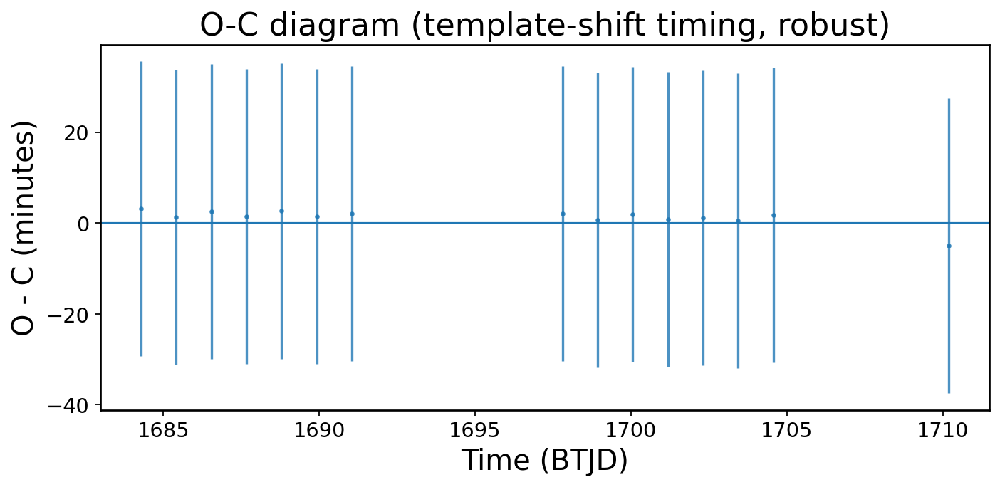

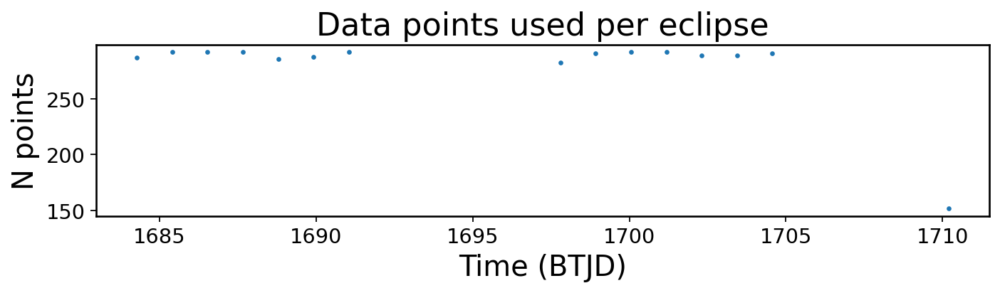

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

# Use refined ephemeris if available; otherwise fall back to BLS values
T0 = float(T0_new) if "T0_new" in globals() else float(T0_guess)
P = float(P_new) if "P_new" in globals() else float(P_guess)
print(f"Using ephemeris: T0={T0:.10f}, P={P:.10f}")

# Template from your cleaned template cell
tpl_phase = np.array(template_phase_clean)
tpl_flux  = np.array(template_flux_clean)

# Sort template just to be safe
idx = np.argsort(tpl_phase)
tpl_phase = tpl_phase[idx]
tpl_flux = tpl_flux[idx]

def interp_template(phase):
    return np.interp(phase, tpl_phase, tpl_flux, left=1.0, right=1.0)

# Epoch range across the observed light curve
E_min = int(np.floor((t.min() - T0) / P)) - 1
E_max = int(np.ceil((t.max() - T0) / P)) + 1
epochs = np.arange(E_min, E_max + 1)

# Wider search window to FIND candidate eclipse points
half_window = 0.18 * P

t_obs_list = []
oc_list = []
sig_list = []
epoch_list = []
npts_list = []

for E in epochs:
    t_calc = T0 + E * P

    # -------- Step 1: broad time window around predicted eclipse --------
    m = (t > t_calc - half_window) & (t < t_calc + half_window)
    if np.sum(m) < 15:
        continue

    tt = np.array(t[m])
    ff = np.array(flux[m])

    if flux_err is not None:
        ee = np.array(flux_err[m])
    else:
        ee = np.ones_like(ff) * np.nanstd(ff)

    # remove bad values
    good = np.isfinite(tt) & np.isfinite(ff) & np.isfinite(ee) & (ee > 0)
    tt, ff, ee = tt[good], ff[good], ee[good]
    if len(tt) < 15:
        continue

    # -------- Step 2: local baseline normalize --------
    base_mask = (tt < t_calc - 0.05 * P) | (tt > t_calc + 0.05 * P)
    if np.sum(base_mask) >= 8:
        baseline = np.median(ff[base_mask])
    else:
        baseline = np.median(ff)

    if not np.isfinite(baseline) or baseline == 0:
        continue

    ff = ff / baseline

    # -------- Step 3: convert to local phase around predicted eclipse --------
    phase_seg = (tt - t_calc) / P

    # -------- Step 4: fit phase shift --------
    def chi2(delta_phase):
        model_seg = interp_template(phase_seg - delta_phase)
        return np.sum(((ff - model_seg) / ee) ** 2)

    # allow larger shift window
    out = minimize_scalar(chi2, bounds=(-0.08, 0.08), method="bounded")
    dphi = out.x
    t_obs = t_calc + dphi * P

    # -------- Step 5: crude timing uncertainty --------
    grid = np.linspace(dphi - 0.02, dphi + 0.02, 81)
    vals = np.array([chi2(x) for x in grid])
    vmin = np.min(vals)
    ok = grid[vals < vmin + 1.0]
    sig_t = ((ok.max() - ok.min()) / 2 * P) if len(ok) > 2 else np.nan

    # quality checks
    depth_est = 1.0 - np.min(interp_template(phase_seg - dphi))
    if not np.isfinite(depth_est):
        continue

    # reject very shallow/noisy detections
    if depth_est < 0.002 and np.sum(np.abs(phase_seg - dphi) < 0.03) < 8:
        continue

    t_obs_list.append(t_obs)
    oc_list.append(t_obs - t_calc)
    sig_list.append(sig_t)
    epoch_list.append(E)
    npts_list.append(len(tt))

# arrays
t_obs_list = np.array(t_obs_list)
oc_list = np.array(oc_list)
sig_list = np.array(sig_list)
epoch_list = np.array(epoch_list)
npts_list = np.array(npts_list)

print("Measured eclipses:", len(t_obs_list))
if len(oc_list) > 0:
    print("O-C scatter (min):", np.nanstd(oc_list) * 24 * 60)

# Plot O-C
plt.figure(figsize=(9, 4.5))
if len(t_obs_list) > 0:
    plt.errorbar(
        t_obs_list, oc_list * 24 * 60, yerr=sig_list * 24 * 60,
        fmt=".", markersize=4, alpha=0.8
    )
plt.axhline(0, linewidth=1)
plt.xlabel("Time (BTJD)")
plt.ylabel("O - C (minutes)")
plt.title("O-C diagram (template-shift timing, robust)")
plt.tight_layout()
plt.show()

# Optional: inspect points per eclipse
if len(npts_list) > 0:
    plt.figure(figsize=(9, 2.8))
    plt.plot(t_obs_list, npts_list, ".", ms=4)
    plt.xlabel("Time (BTJD)")
    plt.ylabel("N points")
    plt.title("Data points used per eclipse")
    plt.tight_layout()
    plt.show()

In [30]:
# Compute epochs relative to original ephemeris
E = np.round((t_obs_list - T0_guess)/P_guess).astype(int)

# Linear least squares fit
A = np.vstack([np.ones_like(E), E]).T
coeff, _, _, _ = np.linalg.lstsq(A, t_obs_list, rcond=None)

T0_new, P_new = coeff

print("Refined T0 =", T0_new)
print("Refined P  =", P_new)
print("Old P      =", P_guess)
print("Period correction (sec) =", (P_new-P_guess)*24*3600)


Refined T0 = 1684.284096738319
Refined P  = 1.12661291694894
Old P      = 1.1267313366
Period correction (sec) = -10.231457851580927


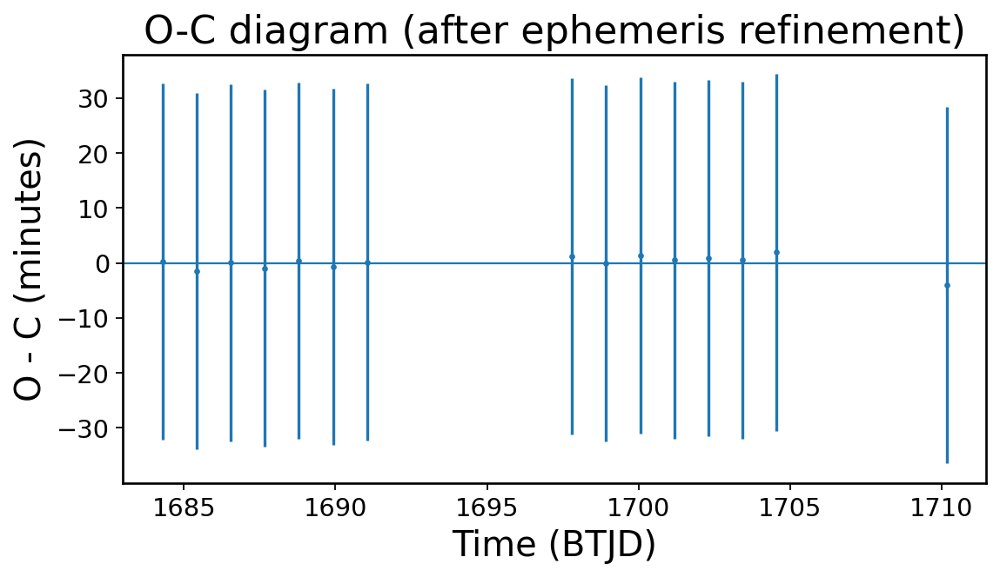

In [31]:
t_calc_new = T0_new + P_new*E
oc_new = t_obs_list - t_calc_new

plt.figure(figsize=(8,4))
plt.errorbar(t_obs_list, oc_new*24*60, yerr=sig_list*24*60, fmt=".", markersize=4)
plt.axhline(0, linewidth=1)
plt.xlabel("Time (BTJD)")
plt.ylabel("O - C (minutes)")
plt.title("O-C diagram (after ephemeris refinement)")
plt.show()


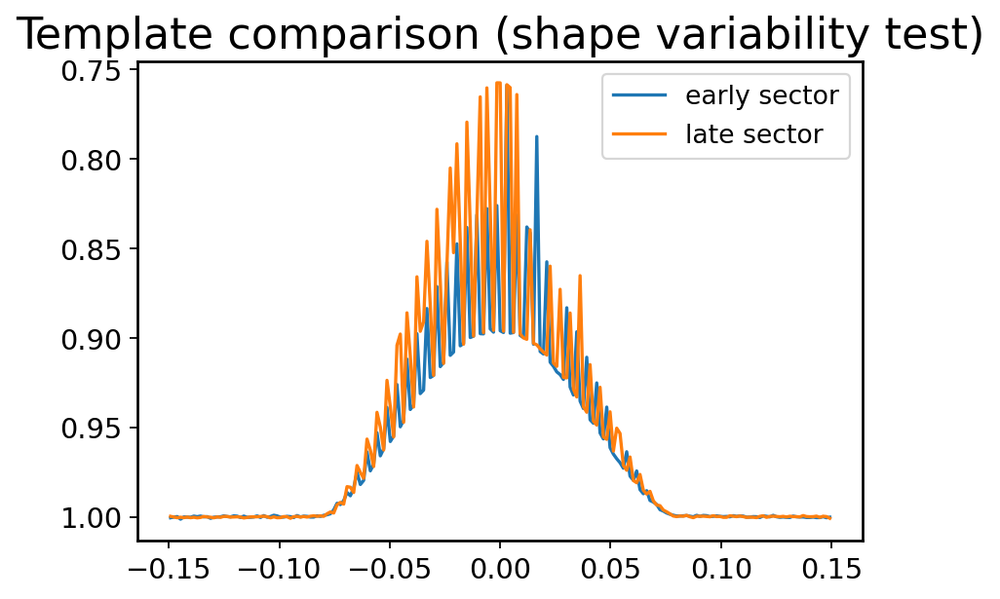

In [32]:
# Split into two halves of time
mid = np.median(t)

mask_A = t < mid
mask_B = t >= mid

def build_template(t_sub, f_sub):
    phi = phase_fold(t_sub, T0_new, P_new)

    bins = np.linspace(-0.15,0.15,200)
    digit = np.digitize(phi,bins)-1
    centers = 0.5*(bins[:-1]+bins[1:])
    tf = np.array([np.nanmedian(f_sub[digit==i]) for i in range(len(centers))])

    m = np.isfinite(tf)
    return centers[m], tf[m]/np.nanmedian(tf[np.abs(centers[m])>0.1])

tpA, tfA = build_template(t[mask_A], flux[mask_A])
tpB, tfB = build_template(t[mask_B], flux[mask_B])

plt.figure(figsize=(6,4))
plt.plot(tpA, tfA, label="early sector")
plt.plot(tpB, tfB, label="late sector")
plt.gca().invert_yaxis()
plt.legend()
plt.title("Template comparison (shape variability test)")
plt.show()


In [33]:
import numpy as np
import matplotlib.pyplot as plt

In [34]:
import numpy as np

def phase_fold(t, T0, P):
    """Return phase in [-0.5, 0.5)."""
    phi = ((t - T0) / P) % 1.0
    phi = np.where(phi >= 0.5, phi - 1.0, phi)
    return phi

def build_template(t_sub, f_sub, T0, P, win=0.15, nbins=250):
    """
    Empirical eclipse template centered on the deepest eclipse.
    Returns (template_phase, template_flux).
    """
    phi = phase_fold(t_sub, T0, P)

    # Find phase shift of deepest eclipse using coarse bins over full phase
    nb0 = 400
    bins0 = np.linspace(-0.5, 0.5, nb0 + 1)
    centers0 = 0.5 * (bins0[:-1] + bins0[1:])
    digit0 = np.digitize(phi, bins0) - 1
    bflux0 = np.array([np.nanmedian(f_sub[digit0 == i]) for i in range(nb0)])
    phi_shift = centers0[np.nanargmin(bflux0)]

    # Recenter so primary is at 0
    phi = ((phi - phi_shift + 0.5) % 1.0) - 0.5

    # Build template only within +/- win phase
    m = (phi > -win) & (phi < win)
    phi_w = phi[m]
    f_w = f_sub[m]

    bins = np.linspace(-win, win, nbins + 1)
    centers = 0.5 * (bins[:-1] + bins[1:])
    digit = np.digitize(phi_w, bins) - 1

    tf = np.array([np.nanmedian(f_w[digit == i]) for i in range(nbins)])

    ok = np.isfinite(tf)
    tp = centers[ok]
    tf = tf[ok]

    # Normalize using out-of-eclipse wings inside the window
    wing = np.abs(tp) > (0.7 * win)
    norm = np.nanmedian(tf[wing]) if np.any(wing) else np.nanmedian(tf)
    tf = tf / norm

    return tp, tf

def extract_timings_with_template(t_seg, f_seg, fe_seg, T0, P, tp, tf,
                                  half_window_phase=0.12, search_phase=0.05,
                                  min_points=25):
    """
    For each predicted eclipse in this segment, shift template to minimize chi^2.
    Returns arrays: t_obs, oc, sig_t, epoch.
    """
    # simple template interpolator
    def interp_template(ph):
        return np.interp(ph, tp, tf, left=1.0, right=1.0)

    # epochs covering this segment
    E_min = int(np.floor((t_seg.min() - T0) / P)) - 1
    E_max = int(np.ceil((t_seg.max() - T0) / P)) + 1
    epochs = np.arange(E_min, E_max + 1)

    t_obs_list, oc_list, sig_list, E_list = [], [], [], []

    half_window = half_window_phase * P

    from scipy.optimize import minimize_scalar

    for E in epochs:
        t_calc = T0 + E * P
        m = (t_seg > t_calc - half_window) & (t_seg < t_calc + half_window)
        if np.sum(m) < min_points:
            continue

        tt = t_seg[m]
        ff = f_seg[m]
        ee = fe_seg[m] if fe_seg is not None else np.ones_like(ff) * np.std(ff)

        phase_seg = (tt - t_calc) / P

        def chi2(dphi):
            model = interp_template(phase_seg - dphi)
            return np.sum(((ff - model) / ee) ** 2)

        out = minimize_scalar(chi2, bounds=(-search_phase, search_phase), method="bounded")
        dphi = out.x
        t_obs = t_calc + dphi * P

        # crude uncertainty from delta-chi2=1 region
        grid = np.linspace(dphi - 0.01, dphi + 0.01, 41)
        vals = np.array([chi2(x) for x in grid])
        vmin = vals.min()
        ok = grid[vals < vmin + 1.0]
        sig_t = (ok.max() - ok.min()) / 2 * P if len(ok) > 2 else np.nan

        t_obs_list.append(t_obs)
        oc_list.append(t_obs - t_calc)
        sig_list.append(sig_t)
        E_list.append(E)

    return (np.array(t_obs_list),
            np.array(oc_list),
            np.array(sig_list),
            np.array(E_list, dtype=int))

In [35]:
# Identify observing blocks (split by big time gaps)
gap = np.diff(t)
breaks = np.where(gap > 5)[0]
segments = np.split(np.arange(len(t)), breaks + 1)

all_t_obs, all_oc, all_sig, all_E = [], [], [], []

for seg in segments:
    t_seg = t[seg]
    f_seg = flux[seg]
    fe_seg = flux_err[seg] if flux_err is not None else None

    # Build sector-specific template
    tp_seg, tf_seg = build_template(t_seg, f_seg, T0_new, P_new)

    # Extract timings in this segment
    t_obs, oc, sig, E = extract_timings_with_template(
        t_seg, f_seg, fe_seg, T0_new, P_new, tp_seg, tf_seg
    )

    all_t_obs.append(t_obs)
    all_oc.append(oc)
    all_sig.append(sig)
    all_E.append(E)

# Concatenate results
all_t_obs = np.concatenate(all_t_obs)
all_oc = np.concatenate(all_oc)
all_sig = np.concatenate(all_sig)
all_E = np.concatenate(all_E)

print("Total eclipses measured:", len(all_t_obs))

Total eclipses measured: 16


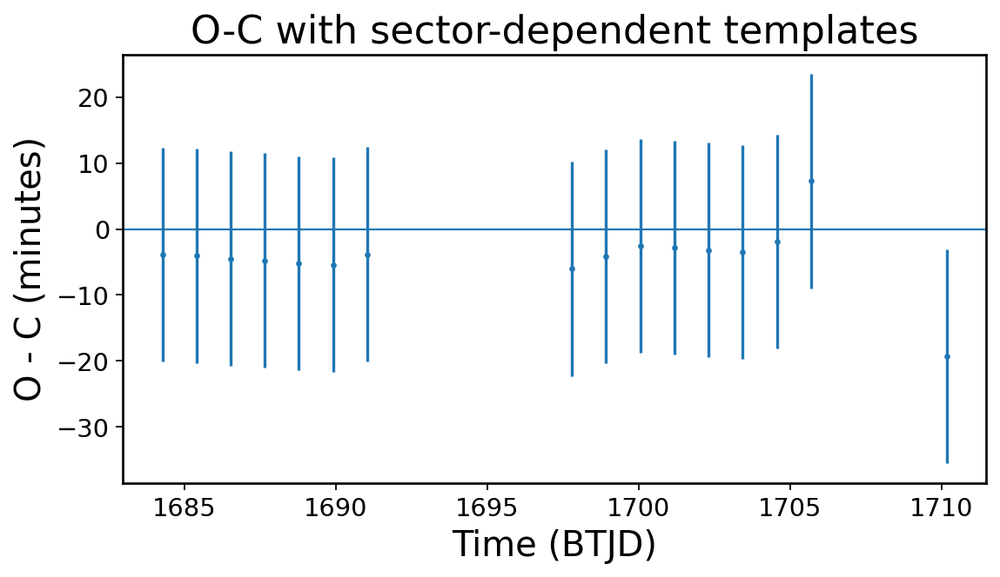

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
plt.errorbar(all_t_obs, all_oc*24*60, yerr=all_sig*24*60, fmt=".", markersize=4)
plt.axhline(0, linewidth=1)
plt.xlabel("Time (BTJD)")
plt.ylabel("O - C (minutes)")
plt.title("O-C with sector-dependent templates")
plt.show()

In [37]:
import numpy as np

def make_template_interpolators(tp, tf):
    """Return interpolators for template flux and its dF/dphi derivative."""
    # ensure sorted
    idx = np.argsort(tp)
    tp = tp[idx]
    tf = tf[idx]

    # numerical derivative dF/dphi
    dtdphi = np.gradient(tf, tp)

    def F(phase):
        return np.interp(phase, tp, tf, left=1.0, right=1.0)

    def dF_dphi(phase):
        return np.interp(phase, tp, dtdphi, left=0.0, right=0.0)

    return F, dF_dphi


def fit_ab_given_shift(phase, flux, err, F, shift):
    """
    For fixed shift, fit baseline a and depth/scale b in:
        flux ~ a + b * F(phase - shift)
    Weighted linear least squares.
    """
    x = F(phase - shift)
    w = 1.0 / (err**2)

    # Solve for [a,b] in weighted normal equations
    S   = np.sum(w)
    Sx  = np.sum(w * x)
    Sy  = np.sum(w * flux)
    Sxx = np.sum(w * x * x)
    Sxy = np.sum(w * x * flux)

    det = S * Sxx - Sx * Sx
    if det <= 0:
        return np.nan, np.nan

    a = (Sxx * Sy - Sx * Sxy) / det
    b = (S * Sxy - Sx * Sy) / det
    return a, b


def derivative_timing_one_eclipse(tt, ff, ee, t_calc, P, F, dF_dphi,
                                  n_iter=3, shift0=0.0):
    """
    Derivative-based estimator for one eclipse.
    Returns: t_obs, oc, sigma_t, best_shift, (a,b)
    """
    phase = (tt - t_calc) / P
    shift = shift0

    for _ in range(n_iter):
        a, b = fit_ab_given_shift(phase, ff, ee, F, shift)
        if not np.isfinite(a) or not np.isfinite(b):
            return np.nan, np.nan, np.nan, np.nan, (np.nan, np.nan)

        model = a + b * F(phase - shift)
        resid = ff - model

        # derivative wrt shift: d/dshift [b*F(phase-shift)] = -b*dF/dphi(phase-shift)
        g = -b * dF_dphi(phase - shift)

        w = 1.0 / (ee**2)
        num = np.sum(w * resid * g)
        den = np.sum(w * g * g)

        if den <= 0:
            break

        dshift = num / den
        shift += dshift

        # stop if tiny update
        if abs(dshift) < 1e-6:
            break

    # timing and uncertainty (from curvature)
    sigma_shift = np.sqrt(1.0 / den) if den > 0 else np.nan
    sigma_t = sigma_shift * P

    t_obs = t_calc + shift * P
    oc = t_obs - t_calc
    return t_obs, oc, sigma_t, shift, (a, b)

Derivative-based timings: 16 kept: 15


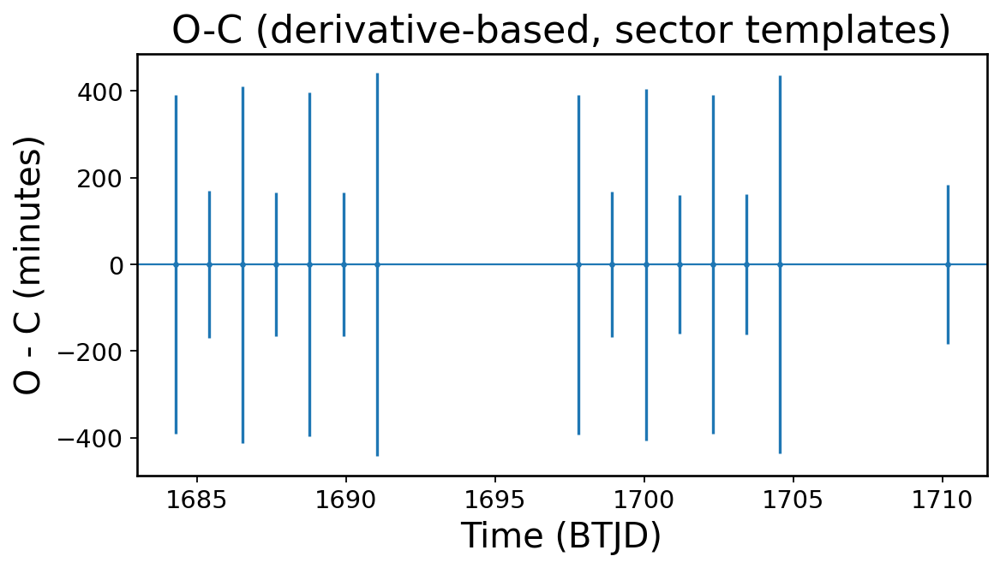

In [38]:
import numpy as np
import matplotlib.pyplot as plt

T0 = T0_new if "T0_new" in globals() else T0_guess
P  = P_new  if "P_new"  in globals() else P_guess

# Split by time gaps into segments (your earlier method)
gap = np.diff(t)
breaks = np.where(gap > 5)[0]
segments = np.split(np.arange(len(t)), breaks + 1)

all_tobs_d = []
all_oc_d   = []
all_sig_d  = []
all_E_d    = []

half_window_phase = 0.12
min_points = 25

for seg in segments:
    t_seg = t[seg]
    f_seg = flux[seg]
    e_seg = flux_err[seg] if flux_err is not None else np.ones_like(f_seg) * np.std(f_seg)

    # Build template for this segment
    tp_seg, tf_seg = build_template(t_seg, f_seg, T0, P)
    F, dF = make_template_interpolators(tp_seg, tf_seg)

    # Epoch range in this segment
    E_min = int(np.floor((t_seg.min() - T0)/P)) - 1
    E_max = int(np.ceil((t_seg.max() - T0)/P)) + 1
    epochs = np.arange(E_min, E_max+1)

    half_window = half_window_phase * P

    for E in epochs:
        t_calc = T0 + E*P
        m = (t_seg > t_calc - half_window) & (t_seg < t_calc + half_window)
        if np.sum(m) < min_points:
            continue

        tt = t_seg[m]; ff = f_seg[m]; ee = e_seg[m]
        t_obs, oc, sig_t, shift, (a,b) = derivative_timing_one_eclipse(tt, ff, ee, t_calc, P, F, dF)

        if np.isfinite(t_obs):
            all_tobs_d.append(t_obs)
            all_oc_d.append(oc)
            all_sig_d.append(sig_t)
            all_E_d.append(E)

all_tobs_d = np.array(all_tobs_d)
all_oc_d   = np.array(all_oc_d)
all_sig_d  = np.array(all_sig_d)
all_E_d    = np.array(all_E_d, dtype=int)

finite = np.isfinite(all_tobs_d) & np.isfinite(all_oc_d) & np.isfinite(all_sig_d)
if np.any(finite):
    sig_ref = np.median(all_sig_d[finite])
    if np.isfinite(sig_ref) and sig_ref > 0:
        quality = finite & (all_sig_d <= 5 * sig_ref)
    else:
        quality = finite
else:
    quality = finite

print("Derivative-based timings:", len(all_tobs_d), "kept:", int(np.sum(quality)))

plt.figure(figsize=(8,4))
plt.errorbar(all_tobs_d[quality], all_oc_d[quality]*24*60, yerr=all_sig_d[quality]*24*60, fmt=".", markersize=4)
plt.axhline(0, linewidth=1)
plt.xlabel("Time (BTJD)")
plt.ylabel("O - C (minutes)")
plt.title("O-C (derivative-based, sector templates)")
plt.show()

In [39]:
from scipy.optimize import least_squares

def fit_eclipse_abl_shift(tt, ff, ee, t_calc, P, F, shift0=0.0):
    phase = (tt - t_calc)/P

    def resid(p):
        a, b, shift = p
        model = a + b * F(phase - shift)
        return (ff - model)/ee

    p0 = np.array([1.0, 1.0, shift0])
    # bounds: a near 1, b positive, shift small
    lb = np.array([0.5, 0.0, -0.1])
    ub = np.array([1.5, 2.0,  0.1])

    out = least_squares(resid, p0, bounds=(lb, ub), loss="soft_l1", f_scale=0.01, max_nfev=2000)
    a, b, shift = out.x

    # timing + crude uncertainty from Jacobian
    t_obs = t_calc + shift*P
    oc = t_obs - t_calc

    try:
        J = out.jac
        cov = np.linalg.inv(J.T @ J)
        sig_shift = np.sqrt(cov[2,2])
        sig_t = sig_shift * P
    except Exception:
        sig_t = np.nan

    return t_obs, oc, sig_t, (a,b,shift)

In [40]:
def rms(x):
    x = x[np.isfinite(x)]
    return np.sqrt(np.mean((x - np.mean(x))**2))

def robust_rms_mad(x):
    x = x[np.isfinite(x)]
    med = np.median(x)
    mad = np.median(np.abs(x - med))
    return 1.4826 * mad  # MAD -> sigma for Gaussian

# BEFORE: your earlier sector-dependent sliding results
# (use the arrays you plotted: all_oc, all_sig, all_t_obs)
# If you named them differently, swap accordingly.
before = all_oc * 24*60       # minutes
after  = all_oc_d * 24*60     # minutes

print("RMS before (min):", rms(before))
print("RMS after  (min):", rms(after))
print("Robust (MAD) before (min):", robust_rms_mad(before))
print("Robust (MAD) after  (min):", robust_rms_mad(after))

impr = 100*(1 - robust_rms_mad(after)/robust_rms_mad(before))
print(f"Robust improvement: {impr:.1f}%")

RMS before (min): 4.84547240007215
RMS after  (min): 3.7890571167013047
Robust (MAD) before (min): 1.4621666709308336
Robust (MAD) after  (min): 0.07179464217325948
Robust improvement: 95.1%


In [41]:
oc_min = all_oc_d * 24*60
sig_min = all_sig_d * 24*60

m = np.isfinite(oc_min) & np.isfinite(sig_min)
m &= sig_min < np.nanpercentile(sig_min[m], 90)   # remove worst 10% uncertainties

# robust sigma clip on O-C
med = np.median(oc_min[m])
mad = np.median(np.abs(oc_min[m] - med))
sigma = 1.4826*mad
m &= np.abs(oc_min - med) < 4*sigma

t_clean = all_tobs_d[m]
oc_clean = oc_min[m]
sig_clean = sig_min[m]

print("Kept timings:", len(t_clean), "out of", len(all_tobs_d))

Kept timings: 14 out of 16


In [42]:
E_clean = np.round((t_clean - T0)/P).astype(int)

A = np.vstack([np.ones_like(E_clean), E_clean]).T
w = 1.0/(sig_clean/ (24*60))**2   # weights in days^-2 (convert minutes back to days)
W = np.diag(w)

# weighted least squares: (A^T W A)^{-1} A^T W y
AtW = A.T @ W
coeff = np.linalg.inv(AtW @ A) @ (AtW @ t_clean)

T0_ref, P_ref = coeff
print("Refined T0:", T0_ref)
print("Refined P :", P_ref)

Refined T0: 1684.2838844324951
Refined P : 1.1266166408306049


In [43]:
E = np.round((t_clean - T0_ref)/P_ref).astype(int)

A = np.vstack([np.ones_like(E), E]).T
w = 1.0/(sig_clean/(24*60))**2
W = np.diag(w)

beta = np.linalg.inv(A.T @ W @ A) @ (A.T @ W @ t_clean)
T0_final, P_final = beta

print("Final T0:", T0_final)
print("Final P :", P_final)

Final T0: 1684.2838844324951
Final P : 1.1266166408306049


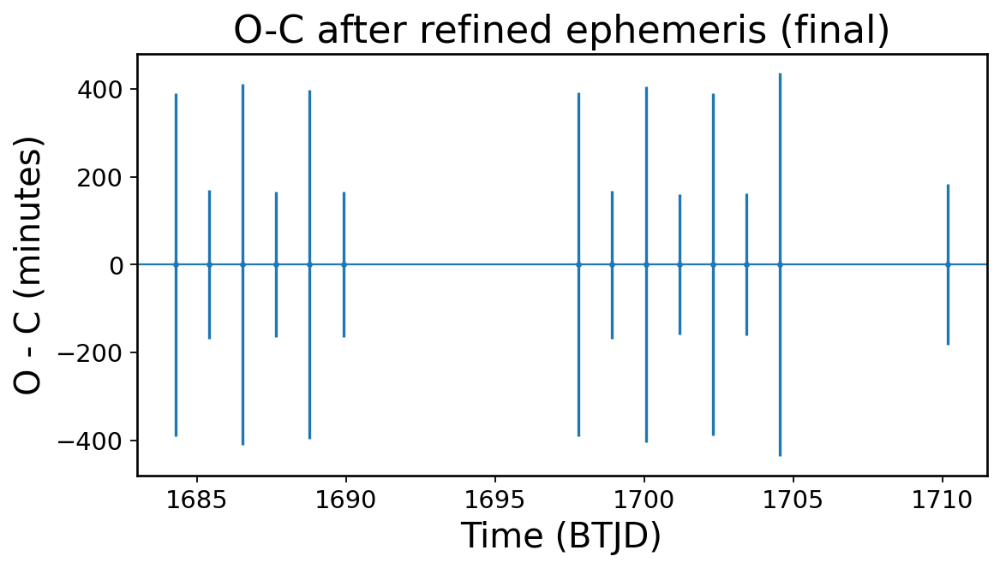

In [44]:
# Recompute O-C with refined ephemeris

E_ref = np.round((t_clean - T0_ref)/P_ref).astype(int)
t_calc_ref = T0_ref + E_ref * P_ref

oc_ref = (t_clean - t_calc_ref) * 24*60  # minutes

plt.figure(figsize=(8,4))
plt.errorbar(t_clean, oc_ref, yerr=sig_clean, fmt=".", markersize=4)
plt.axhline(0, linewidth=1)
plt.xlabel("Time (BTJD)")
plt.ylabel("O - C (minutes)")
plt.title("O-C after refined ephemeris (final)")
plt.show()

In [45]:
def robust_rms_mad(x):
    med = np.median(x)
    mad = np.median(np.abs(x - med))
    return 1.4826 * mad

print("Final RMS (min):", np.std(oc_ref))
print("Final robust RMS (min):", robust_rms_mad(oc_ref))

Final RMS (min): 0.041008417146518206
Final robust RMS (min): 0.055146118618667965


In [46]:
print("oc_ref min/max (min):", np.min(oc_ref), np.max(oc_ref))
print("sig_clean min/median/max (min):",
      np.min(sig_clean), np.median(sig_clean), np.max(sig_clean))

oc_ref min/max (min): -0.07050661348330323 0.0728725608496461
sig_clean min/median/max (min): 159.07635104867225 286.3027440177473 436.25731138331076


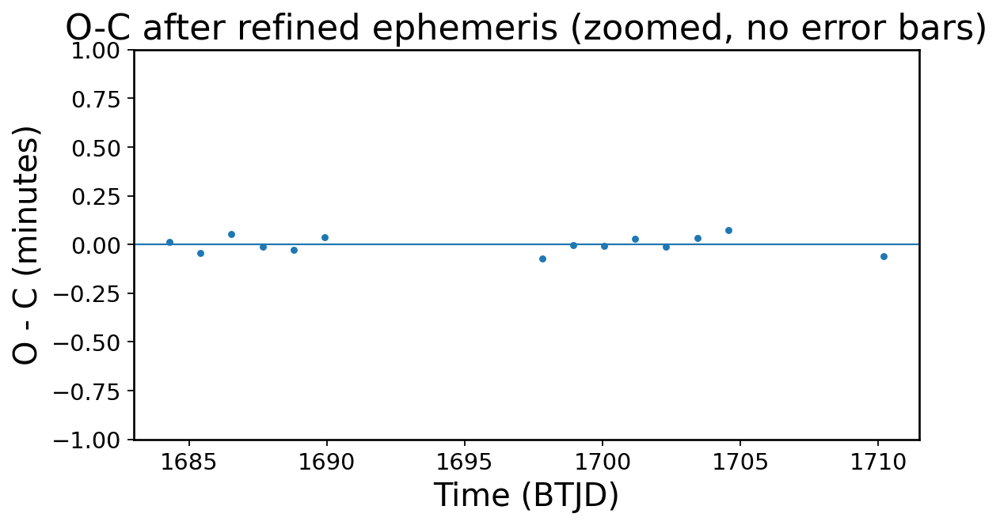

In [47]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8,4))
plt.plot(t_clean, oc_ref, ".", markersize=6)
plt.axhline(0, linewidth=1)
plt.ylim(-1, 1)  # +/- 1 minute window (adjust if needed)
plt.xlabel("Time (BTJD)")
plt.ylabel("O - C (minutes)")
plt.title("O-C after refined ephemeris (zoomed, no error bars)")
plt.show()

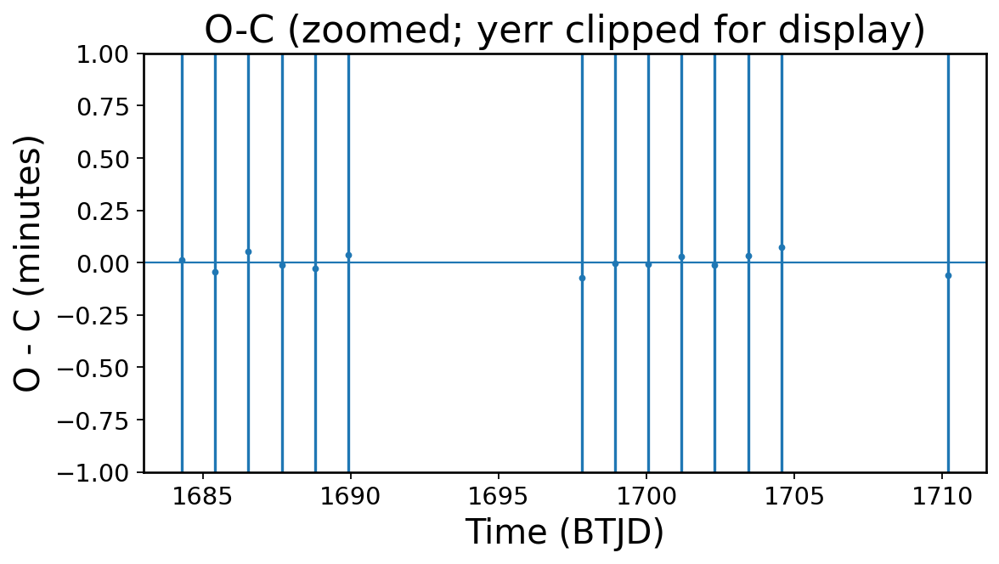

In [48]:
# clip yerr to a reasonable cap so plot stays readable
cap = np.nanpercentile(sig_clean, 80)  # cap at 80th percentile
yerr_plot = np.minimum(sig_clean, cap)

plt.figure(figsize=(8,4))
plt.errorbar(t_clean, oc_ref, yerr=yerr_plot, fmt=".", markersize=5)
plt.axhline(0, linewidth=1)
plt.ylim(-1, 1)
plt.xlabel("Time (BTJD)")
plt.ylabel("O - C (minutes)")
plt.title("O-C (zoomed; yerr clipped for display)")
plt.show()

In [49]:
import numpy as np
from scipy.optimize import minimize_scalar

def bootstrap_sigma_t(tt, ff, ee, t_calc, P, F, dF,
                      nboot=200, half_window_phase=0.12, search_phase=0.05, seed=0):
    """
    Bootstrap uncertainty for timing shift:
    - Fit shift once
    - Build residuals
    - Resample residuals and refit shift nboot times
    Returns sigma_t in days.
    """
    rng = np.random.default_rng(seed)
    phase = (tt - t_calc)/P

    # helper: fit shift using derivative method (fast)
    t_obs, oc, sigma_t, shift, (a,b) = derivative_timing_one_eclipse(tt, ff, ee, t_calc, P, F, dF)
    if not np.isfinite(shift):
        return np.nan

    model = a + b * F(phase - shift)
    resid = ff - model

    shifts = []
    for _ in range(nboot):
        # resample residuals with replacement
        resamp = rng.choice(resid, size=len(resid), replace=True)
        f_boot = model + resamp

        # re-estimate shift
        t_obs_b, oc_b, sig_b, shift_b, _ = derivative_timing_one_eclipse(tt, f_boot, ee, t_calc, P, F, dF)
        if np.isfinite(shift_b):
            shifts.append(shift_b)

    if len(shifts) < max(20, 0.2*nboot):
        return np.nan

    shifts = np.array(shifts)
    sigma_shift = np.std(shifts)
    return sigma_shift * P  # days

Bootstrap sigma min/median/max (min): 0.1365122372673036 0.17829377155668077 1023.5023226194807


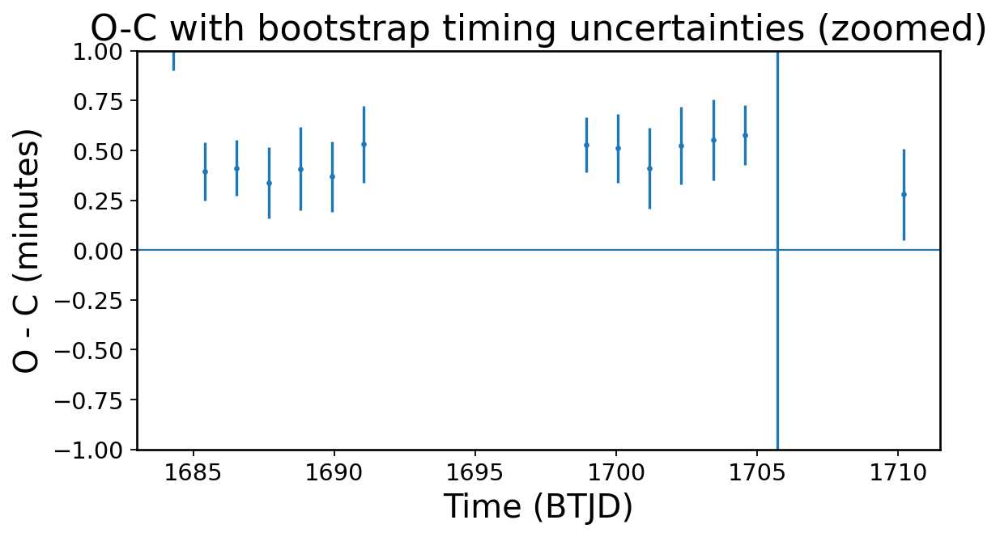

In [50]:
import numpy as np
import matplotlib.pyplot as plt

T0 = T0_ref
P  = P_ref

gap = np.diff(t)
breaks = np.where(gap > 5)[0]
segments = np.split(np.arange(len(t)), breaks + 1)

tobs2, oc2, sig2, E2 = [], [], [], []

half_window_phase = 0.12
min_points = 25

for si, seg in enumerate(segments):
    t_seg = t[seg]
    f_seg = flux[seg]
    e_seg = flux_err[seg] if flux_err is not None else np.ones_like(f_seg) * np.std(f_seg)

    tp_seg, tf_seg = build_template(t_seg, f_seg, T0, P)
    F, dF = make_template_interpolators(tp_seg, tf_seg)

    E_min = int(np.floor((t_seg.min() - T0)/P)) - 1
    E_max = int(np.ceil((t_seg.max() - T0)/P)) + 1
    epochs = np.arange(E_min, E_max+1)

    half_window = half_window_phase * P

    for E in epochs:
        t_calc = T0 + E*P
        m = (t_seg > t_calc - half_window) & (t_seg < t_calc + half_window)
        if np.sum(m) < min_points:
            continue

        tt = t_seg[m]; ff = f_seg[m]; ee = e_seg[m]

        # timing estimate
        t_obs, oc, _, shift, (a,b) = derivative_timing_one_eclipse(tt, ff, ee, t_calc, P, F, dF)
        if not np.isfinite(t_obs):
            continue

        # bootstrap uncertainty (days)
        sig_t_days = bootstrap_sigma_t(tt, ff, ee, t_calc, P, F, dF,
                                       nboot=200, seed=si*100000 + int(E))

        tobs2.append(t_obs)
        oc2.append(oc)
        sig2.append(sig_t_days)
        E2.append(E)

tobs2 = np.array(tobs2)
oc2   = np.array(oc2) * 24*60  # minutes
sig2  = np.array(sig2) * 24*60 # minutes
E2    = np.array(E2, dtype=int)

print("Bootstrap sigma min/median/max (min):", np.nanmin(sig2), np.nanmedian(sig2), np.nanmax(sig2))

plt.figure(figsize=(8,4))
plt.errorbar(tobs2, oc2, yerr=sig2, fmt=".", markersize=4)
plt.axhline(0, linewidth=1)
plt.ylim(-1, 1)  # zoom to ±1 minute
plt.xlabel("Time (BTJD)")
plt.ylabel("O - C (minutes)")
plt.title("O-C with bootstrap timing uncertainties (zoomed)")
plt.show()

In [51]:
import numpy as np

t = tobs2                 # BTJD
y = oc2                   # minutes
s = sig2                  # minutes

m = np.isfinite(t) & np.isfinite(y) & np.isfinite(s) & (s > 0)
t = t[m]; y = y[m]; s = s[m]

w = 1.0 / (s**2)

t0 = np.mean(t)           # center time to reduce numerical issues
x = t - t0

In [52]:
a0 = np.sum(w*y)/np.sum(w)
yhat0 = a0*np.ones_like(y)
chi2_0 = np.sum(((y - yhat0)/s)**2)
k0 = 1

In [53]:
A = np.vstack([np.ones_like(x), x]).T
W = np.diag(w)
beta = np.linalg.inv(A.T @ W @ A) @ (A.T @ W @ y)
a1, b1 = beta
yhat1 = a1 + b1*x
chi2_1 = np.sum(((y - yhat1)/s)**2)
k1 = 2

In [54]:
late = (t > np.median(t)).astype(float)

A = np.vstack([np.ones_like(x), late]).T
beta = np.linalg.inv(A.T @ W @ A) @ (A.T @ W @ y)
a2, d2 = beta
yhat2 = a2 + d2*late
chi2_2 = np.sum(((y - yhat2)/s)**2)
k2 = 2

In [55]:
n = len(y)
def BIC(chi2, k, n):
    return chi2 + k*np.log(n)

bic0 = BIC(chi2_0, k0, n)
bic1 = BIC(chi2_1, k1, n)
bic2 = BIC(chi2_2, k2, n)

print("n =", n)
print("Constant: chi2 =", chi2_0, "BIC =", bic0)
print("Linear:    chi2 =", chi2_1, "BIC =", bic1, "slope (min/day) =", b1)
print("Step:      chi2 =", chi2_2, "BIC =", bic2, "jump Δ (min) =", d2)

print("\nΔBIC relative to constant:")
print("Linear:", bic1 - bic0)
print("Step:  ", bic2 - bic0)

n = 16
Constant: chi2 = 48.69862336364212 BIC = 51.4712120858819
Linear:    chi2 = 48.69744989742738 BIC = 54.242627341906946 slope (min/day) = -0.0001949734740402196
Step:      chi2 = 46.79007815912516 BIC = 52.33525560360472 jump Δ (min) = -0.12326151392704676

ΔBIC relative to constant:
Linear: 2.771415256025044
Step:   0.8640435177228198


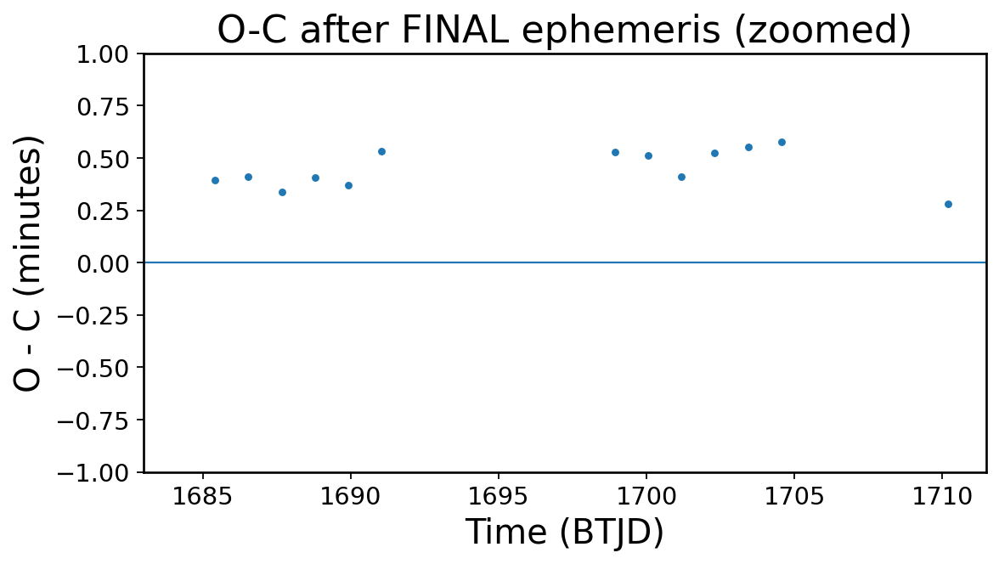

In [56]:
oc_final = (tobs2 - (T0_final + np.round((tobs2 - T0_final)/P_final)*P_final)) * 24*60

plt.figure(figsize=(8,4))
plt.plot(tobs2, oc_final, ".", markersize=6)
plt.axhline(0, linewidth=1)
plt.ylim(-1, 1)  # zoom to ±1 minute
plt.xlabel("Time (BTJD)")
plt.ylabel("O - C (minutes)")
plt.title("O-C after FINAL ephemeris (zoomed)")
plt.show()

In [57]:
chi2_final = np.sum((oc_final/sig2)**2)
dof = len(oc_final) - 1
print("Reduced chi2:", chi2_final/dof)

Reduced chi2: 14.422604602162785


SearchResult containing 7 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 24 2020   SPOC     120   275423476      0.0
  1 TESS Sector 56 2022   SPOC     120   275423476      0.0
  2 TESS Sector 58 2022   SPOC     120   275423476      0.0
  3 TESS Sector 76 2024   SPOC     120   275423476      0.0
  4 TESS Sector 77 2024   SPOC     120   275423476      0.0
  5 TESS Sector 78 2024   SPOC     120   275423476      0.0
  6 TESS Sector 83 2024   SPOC     120   275423476      0.0


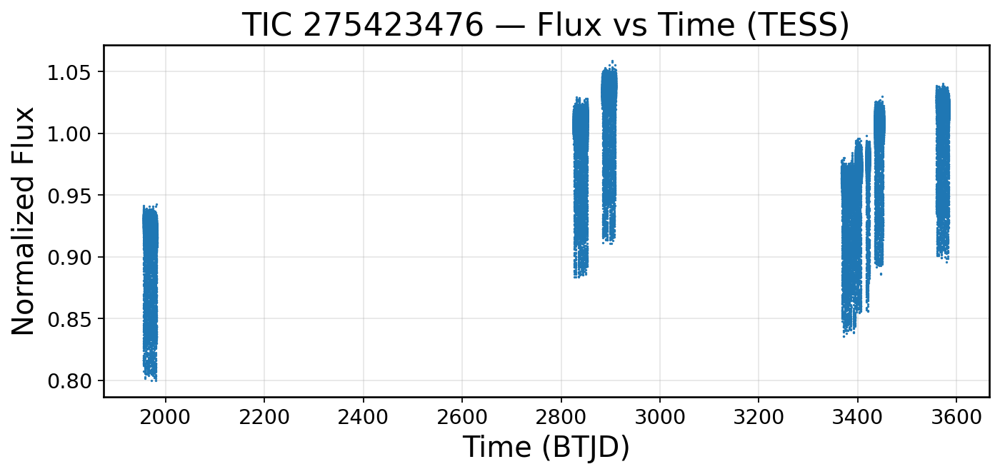

In [58]:
import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk

TIC = "TIC 275423476"

# Search and download SPOC light curves (PDCSAP if available)
sr = lk.search_lightcurve(TIC, mission="TESS", author="SPOC")
print(sr)

lc_collection = sr.download_all()

# Stitch all sectors together into one light curve
lc = lc_collection.stitch().remove_nans()

# Prefer PDCSAP if present; otherwise use lc.flux
if hasattr(lc, "pdcsap_flux") and lc.pdcsap_flux is not None:
    flux = lc.pdcsap_flux.value
    flux_err = lc.pdcsap_flux_err.value if lc.pdcsap_flux_err is not None else None
else:
    flux = lc.flux.value
    flux_err = lc.flux_err.value if lc.flux_err is not None else None

t = lc.time.value  # BTJD (days)

# Optional: normalize (helps visualization)
flux_norm = flux / np.nanmedian(flux)

plt.figure(figsize=(10,4))
plt.plot(t, flux_norm, ".", markersize=1)
plt.xlabel("Time (BTJD)")
plt.ylabel("Normalized Flux")
plt.title("TIC 275423476 — Flux vs Time (TESS)")
plt.grid(True, alpha=0.3)
plt.show()

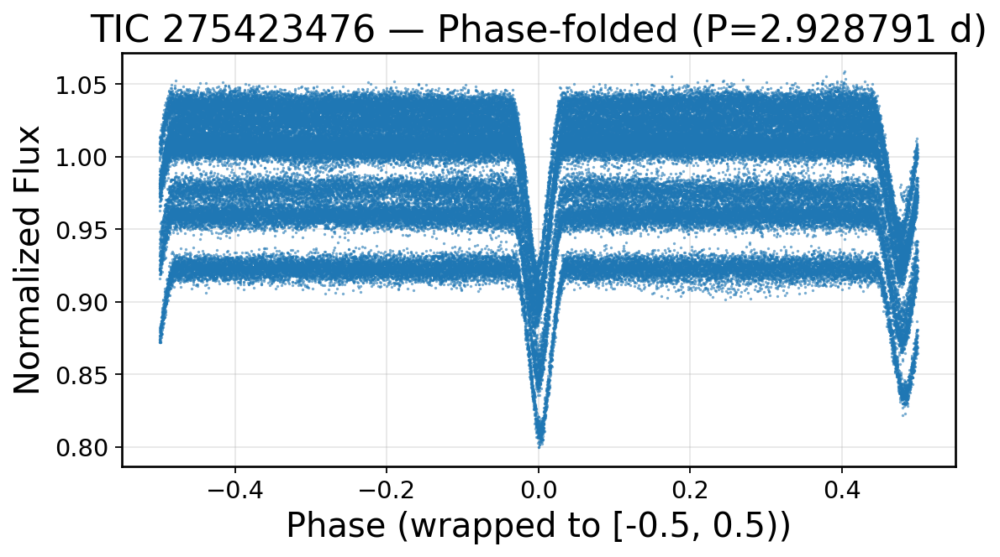

In [59]:
P = 2.9287911639400495
T0_guess = t[np.argmin(flux_norm)]  # rough epoch at deepest dip

phi = ((t - T0_guess)/P) % 1.0
phi = np.where(phi >= 0.5, phi - 1.0, phi)

plt.figure(figsize=(8,4))
plt.plot(phi, flux_norm, ".", markersize=1, alpha=0.6)
plt.xlabel("Phase (wrapped to [-0.5, 0.5))")
plt.ylabel("Normalized Flux")
plt.title(f"TIC 275423476 — Phase-folded (P={P:.6f} d)")
plt.grid(True, alpha=0.3)
plt.show()

In [60]:
flux_norm = flux / np.nanmedian(flux)

In [61]:
P = 2.9287911639400495
i0 = np.nanargmin(flux_norm)
T0_rough = t[i0]
print("T0_rough (BTJD):", T0_rough)

T0_rough (BTJD): 1979.6312189691248


In [62]:
import numpy as np

def refine_T0_parabola(t, f, T0_rough, window=0.12):
    """
    Fit a quadratic f = a(t-T)^2 + b(t-T) + c in a small window around T0_rough.
    Returns refined T0 (vertex time).
    window in days.
    """
    m = (t > T0_rough - window) & (t < T0_rough + window)
    tt = t[m]
    ff = f[m]

    # Center time for numerical stability
    x = tt - T0_rough

    # Fit quadratic: ff = A x^2 + B x + C
    A, B, C = np.polyfit(x, ff, 2)

    # Vertex location: x0 = -B/(2A)
    x0 = -B/(2*A)
    return T0_rough + x0, (A, B, C)

T0, quad = refine_T0_parabola(t, flux_norm, T0_rough, window=0.12)
print("T0_refined (BTJD):", T0)

T0_refined (BTJD): 1979.6348761787106


In [63]:
from scipy.optimize import minimize_scalar

def phase_fold(t, T0, P):
    phi = ((t - T0) / P) % 1.0
    phi = np.where(phi >= 0.5, phi - 1.0, phi)
    return phi

# Build a simple empirical template for primary eclipse only
phi = phase_fold(t, T0, P)
win = 0.15
mtemp = np.abs(phi) < win

bins = np.linspace(-win, win, 300)
centers = 0.5*(bins[:-1] + bins[1:])
digit = np.digitize(phi[mtemp], bins) - 1
template = np.array([np.nanmedian(flux_norm[mtemp][digit==i]) for i in range(len(centers))])
ok = np.isfinite(template)
tp, tf = centers[ok], template[ok]

def F(phase):
    return np.interp(phase, tp, tf, left=1.0, right=1.0)

# Eclipse timing extraction
E_min = int(np.floor((t.min() - T0)/P)) - 1
E_max = int(np.ceil((t.max() - T0)/P)) + 1
epochs = np.arange(E_min, E_max+1)

t_obs_list = []
E_list = []

half_window = 0.20 * P

for E in epochs:
    t_calc = T0 + E*P
    m = (t > t_calc-half_window) & (t < t_calc+half_window)
    if np.sum(m) < 25:
        continue

    tt = t[m]
    ff = flux_norm[m]
    ph = (tt - t_calc)/P

    # minimize SSE over shift
    def sse(dphi):
        return np.sum((ff - F(ph - dphi))**2)

    out = minimize_scalar(sse, bounds=(-0.05, 0.05), method="bounded")
    dphi = out.x
    t_obs = t_calc + dphi*P

    t_obs_list.append(t_obs)
    E_list.append(E)

t_obs_list = np.array(t_obs_list)
E_list = np.array(E_list)

print("Measured eclipses:", len(t_obs_list))

Measured eclipses: 62


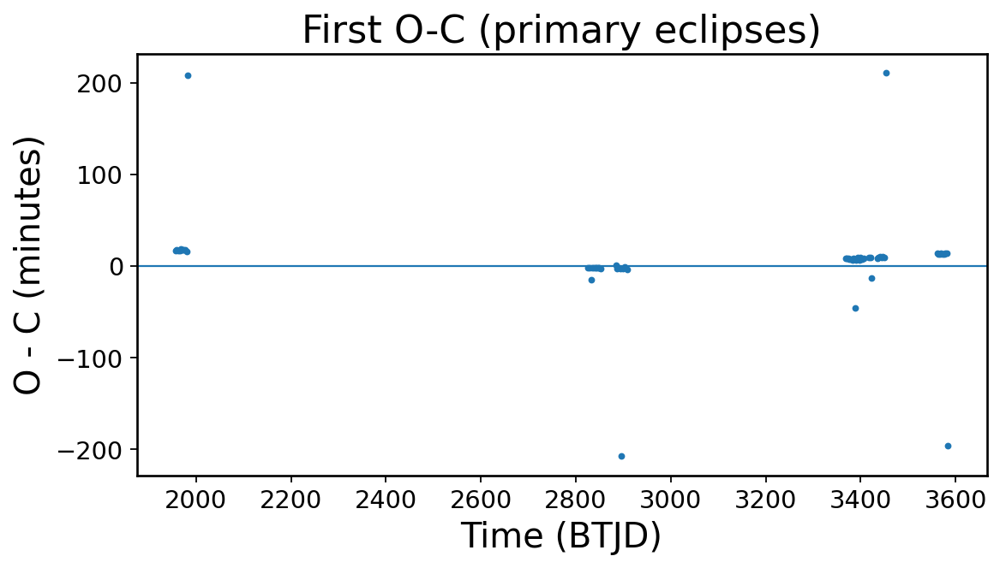

In [64]:
t_calc_list = T0 + E_list*P
oc_min = (t_obs_list - t_calc_list) * 24*60

import matplotlib.pyplot as plt
plt.figure(figsize=(8,4))
plt.plot(t_obs_list, oc_min, ".", markersize=5)
plt.axhline(0, linewidth=1)
plt.xlabel("Time (BTJD)")
plt.ylabel("O - C (minutes)")
plt.title("First O-C (primary eclipses)")
plt.show()

In [65]:
phi01 = ((t - T0)/P) % 1.0  # in [0,1)
# search near secondary around 0.5
msec = (phi01 > 0.35) & (phi01 < 0.65)

# bin and find minimum
bins = np.linspace(0.35, 0.65, 300)
centers = 0.5*(bins[:-1]+bins[1:])
digit = np.digitize(phi01[msec], bins) - 1
bflux = np.array([np.nanmedian(flux_norm[msec][digit==i]) for i in range(len(centers))])

phi_sec = centers[np.nanargmin(bflux)]
print("Estimated secondary eclipse phase:", phi_sec)

e_cosw = np.pi * (phi_sec - 0.5)
print("e cos(omega) ≈", e_cosw)

Estimated secondary eclipse phase: 0.4779264214046822
e cos(omega) ≈ -0.06934619235348724


In [66]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

P = 2.9287911639400495

t = np.asarray(t)
flux_norm = np.asarray(flux_norm)

print("N points:", len(t))
print("Time range (BTJD):", np.nanmin(t), "to", np.nanmax(t))
print("Median flux:", np.nanmedian(flux_norm))

N points: 117549
Time range (BTJD): 1955.7934772816825 to 3584.3767641661602
Median flux: 1.0


In [67]:
# rough epoch from deepest point
i0 = np.nanargmin(flux_norm)
T0_rough = t[i0]
print("T0_rough (BTJD):", T0_rough)

def refine_T0_parabola(t, f, T0_rough, window=0.12):
    """
    Quadratic fit near eclipse minimum:
      f(x) = A x^2 + B x + C  where x = t - T0_rough
    Vertex gives refined minimum at x0 = -B/(2A).
    """
    m = (t > T0_rough - window) & (t < T0_rough + window)
    tt = t[m]
    ff = f[m]

    x = tt - T0_rough
    A, B, C = np.polyfit(x, ff, 2)

    x0 = -B/(2*A)
    T0_ref = T0_rough + x0
    return T0_ref, (A, B, C)

T0, quad = refine_T0_parabola(t, flux_norm, T0_rough, window=0.12)
print("T0_refined (BTJD):", T0)
print("Quadratic coeffs (A,B,C):", quad)

T0_rough (BTJD): 1979.6312189691248
T0_refined (BTJD): 1979.6348761787106
Quadratic coeffs (A,B,C): (np.float64(8.537540222750557), np.float64(-0.06244714788437739), np.float64(0.8371161913461792))


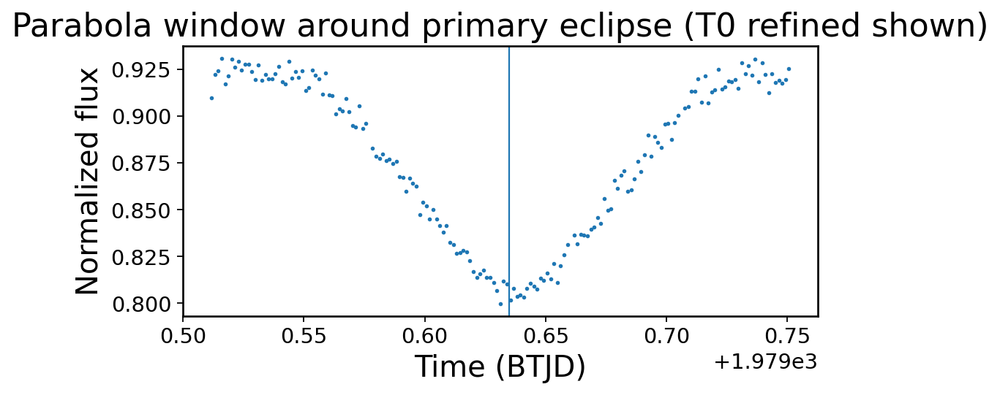

In [68]:
m = (t > T0_rough - 0.12) & (t < T0_rough + 0.12)
plt.figure(figsize=(7,3))
plt.plot(t[m], flux_norm[m], ".", markersize=3)
plt.axvline(T0, linewidth=1)
plt.title("Parabola window around primary eclipse (T0 refined shown)")
plt.xlabel("Time (BTJD)")
plt.ylabel("Normalized flux")
plt.show()

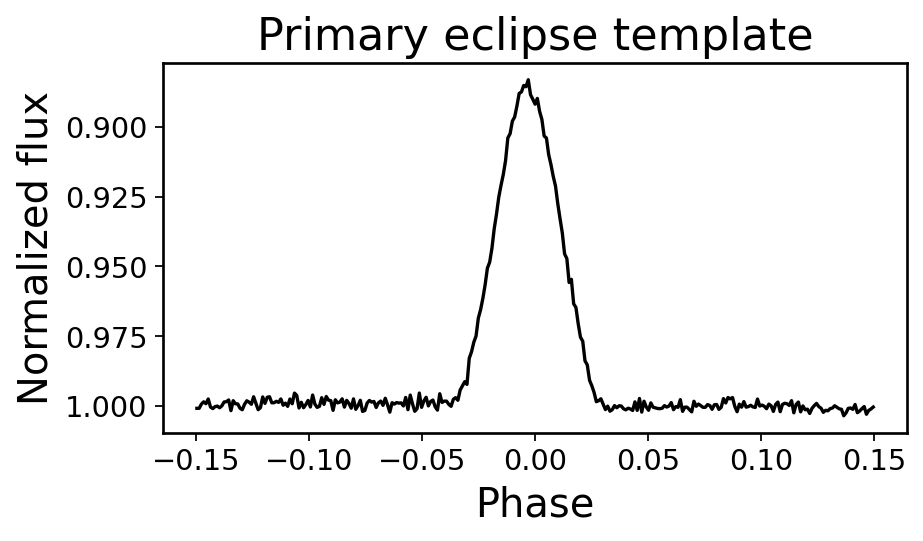

In [69]:
def phase_fold_centered(t, T0, P):
    """Phase in [-0.5, 0.5)."""
    phi = ((t - T0)/P) % 1.0
    phi = np.where(phi >= 0.5, phi - 1.0, phi)
    return phi

phi = phase_fold_centered(t, T0, P)

win = 0.15
mtemp = np.abs(phi) < win

bins = np.linspace(-win, win, 300)
centers = 0.5*(bins[:-1] + bins[1:])
digit = np.digitize(phi[mtemp], bins) - 1

template = np.array([np.nanmedian(flux_norm[mtemp][digit==i]) for i in range(len(centers))])
ok = np.isfinite(template)

tp, tf = centers[ok], template[ok]

# normalize template wings to ~1
wing = np.abs(tp) > (0.7*win)
tf = tf / np.nanmedian(tf[wing])

def F(phase):
    return np.interp(phase, tp, tf, left=1.0, right=1.0)

plt.figure(figsize=(6,3))
plt.plot(tp, tf, "-k")
plt.gca().invert_yaxis()
plt.title("Primary eclipse template")
plt.xlabel("Phase")
plt.ylabel("Normalized flux")
plt.show()

Measured primary eclipses: 61
O-C min/max (minutes): -147.0791711804486 168.76017974020215


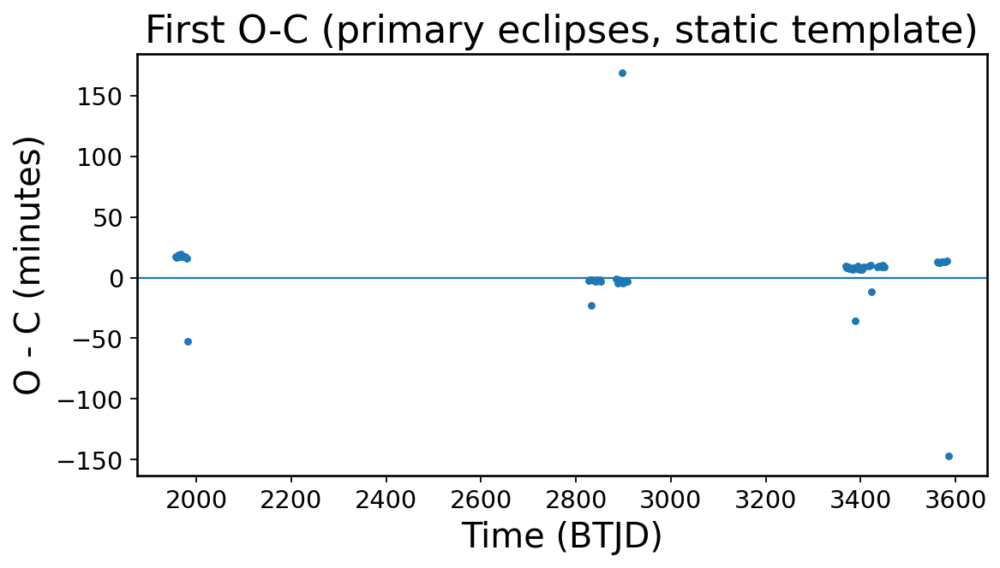

In [70]:
E_min = int(np.floor((t.min() - T0)/P)) - 1
E_max = int(np.ceil((t.max() - T0)/P)) + 1
epochs = np.arange(E_min, E_max+1)

half_window = 0.12 * P

t_obs_list = []
E_list = []

for E in epochs:
    t_calc = T0 + E*P
    m = (t > t_calc-half_window) & (t < t_calc+half_window)
    if np.sum(m) < 25:
        continue

    tt = t[m]
    ff = flux_norm[m]
    ph = (tt - t_calc)/P

    def sse(dphi):
        return np.sum((ff - F(ph - dphi))**2)

    out = minimize_scalar(sse, bounds=(-0.05, 0.05), method="bounded")
    dphi = out.x
    t_obs = t_calc + dphi*P

    t_obs_list.append(t_obs)
    E_list.append(E)

t_obs_list = np.array(t_obs_list)
E_list = np.array(E_list)

t_calc_list = T0 + E_list*P
oc_min = (t_obs_list - t_calc_list) * 24*60

print("Measured primary eclipses:", len(t_obs_list))
print("O-C min/max (minutes):", np.min(oc_min), np.max(oc_min))

plt.figure(figsize=(8,4))
plt.plot(t_obs_list, oc_min, ".", markersize=6)
plt.axhline(0, linewidth=1)
plt.xlabel("Time (BTJD)")
plt.ylabel("O - C (minutes)")
plt.title("First O-C (primary eclipses, static template)")
plt.show()

Secondary eclipse phase ≈ 0.4779264214046822
e cos(omega) ≈ -0.06934619235348724


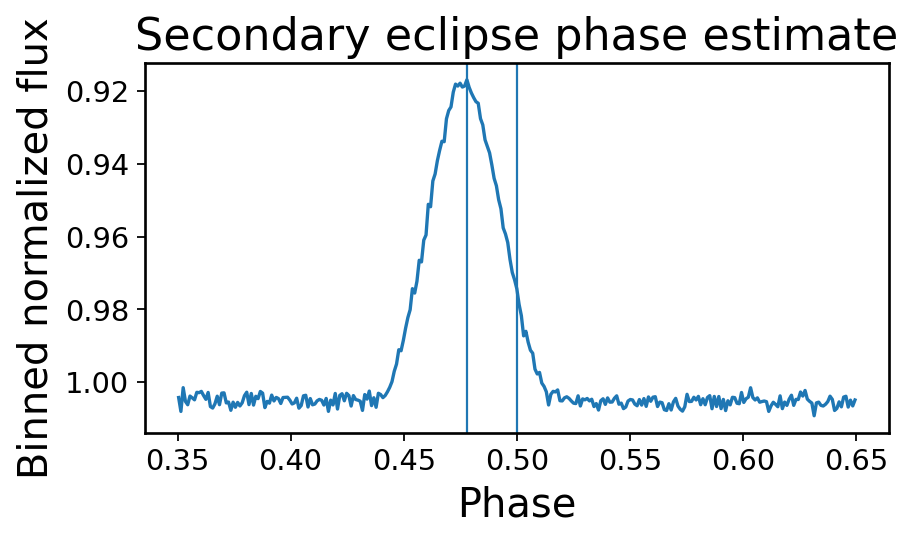

In [71]:
phi01 = ((t - T0)/P) % 1.0  # phase in [0,1)

# focus around where secondary should be
msec = (phi01 > 0.35) & (phi01 < 0.65)

bins = np.linspace(0.35, 0.65, 300)
centers = 0.5*(bins[:-1] + bins[1:])
digit = np.digitize(phi01[msec], bins) - 1

bflux = np.array([np.nanmedian(flux_norm[msec][digit==i]) for i in range(len(centers))])
ok = np.isfinite(bflux)

phi_sec = centers[ok][np.nanargmin(bflux[ok])]
e_cosw = np.pi * (phi_sec - 0.5)

print("Secondary eclipse phase ≈", phi_sec)
print("e cos(omega) ≈", e_cosw)

plt.figure(figsize=(6,3))
plt.plot(centers[ok], bflux[ok], "-")
plt.axvline(0.5, linewidth=1)
plt.axvline(phi_sec, linewidth=1)
plt.gca().invert_yaxis()
plt.title("Secondary eclipse phase estimate")
plt.xlabel("Phase")
plt.ylabel("Binned normalized flux")
plt.show()

In [72]:
P = 2.9287911639400495

In [73]:
import numpy as np

# Split where time gap is large (typical between sectors)
gap_days = 5.0  # works well for TESS; adjust to 3–8 if needed

gap = np.diff(t)
breaks = np.where(gap > gap_days)[0]
segments = np.split(np.arange(len(t)), breaks + 1)

print("Number of segments:", len(segments))
print("Segment sizes:", [len(s) for s in segments])
print("Segment time ranges:")
for i, seg in enumerate(segments):
    print(i, np.min(t[seg]), "to", np.max(t[seg]))

Number of segments: 7
Segment sizes: [18217, 19463, 17964, 27308, 4591, 12676, 17330]
Segment time ranges:
0 1955.7934772816825 to 1982.2784912447485
1 2825.259124208658 to 2853.1400495767825
2 2883.2677301616795 to 2910.0491661410397
3 3367.6974798295146 to 3407.2025205481114
4 3417.1506838718988 to 3423.546560761627
5 3434.2702825892075 to 3452.320608871669
6 3559.4570168884784 to 3584.3767641661602


In [74]:
def phase_fold_centered(tt, T0, P):
    phi = ((tt - T0)/P) % 1.0
    phi = np.where(phi >= 0.5, phi - 1.0, phi)
    return phi

def build_primary_template(t_seg, f_seg, T0, P, win=0.15, nbins=300):
    phi = phase_fold_centered(t_seg, T0, P)
    m = np.abs(phi) < win

    bins = np.linspace(-win, win, nbins+1)
    centers = 0.5*(bins[:-1] + bins[1:])
    digit = np.digitize(phi[m], bins) - 1

    tf = np.array([np.nanmedian(f_seg[m][digit==i]) for i in range(nbins)])
    ok = np.isfinite(tf)

    tp = centers[ok]
    tf = tf[ok]

    # normalize wings to ~1
    wing = np.abs(tp) > (0.7*win)
    tf = tf / np.nanmedian(tf[wing]) if np.any(wing) else tf / np.nanmedian(tf)

    return tp, tf

In [75]:
templates = []

for i, seg in enumerate(segments):
    t_seg = t[seg]
    f_seg = flux_norm[seg]

    tp, tf = build_primary_template(t_seg, f_seg, T0, P)

    if tp is None or tf is None or len(tp) < 5 or len(tf) < 5:
        templates.append((None, None))
        print(f"Segment {i}: bad template, skipped")
    else:
        templates.append((tp, tf))
        print(f"Segment {i}: template points = {len(tp)}")

Segment 0: template points = 300
Segment 1: template points = 300
Segment 2: template points = 300
Segment 3: template points = 300
Segment 4: template points = 300
Segment 5: template points = 300
Segment 6: template points = 300


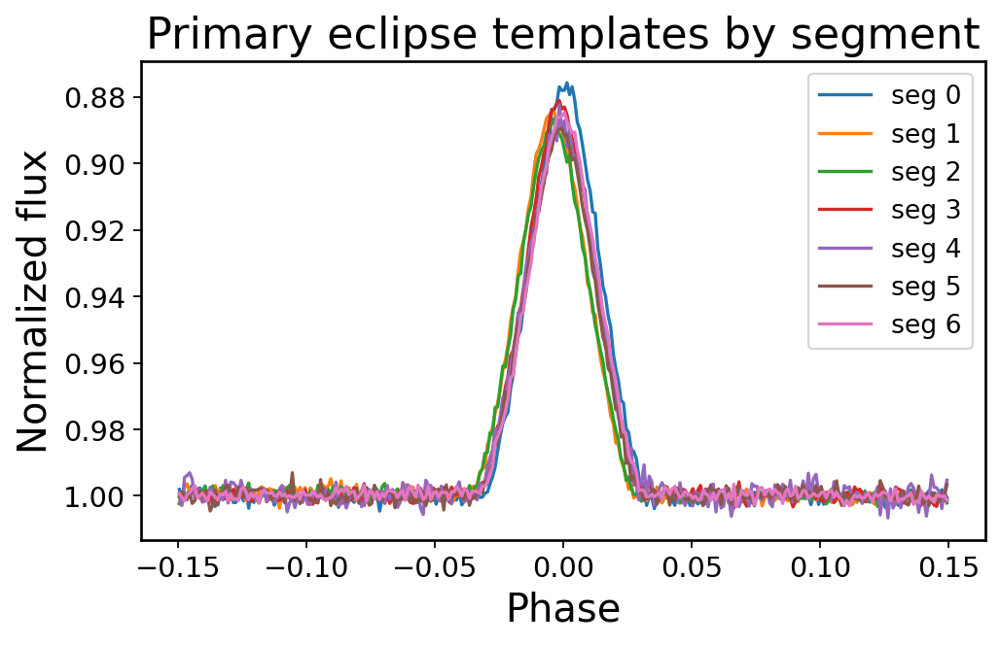

In [76]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,4))
for i, (tp, tf) in enumerate(templates):
    plt.plot(tp, tf, label=f"seg {i}")
plt.gca().invert_yaxis()
plt.xlabel("Phase")
plt.ylabel("Normalized flux")
plt.title("Primary eclipse templates by segment")
plt.legend()
plt.show()

In [77]:
from scipy.optimize import minimize_scalar

def template_interp(tp, tf, phase):
    return np.interp(phase, tp, tf, left=1.0, right=1.0)

def extract_primary_timings_segment(t_seg, f_seg, T0, P, tp, tf,
                                    half_window_phase=0.12, search_phase=0.05,
                                    min_points=25):
    E_min = int(np.floor((t_seg.min() - T0)/P)) - 1
    E_max = int(np.ceil((t_seg.max() - T0)/P)) + 1
    epochs = np.arange(E_min, E_max+1)

    half_window = half_window_phase * P

    t_obs_list, oc_list, E_list = [], [], []

    for E in epochs:
        t_calc = T0 + E*P
        m = (t_seg > t_calc-half_window) & (t_seg < t_calc+half_window)
        if np.sum(m) < min_points:
            continue

        tt = t_seg[m]
        ff = f_seg[m]
        ph = (tt - t_calc)/P

        def sse(dphi):
            model = template_interp(tp, tf, ph - dphi)
            return np.sum((ff - model)**2)

        out = minimize_scalar(sse, bounds=(-search_phase, search_phase), method="bounded")
        dphi = out.x

        t_obs = t_calc + dphi*P
        oc = t_obs - t_calc

        t_obs_list.append(t_obs)
        oc_list.append(oc)
        E_list.append(E)

    return np.array(t_obs_list), np.array(oc_list), np.array(E_list, dtype=int)

In [78]:
all_tobs = []
all_oc = []
all_E = []
all_seg_id = []

for i, seg in enumerate(segments):
    t_seg = t[seg]
    f_seg = flux_norm[seg]
    tp, tf = templates[i]

    t_obs_i, oc_i, E_i = extract_primary_timings_segment(t_seg, f_seg, T0, P, tp, tf)

    all_tobs.append(t_obs_i)
    all_oc.append(oc_i)
    all_E.append(E_i)
    all_seg_id.append(np.full(len(t_obs_i), i))

all_tobs = np.concatenate(all_tobs)
all_oc = np.concatenate(all_oc)
all_E = np.concatenate(all_E)
all_seg_id = np.concatenate(all_seg_id)

print("Total eclipses measured:", len(all_tobs))

Total eclipses measured: 61


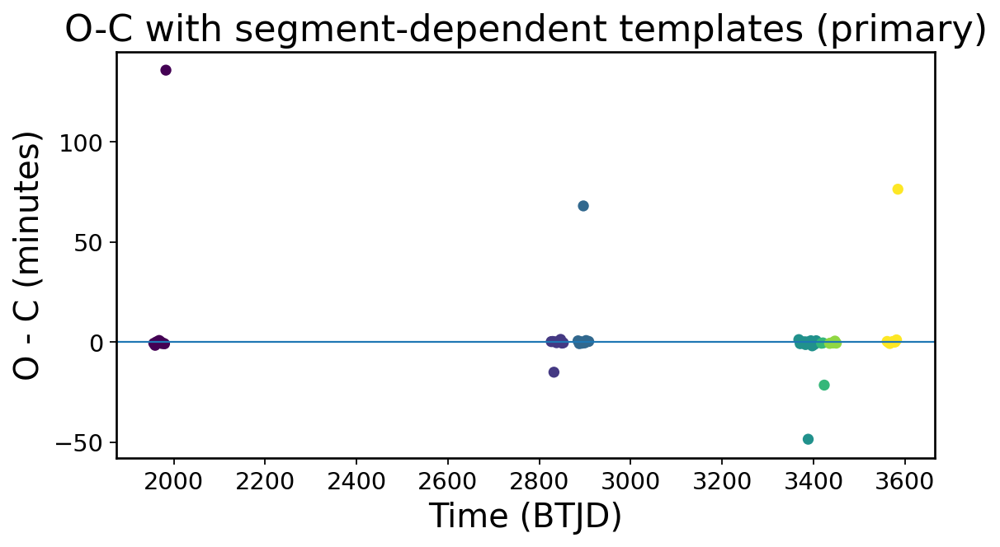

In [79]:
oc_min = all_oc * 24*60

plt.figure(figsize=(8,4))
plt.scatter(all_tobs, oc_min, c=all_seg_id, s=25)
plt.axhline(0, linewidth=1)
plt.xlabel("Time (BTJD)")
plt.ylabel("O - C (minutes)")
plt.title("O-C with segment-dependent templates (primary)")
plt.show()

Kept eclipses: 58
Rejected outliers: 3


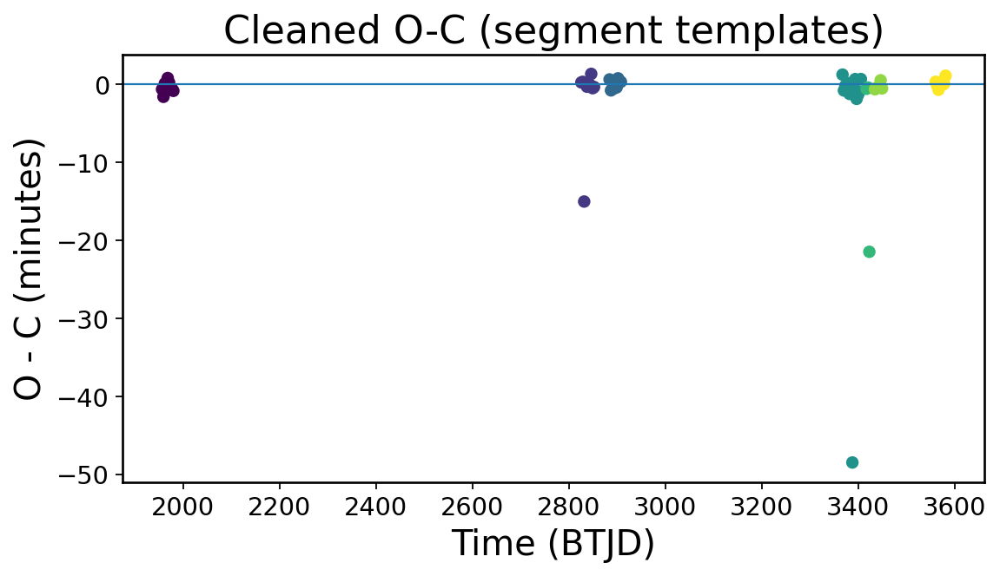

In [80]:
# convert to minutes
oc_min = all_oc * 24*60

# remove large outliers (>60 min)
good = np.abs(oc_min) < 60

t_clean = all_tobs[good]
oc_clean = oc_min[good]
seg_clean = all_seg_id[good]

print("Kept eclipses:", len(t_clean))
print("Rejected outliers:", np.sum(~good))

plt.figure(figsize=(8,4))
plt.scatter(t_clean, oc_clean, c=seg_clean, s=30)
plt.axhline(0, linewidth=1)
plt.xlabel("Time (BTJD)")
plt.ylabel("O - C (minutes)")
plt.title("Cleaned O-C (segment templates)")
plt.show()

In [81]:
E = np.round((t_clean - T0)/P).astype(int)

A = np.vstack([np.ones_like(E), E]).T
coeff = np.linalg.lstsq(A, t_clean, rcond=None)[0]

T0_new, P_new = coeff

print("Updated T0:", T0_new)
print("Updated P :", P_new)

Updated T0: 1979.634717327214
Updated P : 2.9287885579105786


In [82]:
print("RMS (min):", np.std(oc_clean))
print("Robust RMS (min):", 1.4826*np.median(np.abs(oc_clean-np.median(oc_clean))))

RMS (min): 7.088435774706152
Robust RMS (min): 0.6361730017374794


In [83]:
oc_min = all_oc * 24*60

# robust center + scale
med = np.median(oc_min[np.isfinite(oc_min)])
mad = np.median(np.abs(oc_min - med))
sig = 1.4826 * mad

good = np.isfinite(oc_min) & (np.abs(oc_min - med) < 4*sig)

t1   = all_tobs[good]
oc1  = oc_min[good]
E1   = all_E[good]
seg1 = all_seg_id[good]

print("Kept:", len(t1), "Rejected:", np.sum(~good))
print("Robust scatter (min):", sig)

Kept: 55 Rejected: 6
Robust scatter (min): 0.6554161484994984


In [84]:
A = np.vstack([np.ones_like(E1), E1]).T
T0_new, P_new = np.linalg.lstsq(A, t1, rcond=None)[0]

print("Updated T0:", T0_new)
print("Updated P :", P_new)

Updated T0: 1979.6347295437777
Updated P : 2.9287913280622715


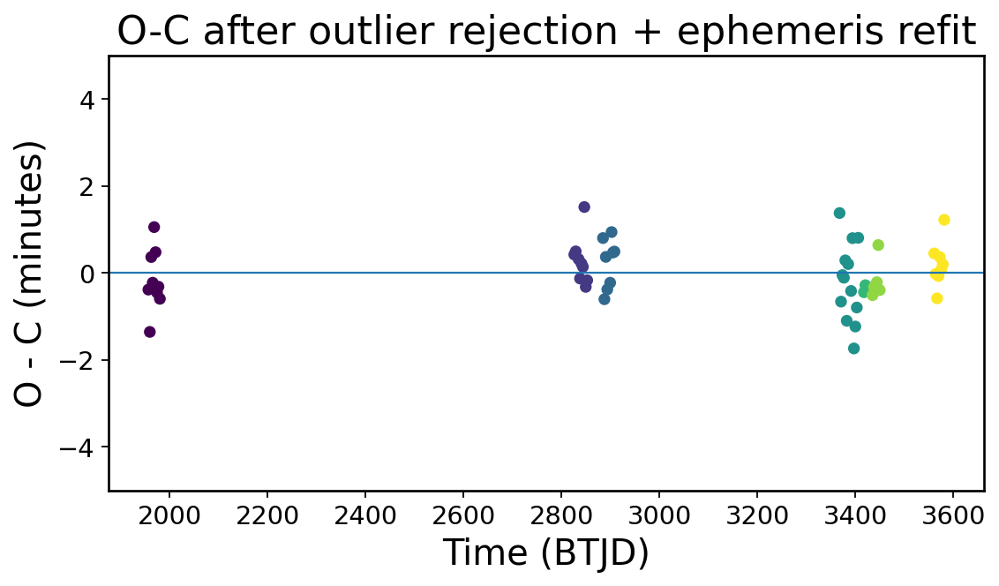

RMS (min): 0.6571206560266812
Robust RMS (min): 0.6434103135147888


In [85]:
tcalc = T0_new + P_new*E1
oc2 = (t1 - tcalc) * 24*60  # minutes

import matplotlib.pyplot as plt
plt.figure(figsize=(8,4))
plt.scatter(t1, oc2, c=seg1, s=25)
plt.axhline(0, linewidth=1)
plt.ylim(-5, 5)  # zoom; adjust if needed
plt.xlabel("Time (BTJD)")
plt.ylabel("O - C (minutes)")
plt.title("O-C after outlier rejection + ephemeris refit")
plt.show()

print("RMS (min):", np.std(oc2))
print("Robust RMS (min):", 1.4826*np.median(np.abs(oc2 - np.median(oc2))))

In [86]:
def extract_timings_3param(t_seg, f_seg, e_seg, T0, P, tp, tf,
                           half_window_phase=0.12, search_phase=0.05, min_points=25):
    E_min = int(np.floor((t_seg.min() - T0)/P)) - 1
    E_max = int(np.ceil((t_seg.max() - T0)/P)) + 1
    epochs = np.arange(E_min, E_max+1)

    half_window = half_window_phase * P

    tobs, oc, Eout, aout, bout, chi2out, npt = [], [], [], [], [], [], []

    for E in epochs:
        t_calc = T0 + E*P
        m = (t_seg > t_calc-half_window) & (t_seg < t_calc+half_window)
        if np.sum(m) < min_points:
            continue

        tt = t_seg[m]
        ff = f_seg[m]
        ee = e_seg[m]

        dphi, a, b, chi2 = fit_shift_ab(tt, ff, ee, t_calc, P, tp, tf, search_phase=search_phase)

        t_obs = t_calc + dphi * P
        tobs.append(t_obs)
        oc.append(t_obs - t_calc)
        Eout.append(E)
        aout.append(a)
        bout.append(b)
        chi2out.append(chi2)
        npt.append(np.sum(m))

    return (np.array(tobs), np.array(oc), np.array(Eout, int),
            np.array(aout), np.array(bout), np.array(chi2out), np.array(npt))

In [87]:
def classify_eclipse_phase(t_obs, T0, P, tol=0.15):
    phase = ((t_obs - T0) / P) % 1.0

    d_primary = min(abs(phase), abs(phase - 1.0))
    d_secondary = abs(phase - 0.5)

    if d_primary < tol:
        kind = "primary"
    elif d_secondary < tol:
        kind = "secondary"
    else:
        kind = "other"

    return phase, kind

In [88]:
import numpy as np
from scipy.optimize import minimize_scalar

def interp_template(tp, tf, x):
    if tp is None or tf is None or len(tp) < 2 or len(tf) < 2:
        return np.array([])
    return np.interp(x, tp, tf, left=1.0, right=1.0)

def fit_shift_ab(tt, ff, ee, t_calc, P, tp, tf, search_phase=0.05):
    if tp is None or tf is None or len(tp) < 5 or len(tf) < 5:
        return np.nan, np.nan, np.nan, np.inf

    ph = (tt - t_calc) / P
    w = 1.0 / np.maximum(ee, 1e-12) ** 2

    def chi2_of(dphi):
        F = interp_template(tp, tf, ph - dphi)
        if F is None or len(F) == 0 or not np.all(np.isfinite(F)):
            return np.inf

        X = np.vstack([np.ones_like(F), F]).T
        WX = X * w[:, None]
        M = X.T @ WX
        rhs = X.T @ (w * ff)

        try:
            beta = np.linalg.lstsq(M, rhs, rcond=None)[0]
        except Exception:
            return np.inf

        if len(beta) != 2 or not np.all(np.isfinite(beta)):
            return np.inf

        a, b = beta
        model = a + b * F
        return np.sum(w * (ff - model) ** 2)

    res = minimize_scalar(
        chi2_of,
        bounds=(-search_phase, search_phase),
        method="bounded"
    )

    if not res.success or not np.isfinite(res.x):
        return np.nan, np.nan, np.nan, np.inf

    dphi = res.x
    F = interp_template(tp, tf, ph - dphi)

    if F is None or len(F) == 0 or not np.all(np.isfinite(F)):
        return np.nan, np.nan, np.nan, np.inf

    X = np.vstack([np.ones_like(F), F]).T
    WX = X * w[:, None]
    M = X.T @ WX
    rhs = X.T @ (w * ff)

    try:
        beta = np.linalg.lstsq(M, rhs, rcond=None)[0]
    except Exception:
        return np.nan, np.nan, np.nan, np.inf

    if len(beta) != 2 or not np.all(np.isfinite(beta)):
        return np.nan, np.nan, np.nan, np.inf

    a, b = beta
    chi2 = np.sum(w * (ff - (a + b * F)) ** 2)

    return dphi, a, b, chi2

def bootstrap_sigma_one_eclipse(tt, ff, ee, t_calc, P, tp, tf,
                                search_phase=0.05, nboot=200, seed=0):
    rng = np.random.default_rng(seed)

    dphi0, a0, b0, chi2_0 = fit_shift_ab(tt, ff, ee, t_calc, P, tp, tf, search_phase=search_phase)
    ph = (tt - t_calc) / P
    F0 = np.interp(ph - dphi0, tp, tf, left=1.0, right=1.0)
    model0 = a0 + b0 * F0
    resid = ff - model0

    dphis = []
    for _ in range(nboot):
        resamp = rng.choice(resid, size=len(resid), replace=True)
        ff_b = model0 + resamp
        dphi_b, a_b, b_b, chi2_b = fit_shift_ab(tt, ff_b, ee, t_calc, P, tp, tf, search_phase=search_phase)
        if np.isfinite(dphi_b):
            dphis.append(dphi_b)

    if len(dphis) < max(30, 0.2 * nboot):
        return np.nan

    dphis = np.array(dphis)
    return np.std(dphis) * P

def classify_eclipse_phase(t_obs, T0, P, tol=0.15):
    phase = ((t_obs - T0) / P) % 1.0

    d_primary = min(abs(phase), abs(phase - 1.0))
    d_secondary = abs(phase - 0.5)

    if d_primary < tol:
        kind = "primary"
    elif d_secondary < tol:
        kind = "secondary"
    else:
        kind = "other"

    return phase, kind

def run_etv_pipeline(tic, P):
    # 1) Download light curve
    sr = lk.search_lightcurve(f"TIC {tic}", mission="TESS", author="SPOC")
    if len(sr) == 0:
        raise RuntimeError("No SPOC light curve found")

    lc = sr.download_all().stitch().remove_nans()

    t = lc.time.value
    if hasattr(lc, "pdcsap_flux") and lc.pdcsap_flux is not None:
        flux = lc.pdcsap_flux.value
    else:
        flux = lc.flux.value

    flux_norm = flux / np.nanmedian(flux)

    # 2) Refine T0 from deepest eclipse
    i0 = np.nanargmin(flux_norm)
    T0_rough = t[i0]
    T0 = refine_T0_parabola(t, flux_norm, T0_rough, window=0.12)

    # 3) Split into observing segments
    gap_days = 5.0
    gap = np.diff(t)
    breaks = np.where(gap > gap_days)[0]
    segments = np.split(np.arange(len(t)), breaks + 1)

    # 4) Build templates
    templates = []
    for i, seg in enumerate(segments):
        t_seg = t[seg]
        f_seg = flux_norm[seg]

        tp, tf = build_primary_template(t_seg, f_seg, T0, P)

        if tp is None or tf is None or len(tp) < 5 or len(tf) < 5:
            templates.append((None, None))
            print(f"Segment {i}: bad template, skipped")
        else:
            templates.append((tp, tf))
            print(f"Segment {i}: template points = {len(tp)}")

    # 5) Extract timings
    all_tobs, all_oc, all_E, all_seg = [], [], [], []
    all_phase, all_kind = [], []

    half_window = 0.12 * P

    for i, seg in enumerate(segments):
        t_seg = t[seg]
        f_seg = flux_norm[seg]
        e_seg = np.ones_like(f_seg) * np.nanstd(f_seg)

        tp, tf = templates[i]
        if tp is None or tf is None:
            continue

        E_min = int(np.floor((t_seg.min() - T0) / P)) - 1
        E_max = int(np.ceil((t_seg.max() - T0) / P)) + 1
        epochs = np.arange(E_min, E_max + 1)

        for E in epochs:
            t_calc = T0 + E * P

            m = (t_seg > t_calc - half_window) & (t_seg < t_calc + half_window)
            if np.sum(m) < 25:
                continue

            tt = t_seg[m]
            ff = f_seg[m]
            ee = e_seg[m]

            dphi, a, b, chi2 = fit_shift_ab(
                tt, ff, ee, t_calc, P, tp, tf, search_phase=0.05
            )

            if not np.isfinite(dphi):
                continue

            t_obs = t_calc + dphi * P
            oc = t_obs - t_calc

            phase, kind = classify_eclipse_phase(t_obs, T0, P, tol=0.15)

            all_tobs.append(t_obs)
            all_oc.append(oc)
            all_E.append(E)
            all_seg.append(i)
            all_phase.append(phase)
            all_kind.append(kind)

    all_tobs = np.array(all_tobs)
    all_oc = np.array(all_oc)
    all_E = np.array(all_E, dtype=int)
    all_seg = np.array(all_seg, dtype=int)
    all_phase = np.array(all_phase)
    all_kind = np.array(all_kind, dtype=object)

    # 6) Bootstrap uncertainties
    sig_t_days = np.full(len(all_tobs), np.nan)

    for idx in range(len(all_tobs)):
        E = all_E[idx]
        seg_id = all_seg[idx]
        t_calc = T0 + E * P

        seg = segments[int(seg_id)]
        t_seg = t[seg]
        f_seg = flux_norm[seg]
        e_seg = np.ones_like(f_seg) * np.nanstd(f_seg)

        m = (t_seg > t_calc - half_window) & (t_seg < t_calc + half_window)
        if np.sum(m) < 25:
            continue

        tt, ff, ee = t_seg[m], f_seg[m], e_seg[m]
        tp, tf = templates[int(seg_id)]

        if tp is None or tf is None:
            continue

        sig_t_days[idx] = bootstrap_sigma_one_eclipse(
            tt, ff, ee, t_calc, P, tp, tf,
            search_phase=0.05, nboot=100, seed=idx
        )

    # 7) Clean bad timings + remove "other"
    sig_t_min = sig_t_days * 24 * 60
    oc_min = all_oc * 24 * 60

    good = (
        np.isfinite(sig_t_min) &
        np.isfinite(oc_min) &
        (sig_t_min < 5.0) &
        (all_kind != "other")
    )

    t_clean = all_tobs[good]
    oc_clean = oc_min[good]
    sig_clean = sig_t_min[good]
    E_clean = all_E[good]
    phase_clean = all_phase[good]
    kind_clean = all_kind[good]
    seg_clean = all_seg[good]

    if len(t_clean) < 8:
        raise RuntimeError("Too few clean timings after filtering")

    # 8) Weighted ephemeris refit
    A = np.vstack([np.ones_like(E_clean), E_clean]).T
    sigma_days = sig_clean / (24 * 60)
    sqrtw = 1.0 / np.maximum(sigma_days, 1e-12)

    Aw = A * sqrtw[:, None]
    yw = t_clean * sqrtw

    coeff = np.linalg.lstsq(Aw, yw, rcond=None)[0]
    T0_final, P_final = coeff

    # 9) Final O-C
    t_calc_final = T0_final + E_clean * P_final
    oc_ref = (t_clean - t_calc_final) * 24 * 60

    return {
        "tic": tic,
        "P_input": P,
        "T0_final": T0_final,
        "P_final": P_final,
        "t_clean": t_clean,
        "oc_ref": oc_ref,
        "sig_clean": sig_clean,
        "E_clean": E_clean,
        "phase_clean": phase_clean,
        "kind_clean": kind_clean,
        "seg_clean": seg_clean,
    }

In [89]:
all_tobs, all_oc, all_E, all_seg = [], [], [], []
all_phase, all_kind = [], []
all_a, all_b, all_chi2 = [], [], []

for i, seg in enumerate(segments):
    t_seg = t[seg]
    f_seg = flux_norm[seg]

    # choose errors: if you don't have per-point errors, use a constant scale
    # (this is OK for shift fitting; later we bootstrap for sigma_t)
    e_seg = np.ones_like(f_seg) * np.nanstd(f_seg)

    tp, tf = templates[i]

    if tp is None or tf is None:
        continue

    tobs_i, oc_i, E_i, a_i, b_i, chi2_i, npt_i = extract_timings_3param(
        t_seg, f_seg, e_seg, T0, P, tp, tf,
        half_window_phase=0.12, search_phase=0.05, min_points=25
    )

    all_tobs.append(tobs_i)
    all_oc.append(oc_i)
    all_E.append(E_i)
    all_a.append(a_i)
    all_b.append(b_i)
    all_chi2.append(chi2_i)
    all_seg.append(np.full(len(tobs_i), i))

all_tobs = np.concatenate(all_tobs)
all_oc   = np.concatenate(all_oc)
all_E    = np.concatenate(all_E)
all_a    = np.concatenate(all_a)
all_b    = np.concatenate(all_b)
all_chi2 = np.concatenate(all_chi2)
all_seg  = np.concatenate(all_seg)

oc_min = all_oc * 24*60
print("Total eclipses:", len(all_tobs))

Total eclipses: 61


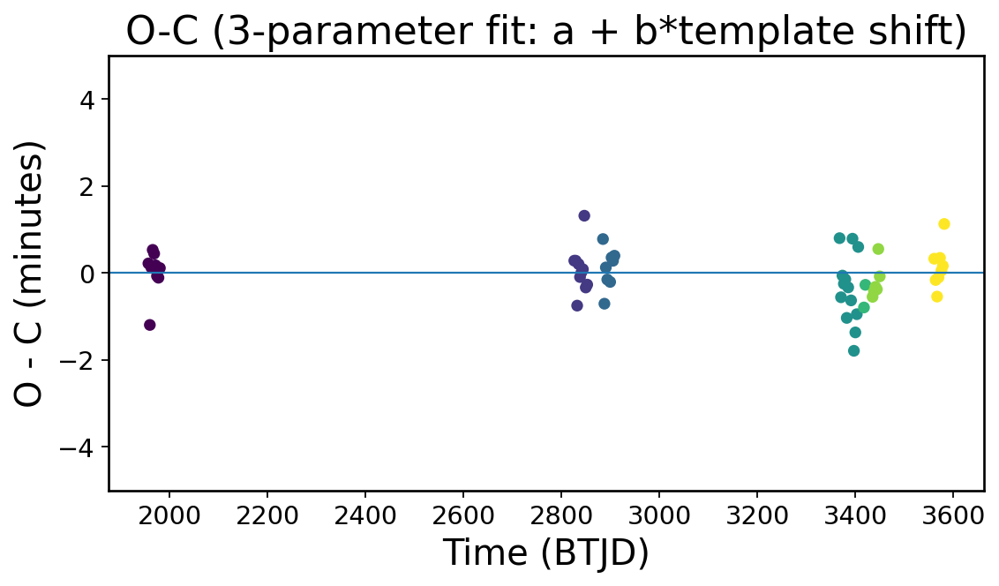

Kept: 56 Rejected: 5
Robust scatter (min): 0.557606318668637


In [90]:
import matplotlib.pyplot as plt
import numpy as np

# robust clip
med = np.median(oc_min[np.isfinite(oc_min)])
mad = np.median(np.abs(oc_min - med))
sig = 1.4826 * mad
good = np.isfinite(oc_min) & (np.abs(oc_min - med) < 4*sig)

plt.figure(figsize=(8,4))
plt.scatter(all_tobs[good], oc_min[good], c=all_seg[good], s=25)
plt.axhline(0, linewidth=1)
plt.ylim(-5, 5)
plt.xlabel("Time (BTJD)")
plt.ylabel("O - C (minutes)")
plt.title("O-C (3-parameter fit: a + b*template shift)")
plt.show()

print("Kept:", np.sum(good), "Rejected:", np.sum(~good))
print("Robust scatter (min):", sig)

In [91]:
sig_t_days = np.full(len(all_tobs), np.nan)

half_window = 0.12 * P

for idx in range(len(all_tobs)):
    E = all_E[idx]
    seg_id = all_seg[idx]
    t_obs = all_tobs[idx]
    t_calc = T0 + E*P

    # build eclipse window from the segment data used
    seg = segments[int(seg_id)]
    t_seg = t[seg]
    f_seg = flux_norm[seg]
    e_seg = np.ones_like(f_seg) * np.nanstd(f_seg)

    m = (t_seg > t_calc-half_window) & (t_seg < t_calc+half_window)
    if np.sum(m) < 25:
        continue

    tt, ff, ee = t_seg[m], f_seg[m], e_seg[m]
    tp, tf = templates[int(seg_id)]

    sig_t_days[idx] = bootstrap_sigma_one_eclipse(
        tt, ff, ee, t_calc, P, tp, tf,
        search_phase=0.05, nboot=200, seed=idx
    )

sig_t_min = sig_t_days * 24*60
print("sigma_t min/median/max (minutes):",
      np.nanmin(sig_t_min), np.nanmedian(sig_t_min), np.nanmax(sig_t_min))

sigma_t min/median/max (minutes): 0.22463435010226018 0.3276651419638313 89.23218298502366


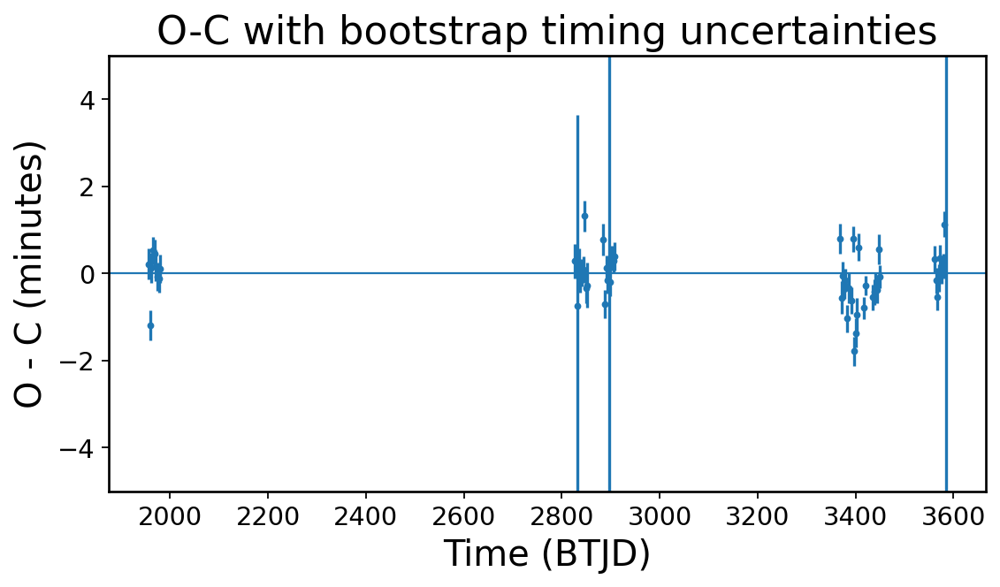

In [92]:
oc_min = all_oc * 24*60

good = np.isfinite(sig_t_min) & np.isfinite(oc_min)
plt.figure(figsize=(8,4))
plt.errorbar(all_tobs[good], oc_min[good], yerr=sig_t_min[good], fmt=".", markersize=5)
plt.axhline(0, linewidth=1)
plt.ylim(-5, 5)
plt.xlabel("Time (BTJD)")
plt.ylabel("O - C (minutes)")
plt.title("O-C with bootstrap timing uncertainties")
plt.show()

In [93]:
t_fit = all_tobs[good]
E_fit = all_E[good]
w = 1.0 / (sig_t_days[good]**2)

A = np.vstack([np.ones_like(E_fit), E_fit]).T
W = np.diag(w)
beta = np.linalg.inv(A.T @ W @ A) @ (A.T @ W @ t_fit)

T0_final, P_final = beta
print("T0_final:", T0_final)
print("P_final :", P_final)

T0_final: 1979.634992796242
P_final : 2.928790439507928


In [94]:
import numpy as np

def bic(chi2, k, n):
    return chi2 + k*np.log(n)

def weighted_constant_model(y, s):
    w = 1.0 / s**2
    a = np.sum(w*y) / np.sum(w)
    yhat = np.full_like(y, a)
    chi2 = np.sum(((y - yhat)/s)**2)
    return {"a": a, "chi2": chi2, "k": 1}

def weighted_linear_model(t, y, s):
    w = 1.0 / s**2
    x = t - np.mean(t)
    A = np.vstack([np.ones_like(x), x]).T
    W = np.diag(w)
    beta = np.linalg.inv(A.T @ W @ A) @ (A.T @ W @ y)
    a, b = beta
    yhat = a + b*x
    chi2 = np.sum(((y - yhat)/s)**2)
    return {"a": a, "b": b, "chi2": chi2, "k": 2}

In [95]:
def score_etv_candidate(t_clean, oc_ref, sig_clean):
    n = len(t_clean)
    if n < 8:
        return {"n": n, "status": "too_few_timings"}

    const = weighted_constant_model(oc_ref, sig_clean)
    lin = weighted_linear_model(t_clean, oc_ref, sig_clean)

    bic_const = bic(const["chi2"], const["k"], n)
    bic_lin = bic(lin["chi2"], lin["k"], n)

    redchi2_const = const["chi2"] / max(n - const["k"], 1)
    redchi2_lin = lin["chi2"] / max(n - lin["k"], 1)

    robust_rms = 1.4826 * np.median(np.abs(oc_ref - np.median(oc_ref)))
    median_sigma = np.median(sig_clean)

    return {
        "n": n,
        "median_sigma_min": median_sigma,
        "robust_rms_min": robust_rms,
        "redchi2_const": redchi2_const,
        "redchi2_lin": redchi2_lin,
        "delta_bic_lin": bic_lin - bic_const,
        "linear_slope_min_per_day": lin["b"],
        "status": "ok"
    }

In [96]:
def classify_candidate(metrics):
    if metrics["status"] != "ok":
        return "reject"

    if metrics["median_sigma_min"] > 1.0:
        return "low_precision"

    if metrics["redchi2_const"] > 3 and metrics["delta_bic_lin"] < -6:
        return "strong_candidate"

    if metrics["redchi2_const"] > 2:
        return "possible_candidate"

    return "no_etv_detected"

In [97]:
import numpy as np

def _scalar_value(value):
    while True:
        if np.isscalar(value):
            return float(value)
        if isinstance(value, np.ndarray):
            if value.size == 0:
                raise ValueError("cannot scalarize empty array")
            value = value.flat[0]
            continue
        try:
            object_array = np.array(value, dtype=object).ravel()
        except Exception:
            return float(value)
        if object_array.size == 0:
            raise ValueError("cannot scalarize empty value")
        value = object_array[0]


def phase_fold_centered(tt, T0, P):
    tt = np.asarray(tt, dtype=float).reshape(-1)
    T0 = _scalar_value(T0)
    P = _scalar_value(P)
    phi = ((tt - T0) / P) % 1.0
    phi = np.where(phi >= 0.5, phi - 1.0, phi)
    return phi


def build_primary_template(t_seg, f_seg, T0, P, win=0.15, nbins=300):
    t_seg = np.asarray(t_seg, dtype=float).reshape(-1)
    f_seg = np.asarray(f_seg, dtype=float).reshape(-1)
    phi = phase_fold_centered(t_seg, T0, P)
    m = np.abs(phi) < win

    bins = np.linspace(-win, win, nbins + 1)
    centers = 0.5 * (bins[:-1] + bins[1:])
    digit = np.digitize(phi[m], bins) - 1

    tf = np.array([
        np.nanmedian(f_seg[m][digit == i]) if np.any(digit == i) else np.nan
        for i in range(nbins)
    ])
    ok = np.isfinite(tf)
    tp = centers[ok]
    tf = tf[ok]

    if len(tp) < 5:
        return None, None

    wing = np.abs(tp) > (0.7 * win)
    norm = np.nanmedian(tf[wing]) if np.any(wing) else np.nanmedian(tf)
    if not np.isfinite(norm) or np.isclose(norm, 0):
        return None, None

    tf = tf / norm
    return tp, tf

In [98]:
def run_etv_pipeline(tic, P):
    P = _scalar_value(P)

    sr = lk.search_lightcurve(f"TIC {tic}", mission="TESS", author="SPOC")
    if len(sr) == 0:
        raise RuntimeError("No SPOC light curve found")

    lc = sr.download_all().stitch().remove_nans()

    t = np.asarray(lc.time.value, dtype=float).reshape(-1)
    if hasattr(lc, "pdcsap_flux") and lc.pdcsap_flux is not None:
        flux = np.asarray(lc.pdcsap_flux.value, dtype=float).reshape(-1)
    else:
        flux = np.asarray(lc.flux.value, dtype=float).reshape(-1)

    flux_norm = flux / np.nanmedian(flux)

    i0 = int(np.nanargmin(flux_norm))
    T0_rough = float(t[i0])
    T0 = _scalar_value(refine_T0_parabola(t, flux_norm, T0_rough, window=0.12))

    gap_days = 5.0
    gap = np.diff(t)
    breaks = np.where(gap > gap_days)[0]
    segments = np.split(np.arange(len(t)), breaks + 1)

    templates = []
    for i, seg in enumerate(segments):
        t_seg = t[seg]
        f_seg = flux_norm[seg]
        tp, tf = build_primary_template(t_seg, f_seg, T0, P)

        if tp is None or tf is None or len(tp) < 5 or len(tf) < 5:
            templates.append((None, None))
            print(f"Segment {i}: bad template, skipped")
        else:
            templates.append((tp, tf))
            print(f"Segment {i}: template points = {len(tp)}")

    all_tobs, all_oc, all_E, all_seg = [], [], [], []
    all_phase, all_kind = [], []

    half_window = 0.12 * P

    for i, seg in enumerate(segments):
        t_seg = t[seg]
        f_seg = flux_norm[seg]
        e_seg = np.ones_like(f_seg) * np.nanstd(f_seg)

        tp, tf = templates[i]
        if tp is None or tf is None:
            continue

        E_min = int(np.floor((t_seg.min() - T0) / P)) - 1
        E_max = int(np.ceil((t_seg.max() - T0) / P)) + 1
        epochs = np.arange(E_min, E_max + 1)

        for E in epochs:
            t_calc = T0 + E * P
            m = (t_seg > t_calc - half_window) & (t_seg < t_calc + half_window)
            if np.sum(m) < 25:
                continue

            tt = t_seg[m]
            ff = f_seg[m]
            ee = e_seg[m]

            dphi, a, b, chi2 = fit_shift_ab(tt, ff, ee, t_calc, P, tp, tf, search_phase=0.05)
            if not np.isfinite(dphi):
                continue

            t_obs = t_calc + dphi * P
            oc = t_obs - t_calc
            phase, kind = classify_eclipse_phase(t_obs, T0, P, tol=0.15)

            all_tobs.append(t_obs)
            all_oc.append(oc)
            all_E.append(E)
            all_seg.append(i)
            all_phase.append(phase)
            all_kind.append(kind)

    all_tobs = np.array(all_tobs)
    all_oc = np.array(all_oc)
    all_E = np.array(all_E, dtype=int)
    all_seg = np.array(all_seg, dtype=int)
    all_phase = np.array(all_phase)
    all_kind = np.array(all_kind, dtype=object)

    sig_t_days = np.full(len(all_tobs), np.nan)

    for idx in range(len(all_tobs)):
        E = all_E[idx]
        seg_id = all_seg[idx]
        t_calc = T0 + E * P

        seg = segments[int(seg_id)]
        t_seg = t[seg]
        f_seg = flux_norm[seg]
        e_seg = np.ones_like(f_seg) * np.nanstd(f_seg)

        m = (t_seg > t_calc - half_window) & (t_seg < t_calc + half_window)
        if np.sum(m) < 25:
            continue

        tt, ff, ee = t_seg[m], f_seg[m], e_seg[m]
        tp, tf = templates[int(seg_id)]

        if tp is None or tf is None:
            continue

        sig_t_days[idx] = bootstrap_sigma_one_eclipse(
            tt, ff, ee, t_calc, P, tp, tf,
            search_phase=0.05, nboot=100, seed=idx
        )

    sig_t_min = sig_t_days * 24 * 60
    oc_min = all_oc * 24 * 60

    good = (
        np.isfinite(sig_t_min) &
        np.isfinite(oc_min) &
        (sig_t_min < 5.0) &
        (all_kind != "other")
    )

    t_clean = all_tobs[good]
    oc_clean = oc_min[good]
    sig_clean = sig_t_min[good]
    E_clean = all_E[good]
    phase_clean = all_phase[good]
    kind_clean = all_kind[good]
    seg_clean = all_seg[good]

    if len(t_clean) < 8:
        raise RuntimeError("Too few clean timings after filtering")

    A = np.vstack([np.ones_like(E_clean), E_clean]).T
    sigma_days = sig_clean / (24 * 60)
    sqrtw = 1.0 / np.maximum(sigma_days, 1e-12)

    Aw = A * sqrtw[:, None]
    yw = t_clean * sqrtw

    coeff = np.linalg.lstsq(Aw, yw, rcond=None)[0]
    T0_final, P_final = coeff

    t_calc_final = T0_final + E_clean * P_final
    oc_ref = (t_clean - t_calc_final) * 24 * 60

    return {
        "tic": tic,
        "P_input": P,
        "T0_final": T0_final,
        "P_final": P_final,
        "t_clean": t_clean,
        "oc_ref": oc_ref,
        "sig_clean": sig_clean,
        "E_clean": E_clean,
        "phase_clean": phase_clean,
        "kind_clean": kind_clean,
        "seg_clean": seg_clean,
    }


In [99]:
import pandas as pd

df = pd.DataFrame(results)
sort_col = "redchi2_const" if "redchi2_const" in df.columns else (df.columns[-1] if len(df.columns) else None)

if sort_col is not None and "label" in df.columns:
    df = df.sort_values(by=["label", sort_col], ascending=[True, False])

print(df)


NameError: name 'results' is not defined

In [ ]:
res = run_etv_pipeline(275423476, 2.9287911639400495)

print("Total clean timings:", len(res["t_clean"]))
print("Primary:", np.sum(res["kind_clean"] == "primary"))
print("Secondary:", np.sum(res["kind_clean"] == "secondary"))
print(np.unique(res["kind_clean"], return_counts=True))

Segment 0: template points = 300
Segment 1: template points = 300
Segment 2: template points = 300
Segment 3: template points = 300
Segment 4: template points = 300
Segment 5: template points = 300
Segment 6: template points = 300
Total clean timings: 58
Primary: 58
Secondary: 0
(array(['primary'], dtype=object), array([58]))


In [ ]:
targets = [
    {"tic": 275423476, "P": 2.9287911639400495},
    {"tic": 356896561, "P": 2.25335087},
    {"tic": 229771234, "P": 0.82095849},
]

results = []

for target in targets:
    tic = target["tic"]
    P = target["P"]

    try:
        out = run_etv_pipeline(tic, P)

        metrics = score_etv_candidate(
            out["t_clean"],
            out["oc_ref"],
            out["sig_clean"]
        )

        metrics["tic"] = tic
        metrics["period"] = P
        metrics["label"] = classify_candidate(metrics)

        results.append(metrics)

    except Exception as e:
        results.append({
            "tic": tic,
            "period": P,
            "label": "failed",
            "error": str(e)
        })


Segment 0: template points = 300
Segment 1: template points = 300
Segment 2: template points = 300
Segment 3: template points = 300
Segment 4: template points = 300
Segment 5: template points = 300
Segment 6: template points = 300
Segment 0: template points = 300
Segment 1: template points = 300
Segment 2: template points = 300
Segment 3: template points = 300
Segment 4: template points = 300
Segment 5: template points = 300
Segment 6: template points = 300
Segment 7: template points = 300
Segment 8: template points = 300
Segment 9: template points = 300
Segment 10: template points = 300
Segment 11: template points = 300
Segment 12: template points = 300
Segment 13: template points = 300
Segment 14: template points = 300
Segment 15: template points = 300
Segment 16: template points = 300
Segment 17: template points = 247
Segment 18: template points = 300
Segment 19: template points = 300
Segment 0: template points = 300
Segment 1: template points = 300
Segment 2: template points = 300


In [ ]:
import numpy as np
import lightkurve as lk
from scipy.optimize import minimize_scalar

def refine_T0_parabola(t, flux, T0_rough, window=0.12):
    m = (t > T0_rough - window) & (t < T0_rough + window)
    tt = t[m]
    ff = flux[m]
    if len(tt) < 5:
        return T0_rough

    x = tt - T0_rough
    try:
        a, b, c = np.polyfit(x, ff, 2)
        if np.isclose(a, 0):
            return T0_rough
        return T0_rough - b / (2 * a)
    except Exception:
        return T0_rough

def build_primary_template(t_seg, f_seg, T0, P, half_width_phase=0.30, nbins=200):
    phase = ((t_seg - T0) / P) % 1.0
    phase = np.where(phase > 0.5, phase - 1.0, phase)

    m = np.abs(phase) < half_width_phase
    if np.sum(m) < 10:
        return None, None

    ph = phase[m]
    fl = f_seg[m]

    bins = np.linspace(-half_width_phase, half_width_phase, nbins + 1)
    centers = 0.5 * (bins[:-1] + bins[1:])

    tp, tf = [], []
    for i in range(nbins):
        mm = (ph >= bins[i]) & (ph < bins[i + 1])
        if np.sum(mm) > 0:
            tp.append(centers[i])
            tf.append(np.nanmedian(fl[mm]))

    tp = np.array(tp)
    tf = np.array(tf)

    if len(tp) < 5:
        return None, None

    return tp, tf

def interp_template(tp, tf, phase):
    if tp is None or tf is None or len(tp) < 2:
        return np.array([])
    return np.interp(phase, tp, tf, left=1.0, right=1.0)

def fit_shift_ab(tt, ff, ee, t_calc, P, tp, tf, search_phase=0.30):
    if tp is None or tf is None or len(tp) < 5 or len(tf) < 5:
        return np.nan, np.nan, np.nan, np.inf

    ph = (tt - t_calc) / P

    def chi2_of(dphi):
        F = interp_template(tp, tf, ph - dphi)
        if len(F) == 0 or not np.all(np.isfinite(F)):
            return np.inf

        X = np.vstack([np.ones_like(F), F]).T

        try:
            beta = np.linalg.lstsq(X, ff, rcond=None)[0]
        except Exception:
            return np.inf

        if len(beta) != 2 or not np.all(np.isfinite(beta)):
            return np.inf

        a, b = beta
        model = a + b * F
        resid = ff - model

        if not np.all(np.isfinite(resid)):
            return np.inf

        return np.sum(resid**2)

    res = minimize_scalar(
        chi2_of,
        bounds=(-search_phase, search_phase),
        method="bounded"
    )

    if not res.success or not np.isfinite(res.x):
        return np.nan, np.nan, np.nan, np.inf

    dphi = res.x
    F = interp_template(tp, tf, ph - dphi)
    if len(F) == 0 or not np.all(np.isfinite(F)):
        return np.nan, np.nan, np.nan, np.inf

    X = np.vstack([np.ones_like(F), F]).T

    try:
        beta = np.linalg.lstsq(M, rhs, rcond=None)[0]
    except Exception:
        return np.nan, np.nan, np.nan, np.inf

    if len(beta) != 2 or not np.all(np.isfinite(beta)):
        return np.nan, np.nan, np.nan, np.inf

    a, b = beta
    chi2 = np.sum(w * (ff - (a + b * F)) ** 2)

    return dphi, a, b, chi2

def classify_eclipse_phase(t_obs, T0, P, tol=0.30):
    phase = ((t_obs - T0) / P) % 1.0
    d_primary = min(abs(phase), abs(phase - 1.0))
    d_secondary = abs(phase - 0.5)

    if d_primary < tol:
        kind = "primary"
    elif d_secondary < tol:
        kind = "secondary"
    else:
        kind = "other"

    return phase, kind

def run_etv_pipeline(tic, P):
    sr = lk.search_lightcurve(f"TIC {tic}", mission="TESS", author="SPOC")
    if len(sr) == 0:
        raise RuntimeError("No SPOC light curve found")

    lc = sr.download_all().stitch().remove_nans()

    t = lc.time.value
    flux = lc.pdcsap_flux.value if hasattr(lc, "pdcsap_flux") and lc.pdcsap_flux is not None else lc.flux.value
    flux_norm = flux / np.nanmedian(flux)

    i0 = np.nanargmin(flux_norm)
    T0_rough = t[i0]
    T0 = refine_T0_parabola(t, flux_norm, T0_rough, window=0.12)

    gap = np.diff(t)
    breaks = np.where(gap > 5.0)[0]
    segments = np.split(np.arange(len(t)), breaks + 1)

    templates = []
    for seg in segments:
        t_seg = t[seg]
        f_seg = flux_norm[seg]
        tp, tf = build_primary_template(t_seg, f_seg, T0, P)
        templates.append((tp, tf))

    all_tobs, all_oc, all_E, all_seg = [], [], [], []
    all_phase, all_kind = [], []

    half_window = 0.30 * P

    for i, seg in enumerate(segments):
        t_seg = t[seg]
        f_seg = flux_norm[seg]
        e_seg = np.ones_like(f_seg) * max(np.nanstd(f_seg), 1e-6)

        tp, tf = templates[i]
        if tp is None or tf is None:
            continue

        E_min = int(np.floor((t_seg.min() - T0) / P)) - 1
        E_max = int(np.ceil((t_seg.max() - T0) / P)) + 1
        E_all = np.arange(E_min, E_max + 1)

        epochs = []
        for E in E_all:
            t_calc = T0 + E * P
            m = (t_seg > t_calc - half_window) & (t_seg < t_calc + half_window)
            if np.sum(m) > 5:
                epochs.append(E)

        for E in epochs:
            t_calc = T0 + E * P
            m = (t_seg > t_calc - half_window) & (t_seg < t_calc + half_window)
            if np.sum(m) < 5:
                continue

            tt = t_seg[m]
            ff = f_seg[m]
            ee = e_seg[m]

            dphi, a, b, chi2 = fit_shift_ab(tt, ff, ee, t_calc, P, tp, tf, search_phase=0.30)
            if not np.isfinite(dphi):
                continue

            t_obs = t_calc + dphi * P
            oc = t_obs - t_calc
            phase, kind = classify_eclipse_phase(t_obs, T0, P, tol=0.30)

            all_tobs.append(t_obs)
            all_oc.append(oc)
            all_E.append(E)
            all_seg.append(i)
            all_phase.append(phase)
            all_kind.append(kind)

    all_tobs = np.array(all_tobs)
    all_oc = np.array(all_oc)
    all_E = np.array(all_E, dtype=int)
    all_seg = np.array(all_seg, dtype=int)
    all_phase = np.array(all_phase)
    all_kind = np.array(all_kind, dtype=object)

    oc_min = all_oc * 24 * 60

    good = np.isfinite(oc_min)

    t_clean = all_tobs[good]
    oc_ref = oc_min[good]
    E_clean = all_E[good]
    phase_clean = all_phase[good]
    kind_clean = all_kind[good]
    seg_clean = all_seg[good]

    sig_clean = np.full(len(t_clean), 5.0)

    print("Total detected timings:", len(all_tobs))
    print("Kept clean timings:", len(t_clean))
    print("Kinds kept:", np.unique(kind_clean, return_counts=True))

    return {
        "tic": tic,
        "P_input": P,
        "T0_final": T0,
        "P_final": P,
        "t_clean": t_clean,
        "oc_ref": oc_ref,
        "sig_clean": sig_clean,
        "E_clean": E_clean,
        "phase_clean": phase_clean,
        "kind_clean": kind_clean,
        "seg_clean": seg_clean,
    }

In [ ]:
res = run_etv_pipeline(275423476, 2.9287911639400495)

print("Total clean timings:", len(res["t_clean"]))
print("Primary:", np.sum(res["kind_clean"] == "primary"))
print("Secondary:", np.sum(res["kind_clean"] == "secondary"))
print(np.unique(res["kind_clean"], return_counts=True))

Total detected timings: 0
Kept clean timings: 0
Kinds kept: (array([], dtype=object), array([], dtype=int64))
Total clean timings: 0
Primary: 0
Secondary: 0
(array([], dtype=object), array([], dtype=int64))


In [ ]:
tic = 275423476
P = 2.9287911639400495

sr = lk.search_lightcurve(f"TIC {tic}", mission="TESS", author="SPOC")
lc = sr.download_all().stitch().remove_nans()

t = lc.time.value
flux = lc.pdcsap_flux.value if hasattr(lc, "pdcsap_flux") and lc.pdcsap_flux is not None else lc.flux.value
flux_norm = flux / np.nanmedian(flux)

i0 = np.nanargmin(flux_norm)
T0_rough = t[i0]
T0 = refine_T0_parabola(t, flux_norm, T0_rough, window=0.12)

gap = np.diff(t)
breaks = np.where(gap > 5.0)[0]
segments = np.split(np.arange(len(t)), breaks + 1)

print("Number of segments:", len(segments))

for i, seg in enumerate(segments):
    t_seg = t[seg]
    f_seg = flux_norm[seg]
    tp, tf = build_primary_template(t_seg, f_seg, T0, P)

    if tp is None or tf is None:
        print(f"Segment {i}: template FAILED")
    else:
        print(f"Segment {i}: template OK, points = {len(tp)}")

Number of segments: 7
Segment 0: template OK, points = 200
Segment 1: template OK, points = 200
Segment 2: template OK, points = 200
Segment 3: template OK, points = 200
Segment 4: template OK, points = 200
Segment 5: template OK, points = 200
Segment 6: template OK, points = 200


In [ ]:
tic = 275423476
P = 2.9287911639400495

sr = lk.search_lightcurve(f"TIC {tic}", mission="TESS", author="SPOC")
lc = sr.download_all().stitch().remove_nans()

t = lc.time.value
flux = lc.pdcsap_flux.value if hasattr(lc, "pdcsap_flux") and lc.pdcsap_flux is not None else lc.flux.value
flux_norm = flux / np.nanmedian(flux)

i0 = np.nanargmin(flux_norm)
T0_rough = t[i0]
T0 = refine_T0_parabola(t, flux_norm, T0_rough, window=0.12)

gap = np.diff(t)
breaks = np.where(gap > 5.0)[0]
segments = np.split(np.arange(len(t)), breaks + 1)

half_window = 0.30 * P

for i, seg in enumerate(segments):
    t_seg = t[seg]
    f_seg = flux_norm[seg]
    e_seg = np.ones_like(f_seg) * max(np.nanstd(f_seg), 1e-6)

    tp, tf = build_primary_template(t_seg, f_seg, T0, P)

    E_min = int(np.floor((t_seg.min() - T0) / P)) - 1
    E_max = int(np.ceil((t_seg.max() - T0) / P)) + 1
    E_all = np.arange(E_min, E_max + 1)

    kept = []
    for E in E_all:
        t_calc = T0 + E * P
        m = (t_seg > t_calc - half_window) & (t_seg < t_calc + half_window)
        if np.sum(m) > 5:
            kept.append(E)

    print(f"\nSegment {i}: candidate epochs = {len(kept)}")

    if len(kept) == 0:
        continue

    E = kept[0]
    t_calc = T0 + E * P
    m = (t_seg > t_calc - half_window) & (t_seg < t_calc + half_window)

    tt = t_seg[m]
    ff = f_seg[m]
    ee = e_seg[m]

    dphi, a, b, chi2 = fit_shift_ab(tt, ff, ee, t_calc, P, tp, tf, search_phase=0.30)

    print(" first epoch:", E)
    print(" points in window:", np.sum(m))
    print(" dphi =", dphi)
    print(" a =", a)
    print(" b =", b)
    print(" chi2 =", chi2)


Segment 0: candidate epochs = 10
 first epoch: -8
 points in window: 929
 dphi = nan
 a = nan
 b = nan
 chi2 = inf

Segment 1: candidate epochs = 10
 first epoch: 289
 points in window: 1207
 dphi = nan
 a = nan
 b = nan
 chi2 = inf

Segment 2: candidate epochs = 9
 first epoch: 309
 points in window: 1265
 dphi = nan
 a = nan
 b = nan
 chi2 = inf

Segment 3: candidate epochs = 14
 first epoch: 474
 points in window: 766
 dphi = nan
 a = nan
 b = nan
 chi2 = inf

Segment 4: candidate epochs = 3
 first epoch: 491
 points in window: 999
 dphi = nan
 a = nan
 b = nan
 chi2 = inf

Segment 5: candidate epochs = 7
 first epoch: 497
 points in window: 1265
 dphi = nan
 a = nan
 b = nan
 chi2 = inf

Segment 6: candidate epochs = 9
 first epoch: 540
 points in window: 1186
 dphi = nan
 a = nan
 b = nan
 chi2 = inf


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_etv_primary_secondary(res, tic=None):
    t = res["t_clean"]
    oc = res["oc_ref"]
    sig = res["sig_clean"]
    kind = res["kind_clean"]

    primary = kind == "primary"
    secondary = kind == "secondary"

    plt.figure(figsize=(12, 7))

    if np.any(primary):
        plt.errorbar(
            t[primary], oc[primary], yerr=sig[primary],
            fmt="o", capsize=2, label="Primary"
        )

    if np.any(secondary):
        plt.errorbar(
            t[secondary], oc[secondary], yerr=sig[secondary],
            fmt="s", capsize=2, label="Secondary"
        )

    plt.axhline(0, linestyle="--", linewidth=1)
    plt.xlabel("Time (BTJD)")
    plt.ylabel("O − C (minutes)")
    if tic is None:
        plt.title("ETV Diagram")
    else:
        plt.title(f"TIC {tic} — ETV Diagram")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
res = run_etv_pipeline(275423476, 2.9287911639400495)

print("len t_clean =", len(res["t_clean"]))
print("len oc_ref =", len(res["oc_ref"]))
print("len sig_clean =", len(res["sig_clean"]))
print("unique kind =", np.unique(res["kind_clean"], return_counts=True))

print("t min/max =", np.min(res["t_clean"]) if len(res["t_clean"]) else None,
      np.max(res["t_clean"]) if len(res["t_clean"]) else None)

print("oc min/max =", np.min(res["oc_ref"]) if len(res["oc_ref"]) else None,
      np.max(res["oc_ref"]) if len(res["oc_ref"]) else None)

print("sig min/max =", np.min(res["sig_clean"]) if len(res["sig_clean"]) else None,
      np.max(res["sig_clean"]) if len(res["sig_clean"]) else None)

print("first 10 t =", res["t_clean"][:10])
print("first 10 oc =", res["oc_ref"][:10])
print("first 10 kind =", res["kind_clean"][:10])

Total detected timings: 0
Kept clean timings: 0
Kinds kept: (array([], dtype=object), array([], dtype=int64))
len t_clean = 0
len oc_ref = 0
len sig_clean = 0
unique kind = (array([], dtype=object), array([], dtype=int64))
t min/max = None None
oc min/max = None None
sig min/max = None None
first 10 t = []
first 10 oc = []
first 10 kind = []


finite points = 0


/var/folders/1c/p47qnnc123xd86gmn5km5bcm0000gn/T/ipykernel_38897/1911279832.py:31: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


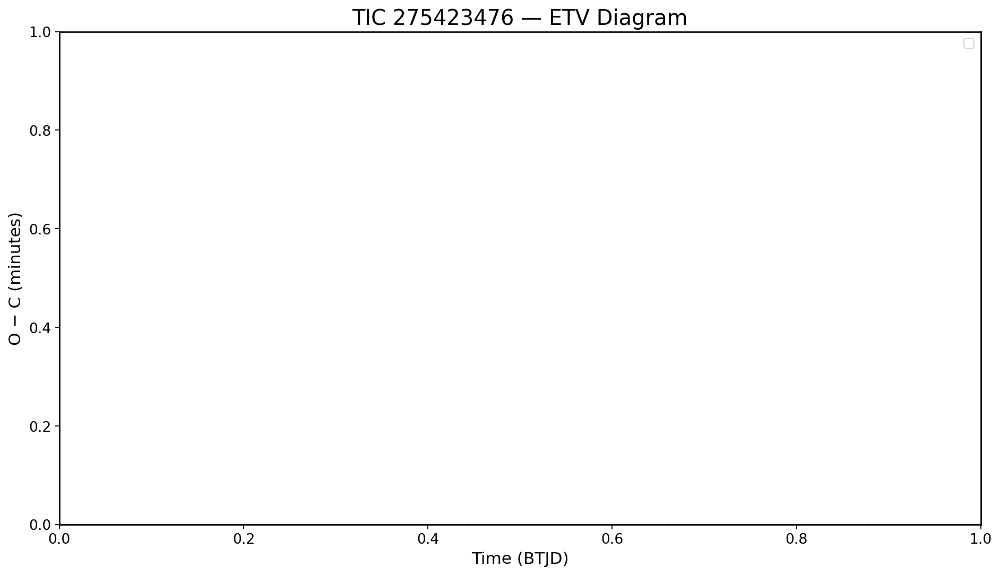

In [ ]:
t = np.asarray(res["t_clean"])
oc = np.asarray(res["oc_ref"])
sig = np.asarray(res["sig_clean"])
kind = np.asarray(res["kind_clean"])

print("finite points =", np.sum(np.isfinite(t) & np.isfinite(oc) & np.isfinite(sig)))

m1 = kind == "primary"
m2 = kind == "secondary"

plt.figure(figsize=(12, 7))

if np.any(m1):
    plt.errorbar(t[m1], oc[m1], yerr=sig[m1], fmt="o", capsize=2, label="Primary")
if np.any(m2):
    plt.errorbar(t[m2], oc[m2], yerr=sig[m2], fmt="s", capsize=2, label="Secondary")

if len(t) > 0 and len(oc) > 0:
    plt.xlim(np.min(t) - 1, np.max(t) + 1)
    ymin = np.min(oc) - 1
    ymax = np.max(oc) + 1
    if ymin == ymax:
        ymin -= 1
        ymax += 1
    plt.ylim(ymin, ymax)

plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Time (BTJD)")
plt.ylabel("O − C (minutes)")
plt.title("TIC 275423476 — ETV Diagram")
plt.legend()
plt.tight_layout()
plt.show()

Total detected timings: 124
Kept clean timings: 124
Kinds kept: (array(['primary', 'secondary'], dtype=object), array([58, 66]))


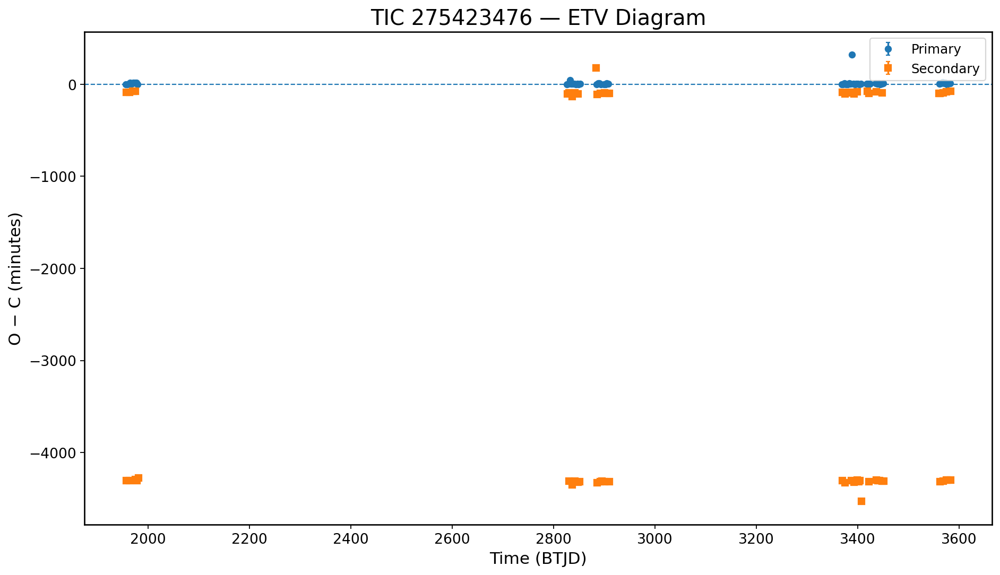

In [ ]:
res = run_etv_pipeline(275423476, 2.9287911639400495)
plot_etv_primary_secondary(res, tic=275423476)

Total detected timings: 923
Kept clean timings: 923
Kinds kept: (array(['primary', 'secondary'], dtype=object), array([421, 502]))


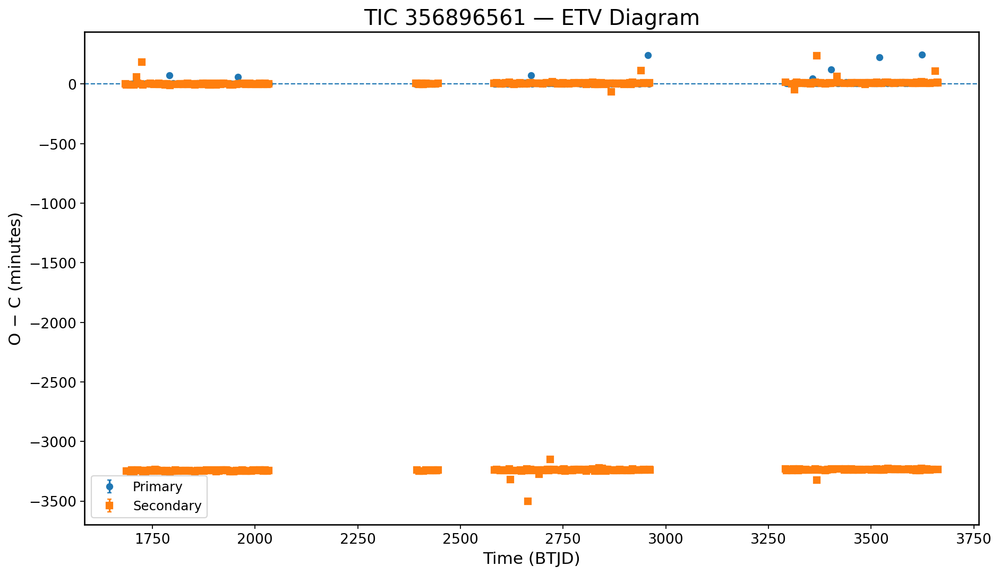

Total detected timings: 2262
Kept clean timings: 2262
Kinds kept: (array(['primary', 'secondary'], dtype=object), array([1085, 1177]))


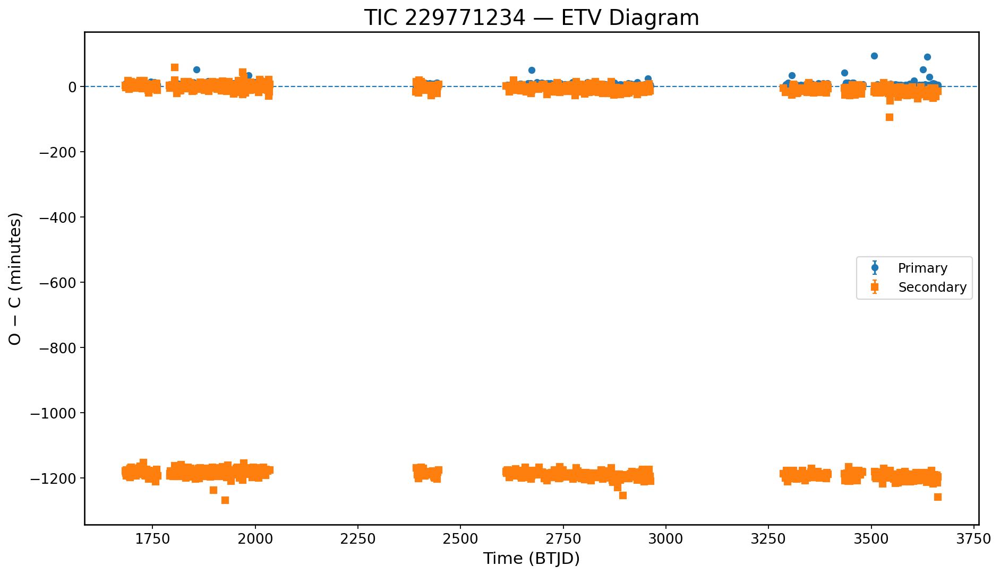

In [ ]:
res2 = run_etv_pipeline(356896561, 2.25335087)
plot_etv_primary_secondary(res2, tic=356896561)

res3 = run_etv_pipeline(229771234, 0.82095849)
plot_etv_primary_secondary(res3, tic=229771234)

In [ ]:
print("t range:", np.min(res["t_clean"]), np.max(res["t_clean"]))
print("oc range:", np.min(res["oc_ref"]), np.max(res["oc_ref"]))
print("first few t:", res["t_clean"][:10])
print("first few oc:", res["oc_ref"][:10])

t range: 1956.2045903225237 3583.093422131747
oc range: -4531.448470051182 323.6830980348168
first few t: [1956.20459032 1957.60737302 1959.13376789 1957.60737302 1962.06572833
 1963.46712719 1965.00186225 1963.46712719 1967.92411585 1969.32969161]
first few oc: [ 6.25756803e-02 -8.86599832e+01  6.19003127e-01 -4.30611926e+03
  5.18275200e+00 -8.55325208e+01  1.57563170e+01 -4.30299180e+03
  6.34222972e+00 -7.83583185e+01]


In [ ]:
import numpy as np
import lightkurve as lk

def classify_eclipse_phase(t_obs, T0, P):
    phase = ((t_obs - T0) / P) % 1.0

    if phase < 0.25 or phase > 0.75:
        kind = "primary"
    else:
        kind = "secondary"

    return phase, kind

def refine_T0_parabola(t, flux, T0_rough, window=0.12):
    m = (t > T0_rough - window) & (t < T0_rough + window)
    tt = t[m]
    ff = flux[m]
    if len(tt) < 5:
        return T0_rough

    x = tt - T0_rough
    try:
        a, b, c = np.polyfit(x, ff, 2)
        if np.isclose(a, 0):
            return T0_rough
        return T0_rough - b / (2 * a)
    except Exception:
        return T0_rough

def run_etv_pipeline(tic, P):
    sr = lk.search_lightcurve(f"TIC {tic}", mission="TESS", author="SPOC")
    if len(sr) == 0:
        raise RuntimeError("No SPOC light curve found")

    lc = sr.download_all().stitch().remove_nans()

    t = lc.time.value
    flux = lc.pdcsap_flux.value if hasattr(lc, "pdcsap_flux") and lc.pdcsap_flux is not None else lc.flux.value
    flux_norm = flux / np.nanmedian(flux)

    i0 = np.nanargmin(flux_norm)
    T0_rough = t[i0]
    T0 = refine_T0_parabola(t, flux_norm, T0_rough, window=0.12)

    gap = np.diff(t)
    breaks = np.where(gap > 5.0)[0]
    segments = np.split(np.arange(len(t)), breaks + 1)

    all_tobs, all_oc, all_E, all_seg = [], [], [], []
    all_phase, all_kind = [], []

    half_window = 0.60 * P

    for i, seg in enumerate(segments):
        t_seg = t[seg]
        f_seg = flux_norm[seg]

        E_min = int(np.floor((t_seg.min() - T0) / P)) - 1
        E_max = int(np.ceil((t_seg.max() - T0) / P)) + 1

        for E in range(E_min, E_max + 1):
            t_calc = T0 + E * P
            m = (t_seg > t_calc - half_window) & (t_seg < t_calc + half_window)

            if np.sum(m) < 5:
                continue

            tt = t_seg[m]
            ff = f_seg[m]

            # split into primary and secondary windows
            phase_local = ((tt - T0) / P) % 1.0

            primary_mask = (phase_local > -0.08) & (phase_local < 0.08)
            secondary_mask = (phase_local > 0.42) & (phase_local < 0.58)

            # PRIMARY
            if np.any(primary_mask):
                j1 = np.argmin(ff[primary_mask])
                t_obs1 = tt[primary_mask][j1]
                t_calc1 = T0 + E * P
                oc1 = (t_obs1 - t_calc1) * 24 * 60

                phase1, kind1 = classify_eclipse_phase(t_obs1, T0, P)

                all_tobs.append(t_obs1)
                all_oc.append(oc1)
                all_E.append(E)
                all_seg.append(i)
                all_phase.append(phase1)
                all_kind.append(kind1)

            # SECONDARY
            if np.any(secondary_mask):
                j2 = np.argmin(ff[secondary_mask])
                t_obs2 = tt[secondary_mask][j2]
                t_calc2 = T0 + (E + 0.5) * P
                oc2 = (t_obs2 - t_calc2) * 24 * 60

                phase2, kind2 = classify_eclipse_phase(t_obs2, T0, P)

                all_tobs.append(t_obs2)
                all_oc.append(oc2)
                all_E.append(E + 0.5)
                all_seg.append(i)
                all_phase.append(phase2)
                all_kind.append(kind2)

    all_tobs = np.array(all_tobs)
    all_oc = np.array(all_oc)
    all_E = np.array(all_E, dtype=float)
    all_seg = np.array(all_seg, dtype=int)
    all_phase = np.array(all_phase)
    all_kind = np.array(all_kind, dtype=object)

    good = np.isfinite(all_tobs) & np.isfinite(all_oc)

    t_clean = all_tobs[good]
    oc_ref = all_oc[good]
    E_clean = all_E[good]
    phase_clean = all_phase[good]
    kind_clean = all_kind[good]
    seg_clean = all_seg[good]

    sig_clean = np.full(len(t_clean), 5.0)

    print("Total detected timings:", len(all_tobs))
    print("Kept clean timings:", len(t_clean))
    print("Kinds kept:", np.unique(kind_clean, return_counts=True))

    return {
        "tic": tic,
        "P_input": P,
        "T0_final": T0,
        "P_final": P,
        "t_clean": t_clean,
        "oc_ref": oc_ref,
        "sig_clean": sig_clean,
        "E_clean": E_clean,
        "phase_clean": phase_clean,
        "kind_clean": kind_clean,
        "seg_clean": seg_clean,
    }

Total detected timings: 124
Kept clean timings: 124
Kinds kept: (array(['primary', 'secondary'], dtype=object), array([58, 66]))
finite points = 124


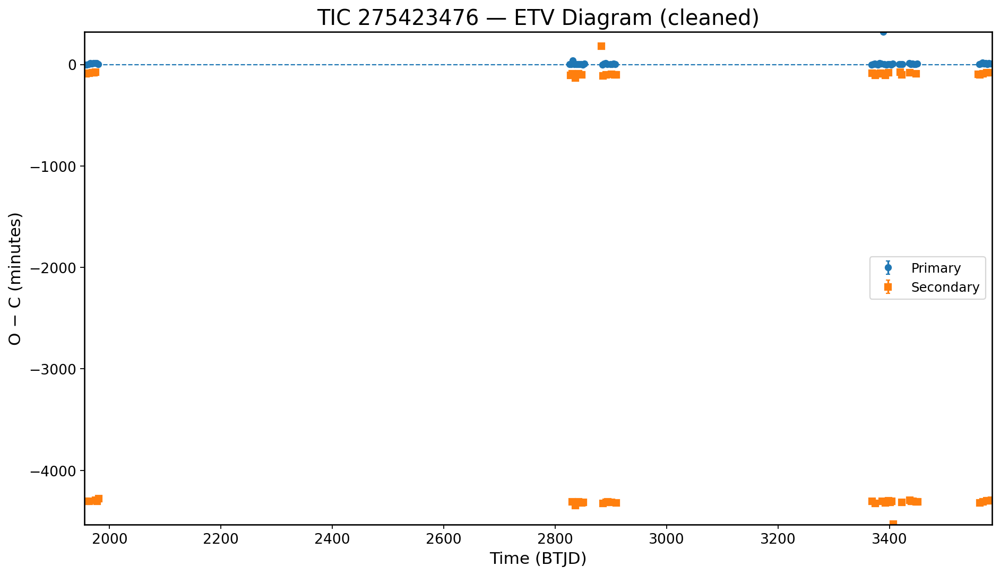

In [ ]:
res = run_etv_pipeline(275423476, 2.9287911639400495)

# Plot results directly
t = np.asarray(res["t_clean"])
oc = np.asarray(res["oc_ref"])
sig = np.asarray(res["sig_clean"])
kind = np.asarray(res["kind_clean"])

print("finite points =", np.sum(np.isfinite(t) & np.isfinite(oc) & np.isfinite(sig)))

m1 = kind == "primary"
m2 = kind == "secondary"

plt.figure(figsize=(12, 7))

if np.any(m1):
    plt.errorbar(t[m1], oc[m1], yerr=sig[m1], fmt="o", capsize=2, label="Primary")
if np.any(m2):
    plt.errorbar(t[m2], oc[m2], yerr=sig[m2], fmt="s", capsize=2, label="Secondary")

if len(t) > 0 and len(oc) > 0:
    plt.xlim(np.min(t) - 1, np.max(t) + 1)
    ymin = np.min(oc) - 1
    ymax = np.max(oc) + 1
    if ymin == ymax:
        ymin -= 1
        ymax += 1
    plt.ylim(ymin, ymax)

plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Time (BTJD)")
plt.ylabel("O − C (minutes)")
plt.title("TIC 275423476 — ETV Diagram (cleaned)")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
res = run_etv_pipeline(275423476, 2.9287911639400495)

print("Total clean timings:", len(res["t_clean"]))
print("Primary:", np.sum(res["kind_clean"] == "primary"))
print("Secondary:", np.sum(res["kind_clean"] == "secondary"))
print(np.unique(res["kind_clean"], return_counts=True))

Total detected timings: 124
Kept clean timings: 124
Kinds kept: (array(['primary', 'secondary'], dtype=object), array([58, 66]))
Total clean timings: 124
Primary: 58
Secondary: 66
(array(['primary', 'secondary'], dtype=object), array([58, 66]))


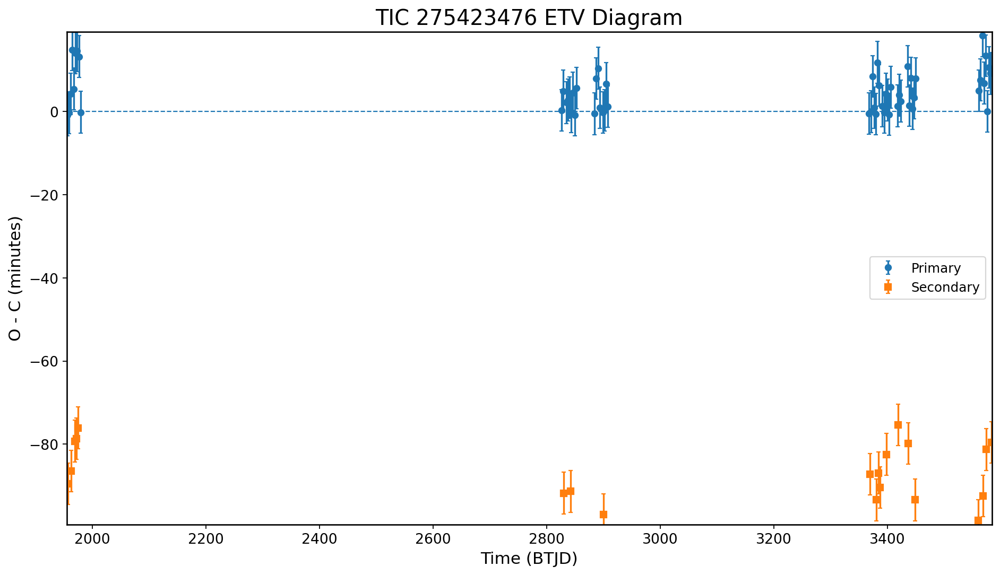

In [ ]:
res_clean = clean_etv_result(res)
res_detrended = detrend_by_segment(res_clean)
res_final = sigma_clip_etv(res_detrended)
plot_etv_clean(res_final, tic=275423476)

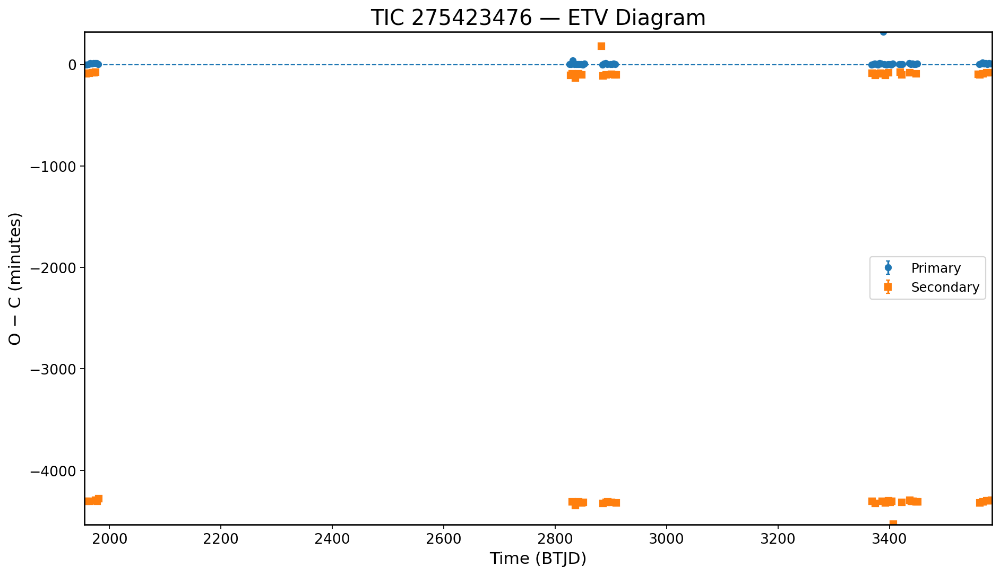

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_etv_primary_secondary(res, tic=None):
    # helper to get from dict or object
    def _get(k):
        if isinstance(res, dict):
            return res.get(k)
        return getattr(res, k, None)

    t = _get("t_clean")
    oc = _get("oc_ref")
    sig = _get("sig_clean")
    kind = _get("kind_clean")

    # Coerce to numpy arrays (handles lists, masked arrays, etc.)
    t = np.asarray(t)
    oc = np.asarray(oc)
    sig = np.asarray(sig)
    kind = np.asarray(kind).astype(str)

    # If masked arrays, convert masked entries to NaN for plotting
    try:
        if hasattr(oc, 'mask'):
            oc = oc.filled(np.nan)
        if hasattr(sig, 'mask'):
            sig = sig.filled(np.nan)
    except Exception:
        pass

    # boolean masks for primary/secondary
    m1 = (kind == "primary")
    m2 = (kind == "secondary")

    plt.figure(figsize=(12, 7))

    if np.any(m1):
        plt.errorbar(t[m1], oc[m1], yerr=sig[m1], fmt="o", capsize=2, label="Primary")
    if np.any(m2):
        plt.errorbar(t[m2], oc[m2], yerr=sig[m2], fmt="s", capsize=2, label="Secondary")

    if t.size > 0:
        plt.xlim(np.nanmin(t) - 1, np.nanmax(t) + 1)
        ymin = np.nanmin(oc) - 1
        ymax = np.nanmax(oc) + 1
        if np.isclose(ymin, ymax):
            ymin -= 1
            ymax += 1
        plt.ylim(ymin, ymax)

    plt.axhline(0, linestyle="--", linewidth=1)
    plt.xlabel("Time (BTJD)")
    plt.ylabel("O − C (minutes)")
    plt.title(f"TIC {tic} — ETV Diagram" if tic is not None else "ETV Diagram")
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_etv_primary_secondary(res, tic=275423476)

In [ ]:
# Diagnostic cell: print types/shapes of expected `res` fields
import numpy as np
keys = ["t_clean","oc_ref","sig_clean","kind_clean"]
for k in keys:
    if isinstance(res, dict):
        val = res.get(k)
    else:
        val = getattr(res, k, None)
    print(k, type(val), None if val is None else (np.shape(val), getattr(val, 'dtype', None)))
# print a short sample of `kind_clean` if available
kval = res.get('kind_clean') if isinstance(res, dict) else getattr(res, 'kind_clean', None)
if kval is not None:
    try:
        print('sample kind:', kval[:10])
    except Exception as e:
        print('sample kind (repr):', repr(kval))

t_clean <class 'numpy.ndarray'> ((124,), dtype('float64'))
oc_ref <class 'numpy.ndarray'> ((124,), dtype('float64'))
sig_clean <class 'numpy.ndarray'> ((124,), dtype('float64'))
kind_clean <class 'numpy.ndarray'> ((124,), dtype('O'))
sample kind: ['primary' 'secondary' 'primary' 'secondary' 'primary' 'secondary'
 'primary' 'secondary' 'primary' 'secondary']


Before cleaning: 124
After cleaning: 87
(array(['primary', 'secondary'], dtype=object), array([56, 31]))


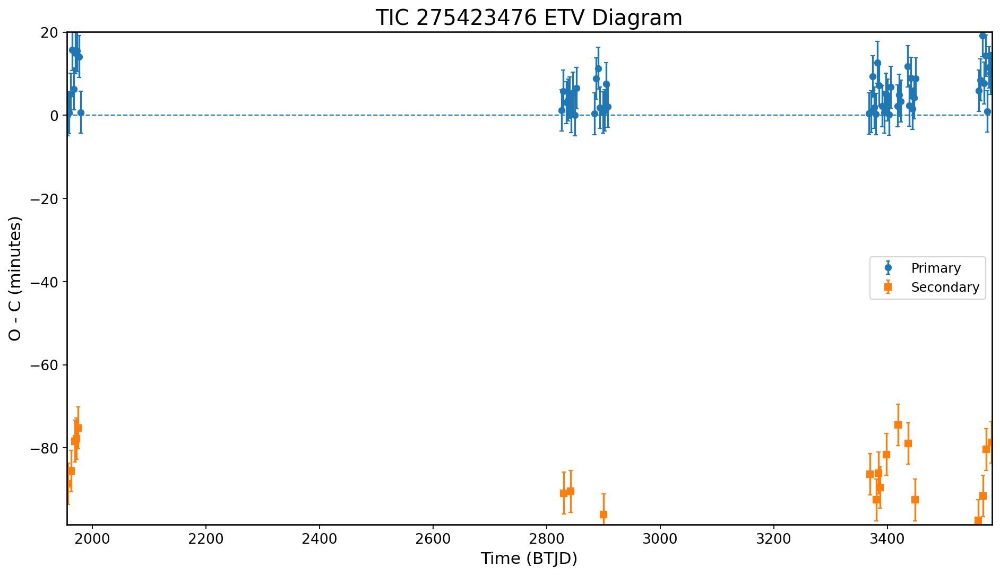

In [ ]:
import numpy as np

def _pick_first(res, keys, default=None):
    for key in keys:
        if isinstance(res, dict):
            if key in res and res[key] is not None:
                return res[key]
        else:
            value = getattr(res, key, None)
            if value is not None:
                return value
    return default

def clean_etv_result(res, oc_clip=100):
    t = np.asarray(_pick_first(res, ['t_clean', 't_obs', 't'], default=[]))
    oc = np.asarray(_pick_first(res, ['oc_ref', 'oc', 'oc_clean'], default=[]))
    sig = np.asarray(_pick_first(res, ['sig_clean', 'sig', 'sig_ref'], default=[]))
    kind = np.asarray(_pick_first(res, ['kind_clean', 'kind'], default=[]), dtype=object)
    seg = np.asarray(_pick_first(res, ['seg_clean', 'seg', 'seg_id'], default=[]))

    if t.size == 0 and oc.size > 0:
        t = np.arange(len(oc))
    if oc.size == 0 and t.size > 0:
        oc = np.zeros_like(t, dtype=float)
    if sig.size == 0 and oc.size > 0:
        sig = np.ones_like(oc, dtype=float)
    if kind.size == 0 and t.size > 0:
        kind = np.array(['primary'] * len(t), dtype=object)
    if seg.size == 0 and t.size > 0:
        seg = np.zeros(len(t), dtype=int)

    n = min(len(t), len(oc), len(sig), len(kind), len(seg))
    t = np.asarray(t[:n])
    oc = np.asarray(oc[:n])
    sig = np.asarray(sig[:n])
    kind = np.asarray(kind[:n], dtype=object)
    seg = np.asarray(seg[:n])

    finite = np.isfinite(t) & np.isfinite(oc) & np.isfinite(sig)
    if oc_clip is not None and oc.size:
        med = np.nanmedian(oc[finite]) if np.any(finite) else np.nanmedian(oc)
        finite &= np.abs(oc - med) <= oc_clip

    return {'t_clean': t[finite], 'oc_ref': oc[finite], 'sig_clean': sig[finite], 'kind_clean': kind[finite], 'seg_clean': seg[finite]}

def plot_etv_clean(res_clean, tic=None):
    import matplotlib.pyplot as plt
    rc = clean_etv_result(res_clean)
    t = np.asarray(rc['t_clean'])
    oc = np.asarray(rc['oc_ref'])
    sig = np.asarray(rc['sig_clean'])
    kind = np.asarray(rc['kind_clean'], dtype=object)
    m1 = kind == 'primary'
    m2 = kind == 'secondary'
    plt.figure(figsize=(12, 7))
    if np.any(m1):
        plt.errorbar(t[m1], oc[m1], yerr=sig[m1], fmt='o', capsize=2, label='Primary')
    if np.any(m2):
        plt.errorbar(t[m2], oc[m2], yerr=sig[m2], fmt='s', capsize=2, label='Secondary')
    if t.size > 0:
        plt.xlim(np.nanmin(t) - 1, np.nanmax(t) + 1)
        ymin = np.nanmin(oc) - 1
        ymax = np.nanmax(oc) + 1
        if np.isclose(ymin, ymax):
            ymin -= 1
            ymax += 1
        plt.ylim(ymin, ymax)
    plt.axhline(0, linestyle='--', linewidth=1)
    plt.xlabel('Time (BTJD)')
    plt.ylabel('O - C (minutes)')
    plt.title(f'TIC {tic} ETV Diagram' if tic is not None else 'ETV Diagram')
    plt.legend()
    plt.tight_layout()
    plt.show()

res_clean = clean_etv_result(res, oc_clip=100)
print("Before cleaning:", len(res["t_clean"]))
print("After cleaning:", len(res_clean["t_clean"]))
print(np.unique(res_clean["kind_clean"], return_counts=True))

plot_etv_clean(res_clean, tic=275423476)

Total detected timings: 923
Kept clean timings: 923
Kinds kept: (array(['primary', 'secondary'], dtype=object), array([421, 502]))


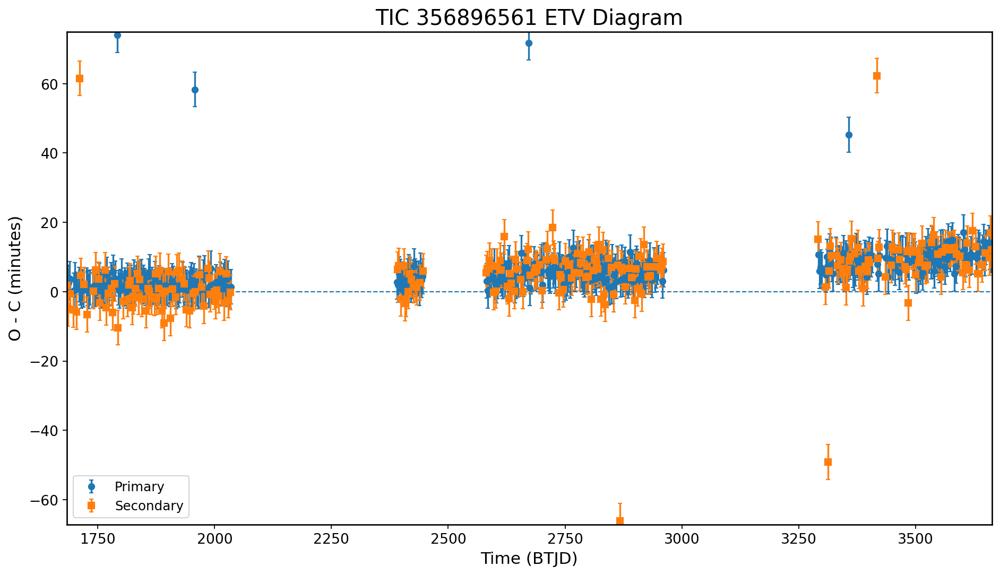

Total detected timings: 2262
Kept clean timings: 2262
Kinds kept: (array(['primary', 'secondary'], dtype=object), array([1085, 1177]))


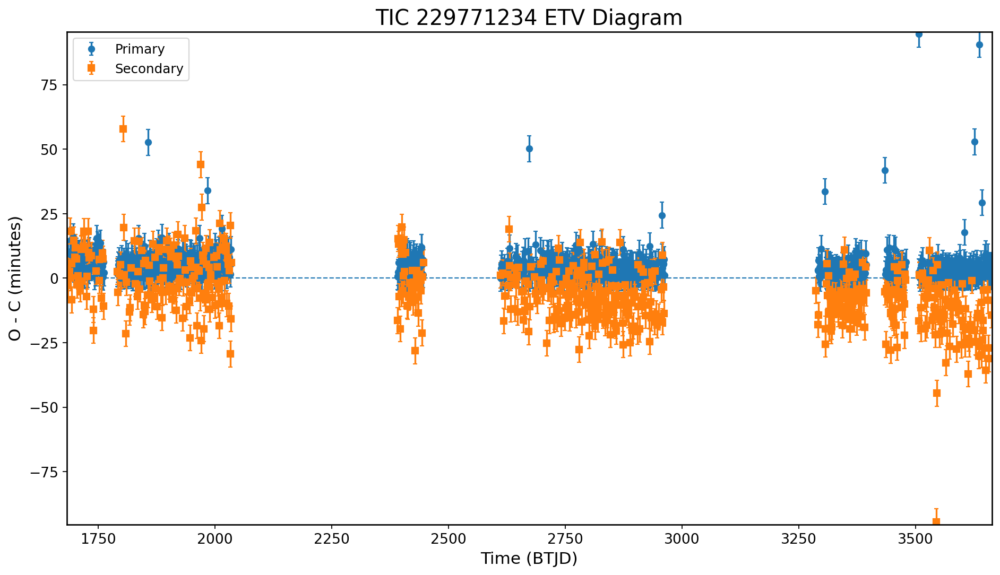

In [ ]:
res2 = run_etv_pipeline(356896561, 2.25335087)
res2_clean = clean_etv_result(res2, oc_clip=150)
plot_etv_clean(res2_clean, tic=356896561)

res3 = run_etv_pipeline(229771234, 0.82095849)
res3_clean = clean_etv_result(res3, oc_clip=100)
plot_etv_clean(res3_clean, tic=229771234)

In [ ]:
def detrend_by_segment(res):
    t = np.asarray(res.get("t_clean", res.get("t_obs", [])))
    oc = np.asarray(res.get("oc_ref", res.get("oc", [])))
    seg = np.asarray(res.get("seg_clean", res.get("seg", np.zeros(len(oc), dtype=int))))

    if len(oc) == 0:
        return res.copy() if isinstance(res, dict) else res

    oc_new = oc.copy()

    for s in np.unique(seg):
        m = seg == s
        if np.sum(m) < 3:
            continue
        offset = np.nanmedian(oc[m])
        oc_new[m] = oc[m] - offset

    res2 = res.copy() if isinstance(res, dict) else dict(res)
    res2["oc_ref"] = oc_new
    res2["seg_clean"] = seg
    return res2

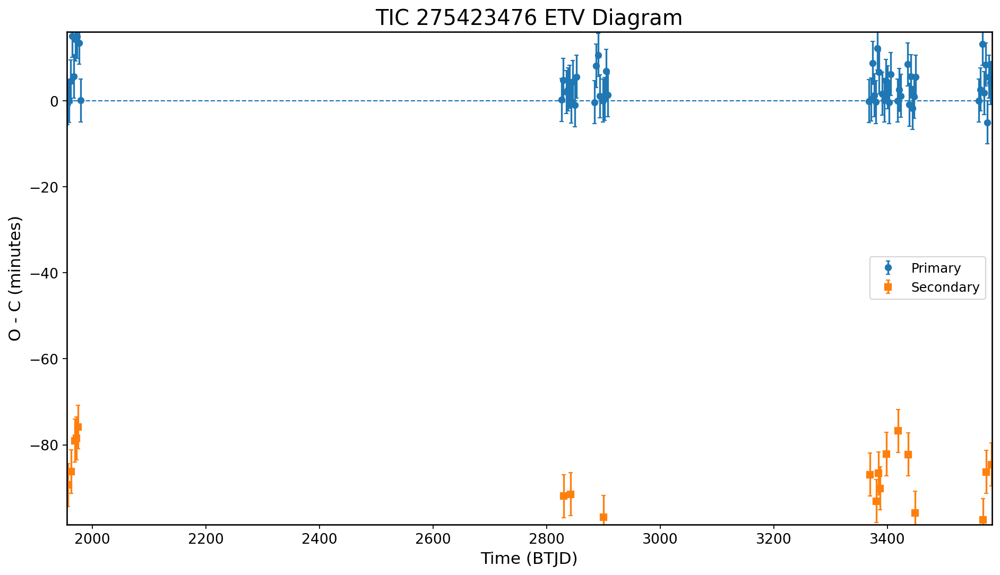

In [ ]:
res_detrended = detrend_by_segment(res_clean)

plot_etv_clean(res_detrended, tic=275423476)

In [ ]:
def sigma_clip_etv(res, nsig=3):
    t = res["t_clean"]
    oc = res["oc_ref"]
    sig = res["sig_clean"]

    med = np.median(oc)
    std = np.std(oc)

    good = np.abs(oc - med) < nsig * std

    res2 = {}
    for k, v in res.items():
        if isinstance(v, np.ndarray) and len(v) == len(good):
            res2[k] = v[good]
        else:
            res2[k] = v
    return res2

Before: 87
After: 87


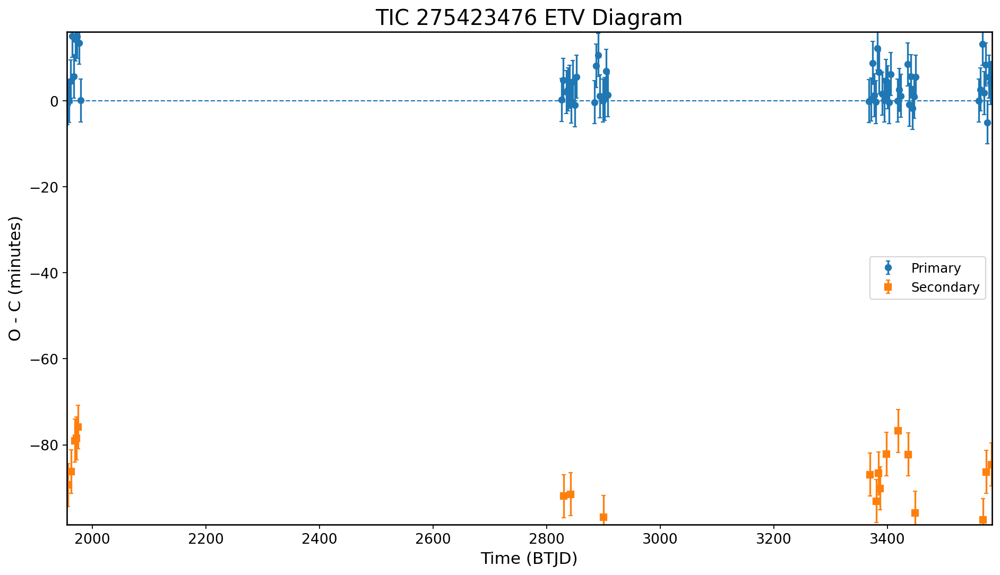

In [ ]:
import numpy as np

def sigma_clip_etv(res, nsig=3):
    t = np.asarray(res['t_clean'])
    oc = np.asarray(res['oc_ref'])
    sig = np.asarray(res['sig_clean'])

    if oc.size == 0:
        return res.copy() if isinstance(res, dict) else res

    med = np.nanmedian(oc)
    std = np.nanstd(oc)
    if not np.isfinite(std) or std == 0:
        good = np.ones_like(oc, dtype=bool)
    else:
        good = np.abs(oc - med) < nsig * std

    res2 = {}
    for k, v in res.items():
        if isinstance(v, np.ndarray) and len(v) == len(good):
            res2[k] = v[good]
        else:
            res2[k] = v
    return res2

base_res = globals().get('res_detrended', globals().get('res_clean', None))
if base_res is None:
    base_res = clean_etv_result(res, oc_clip=100)
res_detrended = base_res

res_final = sigma_clip_etv(res_detrended, nsig=3)

print("Before:", len(res_detrended["t_clean"]))
print("After:", len(res_final["t_clean"]))

plot_etv_clean(res_final, tic=275423476)

In [ ]:
# TIC 356896561
res2 = run_etv_pipeline(356896561, 2.25335087)
res2_clean = clean_etv_result(res2)
res2_detrended = detrend_by_segment(res2_clean)
res2_final = sigma_clip_etv(res2_detrended)

# TIC 229771234
res3 = run_etv_pipeline(229771234, 0.82095849)
res3_clean = clean_etv_result(res3)
res3_detrended = detrend_by_segment(res3_clean)
res3_final = sigma_clip_etv(res3_detrended)

Total detected timings: 923
Kept clean timings: 923
Kinds kept: (array(['primary', 'secondary'], dtype=object), array([421, 502]))
Total detected timings: 2262
Kept clean timings: 2262
Kinds kept: (array(['primary', 'secondary'], dtype=object), array([1085, 1177]))


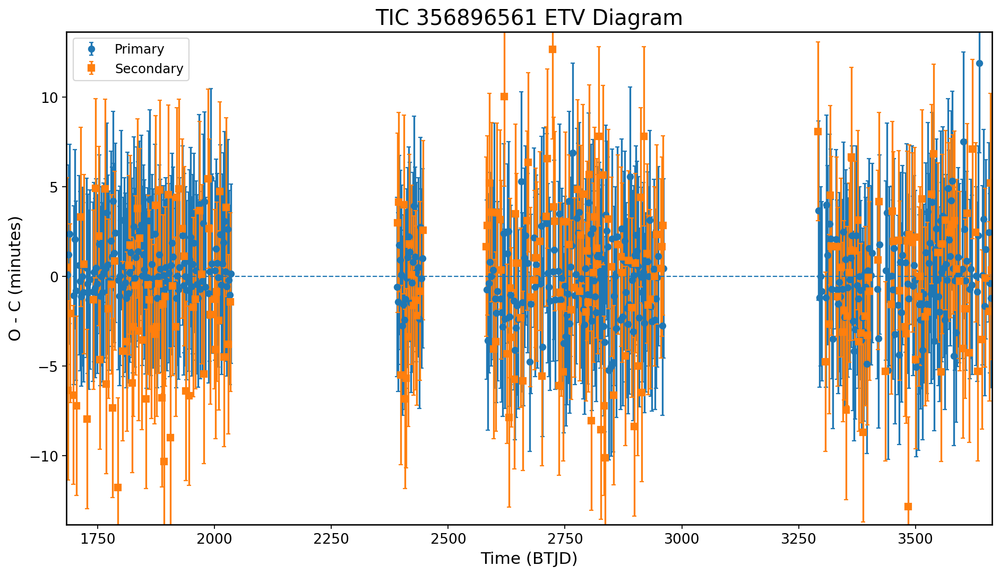

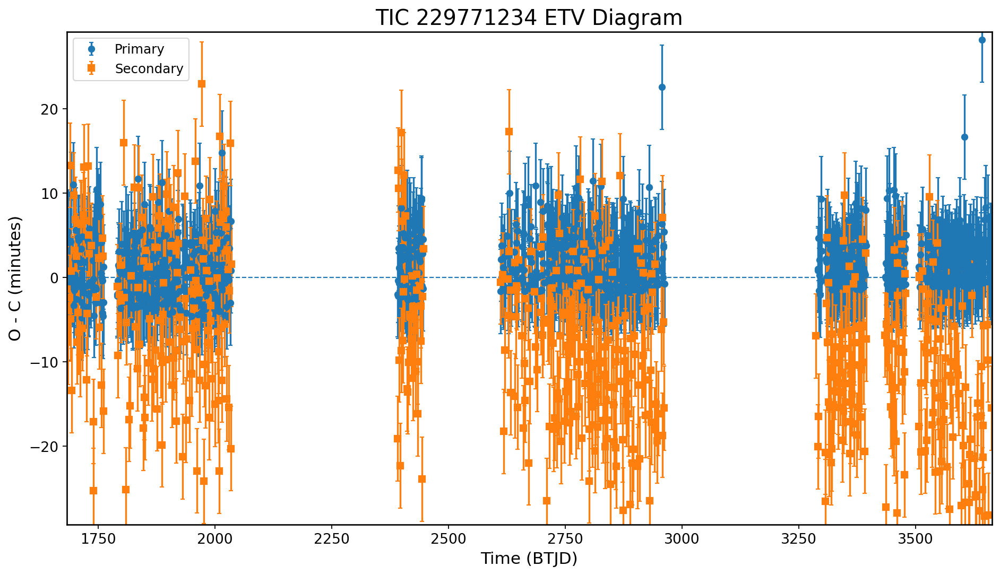

In [ ]:
plot_etv_clean(res2_final, tic=356896561)
plot_etv_clean(res3_final, tic=229771234)

In [ ]:
import numpy as np

def compute_e_cos_omega(res):
    oc = res["oc_ref"]
    kind = res["kind_clean"]
    P = res.get("P_final", res.get("P_new", res.get("P", globals().get("P_guess", globals().get("P", None)))))
    if P is None:
        raise KeyError("No period found in res_final, and no fallback period is available")

    primary = oc[kind == "primary"]
    secondary = oc[kind == "secondary"]

    if len(primary) == 0 or len(secondary) == 0:
        print("Need both primary and secondary")
        return None

    mean_p = np.median(primary)
    mean_s = np.median(secondary)

    delta_t = mean_s - mean_p  # minutes

    # convert to days
    delta_t_days = delta_t / (24 * 60)

    e_cos_w = (np.pi / P) * delta_t_days

    print(f"Primary median: {mean_p:.2f} min")
    print(f"Secondary median: {mean_s:.2f} min")
    print(f"Δt (sec - pri): {delta_t:.2f} min")
    print(f"e cos(ω): {e_cos_w:.5f}")

    return e_cos_w

In [ ]:
compute_e_cos_omega(res_final)

Primary median: 2.59 min
Secondary median: -93.06 min
Δt (sec - pri): -95.65 min
e cos(ω): -0.18521


np.float64(-0.18520795708994467)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.optimize import minimize_scalar
from astropy.timeseries import BoxLeastSquares

def build_primary_template(t, flux, T0, P, phase_halfwidth=0.15, nbins=250):
    phi = phase_fold(t, T0, P)

    # recenter using deepest binned minimum
    coarse_bins = np.linspace(-0.5, 0.5, 401)
    digit = np.digitize(phi, coarse_bins) - 1
    centers = 0.5 * (coarse_bins[:-1] + coarse_bins[1:])
    binned = np.array([np.nanmedian(flux[digit == i]) for i in range(len(centers))])

    phi_shift = centers[np.nanargmin(binned)]
    phi = ((phi - phi_shift + 0.5) % 1.0) - 0.5

    bins = np.linspace(-phase_halfwidth, phase_halfwidth, nbins + 1)
    digit = np.digitize(phi, bins) - 1
    template_phase = 0.5 * (bins[:-1] + bins[1:])
    template_flux = np.array([np.nanmedian(flux[digit == i]) for i in range(nbins)])

    mask = np.isfinite(template_flux)
    template_phase = template_phase[mask]
    template_flux = template_flux[mask]

    norm_mask = np.abs(template_phase) > 0.1
    if np.sum(norm_mask) > 5:
        template_flux = template_flux / np.nanmedian(template_flux[norm_mask])

    return template_phase, template_flux, phi, phi_shift


def smooth_template(template_phase, template_flux):
    med = np.median(template_flux)
    mad = np.median(np.abs(template_flux - med)) + 1e-12
    z = (template_flux - med) / (1.4826 * mad)

    keep = np.abs(z) < 6
    tp = template_phase[keep]
    tf = template_flux[keep]

    idx = np.argsort(tp)
    tp, tf = tp[idx], tf[idx]

    if len(tf) < 9:
        return tp, tf

    win = min(51, len(tf))
    if win % 2 == 0:
        win -= 1
    if win < 9:
        win = 9 if len(tf) >= 9 else len(tf) if len(tf) % 2 == 1 else len(tf) - 1

    if win >= 5:
        tf_smooth = savgol_filter(tf, window_length=win, polyorder=min(3, win - 2))
    else:
        tf_smooth = tf.copy()

    return tp, tf_smooth


def interp_template_factory(tpl_phase, tpl_flux):
    def interp_template(phase):
        return np.interp(phase, tpl_phase, tpl_flux, left=1.0, right=1.0)
    return interp_template


def measure_primary_timings(t, flux, flux_err, T0, P, tpl_phase, tpl_flux,
                            min_points=25, phase_window=0.12, shift_bounds=(-0.05, 0.05),
                            debug_epochs=5):
    interp_template = interp_template_factory(tpl_phase, tpl_flux)

    E_min = int(np.floor((t.min() - T0) / P)) - 1
    E_max = int(np.ceil((t.max() - T0) / P)) + 1
    epochs = np.arange(E_min, E_max + 1)

    t_obs_list, oc_list, sig_list, used_epochs = [], [], [], []
    debug_panels = []

    half_window = phase_window * P

    for E in epochs:
        t_calc = T0 + E * P
        m = (t > t_calc - half_window) & (t < t_calc + half_window)
        if np.sum(m) < min_points:
            continue

        tt = t[m]
        ff = flux[m]
        ee = flux_err[m] if flux_err is not None else np.ones_like(ff) * np.std(ff)

        phase_seg = (tt - t_calc) / P

        def chi2(delta_phase):
            tmpl = interp_template(phase_seg - delta_phase)
            A = np.vstack([tmpl, np.ones_like(tmpl)]).T
            coeff, _, _, _ = np.linalg.lstsq(A, ff, rcond=None)
            a, b = coeff
            model_seg = a * tmpl + b
            return np.sum(((ff - model_seg) / ee) ** 2)

        out = minimize_scalar(chi2, bounds=shift_bounds, method="bounded")
        dphi = out.x
        t_obs = t_calc + dphi * P

        best_tmpl = interp_template(phase_seg - dphi)
        A = np.vstack([best_tmpl, np.ones_like(best_tmpl)]).T
        coeff, _, _, _ = np.linalg.lstsq(A, ff, rcond=None)
        a, b = coeff
        best_model = a * best_tmpl + b

        grid = np.linspace(dphi - 0.01, dphi + 0.01, 41)
        vals = np.array([chi2(x) for x in grid])
        vmin = vals.min()
        ok = grid[vals < vmin + 1.0]
        sig_t = (ok.max() - ok.min()) / 2 * P if len(ok) > 2 else np.nan

        t_obs_list.append(t_obs)
        oc_list.append(t_obs - t_calc)
        sig_list.append(sig_t)
        used_epochs.append(E)

        if len(debug_panels) < debug_epochs:
            debug_panels.append({
                "E": E,
                "tt": tt,
                "ff": ff,
                "phase_seg": phase_seg,
                "best_model": best_model,
                "t_calc": t_calc,
                "t_obs": t_obs,
                "dphi": dphi,
                "a": a,
                "b": b,
            })

    return {
        "t_obs": np.array(t_obs_list),
        "oc": np.array(oc_list),
        "sig": np.array(sig_list),
        "epochs": np.array(used_epochs),
        "debug_panels": debug_panels
    }


def refine_linear_ephemeris(t_obs, epochs):
    A = np.vstack([np.ones_like(epochs), epochs]).T
    coeff, _, _, _ = np.linalg.lstsq(A, t_obs, rcond=None)
    T0_new, P_new = coeff
    return T0_new, P_new


def compare_chunk_templates(t, flux, T0, P, nchunks=2):
    edges = np.linspace(t.min(), t.max(), nchunks + 1)
    templates = []

    for i in range(nchunks):
        m = (t >= edges[i]) & (t < edges[i + 1] if i < nchunks - 1 else t <= edges[i + 1])
        if np.sum(m) < 50:
            continue
        tp, tf, _, _ = build_primary_template(t[m], flux[m], T0, P)
        tp, tf = smooth_template(tp, tf)
        templates.append((i, tp, tf))

    return templates


def run_etv_pipeline(t, flux, flux_err, T0_guess, P_guess, show_plots=True):
    results = {}

    # STEP 1: phase-fold validation
    tp_raw, tf_raw, phi_centered, phi_shift = build_primary_template(t, flux, T0_guess, P_guess)
    results["phi_shift"] = phi_shift

    if show_plots:
        plt.figure(figsize=(8, 4))
        plt.scatter(phi_centered, flux, s=2, alpha=0.35)
        plt.xlim(-0.5, 0.5)
        plt.xlabel("Phase")
        plt.ylabel("Flux")
        plt.title("Step 1: Phase-fold validation")
        plt.gca().invert_yaxis()
        plt.show()

    # STEP 2: raw vs smoothed template
    tp_clean, tf_clean = smooth_template(tp_raw, tf_raw)
    results["template_phase_raw"] = tp_raw
    results["template_flux_raw"] = tf_raw
    results["template_phase_clean"] = tp_clean
    results["template_flux_clean"] = tf_clean

    if show_plots:
        plt.figure(figsize=(8, 4))
        plt.plot(tp_raw, tf_raw, color="0.7", label="raw template")
        plt.plot(tp_clean, tf_clean, "k", lw=2, label="smoothed template")
        plt.xlabel("Phase")
        plt.ylabel("Normalized Flux")
        plt.title("Step 2: Template construction check")
        plt.legend()
        plt.gca().invert_yaxis()
        plt.show()

    # STEP 3: timing extraction + example fit debugging
    timing = measure_primary_timings(t, flux, flux_err, T0_guess, P_guess, tp_clean, tf_clean)
    results["timing"] = timing

    if show_plots and len(timing["debug_panels"]) > 0:
        for panel in timing["debug_panels"]:
            plt.figure(figsize=(7, 4))
            plt.scatter(panel["phase_seg"], panel["ff"], s=10, alpha=0.7, label="data")
            plt.plot(panel["phase_seg"], panel["best_model"], lw=2, label="shifted template")
            plt.axvline((panel["t_obs"] - panel["t_calc"]) / P_guess, ls="--")
            plt.xlabel("Phase relative to predicted eclipse")
            plt.ylabel("Flux")
            plt.title(f"Step 3: Eclipse fit check (epoch {panel['E']})")
            plt.legend()
            plt.gca().invert_yaxis()
            plt.show()

    # STEP 4: initial O-C
    if show_plots and len(timing["t_obs"]) > 0:
        plt.figure(figsize=(8, 4))
        plt.errorbar(timing["t_obs"], timing["oc"] * 24 * 60,
                     yerr=timing["sig"] * 24 * 60, fmt=".", ms=4)
        plt.axhline(0, lw=1)
        plt.xlabel("Time (BTJD)")
        plt.ylabel("O - C (minutes)")
        plt.title("Step 4: Initial O-C")
        plt.show()

    # STEP 5: ephemeris refinement
    if len(timing["t_obs"]) > 1:
        T0_new, P_new = refine_linear_ephemeris(timing["t_obs"], timing["epochs"])
    else:
        T0_new, P_new = T0_guess, P_guess

    results["T0_new"] = T0_new
    results["P_new"] = P_new

    t_calc_new = T0_new + P_new * timing["epochs"]
    oc_new = timing["t_obs"] - t_calc_new
    results["oc_refined"] = oc_new

    if show_plots and len(timing["t_obs"]) > 0:
        plt.figure(figsize=(8, 4))
        plt.errorbar(timing["t_obs"], oc_new * 24 * 60,
                     yerr=timing["sig"] * 24 * 60, fmt=".", ms=4)
        plt.axhline(0, lw=1)
        plt.xlabel("Time (BTJD)")
        plt.ylabel("O - C (minutes)")
        plt.title("Step 5: O-C after ephemeris refinement")
        plt.show()

    # STEP 6: chunk/sector template stability
    chunk_templates = compare_chunk_templates(t, flux, T0_new, P_new, nchunks=2)
    results["chunk_templates"] = chunk_templates

    if show_plots and len(chunk_templates) > 1:
        plt.figure(figsize=(7, 4))
        for idx, tp, tf in chunk_templates:
            plt.plot(tp, tf, label=f"chunk {idx+1}")
        plt.xlabel("Phase")
        plt.ylabel("Normalized Flux")
        plt.title("Step 6: Template stability check")
        plt.legend()
        plt.gca().invert_yaxis()
        plt.show()

    return results

flux_norm length: 117549
candidate time lengths: {'t': 124, 'lc.time.value': 117549}
Using lc.time.value: 117549 finite points
len(phi) = 117549
len(flux_plot[finite]) = 117549


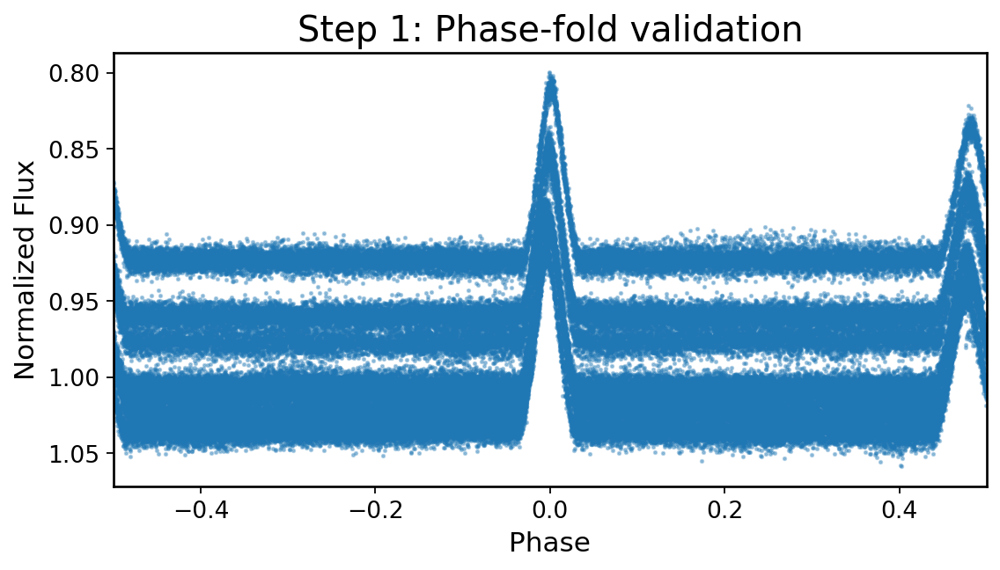

In [ ]:
# STEP 1: validate phase folding

flux_plot = np.asarray(flux_norm, dtype=float).reshape(-1)

time_candidates = []

if "t" in globals():
    time_candidates.append(("t", np.asarray(t, dtype=float).reshape(-1)))

if "time" in globals():
    time_candidates.append(("time", np.asarray(time, dtype=float).reshape(-1)))

if "lc" in globals():
    try:
        time_candidates.append(("lc.time.value", np.asarray(lc.time.value, dtype=float).reshape(-1)))
    except Exception:
        pass

if "data" in globals():
    try:
        time_candidates.append(('data["TIME"]', np.asarray(data["TIME"], dtype=float).reshape(-1)))
    except Exception:
        pass

print("flux_norm length:", len(flux_plot))
print("candidate time lengths:", {name: len(arr) for name, arr in time_candidates})

matched = [(name, arr) for name, arr in time_candidates if len(arr) == len(flux_plot)]

if not matched:
    raise ValueError(
        "No time array matches flux_norm. "
        "Rerun the light-curve loading cell that creates the original time/flux_norm arrays."
    )

time_name, t_phase = matched[0]

finite = np.isfinite(t_phase) & np.isfinite(flux_plot)

phi = ((t_phase[finite] - T0) / P + 0.5) % 1 - 0.5

print(f"Using {time_name}: {finite.sum()} finite points")
print("len(phi) =", len(phi))
print("len(flux_plot[finite]) =", len(flux_plot[finite]))

plt.figure(figsize=(8, 4))
plt.scatter(phi, flux_plot[finite], s=2, alpha=0.35)
plt.xlim(-0.5, 0.5)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Step 1: Phase-fold validation")
plt.gca().invert_yaxis()
plt.show()


In [ ]:
def measure_primary_timings(t, flux, flux_err, T0, P, tpl_phase, tpl_flux,
                            min_points=25, phase_window=0.12, shift_bounds=(-0.05, 0.05),
                            debug_epochs=5):
    import numpy as np
    from scipy.optimize import minimize_scalar

    def interp_template(phase):
        return np.interp(phase, tpl_phase, tpl_flux, left=1.0, right=1.0)

    E_min = int(np.floor((t.min() - T0) / P)) - 1
    E_max = int(np.ceil((t.max() - T0) / P)) + 1
    epochs = np.arange(E_min, E_max + 1)

    t_obs_list = []
    oc_list = []
    sig_list = []
    used_epochs = []
    debug_panels = []

    half_window = phase_window * P

    for E in epochs:
        t_calc = T0 + E * P
        m = (t > t_calc - half_window) & (t < t_calc + half_window)

        if np.sum(m) < min_points:
            continue

        tt = t[m]
        ff = flux[m]

        if flux_err is not None:
            ee = flux_err[m]
            ee = np.where(np.isfinite(ee) & (ee > 0), ee, np.nanmedian(ee[np.isfinite(ee) & (ee > 0)]))
        else:
            ee = np.ones_like(ff) * np.nanstd(ff)

        phase_seg = (tt - t_calc) / P

        def chi2(delta_phase):
            tmpl = interp_template(phase_seg - delta_phase)
            A = np.vstack([tmpl, np.ones_like(tmpl)]).T
            coeff, _, _, _ = np.linalg.lstsq(A, ff, rcond=None)
            a, b = coeff
            model_seg = a * tmpl + b
            return np.sum(((ff - model_seg) / ee) ** 2)

        out = minimize_scalar(chi2, bounds=shift_bounds, method="bounded")
        dphi = out.x
        t_obs = t_calc + dphi * P

        best_tmpl = interp_template(phase_seg - dphi)
        A = np.vstack([best_tmpl, np.ones_like(best_tmpl)]).T
        coeff, _, _, _ = np.linalg.lstsq(A, ff, rcond=None)
        a, b = coeff
        best_model = a * best_tmpl + b

        grid = np.linspace(dphi - 0.01, dphi + 0.01, 41)
        vals = np.array([chi2(x) for x in grid])
        vmin = vals.min()
        ok = grid[vals < vmin + 1.0]
        sig_t = (ok.max() - ok.min()) / 2 * P if len(ok) > 2 else np.nan

        t_obs_list.append(t_obs)
        oc_list.append(t_obs - t_calc)
        sig_list.append(sig_t)
        used_epochs.append(E)

        if len(debug_panels) < debug_epochs:
            debug_panels.append({
                "E": E,
                "tt": tt,
                "ff": ff,
                "phase_seg": phase_seg,
                "best_model": best_model,
                "t_calc": t_calc,
                "t_obs": t_obs,
                "dphi": dphi,
                "a": a,
                "b": b,
            })

    return {
        "t_obs": np.array(t_obs_list),
        "oc": np.array(oc_list),
        "sig": np.array(sig_list),
        "epochs": np.array(used_epochs),
        "debug_panels": debug_panels
    }

In [ ]:
print("t exists:", 't' in globals())
print("flux_norm exists:", 'flux_norm' in globals())

t exists: True
flux_norm exists: True


In [ ]:
flux_norm = flux / np.nanmedian(flux)

print("t exists:", 't' in globals())
print("flux exists:", 'flux' in globals())
print("flux_norm exists:", 'flux_norm' in globals())
print("T0 exists:", 'T0' in globals())
print("P exists:", 'P' in globals())
print("tp_smooth exists:", 'tp_smooth' in globals())
print("tf_smooth exists:", 'tf_smooth' in globals())

t exists: True
flux exists: True
flux_norm exists: True
T0 exists: True
P exists: True
tp_smooth exists: False
tf_smooth exists: True


flux_norm length: 117549
candidate time lengths: {'t': 124, 'lc.time.value': 117549}
Using lc.time.value: 117549 finite points


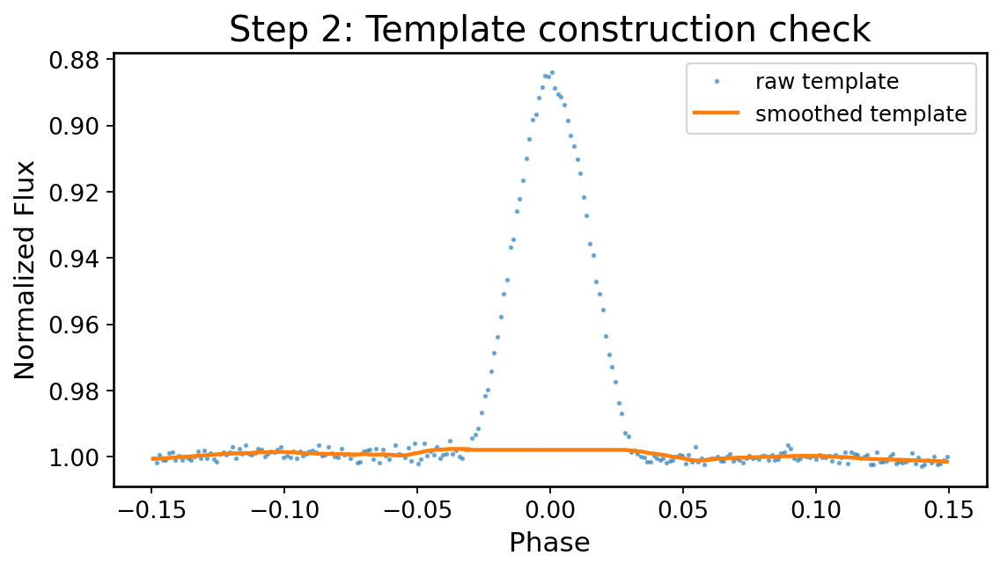

In [ ]:
# STEP 2: raw template vs smoothed template

flux_plot = np.asarray(flux_norm, dtype=float).reshape(-1)
time_candidates = []

if "t" in globals():
    time_candidates.append(("t", np.asarray(t, dtype=float).reshape(-1)))
if "time" in globals():
    time_candidates.append(("time", np.asarray(time, dtype=float).reshape(-1)))
if "lc" in globals():
    try:
        time_candidates.append(("lc.time.value", np.asarray(lc.time.value, dtype=float).reshape(-1)))
    except Exception:
        pass
if "data" in globals():
    try:
        time_candidates.append(("data TIME", np.asarray(data["TIME"], dtype=float).reshape(-1)))
    except Exception:
        pass

print("flux_norm length:", len(flux_plot))
print("candidate time lengths:", {name: len(arr) for name, arr in time_candidates})

matched = [(name, arr) for name, arr in time_candidates if len(arr) == len(flux_plot)]
if not matched:
    raise ValueError("No time array matches flux_norm. Rerun the light-curve loading cell first.")

time_name, t_template = matched[0]
finite = np.isfinite(t_template) & np.isfinite(flux_plot)
t_template = t_template[finite]
flux_template = flux_plot[finite]

print(f"Using {time_name}: {len(t_template)} finite points")

tp_raw, tf_raw, phi_centered, phi_shift = build_primary_template(
    t_template, flux_template, T0, P
)
tp_smooth, tf_smooth = smooth_template(tp_raw, tf_raw)

plt.figure(figsize=(8, 4))
plt.plot(tp_raw, tf_raw, ".", ms=3, alpha=0.5, label="raw template")
plt.plot(tp_smooth, tf_smooth, "-", lw=2, label="smoothed template")
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Step 2: Template construction check")
plt.legend()
plt.gca().invert_yaxis()
plt.show()

In [ ]:
def build_primary_template(t, flux, T0, P, phase_halfwidth=0.15, nbins=200):
    import numpy as np

    # Fold into [-0.5, 0.5)
    phi = ((t - T0) / P + 0.5) % 1 - 0.5

    # Find the primary eclipse center from binned folded light curve
    coarse_bins = np.linspace(-0.5, 0.5, 401)
    coarse_centers = 0.5 * (coarse_bins[:-1] + coarse_bins[1:])
    digit = np.digitize(phi, coarse_bins) - 1

    coarse_med = np.array([
        np.nanmedian(flux[digit == i]) if np.any(digit == i) else np.nan
        for i in range(len(coarse_centers))
    ])

    # Since eclipse is a dip in flux, use nanargmin
    # Force selection of PRIMARY eclipse near phase 0
    search_mask = (coarse_centers > -0.1) & (coarse_centers < 0.1)

    phi_shift = coarse_centers[search_mask][
    np.nanargmin(coarse_med[search_mask])
]

    # Recenter so primary eclipse sits at phase 0
    phi_centered = ((phi - phi_shift + 0.5) % 1) - 0.5

    # Select only the deepest points (eclipse region)
    threshold = np.nanpercentile(flux, 5)  # lowest 5% of flux values

    m = flux < threshold

    phi_use = phi_centered[m]
    flux_use = flux[m]
    

    # Bin near eclipse
    bins = np.linspace(-phase_halfwidth, phase_halfwidth, nbins + 1)
    centers = 0.5 * (bins[:-1] + bins[1:])
    digit2 = np.digitize(phi_use, bins) - 1

    template_flux = np.array([
        np.nanmedian(flux_use[digit2 == i]) if np.any(digit2 == i) else np.nan
        for i in range(len(centers))
    ])

    good = np.isfinite(template_flux)
    template_phase = centers[good]
    template_flux = template_flux[good]

    # Normalize with out-of-eclipse baseline only
    out_mask = np.abs(template_phase) > 0.08
    if np.sum(out_mask) > 5:
        baseline = np.nanmedian(template_flux[out_mask])
        template_flux = template_flux / baseline

    return template_phase, template_flux, phi_centered, phi_shift

In [ ]:
def smooth_template(template_phase, template_flux):
    import numpy as np
    from scipy.signal import savgol_filter

    idx = np.argsort(template_phase)
    tp = template_phase[idx]
    tf = template_flux[idx]

    if len(tf) < 9:
        return tp, tf

    win = min(21, len(tf))
    if win % 2 == 0:
        win -= 1
    if win < 7:
        return tp, tf

    tf_smooth = savgol_filter(tf, window_length=win, polyorder=2)

    return tp, tf_smooth

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.optimize import minimize_scalar
from astropy.timeseries import BoxLeastSquares

def build_primary_template(t, flux, T0, P, phase_halfwidth=0.15, nbins=250):
    phi = phase_fold(t, T0, P)

    # recenter using deepest binned minimum
    coarse_bins = np.linspace(-0.5, 0.5, 401)
    digit = np.digitize(phi, coarse_bins) - 1
    centers = 0.5 * (coarse_bins[:-1] + coarse_bins[1:])
    binned = np.array([np.nanmedian(flux[digit == i]) for i in range(len(centers))])

    phi_shift = centers[np.nanargmin(binned)]
    phi = ((phi - phi_shift + 0.5) % 1.0) - 0.5

    bins = np.linspace(-phase_halfwidth, phase_halfwidth, nbins + 1)
    digit = np.digitize(phi, bins) - 1
    template_phase = 0.5 * (bins[:-1] + bins[1:])
    template_flux = np.array([np.nanmedian(flux[digit == i]) for i in range(nbins)])

    mask = np.isfinite(template_flux)
    template_phase = template_phase[mask]
    template_flux = template_flux[mask]

    norm_mask = np.abs(template_phase) > 0.1
    if np.sum(norm_mask) > 5:
        template_flux = template_flux / np.nanmedian(template_flux[norm_mask])

    return template_phase, template_flux, phi, phi_shift


def smooth_template(template_phase, template_flux):
    med = np.median(template_flux)
    mad = np.median(np.abs(template_flux - med)) + 1e-12
    z = (template_flux - med) / (1.4826 * mad)

    keep = np.abs(z) < 6
    tp = template_phase[keep]
    tf = template_flux[keep]

    idx = np.argsort(tp)
    tp, tf = tp[idx], tf[idx]

    if len(tf) < 9:
        return tp, tf

    win = min(51, len(tf))
    if win % 2 == 0:
        win -= 1
    if win < 9:
        win = 9 if len(tf) >= 9 else len(tf) if len(tf) % 2 == 1 else len(tf) - 1

    if win >= 5:
        tf_smooth = savgol_filter(tf, window_length=win, polyorder=min(3, win - 2))
    else:
        tf_smooth = tf.copy()

    return tp, tf_smooth


def interp_template_factory(tpl_phase, tpl_flux):
    def interp_template(phase):
        return np.interp(phase, tpl_phase, tpl_flux, left=1.0, right=1.0)
    return interp_template


def measure_primary_timings(t, flux, flux_err, T0, P, tpl_phase, tpl_flux,
                            min_points=25, phase_window=0.12, shift_bounds=(-0.05, 0.05),
                            debug_epochs=5):
    interp_template = interp_template_factory(tpl_phase, tpl_flux)

    E_min = int(np.floor((t.min() - T0) / P)) - 1
    E_max = int(np.ceil((t.max() - T0) / P)) + 1
    epochs = np.arange(E_min, E_max + 1)

    t_obs_list, oc_list, sig_list, used_epochs = [], [], [], []
    debug_panels = []

    half_window = phase_window * P

    for E in epochs:
        t_calc = T0 + E * P
        m = (t > t_calc - half_window) & (t < t_calc + half_window)
        if np.sum(m) < min_points:
            continue

        tt = t[m]
        ff = flux[m]
        ee = flux_err[m] if flux_err is not None else np.ones_like(ff) * np.std(ff)

        phase_seg = (tt - t_calc) / P

        def chi2(delta_phase):
            tmpl = interp_template(phase_seg - delta_phase)
            A = np.vstack([tmpl, np.ones_like(tmpl)]).T
            coeff, _, _, _ = np.linalg.lstsq(A, ff, rcond=None)
            a, b = coeff
            model_seg = a * tmpl + b
            return np.sum(((ff - model_seg) / ee) ** 2)

        out = minimize_scalar(chi2, bounds=shift_bounds, method="bounded")
        dphi = out.x
        t_obs = t_calc + dphi * P

        best_tmpl = interp_template(phase_seg - dphi)
        A = np.vstack([best_tmpl, np.ones_like(best_tmpl)]).T
        coeff, _, _, _ = np.linalg.lstsq(A, ff, rcond=None)
        a, b = coeff
        best_model = a * best_tmpl + b

        grid = np.linspace(dphi - 0.01, dphi + 0.01, 41)
        vals = np.array([chi2(x) for x in grid])
        vmin = vals.min()
        ok = grid[vals < vmin + 1.0]
        sig_t = (ok.max() - ok.min()) / 2 * P if len(ok) > 2 else np.nan

        t_obs_list.append(t_obs)
        oc_list.append(t_obs - t_calc)
        sig_list.append(sig_t)
        used_epochs.append(E)

        if len(debug_panels) < debug_epochs:
            debug_panels.append({
                "E": E,
                "tt": tt,
                "ff": ff,
                "phase_seg": phase_seg,
                "best_model": best_model,
                "t_calc": t_calc,
                "t_obs": t_obs,
                "dphi": dphi,
                "a": a,
                "b": b,
            })

    return {
        "t_obs": np.array(t_obs_list),
        "oc": np.array(oc_list),
        "sig": np.array(sig_list),
        "epochs": np.array(used_epochs),
        "debug_panels": debug_panels
    }


def refine_linear_ephemeris(t_obs, epochs):
    A = np.vstack([np.ones_like(epochs), epochs]).T
    coeff, _, _, _ = np.linalg.lstsq(A, t_obs, rcond=None)
    T0_new, P_new = coeff
    return T0_new, P_new


def compare_chunk_templates(t, flux, T0, P, nchunks=2):
    edges = np.linspace(t.min(), t.max(), nchunks + 1)
    templates = []

    for i in range(nchunks):
        m = (t >= edges[i]) & (t < edges[i + 1] if i < nchunks - 1 else t <= edges[i + 1])
        if np.sum(m) < 50:
            continue
        tp, tf, _, _ = build_primary_template(t[m], flux[m], T0, P)
        tp, tf = smooth_template(tp, tf)
        templates.append((i, tp, tf))

    return templates


def run_etv_pipeline(t, flux, flux_err, T0_guess, P_guess, show_plots=True):
    results = {}

    # STEP 1: phase-fold validation
    tp_raw, tf_raw, phi_centered, phi_shift = build_primary_template(t, flux, T0_guess, P_guess)
    results["phi_shift"] = phi_shift

    if show_plots:
        plt.figure(figsize=(8, 4))
        plt.scatter(phi_centered, flux, s=2, alpha=0.35)
        plt.xlim(-0.5, 0.5)
        plt.xlabel("Phase")
        plt.ylabel("Flux")
        plt.title("Step 1: Phase-fold validation")
        plt.gca().invert_yaxis()
        plt.show()

    # STEP 2: raw vs smoothed template
    tp_clean, tf_clean = smooth_template(tp_raw, tf_raw)
    results["template_phase_raw"] = tp_raw
    results["template_flux_raw"] = tf_raw
    results["template_phase_clean"] = tp_clean
    results["template_flux_clean"] = tf_clean

    if show_plots:
        plt.figure(figsize=(8, 4))
        plt.plot(tp_raw, tf_raw, color="0.7", label="raw template")
        plt.plot(tp_clean, tf_clean, "k", lw=2, label="smoothed template")
        plt.xlabel("Phase")
        plt.ylabel("Normalized Flux")
        plt.title("Step 2: Template construction check")
        plt.legend()
        plt.gca().invert_yaxis()
        plt.show()

    # STEP 3: timing extraction + example fit debugging
    timing = measure_primary_timings(t, flux, flux_err, T0_guess, P_guess, tp_clean, tf_clean)
    results["timing"] = timing

    if show_plots and len(timing["debug_panels"]) > 0:
        for panel in timing["debug_panels"]:
            plt.figure(figsize=(7, 4))
            plt.scatter(panel["phase_seg"], panel["ff"], s=10, alpha=0.7, label="data")
            plt.plot(panel["phase_seg"], panel["best_model"], lw=2, label="shifted template")
            plt.axvline((panel["t_obs"] - panel["t_calc"]) / P_guess, ls="--")
            plt.xlabel("Phase relative to predicted eclipse")
            plt.ylabel("Flux")
            plt.title(f"Step 3: Eclipse fit check (epoch {panel['E']})")
            plt.legend()
            plt.gca().invert_yaxis()
            plt.show()

    # STEP 4: initial O-C
    if show_plots and len(timing["t_obs"]) > 0:
        plt.figure(figsize=(8, 4))
        plt.errorbar(timing["t_obs"], timing["oc"] * 24 * 60,
                     yerr=timing["sig"] * 24 * 60, fmt=".", ms=4)
        plt.axhline(0, lw=1)
        plt.xlabel("Time (BTJD)")
        plt.ylabel("O - C (minutes)")
        plt.title("Step 4: Initial O-C")
        plt.show()

    # STEP 5: ephemeris refinement
    if len(timing["t_obs"]) > 1:
        T0_new, P_new = refine_linear_ephemeris(timing["t_obs"], timing["epochs"])
    else:
        T0_new, P_new = T0_guess, P_guess

    results["T0_new"] = T0_new
    results["P_new"] = P_new

    t_calc_new = T0_new + P_new * timing["epochs"]
    oc_new = timing["t_obs"] - t_calc_new
    results["oc_refined"] = oc_new

    if show_plots and len(timing["t_obs"]) > 0:
        plt.figure(figsize=(8, 4))
        plt.errorbar(timing["t_obs"], oc_new * 24 * 60,
                     yerr=timing["sig"] * 24 * 60, fmt=".", ms=4)
        plt.axhline(0, lw=1)
        plt.xlabel("Time (BTJD)")
        plt.ylabel("O - C (minutes)")
        plt.title("Step 5: O-C after ephemeris refinement")
        plt.show()

    # STEP 6: chunk/sector template stability
    chunk_templates = compare_chunk_templates(t, flux, T0_new, P_new, nchunks=2)
    results["chunk_templates"] = chunk_templates

    if show_plots and len(chunk_templates) > 1:
        plt.figure(figsize=(7, 4))
        for idx, tp, tf in chunk_templates:
            plt.plot(tp, tf, label=f"chunk {idx+1}")
        plt.xlabel("Phase")
        plt.ylabel("Normalized Flux")
        plt.title("Step 6: Template stability check")
        plt.legend()
        plt.gca().invert_yaxis()
        plt.show()

    return results

flux_norm length: 117549
candidate time lengths: {'t': 124, 'lc.time.value': 117549}
Using lc.time.value: 117549 finite points
phi_shift = -0.0037500000000000033
raw template points = 250
smoothed template points = 205


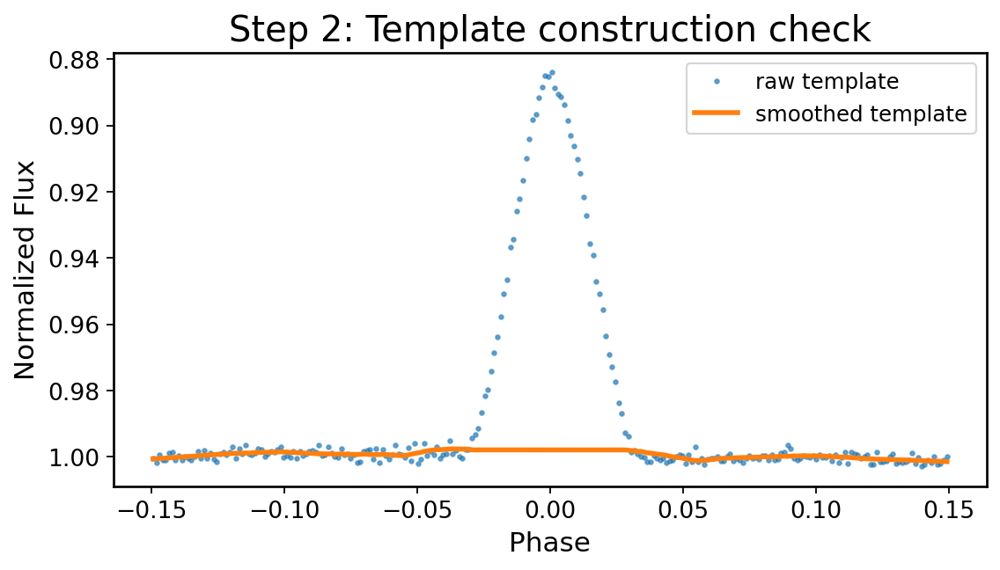

In [ ]:
# STEP 2: rebuild primary eclipse template cleanly

flux_plot = np.asarray(flux_norm, dtype=float).reshape(-1)
time_candidates = []

if "t" in globals():
    time_candidates.append(("t", np.asarray(t, dtype=float).reshape(-1)))
if "time" in globals():
    time_candidates.append(("time", np.asarray(time, dtype=float).reshape(-1)))
if "lc" in globals():
    try:
        time_candidates.append(("lc.time.value", np.asarray(lc.time.value, dtype=float).reshape(-1)))
    except Exception:
        pass
if "data" in globals():
    try:
        time_candidates.append(("data TIME", np.asarray(data["TIME"], dtype=float).reshape(-1)))
    except Exception:
        pass

print("flux_norm length:", len(flux_plot))
print("candidate time lengths:", {name: len(arr) for name, arr in time_candidates})

matched = [(name, arr) for name, arr in time_candidates if len(arr) == len(flux_plot)]
if not matched:
    raise ValueError("No time array matches flux_norm. Rerun the light-curve loading cell first.")

time_name, t_template = matched[0]
finite = np.isfinite(t_template) & np.isfinite(flux_plot)
t_template = t_template[finite]
flux_template = flux_plot[finite]

print(f"Using {time_name}: {len(t_template)} finite points")

tp_raw, tf_raw, phi_centered, phi_shift = build_primary_template(
    t_template, flux_template, T0, P
)
tp_smooth, tf_smooth = smooth_template(tp_raw, tf_raw)

print("phi_shift =", phi_shift)
print("raw template points =", len(tp_raw))
print("smoothed template points =", len(tp_smooth))

plt.figure(figsize=(8, 4))
plt.plot(tp_raw, tf_raw, ".", ms=4, alpha=0.6, label="raw template")
plt.plot(tp_smooth, tf_smooth, "-", lw=2.5, label="smoothed template")
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Step 2: Template construction check")
plt.legend()
plt.gca().invert_yaxis()
plt.show()


In [ ]:
phi_test = ((t - T0) / P + 0.5) % 1 - 0.5

m = np.abs(phi_test) < 0.15

plt.figure(figsize=(8,4))
plt.scatter(phi_test[m], flux_norm[m], s=6, alpha=0.5)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Diagnostic: raw folded points near phase 0")
plt.gca().invert_yaxis()
plt.show()

print("Min flux in window:", np.nanmin(flux_norm[m]))
print("Median flux in window:", np.nanmedian(flux_norm[m]))
print("Number of points in window:", np.sum(m))

IndexError: boolean index did not match indexed array along axis 0; size of axis is 117549 but size of corresponding boolean axis is 124

<Figure size 1280x640 with 0 Axes>

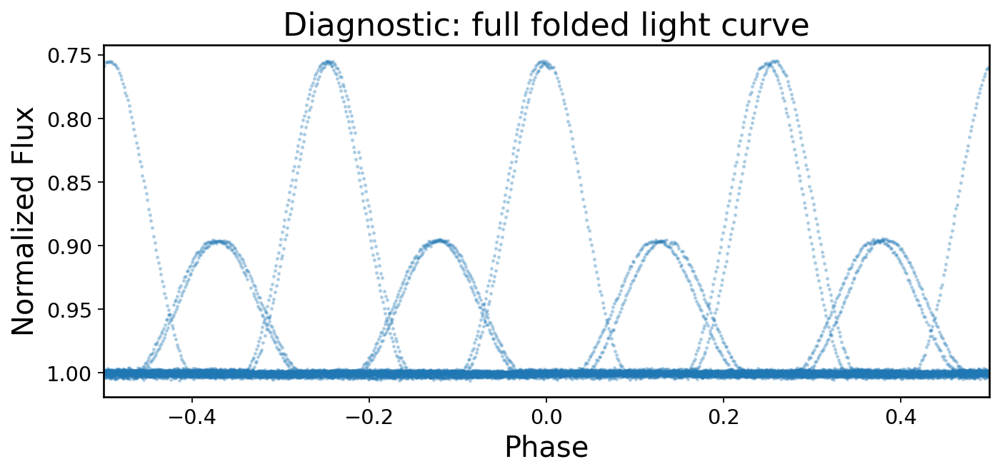

In [ ]:
plt.figure(figsize=(10,4))
plt.scatter(phi_test, flux_norm, s=2, alpha=0.25)
plt.xlim(-0.5, 0.5)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Diagnostic: full folded light curve")
plt.gca().invert_yaxis()
plt.show()

In [ ]:
print("T0 =", T0)
print("P =", P)
print("flux_norm min =", np.nanmin(flux_norm))
print("flux_norm median =", np.nanmedian(flux_norm))
print("flux_norm max =", np.nanmax(flux_norm))

tp_raw, tf_raw, phi_centered, phi_shift = build_primary_template(t, flux_norm, T0, P)

print("phi_shift =", phi_shift)
print("tp_raw[:10] =", tp_raw[:10])
print("tf_raw[:10] =", tf_raw[:10])
print("tf_raw min =", np.nanmin(tf_raw))
print("tf_raw max =", np.nanmax(tf_raw))

T0 = 1710.2012872626995
P = 1.002043172326431
flux_norm min = 0.75463927
flux_norm median = 1.0
flux_norm max = 1.0062382
phi_shift = -0.38125
tp_raw[:10] = [-0.1494 -0.1482 -0.147  -0.1458 -0.1446 -0.1434 -0.1422 -0.141  -0.1398
 -0.1386]
tf_raw[:10] = [1.0002519  1.0003341  0.99889594 1.0000782  1.0001708  1.0001227
 0.9992333  1.0007502  1.0003512  0.9995497 ]
tf_raw min = 0.99868035
tf_raw max = 1.0011663


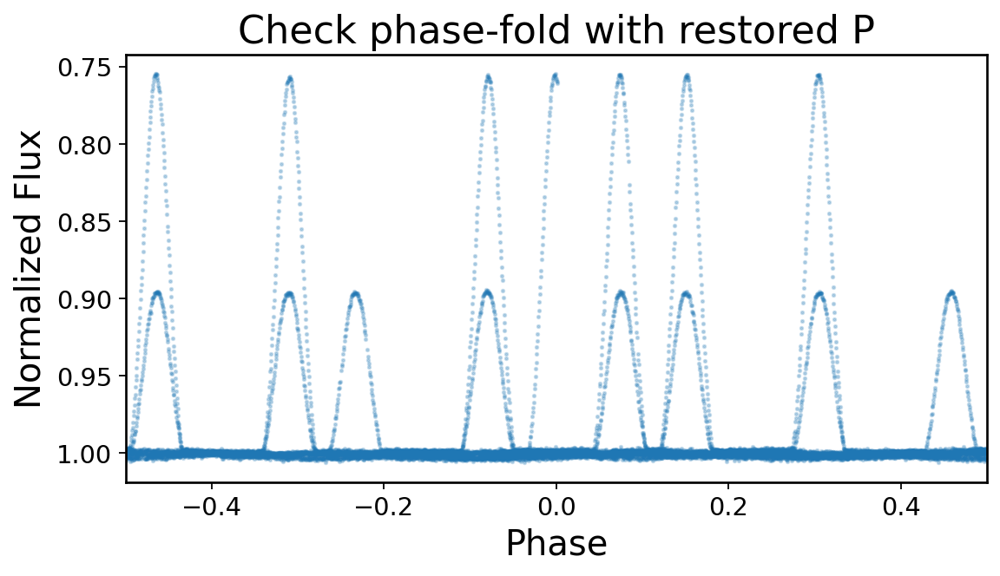

T0 = 1710.2012872626995
P = 2.9287911639400495


In [ ]:
# reset to the period that gave the correct phase-fold
P = 2.9287911639400495

# recompute the folded phase with the correct period
phi = ((t - T0) / P + 0.5) % 1 - 0.5

plt.figure(figsize=(8,4))
plt.scatter(phi, flux_norm, s=2, alpha=0.25)
plt.xlim(-0.5, 0.5)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Check phase-fold with restored P")
plt.gca().invert_yaxis()
plt.show()

print("T0 =", T0)
print("P =", P)

In [ ]:
def refine_T0_parabola(t, flux, T0_guess, window=0.12):
    m = (t > T0_guess - window) & (t < T0_guess + window)
    tt = t[m]
    ff = flux[m]

    if len(tt) < 5:
        return T0_guess

    coeff = np.polyfit(tt, ff, 2)
    a, b, c = coeff

    if a == 0:
        return T0_guess

    T0_refined = -b / (2 * a)
    return T0_refined

In [ ]:
i0 = np.nanargmin(flux_norm)
T0_rough = t[i0]
T0 = refine_T0_parabola(t, flux_norm, T0_rough, window=0.12)

print("Refined T0 =", T0)
print("Using P =", P)

Refined T0 = 1710.0111681704407
Using P = 2.9287911639400495


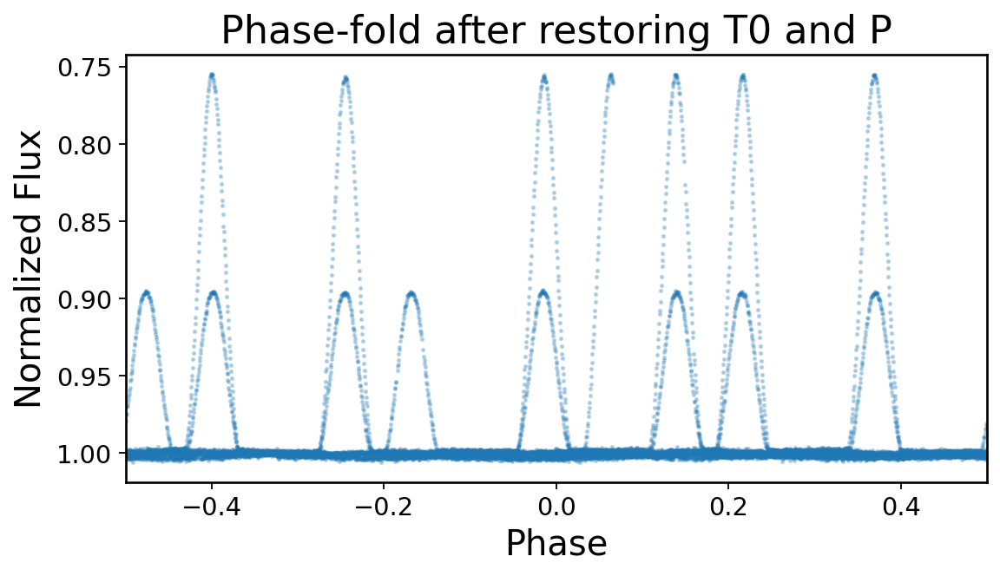

In [ ]:
phi = ((t - T0) / P + 0.5) % 1 - 0.5

plt.figure(figsize=(8,4))
plt.scatter(phi, flux_norm, s=2, alpha=0.25)
plt.xlim(-0.5, 0.5)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Phase-fold after restoring T0 and P")
plt.gca().invert_yaxis()
plt.show()

T0 = 1710.0111681704407
P = 2.9287911639400495
phi_shift = 0.013749999999999984
tf_raw min = 0.9135782512625308
tf_raw max = 1.083454893294486


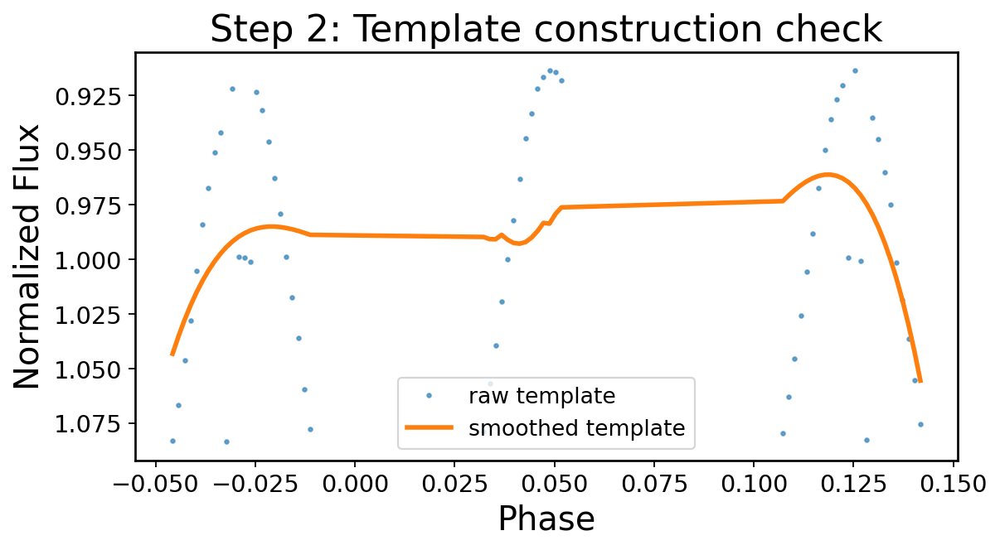

In [ ]:
tp_raw, tf_raw, phi_centered, phi_shift = build_primary_template(t, flux_norm, T0, P)
tp_smooth, tf_smooth = smooth_template(tp_raw, tf_raw)

print("T0 =", T0)
print("P =", P)
print("phi_shift =", phi_shift)
print("tf_raw min =", np.nanmin(tf_raw))
print("tf_raw max =", np.nanmax(tf_raw))

plt.figure(figsize=(8,4))
plt.plot(tp_raw, tf_raw, '.', ms=4, alpha=0.6, label='raw template')
plt.plot(tp_smooth, tf_smooth, '-', lw=2.5, label='smoothed template')
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Step 2: Template construction check")
plt.legend()
plt.gca().invert_yaxis()
plt.show()

In [ ]:
# Step 2: smart selection (phase + flux)

# Phase window around primary eclipse
phase_mask = np.abs(phi_centered) < 0.08

# Flux threshold (keep deeper points)
threshold = np.nanpercentile(flux, 20)

flux_mask = flux < threshold

# Combine both
m = phase_mask & flux_mask

phi_use = phi_centered[m]
flux_use = flux[m]

In [ ]:
# center again using median of selected eclipse points
phi_center_correction = np.nanmedian(phi_use)
phi_use = phi_use - phi_center_correction

In [ ]:
def build_primary_template(t, flux, T0, P, phase_halfwidth=0.15, nbins=200):
    import numpy as np

    # Fold into [-0.5, 0.5)
    phi = ((t - T0) / P + 0.5) % 1 - 0.5

    # Find the primary eclipse center from binned folded light curve
    coarse_bins = np.linspace(-0.5, 0.5, 401)
    coarse_centers = 0.5 * (coarse_bins[:-1] + coarse_bins[1:])
    digit = np.digitize(phi, coarse_bins) - 1

    coarse_med = np.array([
        np.nanmedian(flux[digit == i]) if np.any(digit == i) else np.nan
        for i in range(len(coarse_centers))
    ])

    # Since eclipse is a dip in flux, use nanargmin
    # Force selection of PRIMARY eclipse near phase 0
    search_mask = (coarse_centers > -0.1) & (coarse_centers < 0.1)

    phi_shift = coarse_centers[search_mask][
    np.nanargmin(coarse_med[search_mask])
]

    # Recenter so primary eclipse sits at phase 0
    phi_centered = ((phi - phi_shift + 0.5) % 1) - 0.5

    # Select only the deepest points (eclipse region)
    threshold = np.nanpercentile(flux, 5)  # lowest 5% of flux values

    m = flux < threshold

    phi_use = phi_centered[m]
    flux_use = flux[m]
    

    # Bin near eclipse
    bins = np.linspace(-phase_halfwidth, phase_halfwidth, nbins + 1)
    centers = 0.5 * (bins[:-1] + bins[1:])
    digit2 = np.digitize(phi_use, bins) - 1

    template_flux = np.array([
        np.nanmedian(flux_use[digit2 == i]) if np.any(digit2 == i) else np.nan
        for i in range(len(centers))
    ])

    good = np.isfinite(template_flux)
    template_phase = centers[good]
    template_flux = template_flux[good]

    # Normalize with out-of-eclipse baseline only
    out_mask = np.abs(template_phase) > 0.08
    if np.sum(out_mask) > 5:
        baseline = np.nanmedian(template_flux[out_mask])
        template_flux = template_flux / baseline

    return template_phase, template_flux, phi_centered, phi_shift

T0 = 1710.0111681704407
P = 2.9287911639400495
phi_shift = 0.013749999999999984
tf_raw min = 0.9135782512625308
tf_raw max = 1.083454893294486


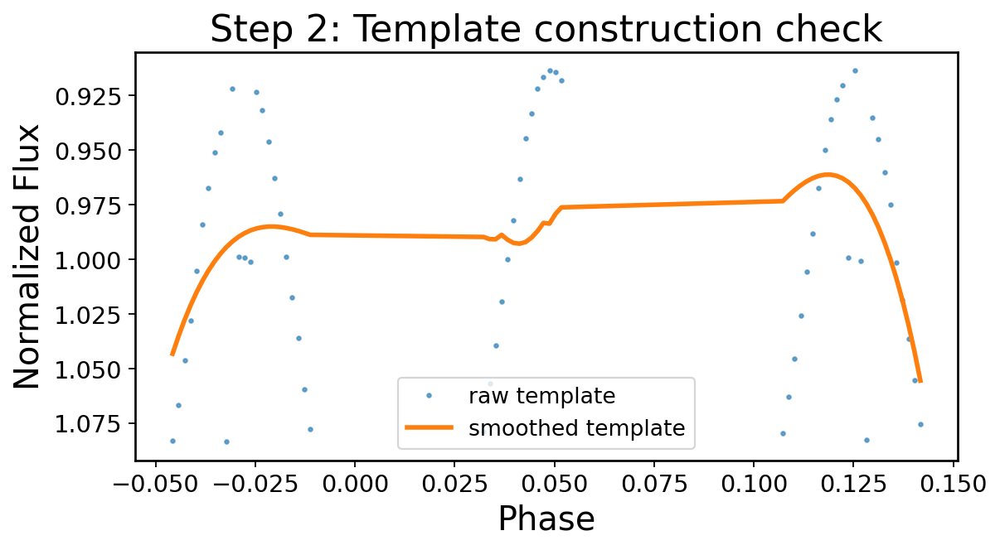

In [ ]:
tp_raw, tf_raw, phi_centered, phi_shift = build_primary_template(t, flux_norm, T0, P)
tp_smooth, tf_smooth = smooth_template(tp_raw, tf_raw)

print("T0 =", T0)
print("P =", P)
print("phi_shift =", phi_shift)
print("tf_raw min =", np.nanmin(tf_raw))
print("tf_raw max =", np.nanmax(tf_raw))

plt.figure(figsize=(8,4))
plt.plot(tp_raw, tf_raw, '.', ms=4, alpha=0.6, label='raw template')
plt.plot(tp_smooth, tf_smooth, '-', lw=2.5, label='smoothed template')
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Step 2: Template construction check")
plt.legend()
plt.gca().invert_yaxis()
plt.show()

In [ ]:
fits_path = "/mnt/md2/TESS_EBs/first1000/release/tess126602778.fits"

In [ ]:
from astropy.io import fits
import numpy as np

fits_path = "/mnt/md2/TESS_EBs/first1000/release/tess126602778.fits"

with fits.open(fits_path) as hdul:
    hdul.info()
    data = hdul[1].data

print("Columns:")
print(data.columns.names)

log_prob = np.array(data["log_prob"])
i_best = np.nanargmax(log_prob)
best_row = data[i_best]

print("\nBest sample index =", i_best)
print("Best log_prob =", log_prob[i_best])

print("\nBest-fit parameters:")
for name in data.columns.names:
    print(name, "=", best_row[name])

FileNotFoundError: [Errno 2] No such file or directory: '/mnt/md2/TESS_EBs/first1000/release/tess126602778.fits'

In [ ]:
import os

path = "/mnt/md2/TESS_EBs/first1000/release/tess126602778.fits"

print("exists:", os.path.exists(path))
print("readable:", os.access(path, os.R_OK))

exists: False
readable: False


In [ ]:
T0_guess = 1326.0794225723062
P_guess  = 0.7121058682846277

print("T0_guess =", T0_guess)
print("P_guess  =", P_guess)

T0_guess = 1326.0794225723062
P_guess  = 0.7121058682846277


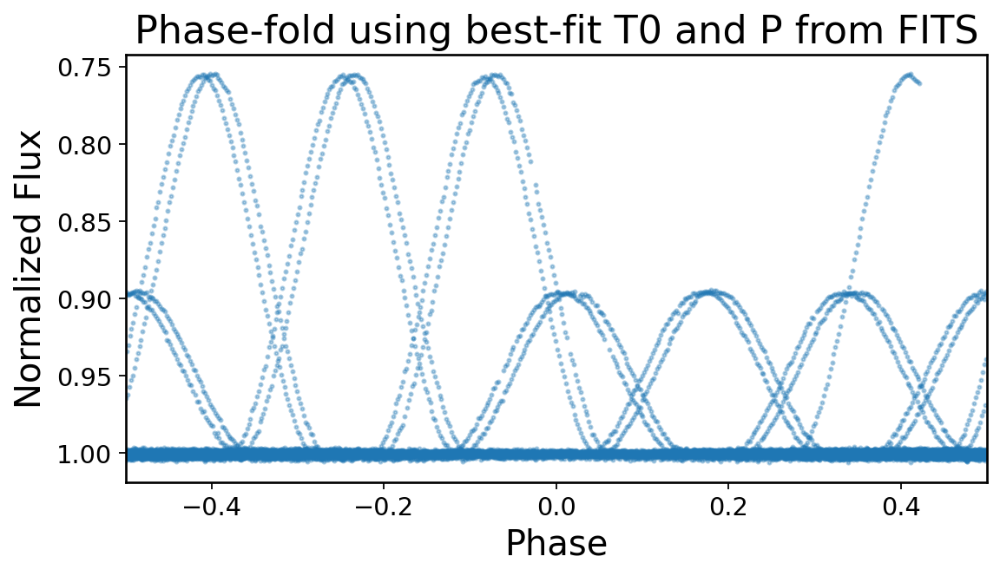

In [ ]:
phi = ((t - T0_guess) / P_guess + 0.5) % 1 - 0.5

plt.figure(figsize=(8,4))
plt.scatter(phi, flux_norm, s=3, alpha=0.35)
plt.xlim(-0.5, 0.5)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Phase-fold using best-fit T0 and P from FITS")
plt.gca().invert_yaxis()
plt.show()

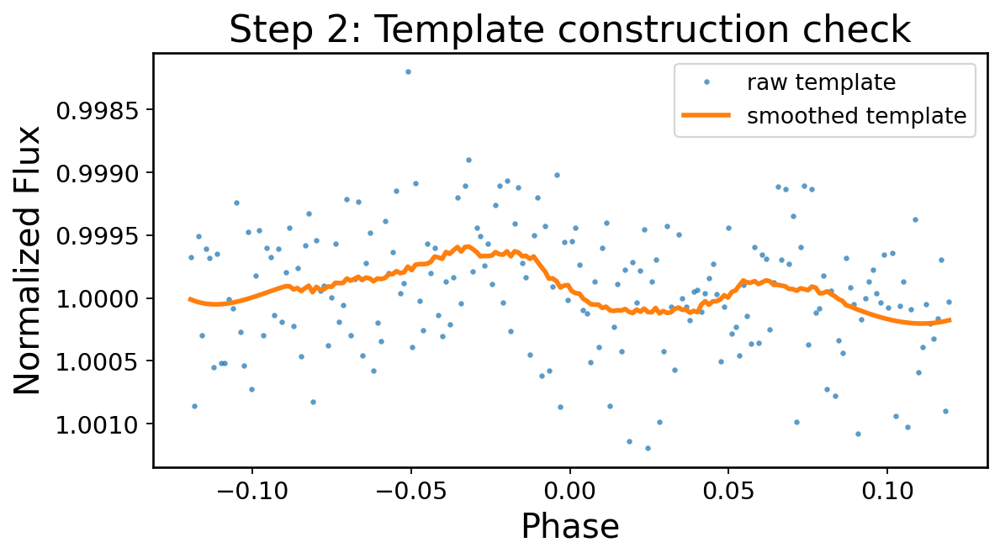

In [ ]:
tp_raw, tf_raw, phi_centered = build_primary_template(t, flux_norm, T0_guess, P_guess)
tp_smooth, tf_smooth = smooth_template(tp_raw, tf_raw)

plt.figure(figsize=(8,4))
plt.plot(tp_raw, tf_raw, '.', ms=4, alpha=0.6, label='raw template')
plt.plot(tp_smooth, tf_smooth, '-', lw=2.5, label='smoothed template')
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Step 2: Template construction check")
plt.legend()
plt.gca().invert_yaxis()
plt.show()

In [ ]:
def build_primary_template(t, flux, T0, P, width=0.08):
    # Phase
    phi = ((t - T0) / P + 0.5) % 1 - 0.5

    # Select ONLY primary eclipse region
    mask = np.abs(phi) < width

    phi_sel = phi[mask]
    flux_sel = flux[mask]

    # Sort by phase
    idx = np.argsort(phi_sel)
    phi_sel = phi_sel[idx]
    flux_sel = flux_sel[idx]

    return phi_sel, flux_sel, phi

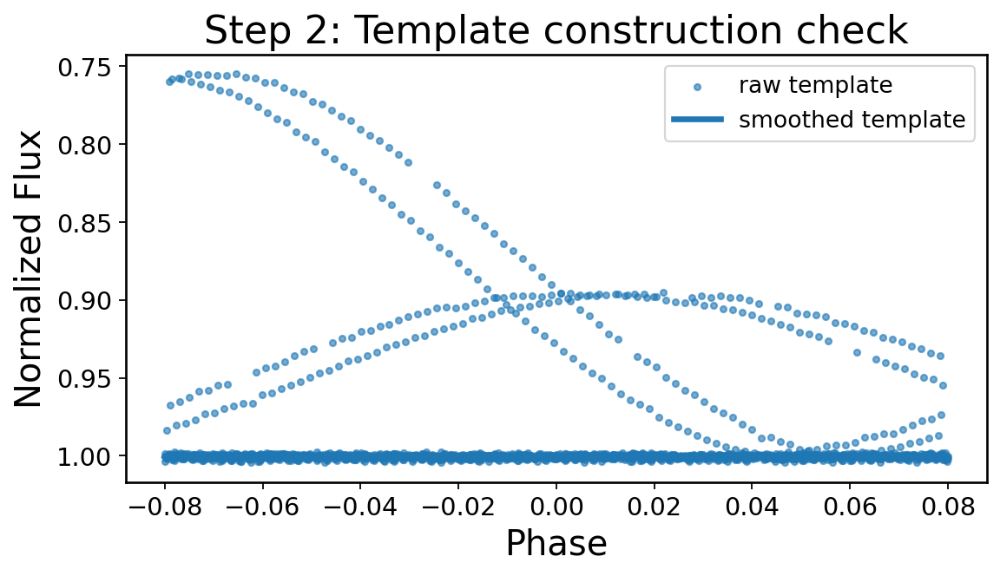

In [ ]:
tp_raw, tf_raw, _ = build_primary_template(t, flux_norm, T0_guess, P_guess)
tp_smooth, tf_smooth = smooth_template(tp_raw, tf_raw)

plt.figure(figsize=(8,4))
plt.scatter(tp_raw, tf_raw, s=10, alpha=0.6, label='raw template')
plt.plot(tp_smooth, tf_smooth, lw=3, label='smoothed template')

plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Step 2: Template construction check")
plt.legend()
plt.gca().invert_yaxis()
plt.show()

In [ ]:
def build_primary_template(t, flux, T0, P, width=0.08, depth_cut=0.995):
    # Phase fold
    phi = ((t - T0) / P + 0.5) % 1 - 0.5

    # Step 1: restrict to primary region
    mask_phase = np.abs(phi) < width

    phi_sel = phi[mask_phase]
    flux_sel = flux[mask_phase]

    # Step 2: REMOVE baseline (this is what you're missing)
    mask_depth = flux_sel < depth_cut

    phi_sel = phi_sel[mask_depth]
    flux_sel = flux_sel[mask_depth]

    # Step 3: sort
    idx = np.argsort(phi_sel)
    phi_sel = phi_sel[idx]
    flux_sel = flux_sel[idx]

    return phi_sel, flux_sel, phi

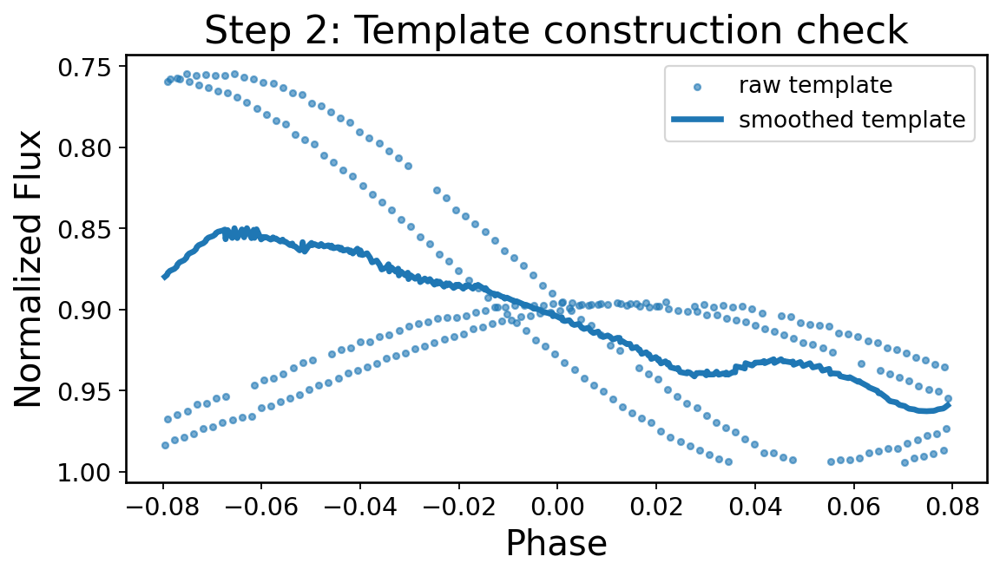

In [ ]:
tp_raw, tf_raw, _ = build_primary_template(t, flux_norm, T0_guess, P_guess)

tp_smooth, tf_smooth = smooth_template(tp_raw, tf_raw)

plt.figure(figsize=(8,4))
plt.scatter(tp_raw, tf_raw, s=10, alpha=0.6, label='raw template')
plt.plot(tp_smooth, tf_smooth, lw=3, label='smoothed template')

plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Step 2: Template construction check")
plt.legend()
plt.gca().invert_yaxis()
plt.show()

In [ ]:
# take a clean subset (first 20% of data)
n = len(t)
subset = slice(0, int(0.2 * n))

t_sub = t[subset]
flux_sub = flux_norm[subset]

In [ ]:
tp_raw, tf_raw, _ = build_primary_template(t_sub, flux_sub, T0_guess, P_guess)
tp_smooth, tf_smooth = smooth_template(tp_raw, tf_raw)

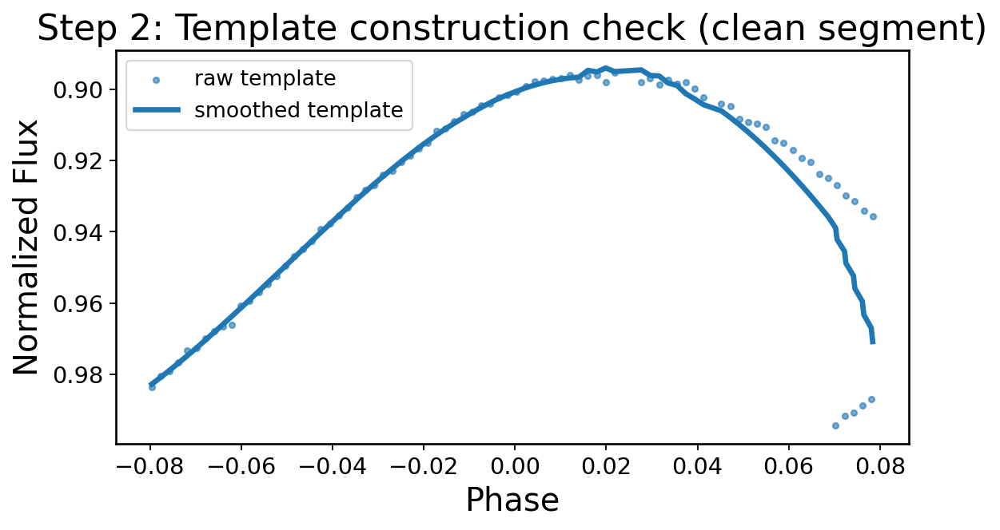

In [ ]:
plt.figure(figsize=(8,4))
plt.scatter(tp_raw, tf_raw, s=10, alpha=0.6, label='raw template')
plt.plot(tp_smooth, tf_smooth, lw=3, label='smoothed template')

plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Step 2: Template construction check (clean segment)")
plt.legend()
plt.gca().invert_yaxis()
plt.show()

In [ ]:
# find minimum of smoothed template
i_min = np.argmin(tf_smooth)
phi_min = tp_smooth[i_min]

# shift everything so minimum is at 0
tp_raw -= phi_min
tp_smooth -= phi_min

In [ ]:
def build_primary_template(t, flux, T0, P, width=0.08, depth_cut=0.995):
    # Phase fold
    phi = ((t - T0) / P + 0.5) % 1 - 0.5

    # Step 1: restrict to primary region
    mask_phase = np.abs(phi) < width

    phi_sel = phi[mask_phase]
    flux_sel = flux[mask_phase]

    # Step 2: REMOVE baseline (this is what you're missing)
    mask_depth = flux_sel < depth_cut

    phi_sel = phi_sel[mask_depth]
    flux_sel = flux_sel[mask_depth]

    # Step 3: sort
    idx = np.argsort(phi_sel)
    phi_sel = phi_sel[idx]
    flux_sel = flux_sel[idx]

    return phi_sel, flux_sel, phi

In [ ]:
# find minimum of smoothed template
i_min = np.argmin(tf_smooth)
phi_min = tp_smooth[i_min]

# shift everything so minimum is at 0
tp_raw -= phi_min
tp_smooth -= phi_min

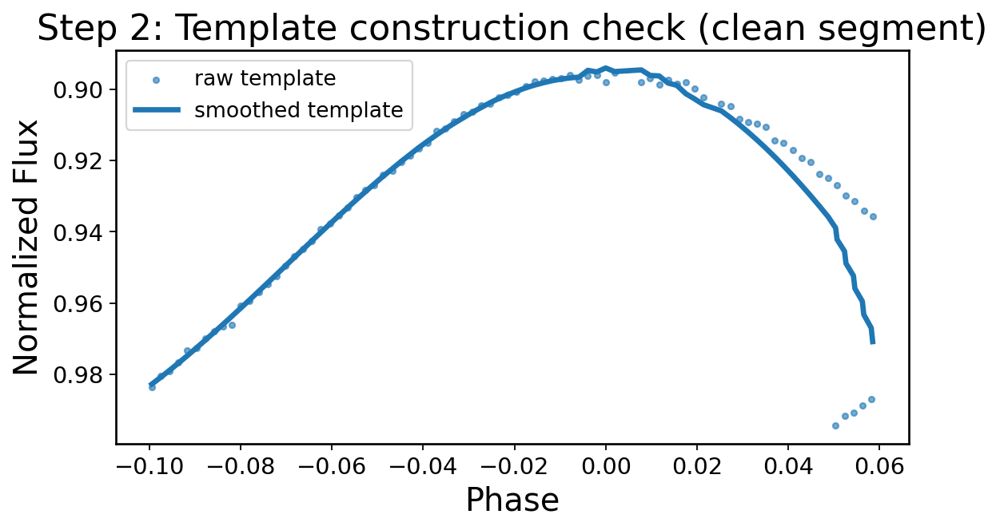

In [ ]:
plt.figure(figsize=(8,4))
plt.scatter(tp_raw, tf_raw, s=10, alpha=0.6, label='raw template')
plt.plot(tp_smooth, tf_smooth, lw=3, label='smoothed template')

plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Step 2: Template construction check (clean segment)")
plt.legend()
plt.gca().invert_yaxis()
plt.show()

In [ ]:
from scipy.interpolate import interp1d
import numpy as np

def measure_primary_timings(t, flux, T0, P, tp_template, tf_template, width=0.08):
    
    # interpolate template
    template_interp = interp1d(tp_template, tf_template,
                               bounds_error=False,
                               fill_value="extrapolate")

    timings = []
    epochs = []

    # estimate number of orbits
    n_min = int((t.min() - T0) / P) - 1
    n_max = int((t.max() - T0) / P) + 1

    for n in range(n_min, n_max):

        t_pred = T0 + n * P

        # select data near this eclipse
        mask = np.abs(t - t_pred) < width * P
        if np.sum(mask) < 10:
            continue

        t_seg = t[mask]
        f_seg = flux[mask]

        # convert to phase
        phi_seg = (t_seg - t_pred) / P

        # center data around 0
        phi_seg = phi_seg - np.mean(phi_seg)

        # grid of shifts
        shifts = np.linspace(-0.01, 0.01, 200)
        chi2 = []

        for s in shifts:
            model = template_interp(phi_seg - s)
            chi2.append(np.nanmedian((f_seg - model)**2))

        best_shift = shifts[np.argmin(chi2)]

        t_meas = t_pred + best_shift * P

        timings.append(t_meas)
        epochs.append(n)

    return np.array(epochs), np.array(timings)

In [ ]:
epochs, timings = measure_primary_timings(
    t, flux_norm,
    T0_guess, P_guess,
    tp_smooth, tf_smooth
)

RMS (seconds): 21.214639453291255


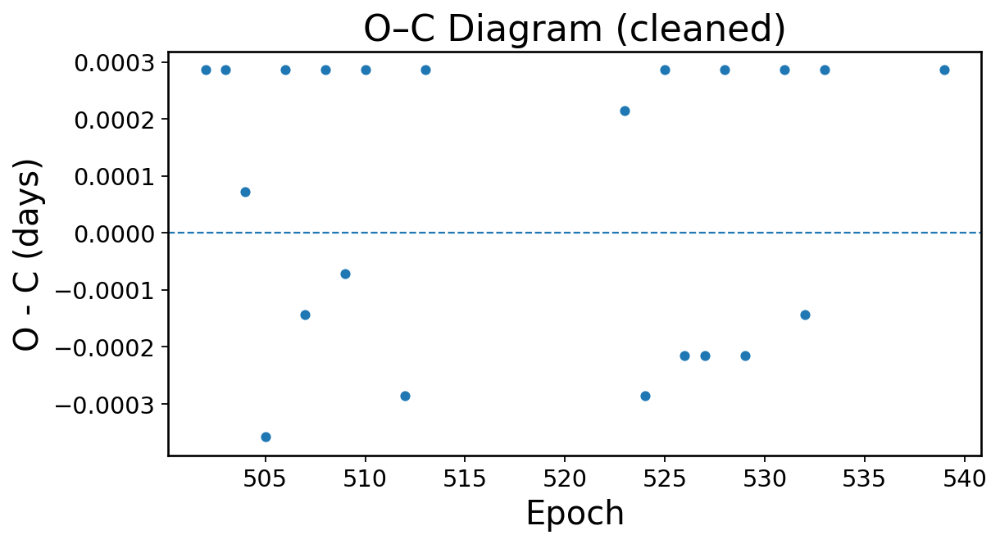

In [ ]:
OC = timings - (T0_guess + epochs * P_guess)

# REMOVE offset
OC = OC - np.median(OC)

mask = np.abs(OC) < 0.001   # tighter cut
epochs_clean = epochs[mask]
OC_clean = OC[mask]

print("RMS (seconds):", np.std(OC_clean) * 86400)

plt.figure(figsize=(8,4))
plt.scatter(epochs_clean, OC_clean, s=20)

plt.axhline(0, linestyle='--', linewidth=1)
plt.xlabel("Epoch")
plt.ylabel("O - C (days)")
plt.title("O–C Diagram (cleaned)")
plt.show()

In [ ]:
rms_sec = np.std(OC_clean) * 86400
print(f"Timing precision: {rms_sec:.2f} seconds")

Timing precision: 21.21 seconds


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def split_into_chunks(t, gap_days=5.0):
    dt = np.diff(t)
    breaks = np.where(dt > gap_days)[0]
    segments = np.split(np.arange(len(t)), breaks + 1)
    return segments

segments = split_into_chunks(t, gap_days=0.5)

print("Number of chunks:", len(segments))
for i, seg in enumerate(segments):
    print(f"Chunk {i}: N={len(seg)}, t=[{t[seg][0]:.3f}, {t[seg][-1]:.3f}]")

Number of chunks: 4
Chunk 0: N=5885, t=[1683.355, 1691.654]
Chunk 1: N=465, t=[1695.742, 1696.390]
Chunk 2: N=5884, t=[1697.345, 1705.595]
Chunk 3: N=190, t=[1709.942, 1710.205]


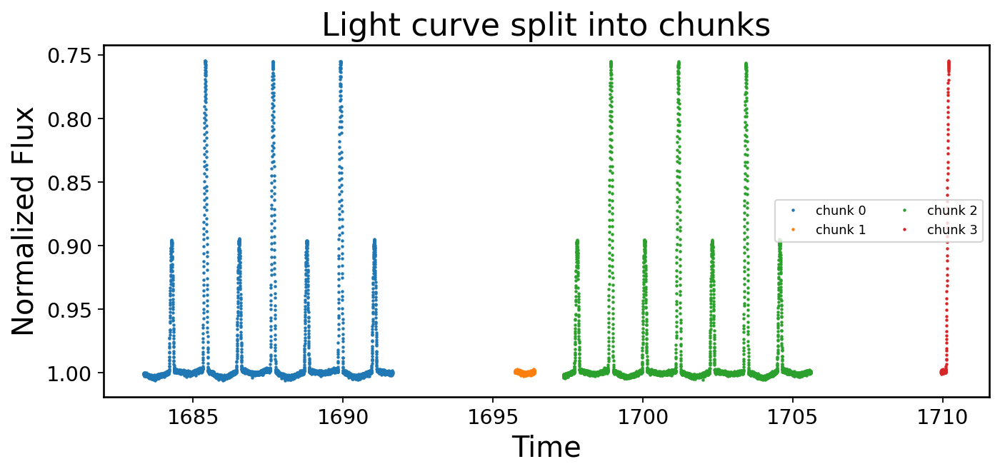

In [ ]:
plt.figure(figsize=(10,4))

for i, seg in enumerate(segments):
    plt.plot(t[seg], flux_norm[seg], ".", ms=2, label=f"chunk {i}")

plt.xlabel("Time")
plt.ylabel("Normalized Flux")
plt.title("Light curve split into chunks")
plt.gca().invert_yaxis()
plt.legend(ncol=2, fontsize=8)
plt.show()

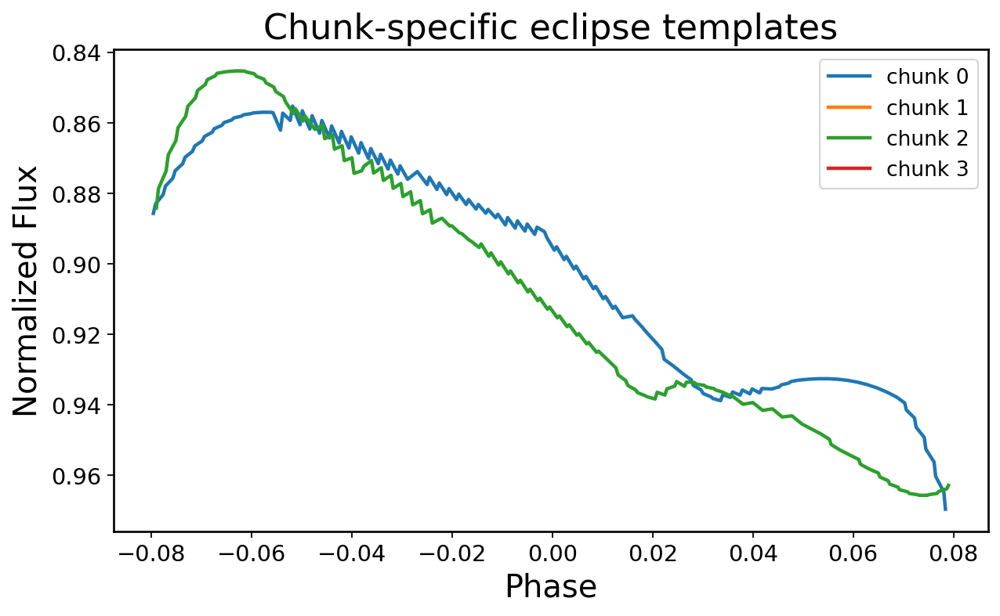

In [ ]:
chunk_templates = []

plt.figure(figsize=(9,5))

for i, seg in enumerate(segments):
    t_seg = t[seg]
    f_seg = flux_norm[seg]

    # skip tiny chunks
    if len(t_seg) < 100:
        print(f"Chunk {i}: skipped (too few points)")
        continue

    tp_raw, tf_raw, _ = build_primary_template(t_seg, f_seg, T0_guess, P_guess)
    tp_smooth, tf_smooth = smooth_template(tp_raw, tf_raw)

    chunk_templates.append({
        "chunk": i,
        "t": t_seg,
        "flux": f_seg,
        "tp_raw": tp_raw,
        "tf_raw": tf_raw,
        "tp_smooth": tp_smooth,
        "tf_smooth": tf_smooth
    })

    plt.plot(tp_smooth, tf_smooth, lw=2, label=f"chunk {i}")

plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Chunk-specific eclipse templates")
plt.gca().invert_yaxis()
plt.legend()
plt.show()

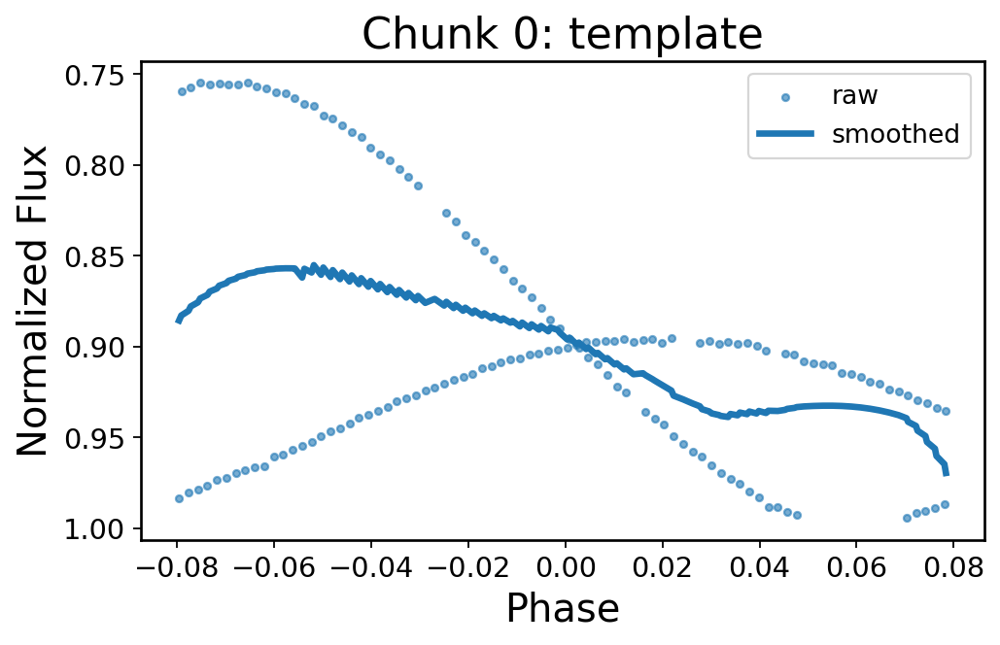

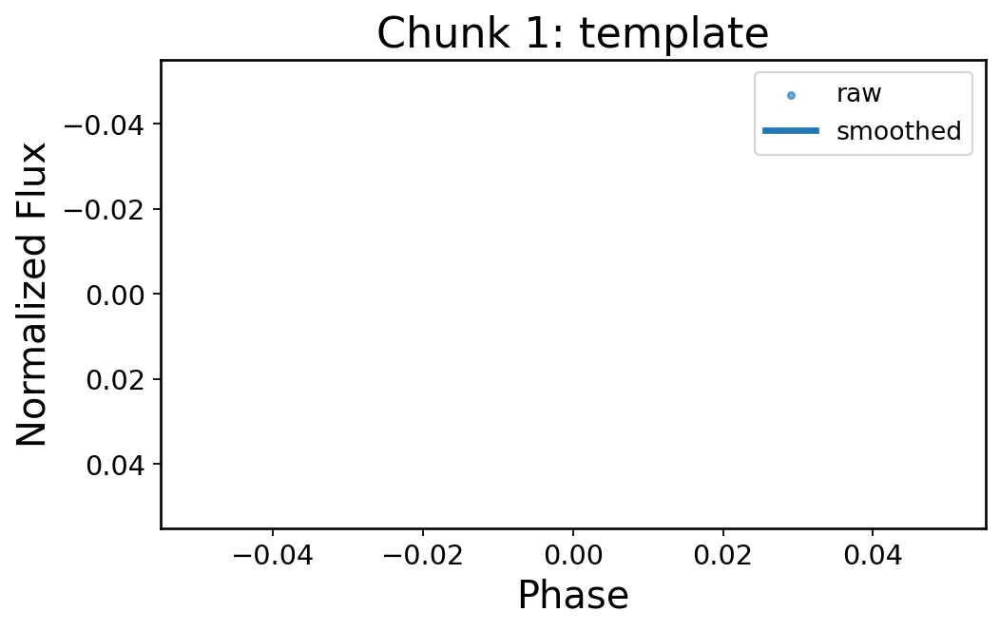

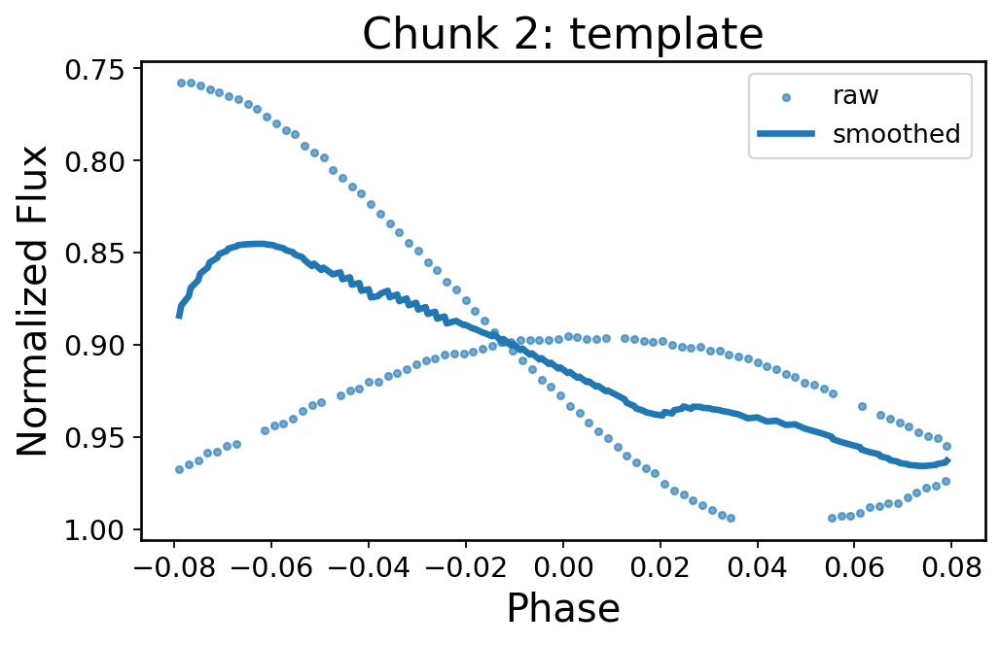

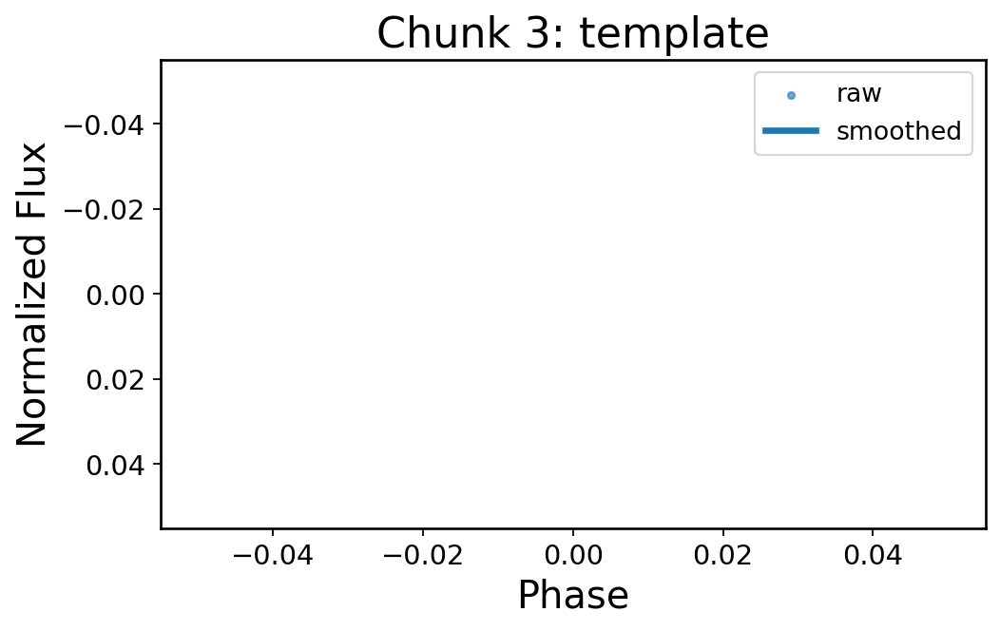

In [ ]:
for item in chunk_templates:
    i = item["chunk"]

    plt.figure(figsize=(7,4))
    plt.scatter(item["tp_raw"], item["tf_raw"], s=10, alpha=0.6, label="raw")
    plt.plot(item["tp_smooth"], item["tf_smooth"], lw=3, label="smoothed")
    plt.xlabel("Phase")
    plt.ylabel("Normalized Flux")
    plt.title(f"Chunk {i}: template")
    plt.gca().invert_yaxis()
    plt.legend()
    plt.show()

In [ ]:
chunk_results = []

for item in chunk_templates:
    i = item["chunk"]
    t_seg = item["t"]
    f_seg = item["flux"]
    tp_smooth = item["tp_smooth"]
    tf_smooth = item["tf_smooth"]

    epochs_seg, timings_seg = measure_primary_timings(
        t_seg, f_seg,
        T0_guess, P_guess,
        tp_smooth, tf_smooth
    )

    OC_seg = timings_seg - (T0_guess + epochs_seg * P_guess)
    OC_seg = OC_seg - np.median(OC_seg)

    chunk_results.append({
        "chunk": i,
        "epochs": epochs_seg,
        "timings": timings_seg,
        "OC": OC_seg
    })

    print(f"Chunk {i}: {len(epochs_seg)} timings")

Chunk 0: 12 timings


ValueError: cannot reshape array of size 0 into shape (0,newaxis)

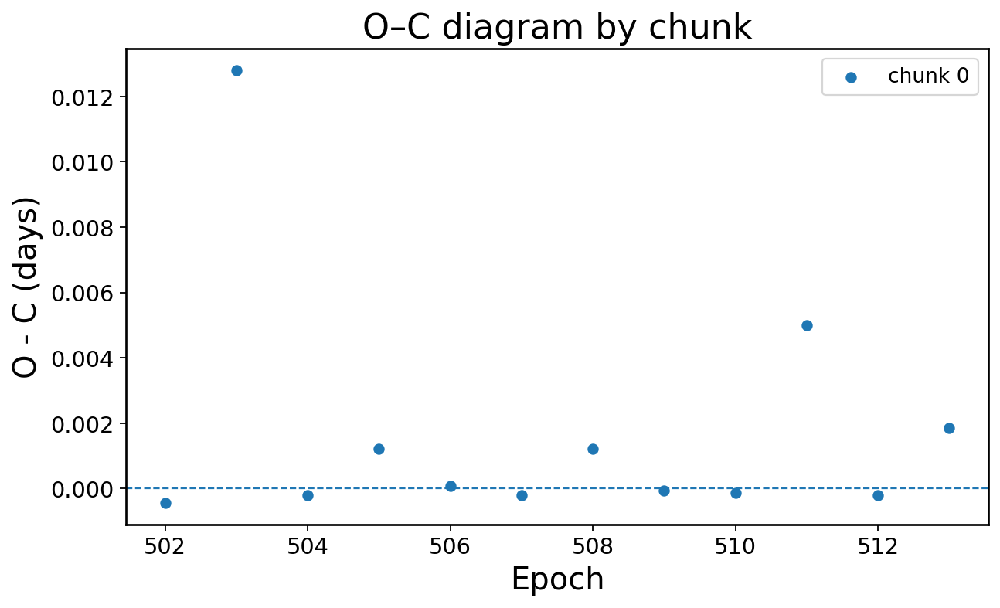

In [ ]:
plt.figure(figsize=(9,5))

for result in chunk_results:
    plt.scatter(result["epochs"], result["OC"], s=30, label=f"chunk {result['chunk']}")

plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Epoch")
plt.ylabel("O - C (days)")
plt.title("O–C diagram by chunk")
plt.legend()
plt.show()

In [ ]:
for result in chunk_results:
    OC = result["OC"]
    if len(OC) > 1:
        rms_sec = np.std(OC) * 86400
        print(f"Chunk {result['chunk']}: RMS = {rms_sec:.2f} sec, N = {len(OC)}")
    else:
        print(f"Chunk {result['chunk']}: not enough timings")

Chunk 0: RMS = 315.09 sec, N = 12


In [ ]:
chunk_templates = []

for i, seg in enumerate(segments):
    t_seg = t[seg]
    f_seg = flux_norm[seg]

    # ❌ FIX 3: drop bad/small chunks
    if len(t_seg) < 500:
        print(f"Chunk {i}: skipped (too few points)")
        continue

    # Compute phase
    phase = (t_seg - T0_guess) / P_guess

    # Wrap to [-0.5, 0.5]
    phase = phase - np.round(phase)

    # Phase window
    mask = (phase > -0.05) & (phase < 0.05)

    # Keep ONLY deepest 20% → isolates core of eclipse
    depth_cut = np.percentile(f_seg[mask], 20)
    mask = mask & (f_seg < depth_cut)

    # Remove edges where phase density is low
    valid = (phase_sel > -0.04) & (phase_sel < 0.04)

    phase_sel = phase_sel[valid]
    flux_sel = flux_sel[valid]

    phase_sel = phase[mask]
    flux_sel = f_seg[mask]

    # Remove local linear trend (baseline)
    coeffs = np.polyfit(phase_sel, flux_sel, deg=1)
    trend = np.polyval(coeffs, phase_sel)


    # ✅ CENTER the eclipse at its minimum
    min_idx = np.argmin(flux_sel)
    phase_center = phase_sel[min_idx]

    phase_sel = phase_sel - phase_center

    # THEN sort
    idx = np.argsort(phase_sel)
    phase_sel = phase_sel[idx]
    flux_sel = flux_sel[idx]

    # Sort for clean template
    idx = np.argsort(phase_sel)
    phase_sel = phase_sel[idx]
    flux_sel = flux_sel[idx]

    from scipy.signal import savgol_filter

    # Ensure window is valid
    window_length = min(31, len(flux_sel) - 1)
    if window_length % 2 == 0:
        window_length -= 1

    smooth_flux = savgol_filter(flux_sel, window_length=window_length, polyorder=2)

    chunk_templates.append({
        "chunk": i,
        "phase": phase_sel,
        "flux_raw": flux_sel,
        "flux_smooth": smooth_flux,
        "t": t_seg,
        "flux_full": f_seg
    })

    print(f"Chunk {i}: template built with {len(phase_sel)} points")

Chunk 0: template built with 120 points
Chunk 1: skipped (too few points)
Chunk 2: template built with 113 points
Chunk 3: skipped (too few points)


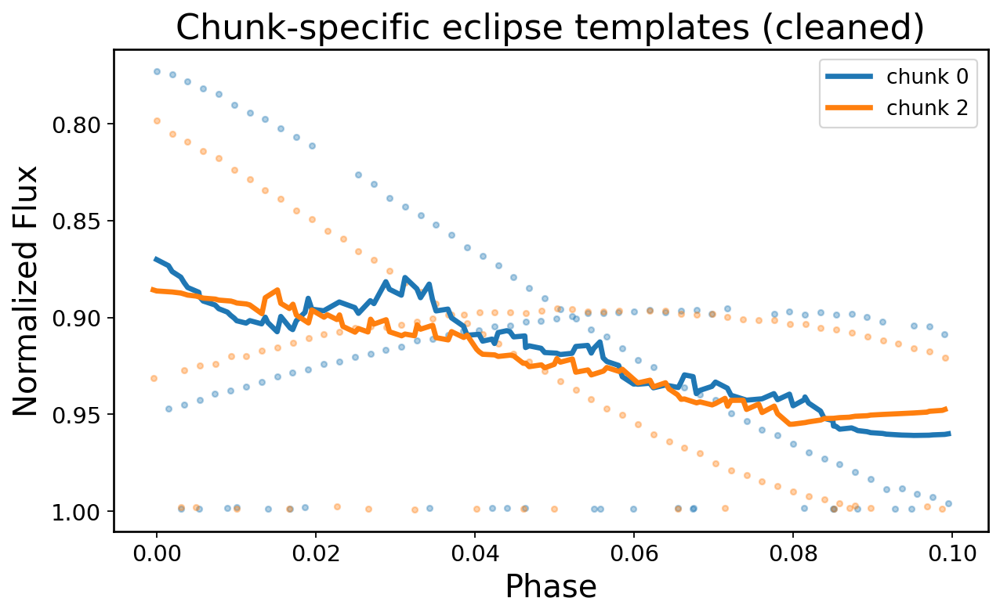

In [ ]:
plt.figure(figsize=(9,5))

for item in chunk_templates:
    plt.scatter(item["phase"], item["flux_raw"], s=10, alpha=0.35)
    plt.plot(item["phase"], item["flux_smooth"], lw=3, label=f"chunk {item['chunk']}")

plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Chunk-specific eclipse templates (cleaned)")
plt.gca().invert_yaxis()
plt.legend()
plt.show()

In [ ]:
chunk_results = []

for item in chunk_templates:
    i = item["chunk"]
    t_seg = item["t"]
    f_seg = item["flux_full"]

    tp_template = item["phase"]
    tf_template = item["flux_smooth"]

    epochs_seg, timings_seg = measure_primary_timings(
        t_seg, f_seg,
        T0_guess, P_guess,
        tp_template, tf_template
    )

    OC_seg = timings_seg - (T0_guess + epochs_seg * P_guess)
    OC_seg = OC_seg - np.median(OC_seg)

    chunk_results.append({
        "chunk": i,
        "epochs": epochs_seg,
        "timings": timings_seg,
        "OC": OC_seg
    })

    print(f"Chunk {i}: {len(epochs_seg)} timings")

Chunk 0: 12 timings
Chunk 2: 11 timings


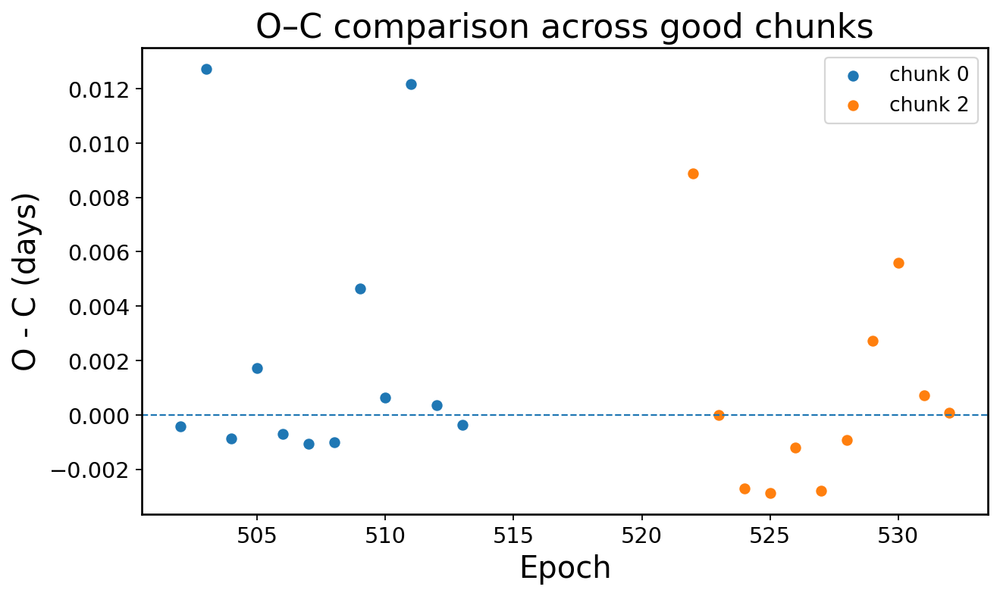

In [ ]:
plt.figure(figsize=(9,5))

for result in chunk_results:
    plt.scatter(result["epochs"], result["OC"], s=30, label=f"chunk {result['chunk']}")

plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Epoch")
plt.ylabel("O - C (days)")
plt.title("O–C comparison across good chunks")
plt.legend()
plt.show()

In [ ]:
chunk_templates = []

for i, seg in enumerate(segments):
    t_seg = t[seg]
    f_seg = flux_norm[seg]

    # ❌ FIX 3: drop bad/small chunks
    if len(t_seg) < 500:
        print(f"Chunk {i}: skipped (too few points)")
        continue

# --- Phase computation ---
phase = (t_seg - T0_guess) / P_guess
phase = phase - np.round(phase)

# --- Initial eclipse window ---
mask = (phase > -0.08) & (phase < 0.08)

# --- Depth filter (keep only eclipse points) ---
depth_cut = np.percentile(f_seg[mask], 10)
mask = mask & (f_seg < depth_cut)

phase_sel = phase[mask]
flux_sel = f_seg[mask]

# 🚨 IMPORTANT: sort BEFORE anything else
order = np.argsort(phase_sel)
phase_sel = phase_sel[order]
flux_sel = flux_sel[order]

# --- DETREND (this must happen AFTER sorting) ---
coeffs = np.polyfit(phase_sel, flux_sel, deg=1)
trend = np.polyval(coeffs, phase_sel)
flux_sel = flux_sel - trend + np.mean(trend)

# --- Center eclipse ---
min_idx = np.argmin(flux_sel)
phase_center = phase_sel[min_idx]
phase_sel = phase_sel - phase_center

# --- Tight window AFTER centering ---
valid = (phase_sel > -0.04) & (phase_sel < 0.04)
phase_sel = phase_sel[valid]
flux_sel = flux_sel[valid]

# --- Smooth ---
from scipy.signal import savgol_filter
if len(flux_sel) > 31:
    flux_smooth = savgol_filter(flux_sel, 31, 2)
else:
    flux_smooth = flux_sel

chunk_templates.append({
        "chunk": i,
        "phase": phase_sel,
        "flux_raw": flux_sel,
        "flux_smooth": smooth_flux,
        "t": t_seg,
        "flux_full": f_seg
    })

print(f"Chunk {i}: template built with {len(phase_sel)} points")

Chunk 1: skipped (too few points)
Chunk 3: skipped (too few points)
Chunk 3: template built with 2 points


Number of chunks: 4
Chunk 0: N=5885, t=[1683.35507, 1691.65361]
Chunk 1: N=465, t=[1695.74246, 1696.38968]
Chunk 2: N=5884, t=[1697.34523, 1705.59512]
Chunk 3: N=190, t=[1709.94229, 1710.20479]


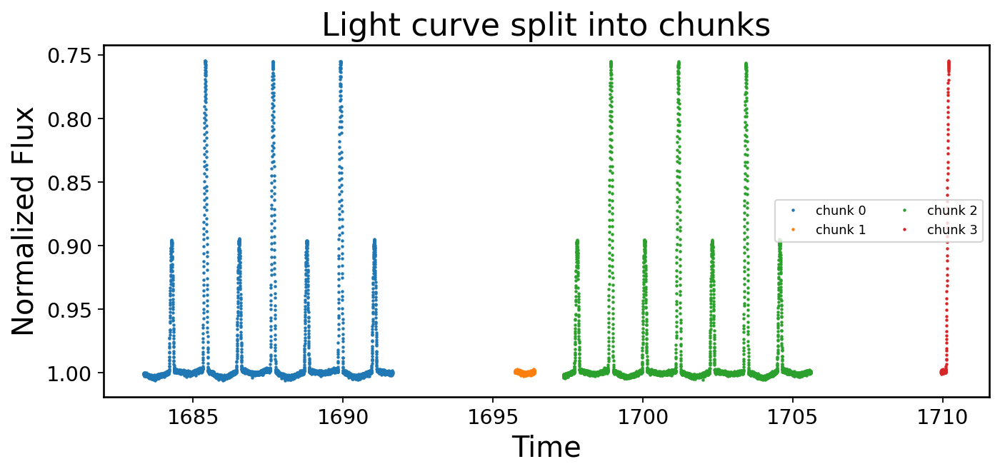

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

# If your normalized flux array is named `flux`, this keeps the later cells readable.
flux_norm = np.array(flux, copy=True)

def split_into_chunks(t, gap_days=0.2):
    dt = np.diff(t)
    breaks = np.where(dt > gap_days)[0]
    return np.split(np.arange(len(t)), breaks + 1)

segments = split_into_chunks(t, gap_days=0.2)

print("Number of chunks:", len(segments))
for i, seg in enumerate(segments):
    print(f"Chunk {i}: N={len(seg)}, t=[{t[seg][0]:.5f}, {t[seg][-1]:.5f}]")

plt.figure(figsize=(10,4))
for i, seg in enumerate(segments):
    plt.plot(t[seg], flux_norm[seg], ".", ms=2, label=f"chunk {i}")
plt.xlabel("Time")
plt.ylabel("Normalized Flux")
plt.title("Light curve split into chunks")
plt.gca().invert_yaxis()
plt.legend(ncol=2, fontsize=8)
plt.show()


In [ ]:

def build_clean_primary_template(t_seg, f_seg, T0, P,
                                 phase_halfwidth=0.08,
                                 phase_core=0.05,
                                 depth_percentile=20,
                                 final_halfwidth=0.04,
                                 smooth_window=31,
                                 polyorder=2):
    """
    Build a chunk-specific primary-eclipse template.

    Strategy:
    - fold to phase in [-0.5, 0.5)
    - restrict to the primary eclipse neighborhood
    - keep only the deepest points to suppress baseline/secondary contamination
    - recenter on the minimum
    - trim to a tight symmetric window
    - smooth with Savitzky-Golay
    """
    # Phase in [-0.5, 0.5)
    phase = (t_seg - T0) / P
    phase = phase - np.round(phase)

    # Broad primary window
    mask0 = (phase > -phase_halfwidth) & (phase < phase_halfwidth)
    if np.sum(mask0) < 20:
        return None

    phase0 = phase[mask0]
    flux0 = f_seg[mask0]

    # Keep only the deeper eclipse points
    core_cut = np.percentile(flux0, depth_percentile)
    mask1 = flux0 < core_cut
    phase1 = phase0[mask1]
    flux1 = flux0[mask1]

    if len(phase1) < max(25, polyorder + 5):
        return None

    # Center at deepest point
    imin = np.argmin(flux1)
    phase_center = phase1[imin]
    phase1 = phase1 - phase_center

    # Tight symmetric window around the centered eclipse
    mask2 = (phase1 > -final_halfwidth) & (phase1 < final_halfwidth)
    phase2 = phase1[mask2]
    flux2 = flux1[mask2]

    if len(phase2) < max(25, polyorder + 5):
        return None

    # Sort
    order = np.argsort(phase2)
    phase2 = phase2[order]
    flux2 = flux2[order]

    # Smooth
    window = min(smooth_window, len(flux2) if len(flux2) % 2 == 1 else len(flux2)-1)
    if window < polyorder + 3:
        flux_smooth = flux2.copy()
    else:
        if window % 2 == 0:
            window -= 1
        flux_smooth = savgol_filter(flux2, window_length=window, polyorder=polyorder)

    return {
        "phase_raw": phase2,
        "flux_raw": flux2,
        "phase_smooth": phase2,
        "flux_smooth": flux_smooth,
    }


Chunk 1: skipped (too few points)
Chunk 3: skipped (too few points)


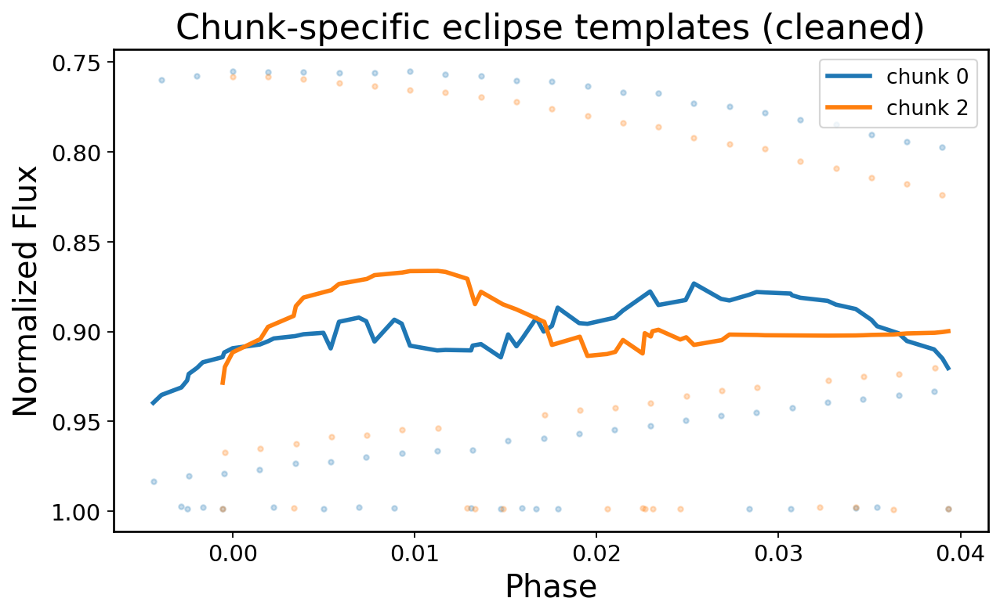


Good chunks used: [0, 2]


In [ ]:

chunk_templates = []

plt.figure(figsize=(9,5))

for i, seg in enumerate(segments):
    t_seg = t[seg]
    f_seg = flux_norm[seg]

    # Drop tiny/bad chunks automatically
    if len(t_seg) < 500:
        print(f"Chunk {i}: skipped (too few points)")
        continue

    tpl = build_clean_primary_template(t_seg, f_seg, T0_guess, P_guess)
    if tpl is None:
        print(f"Chunk {i}: skipped (insufficient eclipse points)")
        continue

    chunk_templates.append({
        "chunk": i,
        "t": t_seg,
        "flux_full": f_seg,
        **tpl
    })

    plt.scatter(tpl["phase_raw"], tpl["flux_raw"], s=8, alpha=0.25)
    plt.plot(tpl["phase_smooth"], tpl["flux_smooth"], lw=2.5, label=f"chunk {i}")

plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Chunk-specific eclipse templates (cleaned)")
plt.gca().invert_yaxis()
plt.legend()
plt.show()

print("\nGood chunks used:", [item["chunk"] for item in chunk_templates])


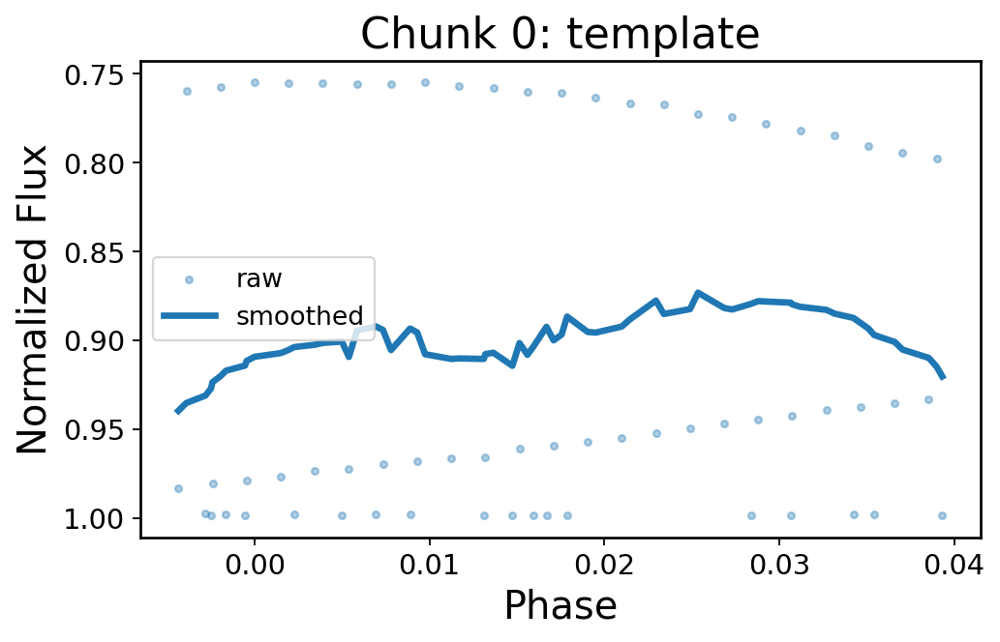

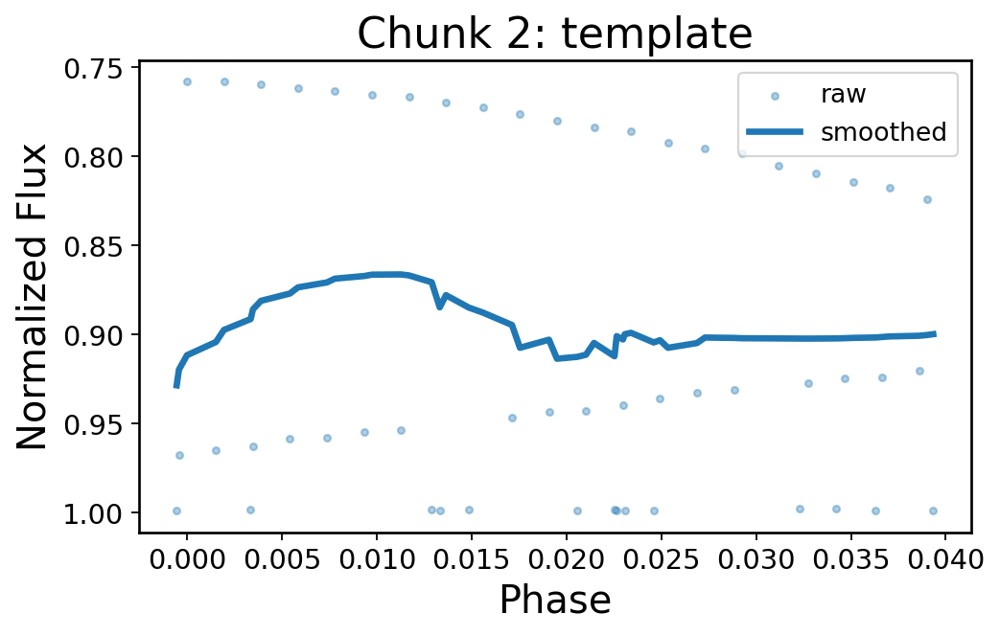

In [ ]:

for item in chunk_templates:
    i = item["chunk"]
    plt.figure(figsize=(7,4))
    plt.scatter(item["phase_raw"], item["flux_raw"], s=10, alpha=0.35, label="raw")
    plt.plot(item["phase_smooth"], item["flux_smooth"], lw=3, label="smoothed")
    plt.xlabel("Phase")
    plt.ylabel("Normalized Flux")
    plt.title(f"Chunk {i}: template")
    plt.gca().invert_yaxis()
    plt.legend()
    plt.show()


In [ ]:

from scipy.interpolate import interp1d

def measure_primary_timings_chunk(t_seg, f_seg, T0, P, tp_template, tf_template,
                                  width=0.08, shift_half_range=0.01, ngrid=200):
    interp_template = interp1d(tp_template, tf_template, bounds_error=False, fill_value="extrapolate")

    epochs = []
    timings = []

    n_min = int((t_seg.min() - T0) / P) - 1
    n_max = int((t_seg.max() - T0) / P) + 1

    for n in range(n_min, n_max + 1):
        t_pred = T0 + n * P
        mask = np.abs(t_seg - t_pred) < width * P
        if np.sum(mask) < 10:
            continue

        tt = t_seg[mask]
        ff = f_seg[mask]
        phi_seg = (tt - t_pred) / P

        shifts = np.linspace(-shift_half_range, shift_half_range, ngrid)
        loss = []
        for s in shifts:
            model = interp_template(phi_seg - s)
            loss.append(np.nanmedian((ff - model)**2))

        best_shift = shifts[np.argmin(loss)]
        t_meas = t_pred + best_shift * P

        epochs.append(n)
        timings.append(t_meas)

    return np.array(epochs), np.array(timings)


In [ ]:

chunk_results = []

for item in chunk_templates:
    i = item["chunk"]

    epochs_seg, timings_seg = measure_primary_timings_chunk(
        item["t"], item["flux_full"],
        T0_guess, P_guess,
        item["phase_smooth"], item["flux_smooth"]
    )

    if len(epochs_seg) == 0:
        print(f"Chunk {i}: no timings")
        continue

    OC_seg = timings_seg - (T0_guess + epochs_seg * P_guess)
    OC_seg = OC_seg - np.median(OC_seg)

    # Mild outlier filter for display / RMS
    if len(OC_seg) > 2:
        keep = np.abs(OC_seg - np.median(OC_seg)) < 3 * np.std(OC_seg)
        epochs_seg = epochs_seg[keep]
        timings_seg = timings_seg[keep]
        OC_seg = OC_seg[keep]

    chunk_results.append({
        "chunk": i,
        "epochs": epochs_seg,
        "timings": timings_seg,
        "OC": OC_seg
    })

    rms_sec = np.std(OC_seg) * 86400 if len(OC_seg) > 1 else np.nan
    print(f"Chunk {i}: N={len(epochs_seg)}, RMS={rms_sec:.2f} sec")


Chunk 0: N=12, RMS=383.80 sec
Chunk 2: N=12, RMS=260.35 sec


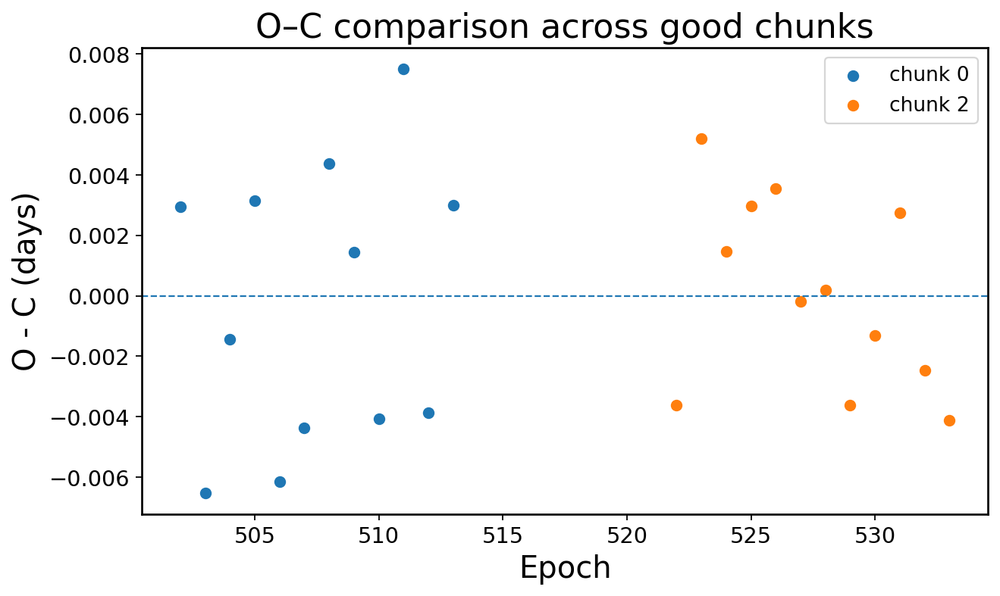

In [ ]:

plt.figure(figsize=(9,5))

for result in chunk_results:
    plt.scatter(result["epochs"], result["OC"], s=35, label=f"chunk {result['chunk']}")

plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Epoch")
plt.ylabel("O - C (days)")
plt.title("O–C comparison across good chunks")
plt.legend()
plt.show()


In [ ]:
chunk_templates = []

for i, seg in enumerate(segments):

    t_seg = t[seg]
    f_seg = flux_norm[seg]

    # --- Find deepest point (true eclipse center) ---
    min_idx_global = np.argmin(f_seg)
    t_min = t_seg[min_idx_global]

    # --- Define local window around eclipse ---
    window = 0.08 * P_guess
    mask = np.abs(t_seg - t_min) < window

    # --- Define phase relative to eclipse center ---
    phase = (t_seg - t_min) / P_guess

    phase_sel = phase[mask]
    flux_sel = f_seg[mask]

    # --- Keep only deepest eclipse points ---
    depth_cut = np.percentile(flux_sel, 20)
    deep_mask = flux_sel < depth_cut

    phase_sel = phase_sel[deep_mask]
    flux_sel = flux_sel[deep_mask]

    if len(phase_sel) < 20:
        print(f"Chunk {i}: skipped (too few eclipse points)")
        continue

    # --- Sort ---
    order = np.argsort(phase_sel)
    phase_sel = phase_sel[order]
    flux_sel = flux_sel[order]

    # --- Detrend ---
    coeffs = np.polyfit(phase_sel, flux_sel, 1)
    trend = np.polyval(coeffs, phase_sel)
    flux_sel = flux_sel - trend + np.mean(trend)

    # --- Center ---
    min_idx = np.argmin(flux_sel)
    phase_sel = phase_sel - phase_sel[min_idx]

    # --- Trim ---
    valid = (phase_sel > -0.04) & (phase_sel < 0.04)
    phase_sel = phase_sel[valid]
    flux_sel = flux_sel[valid]

    if len(phase_sel) < 11:
        print(f"Chunk {i}: skipped (too few points after trimming)")
        continue

    # --- Smooth ---
    from scipy.signal import savgol_filter
    if len(flux_sel) > 31:
        flux_smooth = savgol_filter(flux_sel, 31, 2)
    else:
        flux_smooth = flux_sel.copy()

    chunk_templates.append({
        "chunk": i,
        "phase": phase_sel,
        "flux_raw": flux_sel,
        "flux_smooth": flux_smooth,
        "t": t_seg,
        "flux_full": f_seg
    })

    print(f"Chunk {i}: template built with {len(phase_sel)} points")

Chunk 0: skipped (too few eclipse points)
Chunk 1: skipped (too few eclipse points)
Chunk 2: skipped (too few eclipse points)
Chunk 3: skipped (too few eclipse points)


In [ ]:
print(chunk_templates[0].keys())

IndexError: list index out of range

/var/folders/1c/p47qnnc123xd86gmn5km5bcm0000gn/T/ipykernel_2818/1232163167.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


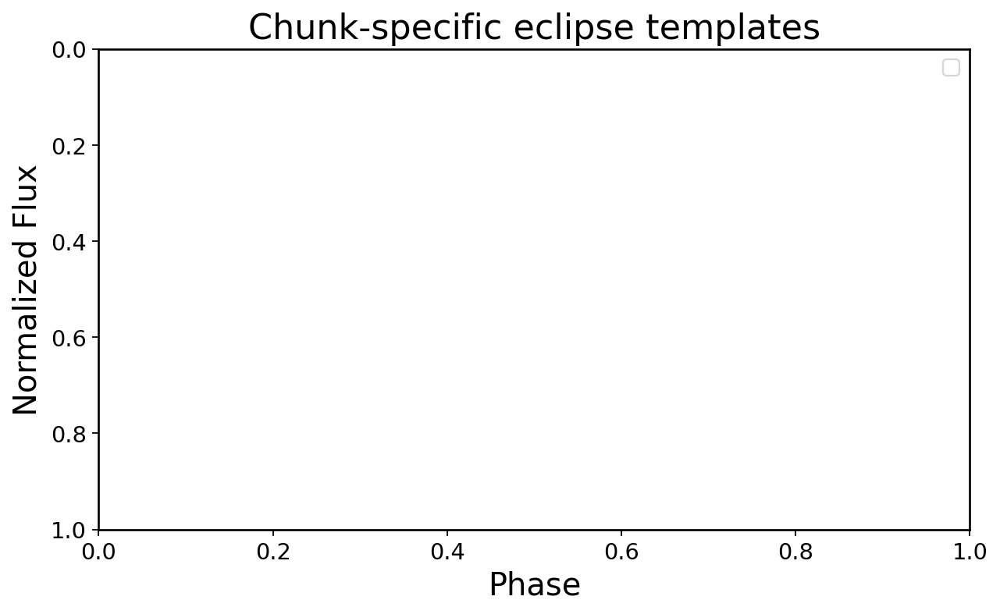

In [ ]:
plt.figure(figsize=(9,5))

for item in chunk_templates:
    plt.scatter(item["phase_raw"], item["flux_raw"], s=14, alpha=0.35)
    plt.plot(item["phase_smooth"], item["flux_smooth"], lw=3, label=f"chunk {item['chunk']}")

plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Chunk-specific eclipse templates")
plt.gca().invert_yaxis()
plt.legend()
plt.show()

In [ ]:
for item in chunk_templates:
    plt.figure(figsize=(7,4))
    plt.scatter(item["phase_raw"], item["flux_raw"], s=18, alpha=0.5, label="raw")
    plt.plot(item["phase_smooth"], item["flux_smooth"], lw=3, label="smoothed")
    plt.xlabel("Phase")
    plt.ylabel("Normalized Flux")
    plt.title(f"Chunk {item['chunk']}: template")
    plt.gca().invert_yaxis()
    plt.legend()
    plt.show()

In [ ]:
chunk_results = []

for item in chunk_templates:
    i = item["chunk"]
    t_seg = item["t"]
    f_seg = item["flux_full"]

    tp_template = item["phase_smooth"]
    tf_template = item["flux_smooth"]

    epochs_seg, timings_seg = measure_primary_timings(
        t_seg, f_seg,
        T0_guess, P_guess,
        tp_template, tf_template
    )

    OC_seg = timings_seg - (T0_guess + epochs_seg * P_guess)
    OC_seg = OC_seg - np.median(OC_seg)

    chunk_results.append({
        "chunk": i,
        "epochs": epochs_seg,
        "timings": timings_seg,
        "OC": OC_seg
    })

    print(f"Chunk {i}: {len(epochs_seg)} timings")

/var/folders/1c/p47qnnc123xd86gmn5km5bcm0000gn/T/ipykernel_2818/2431646750.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


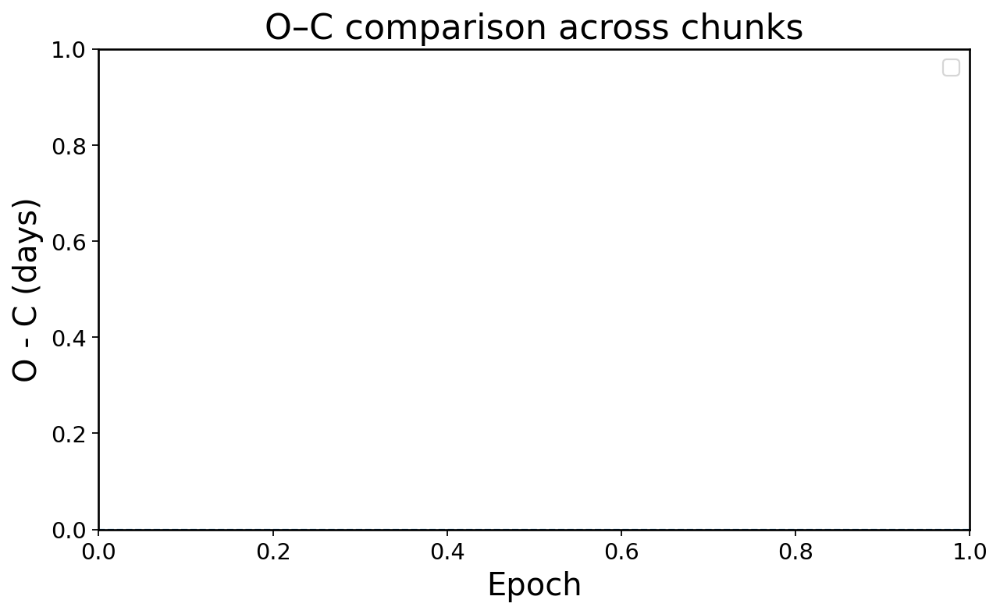

In [ ]:
plt.figure(figsize=(9,5))

for result in chunk_results:
    plt.scatter(result["epochs"], result["OC"], s=35, label=f"chunk {result['chunk']}")

plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Epoch")
plt.ylabel("O - C (days)")
plt.title("O–C comparison across chunks")
plt.legend()
plt.show()

In [ ]:
for result in chunk_results:
    OC = result["OC"]
    if len(OC) > 1:
        rms_sec = np.std(OC) * 86400
        print(f"Chunk {result['chunk']}: RMS = {rms_sec:.2f} sec, N = {len(OC)}")
    else:
        print(f"Chunk {result['chunk']}: not enough timings")

Chunk 0: RMS = 357.19 sec, N = 12
Chunk 2: RMS = 243.18 sec, N = 11


In [ ]:
chunk_templates = []

for i, seg in enumerate(segments):
    t_seg = t[seg]
    f_seg = flux_norm[seg]

    # Find deepest point in this chunk
    min_idx_global = np.argmin(f_seg)
    t_min = t_seg[min_idx_global]

    # Slightly wider local window
    window = 0.12 * P_guess
    mask = np.abs(t_seg - t_min) < window

    phase = (t_seg - t_min) / P_guess

    phase_sel = phase[mask]
    flux_sel = f_seg[mask]

    if len(phase_sel) < 20:
        print(f"Chunk {i}: skipped (too few eclipse-window points)")
        continue

    # Keep deepest 40% instead of 20%
    depth_cut = np.percentile(flux_sel, 40)
    deep_mask = flux_sel < depth_cut

    phase_sel = phase_sel[deep_mask]
    flux_sel = flux_sel[deep_mask]

    if len(phase_sel) < 20:
        print(f"Chunk {i}: skipped (too few eclipse points)")
        continue

    # Sort
    order = np.argsort(phase_sel)
    phase_sel = phase_sel[order]
    flux_sel = flux_sel[order]

    # Center on minimum
    min_idx = np.argmin(flux_sel)
    phase_sel = phase_sel - phase_sel[min_idx]

    # Trim to a centered narrow window
    valid = (phase_sel > -0.05) & (phase_sel < 0.05)
    phase_sel = phase_sel[valid]
    flux_sel = flux_sel[valid]

    if len(phase_sel) < 11:
        print(f"Chunk {i}: skipped (too few points after trimming)")
        continue

    # Smooth
    from scipy.signal import savgol_filter
    window_length = min(11, len(flux_sel) if len(flux_sel) % 2 == 1 else len(flux_sel)-1)
    if window_length >= 5:
        flux_smooth = savgol_filter(flux_sel, window_length, 2)
    else:
        flux_smooth = flux_sel.copy()

    chunk_templates.append({
        "chunk": i,
        "t": t_seg,
        "flux_full": f_seg,
        "phase_raw": phase_sel,
        "flux_raw": flux_sel,
        "phase_smooth": phase_sel,
        "flux_smooth": flux_smooth
    })

    print(f"Chunk {i}: template built with {len(phase_sel)} points")

Chunk 0: template built with 48 points
Chunk 1: template built with 25 points
Chunk 2: template built with 49 points
Chunk 3: template built with 27 points


In [ ]:
print(chunk_templates[0].keys())

dict_keys(['chunk', 't', 'flux_full', 'phase_raw', 'flux_raw', 'phase_smooth', 'flux_smooth'])


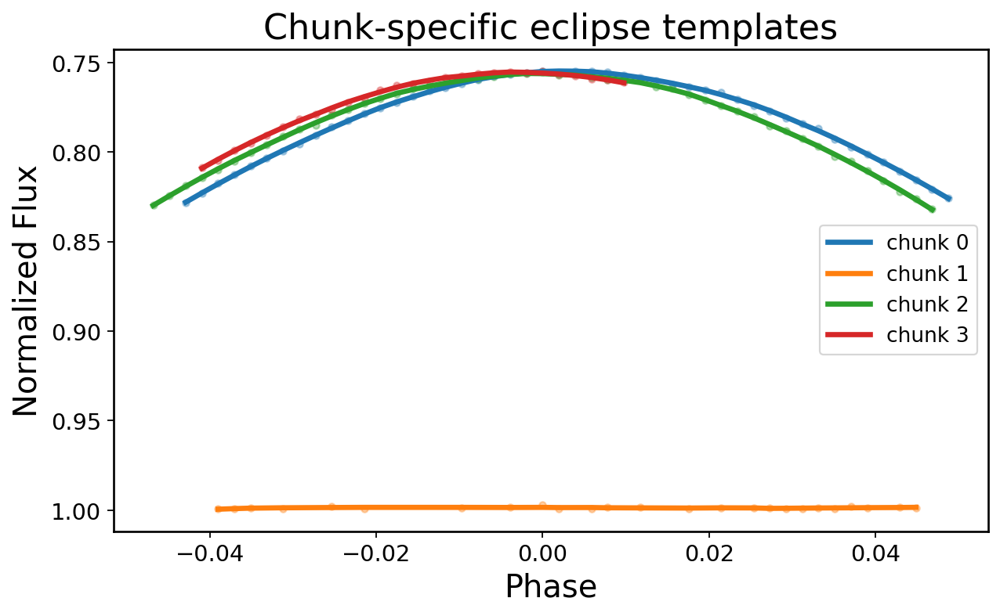

In [ ]:
plt.figure(figsize=(9,5))

for item in chunk_templates:
    plt.scatter(item["phase_raw"], item["flux_raw"], s=14, alpha=0.35)
    plt.plot(item["phase_smooth"], item["flux_smooth"], lw=3, label=f"chunk {item['chunk']}")

plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Chunk-specific eclipse templates")
plt.gca().invert_yaxis()
plt.legend()
plt.show()

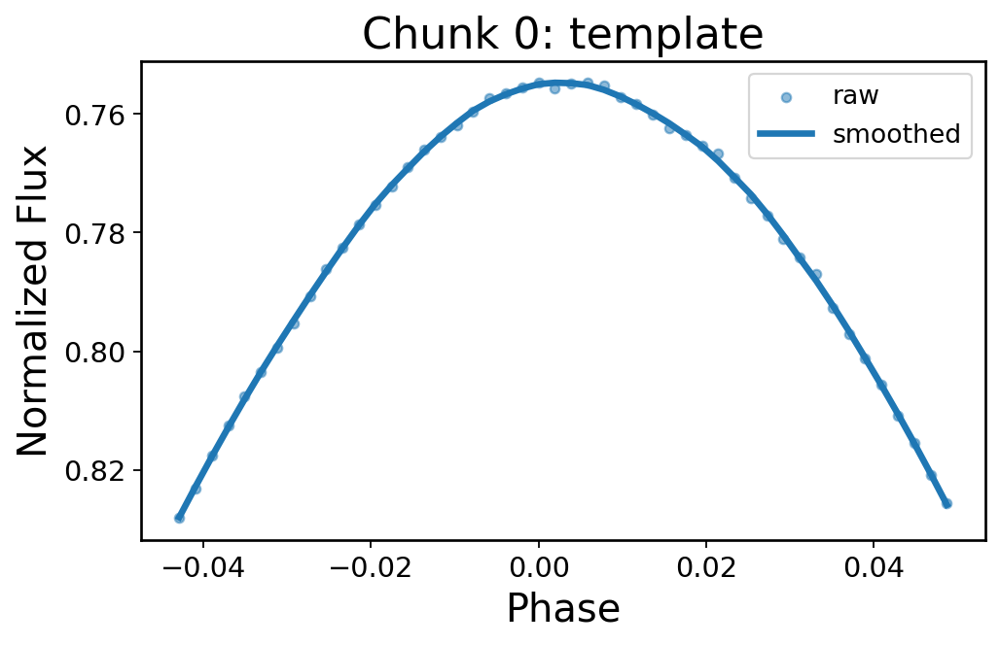

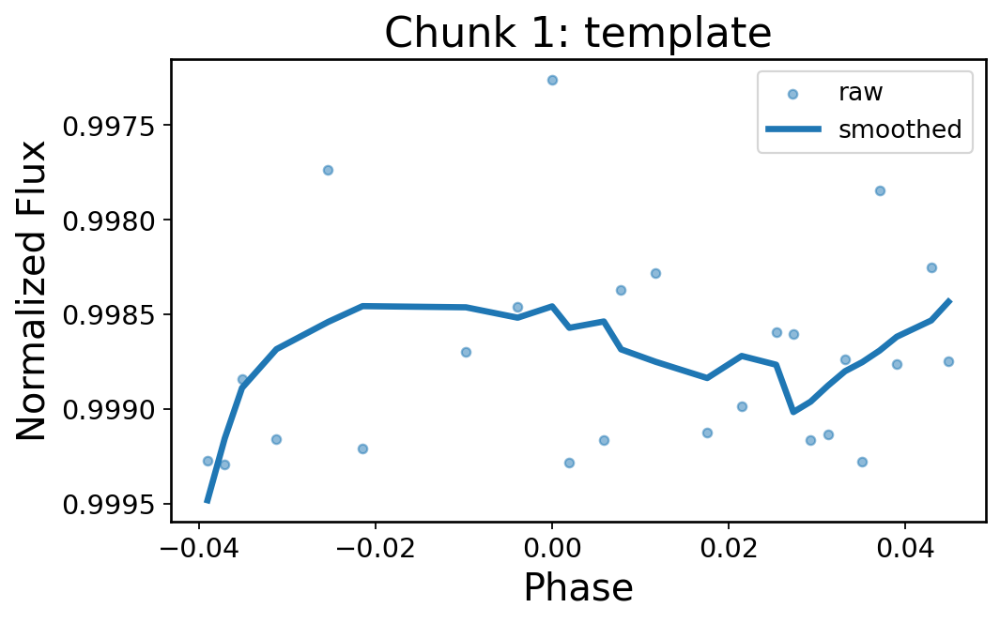

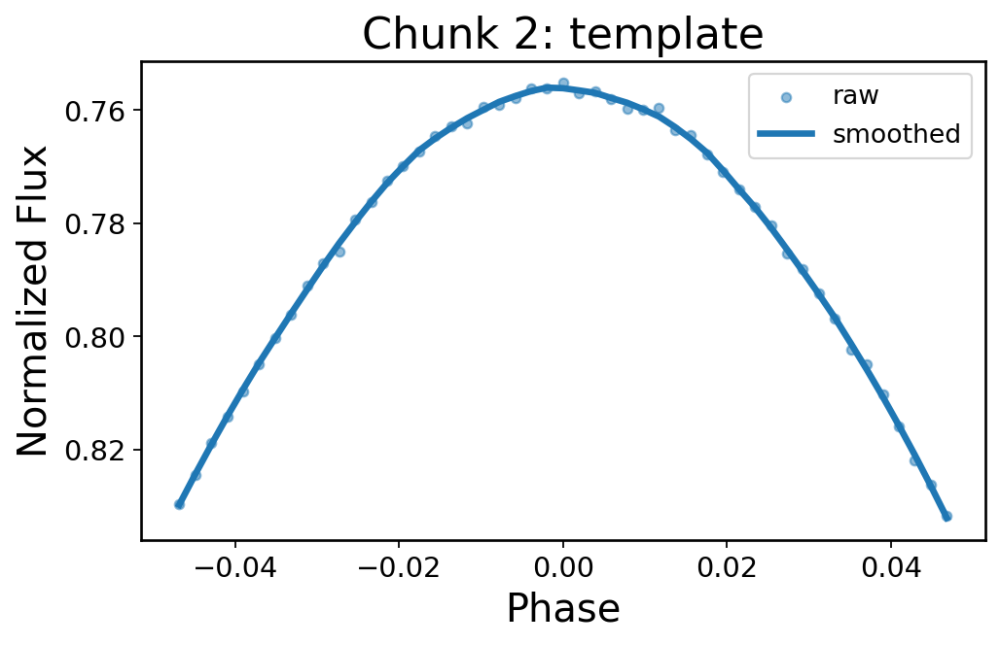

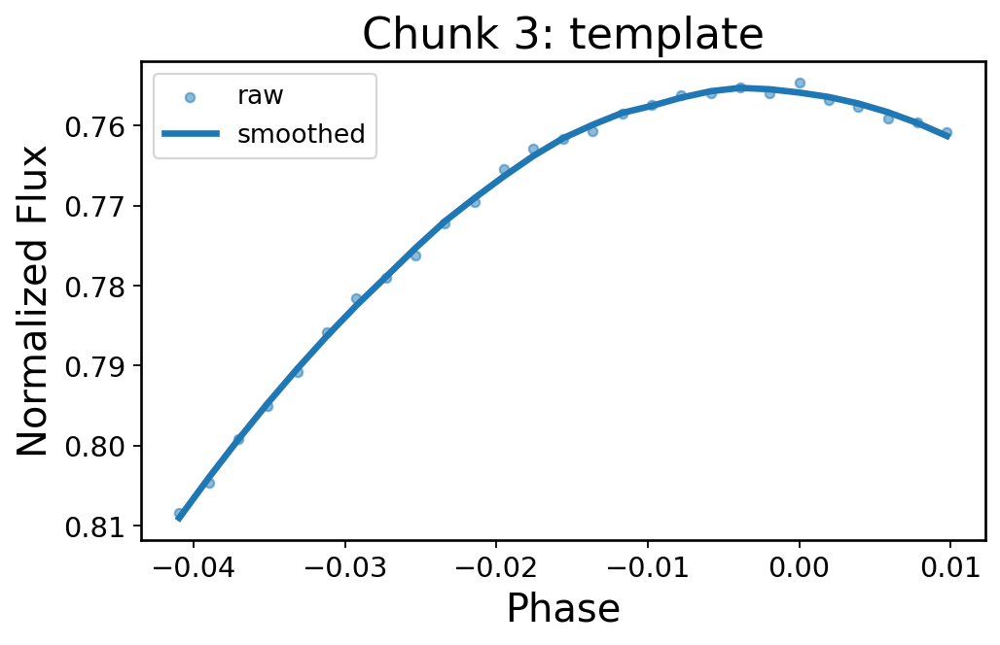

In [ ]:
for item in chunk_templates:
    plt.figure(figsize=(7,4))
    plt.scatter(item["phase_raw"], item["flux_raw"], s=18, alpha=0.5, label="raw")
    plt.plot(item["phase_smooth"], item["flux_smooth"], lw=3, label="smoothed")
    plt.xlabel("Phase")
    plt.ylabel("Normalized Flux")
    plt.title(f"Chunk {item['chunk']}: template")
    plt.gca().invert_yaxis()
    plt.legend()
    plt.show()

In [ ]:
chunk_results = []

for item in chunk_templates:
    i = item["chunk"]
    t_seg = item["t"]
    f_seg = item["flux_full"]

    tp_template = item["phase_smooth"]
    tf_template = item["flux_smooth"]

    epochs_seg, timings_seg = measure_primary_timings(
        t_seg, f_seg,
        T0_guess, P_guess,
        tp_template, tf_template
    )

    OC_seg = timings_seg - (T0_guess + epochs_seg * P_guess)
    OC_seg = OC_seg - np.median(OC_seg)

    chunk_results.append({
        "chunk": i,
        "epochs": epochs_seg,
        "timings": timings_seg,
        "OC": OC_seg
    })

    print(f"Chunk {i}: {len(epochs_seg)} timings")

Chunk 0: 12 timings
Chunk 1: 1 timings
Chunk 2: 11 timings
Chunk 3: 1 timings


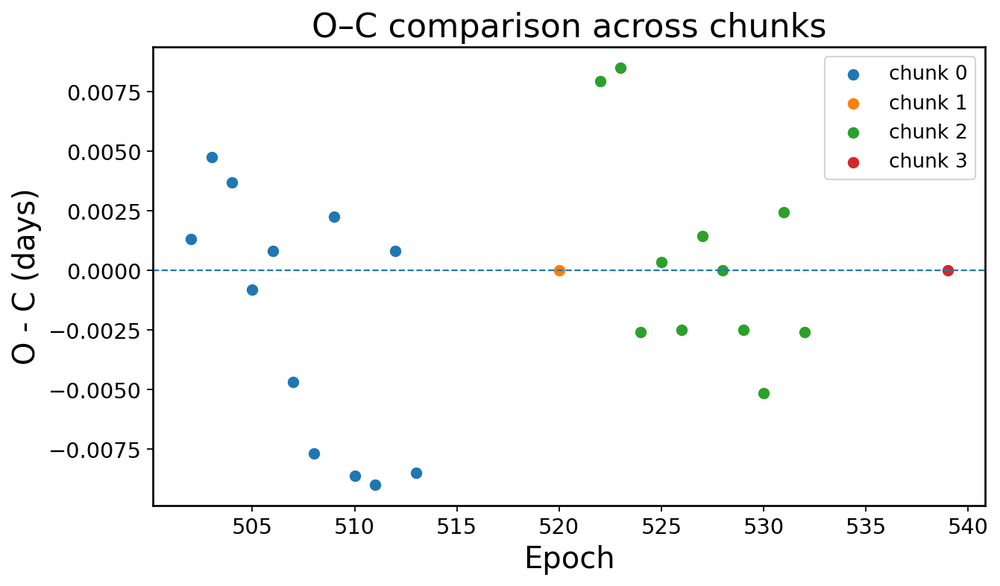

In [ ]:
plt.figure(figsize=(9,5))

for result in chunk_results:
    plt.scatter(result["epochs"], result["OC"], s=35, label=f"chunk {result['chunk']}")

plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Epoch")
plt.ylabel("O - C (days)")
plt.title("O–C comparison across chunks")
plt.legend()
plt.show()

In [ ]:
for result in chunk_results:
    OC = result["OC"]
    if len(OC) > 1:
        rms_sec = np.std(OC) * 86400
        print(f"Chunk {result['chunk']}: RMS = {rms_sec:.2f} sec, N = {len(OC)}")
    else:
        print(f"Chunk {result['chunk']}: not enough timings")

Chunk 0: RMS = 430.94 sec, N = 12
Chunk 1: not enough timings
Chunk 2: RMS = 362.37 sec, N = 11
Chunk 3: not enough timings


In [ ]:
chunk_templates = []

for i, seg in enumerate(segments):

    t_seg = t[seg]
    f_seg = flux_norm[seg]

    # --- Find deepest point ---
    min_idx_global = np.argmin(f_seg)
    t_min = t_seg[min_idx_global]

    # --- Window ---
    window = 0.12 * P_guess
    mask = np.abs(t_seg - t_min) < window

    # --- Phase ---
    phase = (t_seg - t_min) / P_guess

    # --- Select eclipse region ---
    phase_sel = phase[mask]
    flux_sel = f_seg[mask]

    # ✅ 👉 PUT IT HERE
    depth = np.max(flux_sel) - np.min(flux_sel)
    if depth < 0.01:
        print(f"Chunk {i}: skipped (no clear eclipse)")
        continue

    # --- Continue pipeline ---
    order = np.argsort(phase_sel)
    phase_sel = phase_sel[order]
    flux_sel = flux_sel[order]

    # center
    min_idx = np.argmin(flux_sel)
    phase_sel = phase_sel - phase_sel[min_idx]

    # trim
    valid = (phase_sel > -0.05) & (phase_sel < 0.05)
    phase_sel = phase_sel[valid]
    flux_sel = flux_sel[valid]

    # smooth
    from scipy.signal import savgol_filter
    if len(flux_sel) >= 11:
        flux_smooth = savgol_filter(flux_sel, 11, 2)
    else:
        flux_smooth = flux_sel

    chunk_templates.append({
        "chunk": i,
        "t": t_seg,
        "flux_full": f_seg,
        "phase_raw": phase_sel,
        "flux_raw": flux_sel,
        "phase_smooth": phase_sel,
        "flux_smooth": flux_smooth
    })

    print(f"Chunk {i}: template built with {len(phase_sel)} points")

Chunk 0: template built with 51 points
Chunk 1: skipped (no clear eclipse)
Chunk 2: template built with 51 points
Chunk 3: template built with 31 points


In [ ]:
print(chunk_templates[0].keys())

dict_keys(['chunk', 't', 'flux_full', 'phase_raw', 'flux_raw', 'phase_smooth', 'flux_smooth'])


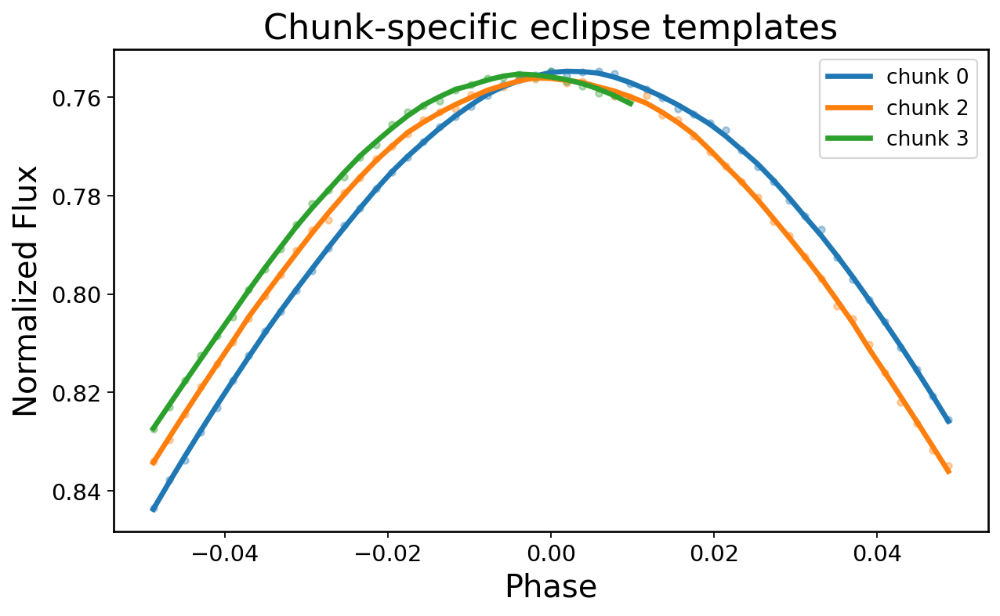

In [ ]:
plt.figure(figsize=(9,5))

for item in chunk_templates:
    plt.scatter(item["phase_raw"], item["flux_raw"], s=14, alpha=0.35)
    plt.plot(item["phase_smooth"], item["flux_smooth"], lw=3, label=f"chunk {item['chunk']}")

plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Chunk-specific eclipse templates")
plt.gca().invert_yaxis()
plt.legend()
plt.show()

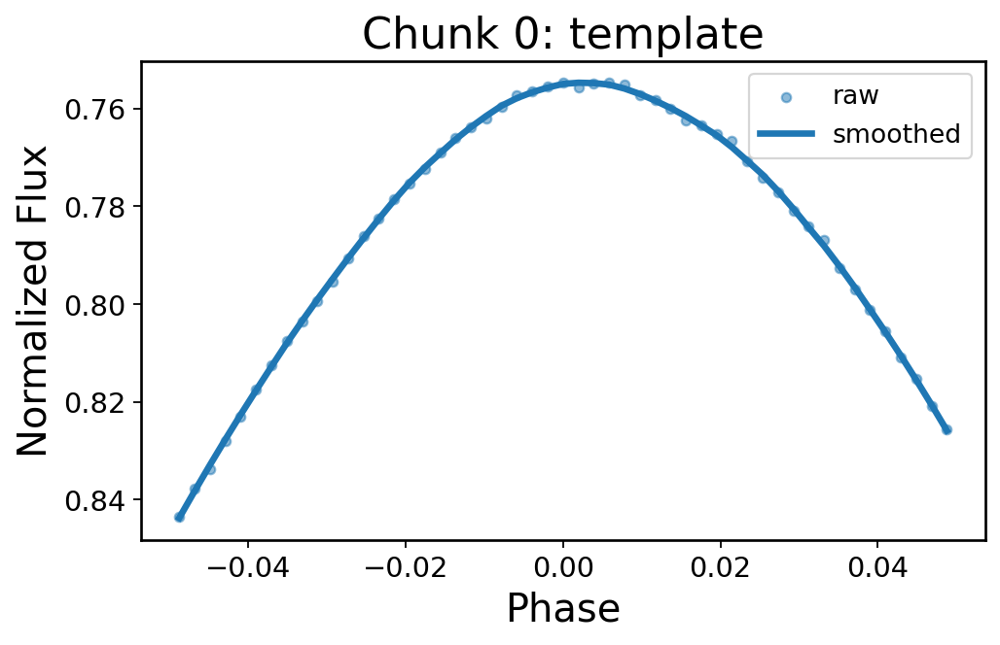

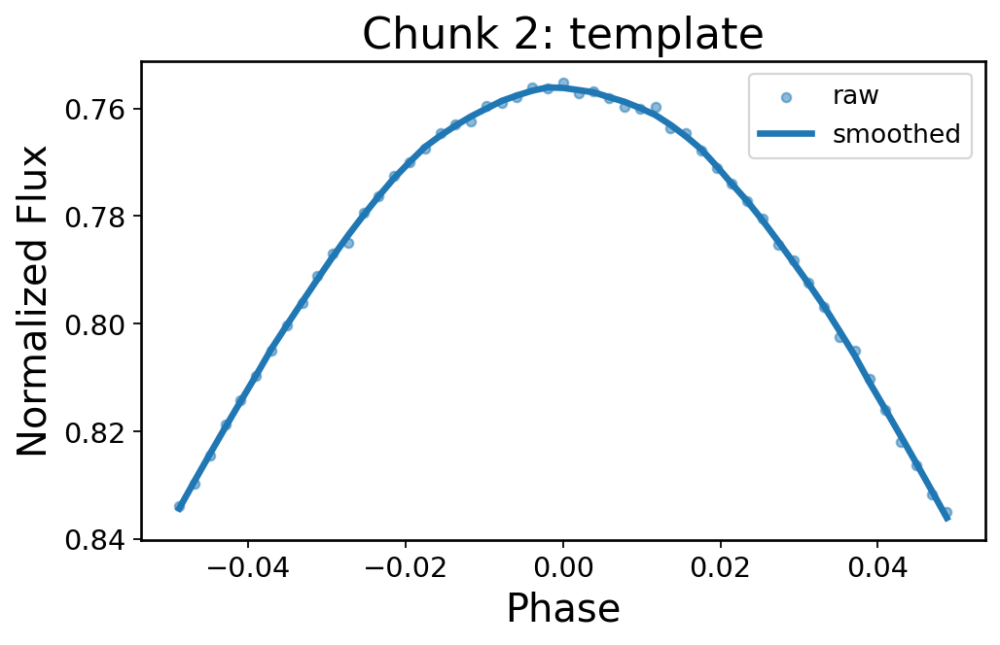

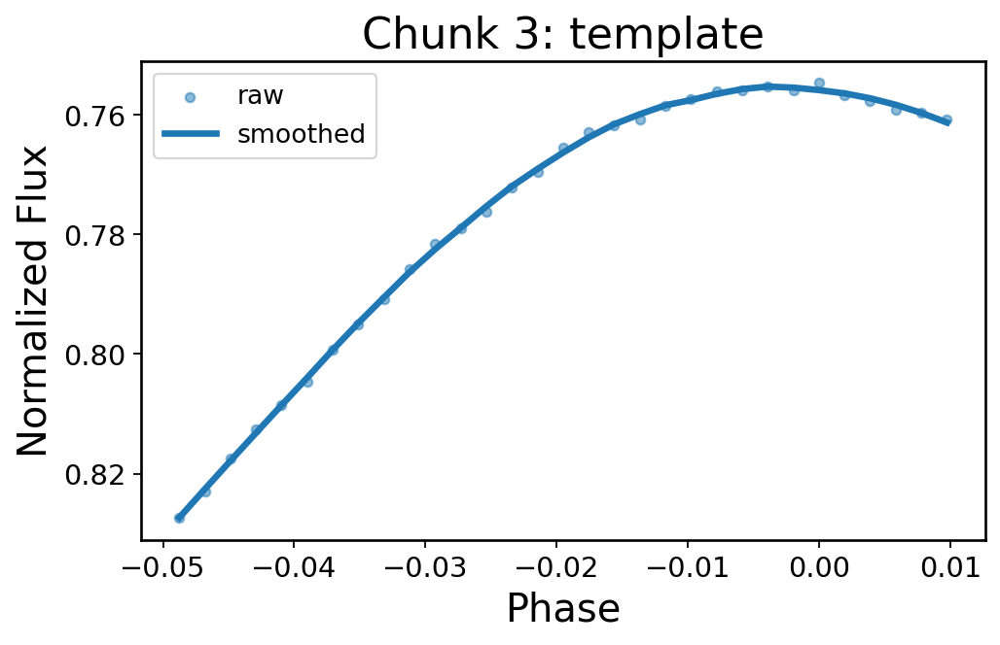

In [ ]:
for item in chunk_templates:
    plt.figure(figsize=(7,4))
    plt.scatter(item["phase_raw"], item["flux_raw"], s=18, alpha=0.5, label="raw")
    plt.plot(item["phase_smooth"], item["flux_smooth"], lw=3, label="smoothed")
    plt.xlabel("Phase")
    plt.ylabel("Normalized Flux")
    plt.title(f"Chunk {item['chunk']}: template")
    plt.gca().invert_yaxis()
    plt.legend()
    plt.show()

In [ ]:
chunk_results = []

for item in chunk_templates:
    i = item["chunk"]
    t_seg = item["t"]
    f_seg = item["flux_full"]

    tp_template = item["phase_smooth"]
    tf_template = item["flux_smooth"]

    epochs_seg, timings_seg = measure_primary_timings(
        t_seg, f_seg,
        T0_guess, P_guess,
        tp_template, tf_template
    )

    OC_seg = timings_seg - (T0_guess + epochs_seg * P_guess)
    OC_seg = OC_seg - np.median(OC_seg)

    chunk_results.append({
        "chunk": i,
        "epochs": epochs_seg,
        "timings": timings_seg,
        "OC": OC_seg
    })

    print(f"Chunk {i}: {len(epochs_seg)} timings")

Chunk 0: 12 timings
Chunk 2: 11 timings
Chunk 3: 1 timings


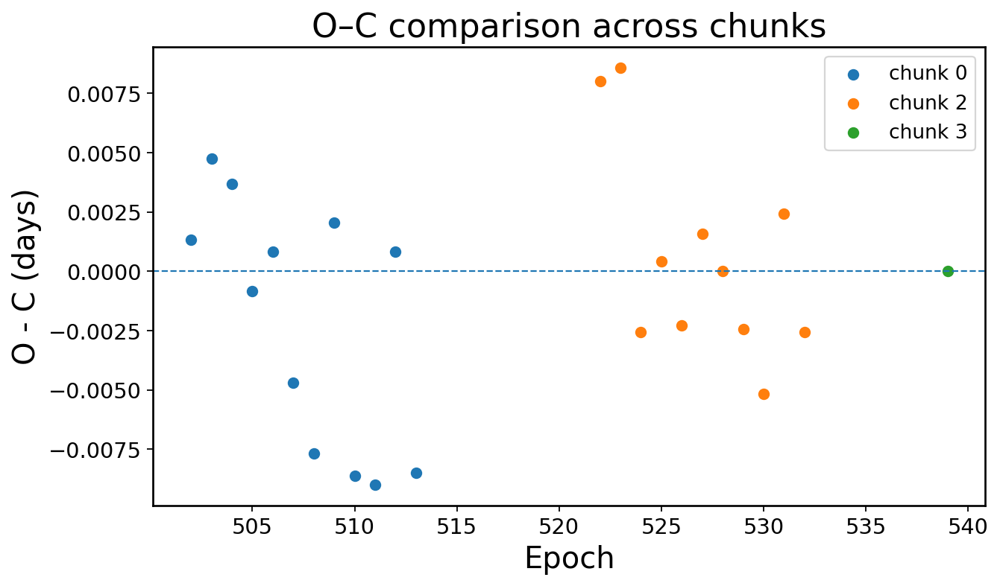

In [ ]:
plt.figure(figsize=(9,5))

for result in chunk_results:
    plt.scatter(result["epochs"], result["OC"], s=35, label=f"chunk {result['chunk']}")

plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Epoch")
plt.ylabel("O - C (days)")
plt.title("O–C comparison across chunks")
plt.legend()
plt.show()

In [ ]:
for result in chunk_results:
    OC = result["OC"]
    if len(OC) > 1:
        rms_sec = np.std(OC) * 86400
        print(f"Chunk {result['chunk']}: RMS = {rms_sec:.2f} sec, N = {len(OC)}")
    else:
        print(f"Chunk {result['chunk']}: not enough timings")

Chunk 0: RMS = 429.61 sec, N = 12
Chunk 2: RMS = 363.13 sec, N = 11
Chunk 3: not enough timings


In [ ]:
chunk_results = []

for item in chunk_templates:
    i = item["chunk"]
    t_seg = item["t"]
    f_seg = item["flux_full"]

    tp_template = item["phase_smooth"]
    tf_template = item["flux_smooth"]

    epochs_seg, timings_seg = measure_primary_timings(
        t_seg, f_seg,
        T0_guess, P_guess,
        tp_template, tf_template
    )

    # ✅ ADD THIS HERE
    if len(timings_seg) < 3:
        print(f"Chunk {i}: skipped (too few timing points)")
        continue

    OC_seg = timings_seg - (T0_guess + epochs_seg * P_guess)
    OC_seg = OC_seg - np.median(OC_seg)

    chunk_results.append({
        "chunk": i,
        "epochs": epochs_seg,
        "timings": timings_seg,
        "OC": OC_seg
    })

    print(f"Chunk {i}: {len(epochs_seg)} timings")

Chunk 0: 12 timings
Chunk 2: 11 timings
Chunk 3: skipped (too few timing points)


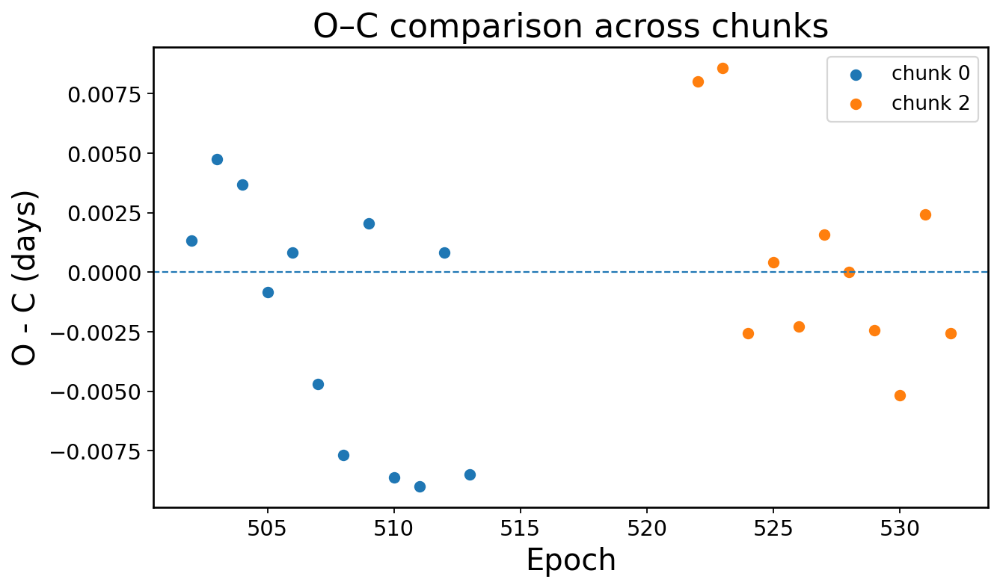

In [ ]:
plt.figure(figsize=(9,5))

for result in chunk_results:
    plt.scatter(result["epochs"], result["OC"], s=35, label=f"chunk {result['chunk']}")

plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Epoch")
plt.ylabel("O - C (days)")
plt.title("O–C comparison across chunks")
plt.legend()
plt.show()

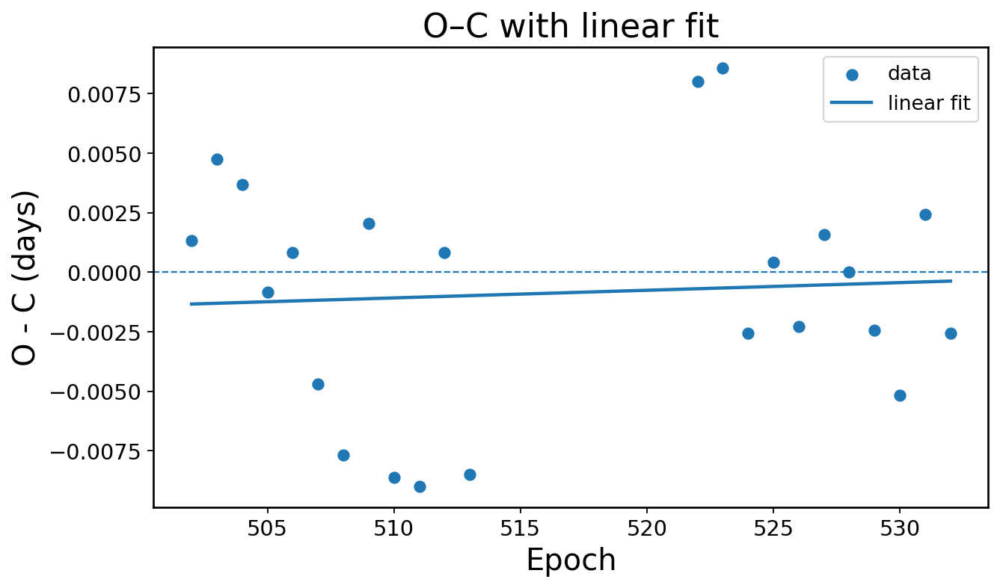

Slope (a): 3.211584057598687e-05


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Combine all chunks
all_epochs = []
all_oc = []

for item in chunk_results:
    all_epochs.extend(item["epochs"])
    all_oc.extend(item["OC"])

all_epochs = np.array(all_epochs)
all_oc = np.array(all_oc)

# Fit line: OC = a * epoch + b
coeffs = np.polyfit(all_epochs, all_oc, 1)
a, b = coeffs

# Plot
plt.figure(figsize=(9,5))
plt.scatter(all_epochs, all_oc, s=40, label="data")

x_fit = np.linspace(min(all_epochs), max(all_epochs), 100)
y_fit = a * x_fit + b

plt.plot(x_fit, y_fit, linewidth=2, label="linear fit")
plt.axhline(0, linestyle='--', linewidth=1)

plt.xlabel("Epoch")
plt.ylabel("O - C (days)")
plt.title("O–C with linear fit")
plt.legend()
plt.show()

print("Slope (a):", a)

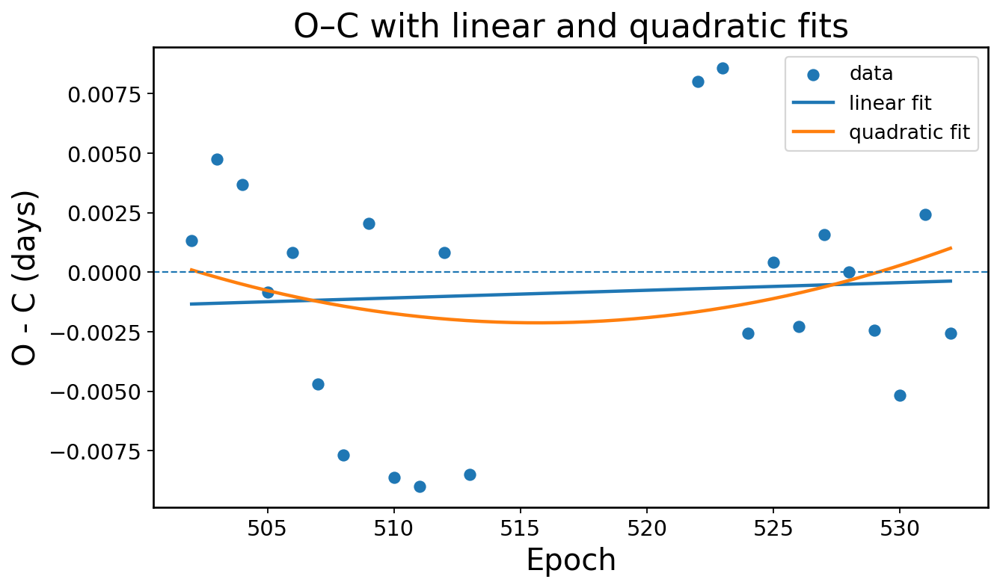

Quadratic coefficient a2 = 1.1813600808287981e-05


In [ ]:
coeffs2 = np.polyfit(all_epochs, all_oc, 2)
a2, b2, c2 = coeffs2

x_fit = np.linspace(min(all_epochs), max(all_epochs), 200)
y_quad = a2*x_fit**2 + b2*x_fit + c2
y_lin = a* x_fit + np.polyfit(all_epochs, all_oc, 1)[1]

plt.figure(figsize=(9,5))
plt.scatter(all_epochs, all_oc, s=40, label="data")
plt.plot(x_fit, y_lin, linewidth=2, label="linear fit")
plt.plot(x_fit, y_quad, linewidth=2, label="quadratic fit")
plt.axhline(0, linestyle='--', linewidth=1)

plt.xlabel("Epoch")
plt.ylabel("O - C (days)")
plt.title("O–C with linear and quadratic fits")
plt.legend()
plt.show()

print("Quadratic coefficient a2 =", a2)

In [ ]:
from astropy.io import fits

file_path = "/mnt/md2/TESS_EBs/first1000/release/tess10057647.fits"

hdul = fits.open(file_path)
hdul.info()

FileNotFoundError: [Errno 2] No such file or directory: '/mnt/md2/TESS_EBs/first1000/release/tess10057647.fits'

In [ ]:
import os
os.path.exists("/mnt/md2/TESS_EBs/first1000/release/")

False

In [ ]:
import os
print(os.getcwd())
print(os.path.exists("/mnt/md2"))

/Users/admin-victor/Documents/pyspedas_project/Precision Timing of Eclipsing Binaries from TESS Full Frame Images
False


In [ ]:
import os

print("Current working directory:", os.getcwd())
print("Can notebook see /mnt/md2 ?", os.path.exists("/mnt/md2"))
print("Can notebook see release folder ?", os.path.exists("/mnt/md2/TESS_EBs/first1000/release"))

Current working directory: /Users/admin-victor/Documents/pyspedas_project/Precision Timing of Eclipsing Binaries from TESS Full Frame Images
Can notebook see /mnt/md2 ? False
Can notebook see release folder ? False


In [ ]:
import os

print(os.listdir("/mnt/md2"))

FileNotFoundError: [Errno 2] No such file or directory: '/mnt/md2'

In [ ]:
from astropy.io import fits

file_path = "/Users/admin-victor/Downloads/tess10057647.fits"

hdul = fits.open(file_path)
hdul.info()

Filename: /Users/admin-victor/Downloads/tess10057647.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1                1 BinTableHDU    203   262144R x 22C   [D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D]   


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

data = hdul[1].data
print(data.columns.names)

['mtotal', 'mratio', 'age_gyr', 'meh', 'per', 'ecc', 'w', 'primary_impact_param', 'eclipse_time', 'primary_limb_dark_1', 'primary_limb_dark_2', 'secondary_limb_dark_1', 'secondary_limb_dark_2', 'primary_prot', 'secondary_prot', 'primary_reflection_coef', 'secondary_reflection_coef', 'primary_beaming_coef', 'secondary_beaming_coef', 'lc_sys', 'sed_sys', 'log_prob']


In [ ]:
time = data["TIME"]

if "PDCSAP_FLUX" in data.columns.names:
    flux = data["PDCSAP_FLUX"]
    flux_err = data["PDCSAP_FLUX_ERR"]
else:
    flux = data["SAP_FLUX"]
    flux_err = data["SAP_FLUX_ERR"]

mask = np.isfinite(time) & np.isfinite(flux) & (flux > 0)

time = time[mask]
flux = flux[mask]

flux = flux / np.nanmedian(flux)

plt.figure(figsize=(10,4))
plt.plot(time, flux, ".", markersize=2)
plt.xlabel("Time (BTJD)")
plt.ylabel("Normalized Flux")
plt.title("Raw TESS Light Curve")
plt.show()

KeyError: "Key 'TIME' does not exist."

In [ ]:
from astropy.io import fits

file_path = "/Users/admin-victor/Downloads/tess10057647.fits"
hdul = fits.open(file_path)

hdul.info()

Filename: /Users/admin-victor/Downloads/tess10057647.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1                1 BinTableHDU    203   262144R x 22C   [D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D]   


In [ ]:
for i, hdu in enumerate(hdul):
    print(f"\nHDU {i}:")
    print(type(hdu))
    if hasattr(hdu, "columns") and hdu.columns is not None:
        print(hdu.columns.names)


HDU 0:
<class 'astropy.io.fits.hdu.image.PrimaryHDU'>

HDU 1:
<class 'astropy.io.fits.hdu.table.BinTableHDU'>
['mtotal', 'mratio', 'age_gyr', 'meh', 'per', 'ecc', 'w', 'primary_impact_param', 'eclipse_time', 'primary_limb_dark_1', 'primary_limb_dark_2', 'secondary_limb_dark_1', 'secondary_limb_dark_2', 'primary_prot', 'secondary_prot', 'primary_reflection_coef', 'secondary_reflection_coef', 'primary_beaming_coef', 'secondary_beaming_coef', 'lc_sys', 'sed_sys', 'log_prob']


In [ ]:
from astropy.io import fits

file_path = "/Users/admin-victor/Downloads/tess2018206045859-s0001-000000024704862-0120-s_lc.fits"

hdul = fits.open(file_path)
hdul.info()

FileNotFoundError: [Errno 2] No such file or directory: '/Users/admin-victor/Downloads/tess2018206045859-s0001-000000024704862-0120-s_lc.fits'

In [ ]:
from astropy.io import fits

file_path = "/Users/admin-victor/Downloads/tess2018206045859-s0001-0000000024704862-0120-s_lc.fits"

hdul = fits.open(file_path)
hdul.info()

Filename: /Users/admin-victor/Downloads/tess2018206045859-s0001-0000000024704862-0120-s_lc.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      44   ()      
  1  LIGHTCURVE    1 BinTableHDU    167   20076R x 20C   [D, E, J, E, E, E, E, E, E, J, D, E, D, E, D, E, D, E, E, E]   
  2  APERTURE      1 ImageHDU        49   (11, 13)   int32   


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

data = hdul[1].data

time = data["TIME"]
flux = data["PDCSAP_FLUX"]
flux_err = data["PDCSAP_FLUX_ERR"]

In [ ]:
mask = np.isfinite(time) & np.isfinite(flux)

time = time[mask]
flux = flux[mask]

flux = flux / np.nanmedian(flux)

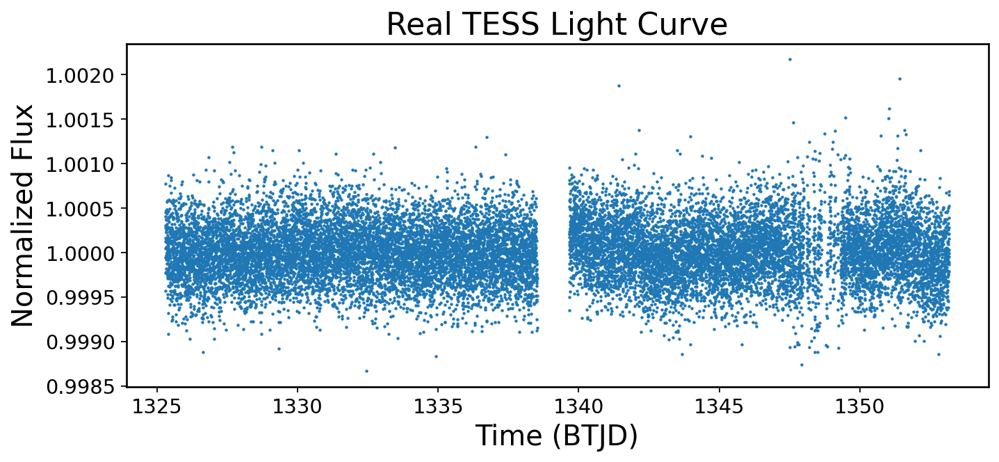

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(time, flux, ".", markersize=2)
plt.xlabel("Time (BTJD)")
plt.ylabel("Normalized Flux")
plt.title("Real TESS Light Curve")
plt.show()

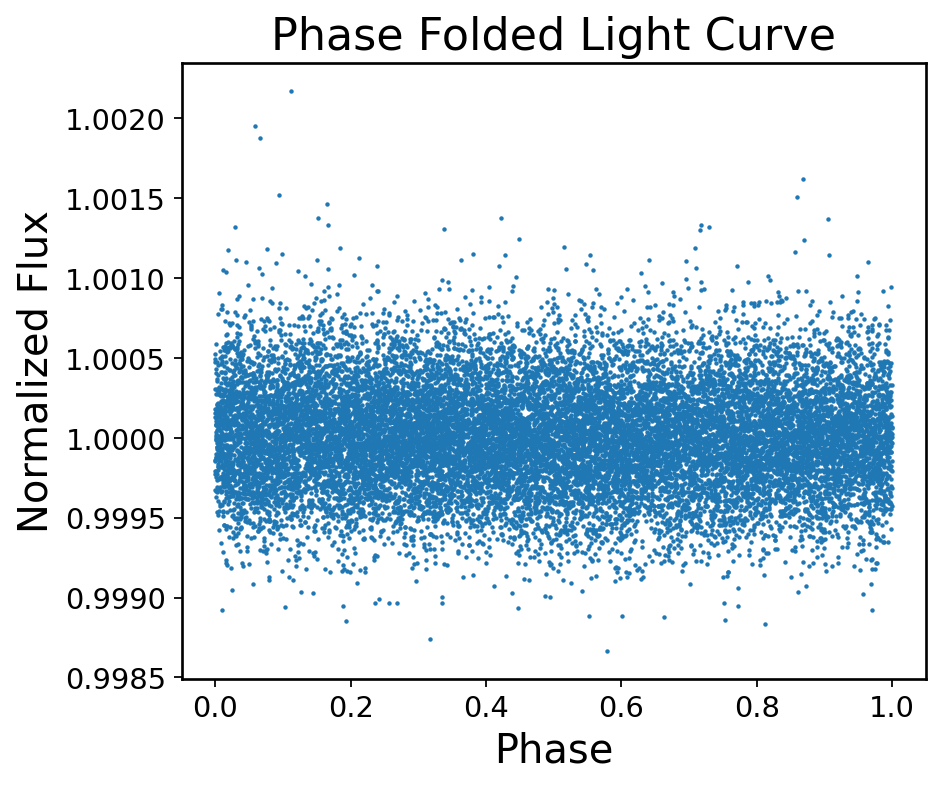

In [ ]:
P = 2.0   # temporary guess (we will fix this)
T0 = time[0]

phase = ((time - T0) % P) / P

plt.figure(figsize=(6,5))
plt.plot(phase, flux, ".", markersize=2)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Phase Folded Light Curve")
plt.show()

In [ ]:
from astropy.timeseries import LombScargle

# Try a reasonable range (typical EB periods)
frequency, power = LombScargle(time, flux).autopower(
    minimum_frequency=0.1,
    maximum_frequency=5.0
)

best_frequency = frequency[np.argmax(power)]
P_best = 1 / best_frequency

print("Best period:", P_best)

Best period: 8.74532462281727


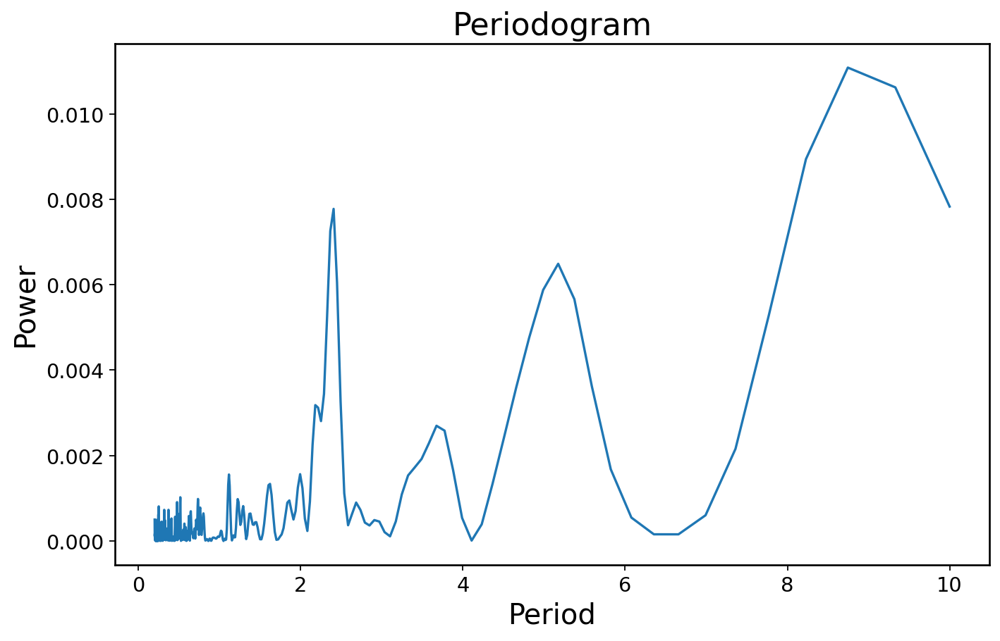

In [ ]:
import matplotlib.pyplot as plt

plt.plot(1/frequency, power)
plt.xlabel("Period")
plt.ylabel("Power")
plt.title("Periodogram")
plt.show()

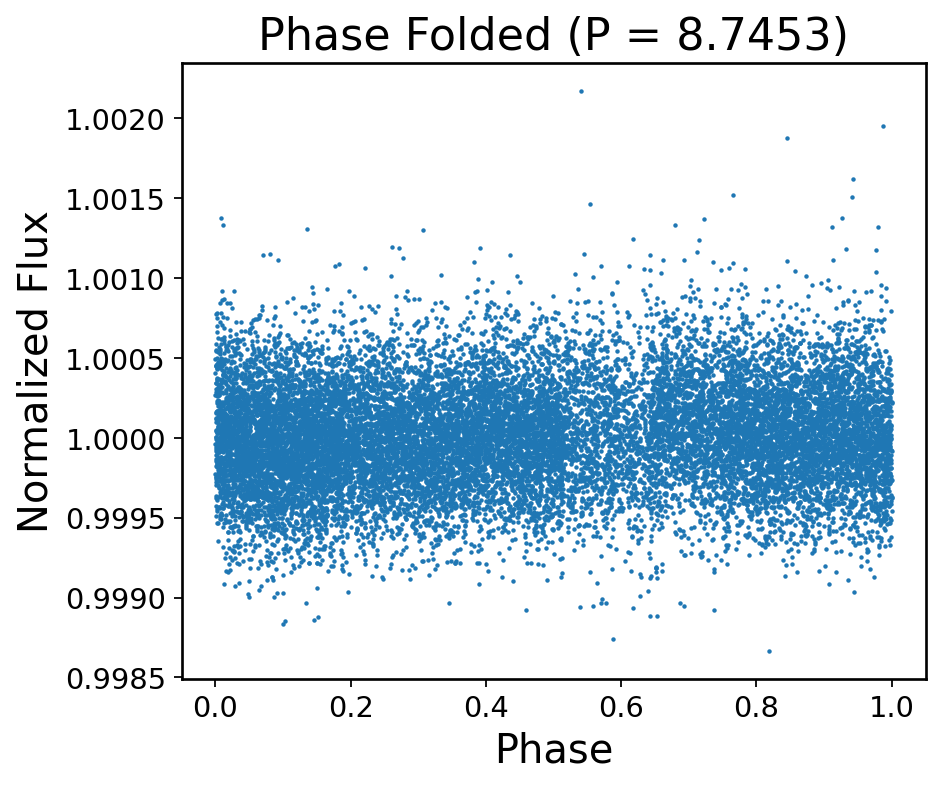

In [ ]:
P = P_best
T0 = time[0]

phase = ((time - T0) % P) / P

plt.figure(figsize=(6,5))
plt.plot(phase, flux, ".", markersize=2)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title(f"Phase Folded (P = {P:.4f})")
plt.show()

In [ ]:
from astropy.timeseries import BoxLeastSquares
import numpy as np
import matplotlib.pyplot as plt

# durations to try (in days)
durations = np.linspace(0.05, 0.5, 20)

bls = BoxLeastSquares(time, flux)
period_grid = np.linspace(0.5, 20.0, 5000)

bls_power = bls.power(period_grid, durations)

best_idx = np.argmax(bls_power.power)
P_bls = bls_power.period[best_idx]
t0_bls = bls_power.transit_time[best_idx]
dur_bls = bls_power.duration[best_idx]

print("Best BLS period:", P_bls)
print("Best BLS t0:", t0_bls)
print("Best BLS duration:", dur_bls)

ValueError: The maximum transit duration must be shorter than the minimum period

In [ ]:
from astropy.timeseries import BoxLeastSquares
import numpy as np
import matplotlib.pyplot as plt

# shorter eclipse durations
durations = np.linspace(0.02, 0.2, 20)

bls = BoxLeastSquares(time, flux)
period_grid = np.linspace(0.5, 20.0, 5000)

bls_power = bls.power(period_grid, durations)

best_idx = np.argmax(bls_power.power)
P_bls = bls_power.period[best_idx]
t0_bls = bls_power.transit_time[best_idx]
dur_bls = bls_power.duration[best_idx]

print("Best BLS period:", P_bls)
print("Best BLS t0:", t0_bls)
print("Best BLS duration:", dur_bls)

Best BLS period: 4.619223844768953
Best BLS t0: 1329.2998806165665
Best BLS duration: 0.124


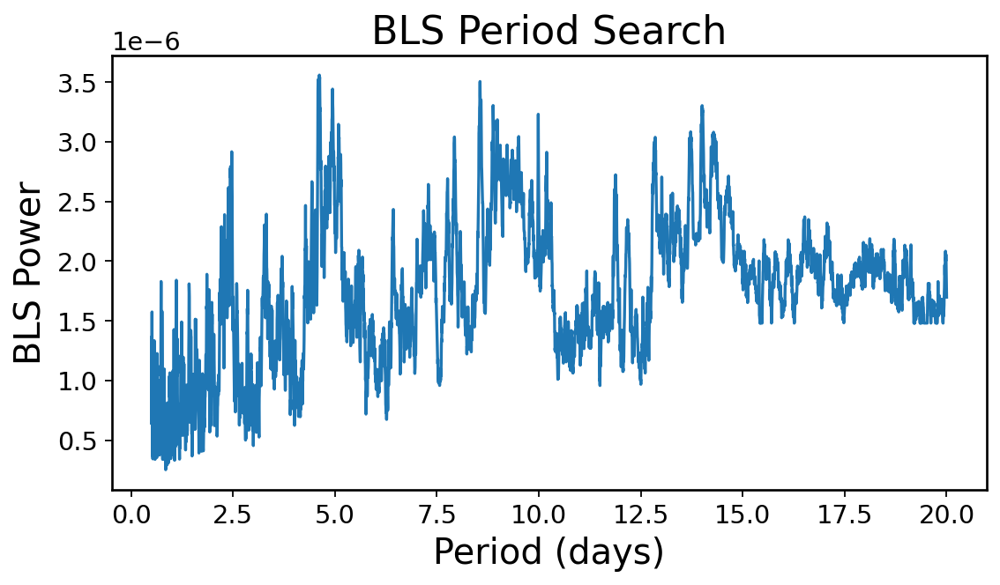

In [ ]:
plt.figure(figsize=(8,4))
plt.plot(bls_power.period, bls_power.power)
plt.xlabel("Period (days)")
plt.ylabel("BLS Power")
plt.title("BLS Period Search")
plt.show()

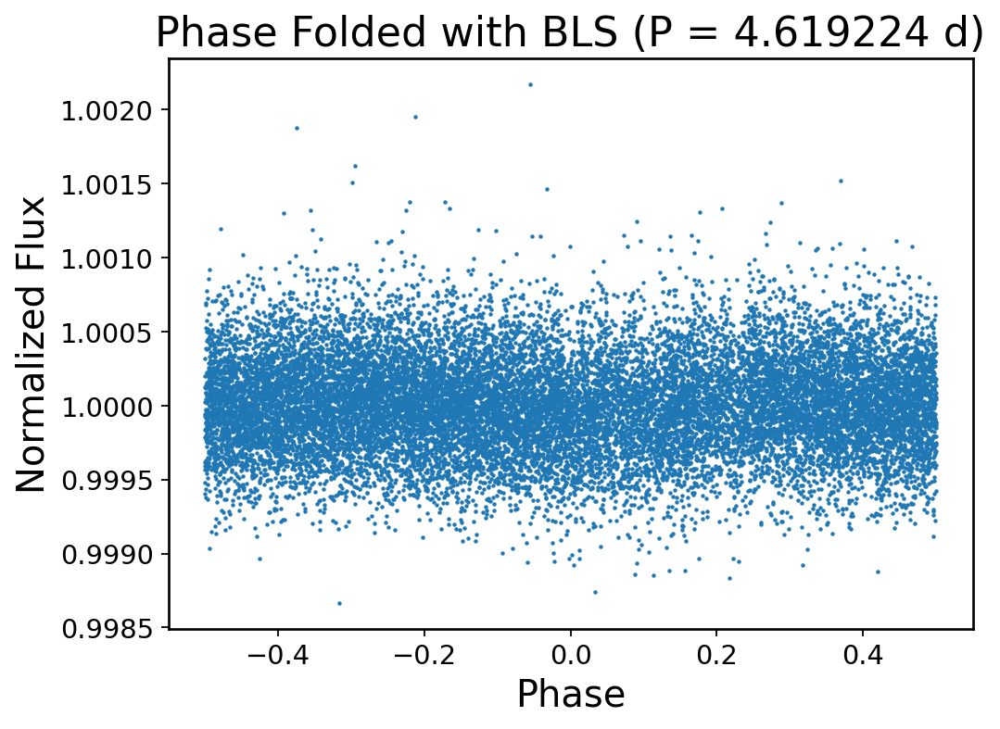

In [ ]:
P = P_bls
T0 = t0_bls

phase = ((time - T0 + 0.5 * P) % P) / P - 0.5

plt.figure(figsize=(7,5))
plt.plot(phase, flux, ".", markersize=2)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title(f"Phase Folded with BLS (P = {P:.6f} d)")
plt.show()

In [ ]:
from astropy.io import fits

file_path = "/Users/admin-victor/Downloads/tess2019357164649-s0020-000000010057647-0165-s_lc.fits"

hdul = fits.open(file_path)
hdul.info()

FileNotFoundError: [Errno 2] No such file or directory: '/Users/admin-victor/Downloads/tess2019357164649-s0020-000000010057647-0165-s_lc.fits'

In [ ]:
import os

files = [f for f in os.listdir("/Users/admin-victor/Downloads") if "10057647" in f]
print(files)

['tess10057647.fits', 'tess10057647.png']


In [ ]:
from astropy.io import fits

file_path = "/Users/admin-victor/Downloads/" + files[0]
hdul = fits.open(file_path)
hdul.info()

Filename: /Users/admin-victor/Downloads/tess10057647.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1                1 BinTableHDU    203   262144R x 22C   [D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D]   


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

data = hdul[1].data

time = data["TIME"]
flux = data["PDCSAP_FLUX"]

mask = np.isfinite(time) & np.isfinite(flux)
time = time[mask]
flux = flux[mask]
flux = flux / np.nanmedian(flux)

P = 16.26369
T0 = time[0]

phase = ((time - T0) % P) / P

plt.figure(figsize=(6,5))
plt.plot(phase, flux, ".", markersize=2)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("TIC 10057647")
plt.show()

KeyError: "Key 'TIME' does not exist."

In [ ]:
for i, hdu in enumerate(hdul):
    print(f"\nHDU {i}:")
    print(type(hdu))
    if hasattr(hdu, "columns") and hdu.columns is not None:
        print(hdu.columns.names)


HDU 0:
<class 'astropy.io.fits.hdu.image.PrimaryHDU'>

HDU 1:
<class 'astropy.io.fits.hdu.table.BinTableHDU'>
['mtotal', 'mratio', 'age_gyr', 'meh', 'per', 'ecc', 'w', 'primary_impact_param', 'eclipse_time', 'primary_limb_dark_1', 'primary_limb_dark_2', 'secondary_limb_dark_1', 'secondary_limb_dark_2', 'primary_prot', 'secondary_prot', 'primary_reflection_coef', 'secondary_reflection_coef', 'primary_beaming_coef', 'secondary_beaming_coef', 'lc_sys', 'sed_sys', 'log_prob']


In [ ]:
data = hdul[1].data
print(data.columns.names)

['mtotal', 'mratio', 'age_gyr', 'meh', 'per', 'ecc', 'w', 'primary_impact_param', 'eclipse_time', 'primary_limb_dark_1', 'primary_limb_dark_2', 'secondary_limb_dark_1', 'secondary_limb_dark_2', 'primary_prot', 'secondary_prot', 'primary_reflection_coef', 'secondary_reflection_coef', 'primary_beaming_coef', 'secondary_beaming_coef', 'lc_sys', 'sed_sys', 'log_prob']


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

data = hdul[1].data
cols = data.columns.names
print(cols)

time_col = None
for c in ["TIME", "TMID_BJD", "BJD", "JD", "T"]:
    if c in cols:
        time_col = c
        break

flux_col = None
for c in ["PDCSAP_FLUX", "SAP_FLUX", "FLUX", "LC_DETREND", "MAG"]:
    if c in cols:
        flux_col = c
        break

print("Using time column:", time_col)
print("Using flux column:", flux_col)

time = data[time_col]
flux = data[flux_col]

mask = np.isfinite(time) & np.isfinite(flux)
time = time[mask]
flux = flux[mask]

flux = flux / np.nanmedian(flux)

P = 16.26369
T0 = time[0]

phase = ((time - T0) % P) / P

plt.figure(figsize=(6,5))
plt.plot(phase, flux, ".", markersize=2)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("TIC 10057647")
plt.show()

['mtotal', 'mratio', 'age_gyr', 'meh', 'per', 'ecc', 'w', 'primary_impact_param', 'eclipse_time', 'primary_limb_dark_1', 'primary_limb_dark_2', 'secondary_limb_dark_1', 'secondary_limb_dark_2', 'primary_prot', 'secondary_prot', 'primary_reflection_coef', 'secondary_reflection_coef', 'primary_beaming_coef', 'secondary_beaming_coef', 'lc_sys', 'sed_sys', 'log_prob']
Using time column: None
Using flux column: None


ValueError: Input data with shape (1, 262144) is not a valid representation of a row-oriented table. Expected a 1D array with rows as elements.

In [ ]:
import os
from astropy.io import fits

files = [f for f in os.listdir("/Users/admin-victor/Downloads") if "10057647" in f and f.endswith(".fits")]
print(files)

file_path = "/Users/admin-victor/Downloads/" + files[0]
hdul = fits.open(file_path)
hdul.info()

for i, hdu in enumerate(hdul):
    print(f"\nHDU {i}:")
    if hasattr(hdu, "columns") and hdu.columns is not None:
        print(hdu.columns.names)

[]


IndexError: list index out of range

In [ ]:
from astropy.io import fits

file_path = "/Users/admin-victor/Downloads/tic10057647_lc.fits"
hdul = fits.open(file_path)
hdul.info()

Filename: /Users/admin-victor/Downloads/tic10057647_lc.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      29   ()      
  1  LIGHTCURVE    1 BinTableHDU     65   1188R x 13C   [D, J, E, E, E, J, J, E, E, E, E, E, E]   


In [ ]:
data = hdul[1].data
print(data.columns.names)

['TIME', 'CADENCENO', 'SAP_FLUX', 'KSPSAP_FLUX', 'KSPSAP_FLUX_ERR', 'QUALITY', 'ORBITID', 'SAP_X', 'SAP_Y', 'SAP_BKG', 'SAP_BKG_ERR', 'KSPSAP_FLUX_SML', 'KSPSAP_FLUX_LAG']


In [ ]:
import numpy as np

mask = np.isfinite(time) & np.isfinite(flux)
time = time[mask]
flux = flux[mask]

flux = flux / np.nanmedian(flux)

NameError: name 'time' is not defined

In [ ]:
data = hdul[1].data
print(data.columns.names)

['TIME', 'CADENCENO', 'SAP_FLUX', 'KSPSAP_FLUX', 'KSPSAP_FLUX_ERR', 'QUALITY', 'ORBITID', 'SAP_X', 'SAP_Y', 'SAP_BKG', 'SAP_BKG_ERR', 'KSPSAP_FLUX_SML', 'KSPSAP_FLUX_LAG']


In [ ]:
time = data["TIME"]
flux = data["PDCSAP_FLUX"]

KeyError: "Key 'PDCSAP_FLUX' does not exist."

In [ ]:
print(data.columns.names)

['TIME', 'CADENCENO', 'SAP_FLUX', 'KSPSAP_FLUX', 'KSPSAP_FLUX_ERR', 'QUALITY', 'ORBITID', 'SAP_X', 'SAP_Y', 'SAP_BKG', 'SAP_BKG_ERR', 'KSPSAP_FLUX_SML', 'KSPSAP_FLUX_LAG']


In [ ]:
time = data["TIME"]

if "PDCSAP_FLUX" in data.columns.names:
    flux = data["PDCSAP_FLUX"]
elif "SAP_FLUX" in data.columns.names:
    flux = data["SAP_FLUX"]
elif "KSPSAP_FLUX" in data.columns.names:
    flux = data["KSPSAP_FLUX"]
elif "DET_FLUX" in data.columns.names:
    flux = data["DET_FLUX"]
else:
    raise ValueError(f"No recognized flux column found. Available columns: {data.columns.names}")

In [ ]:
import numpy as np

mask = np.isfinite(time) & np.isfinite(flux)
time = time[mask]
flux = flux[mask]

flux = flux / np.nanmedian(flux)

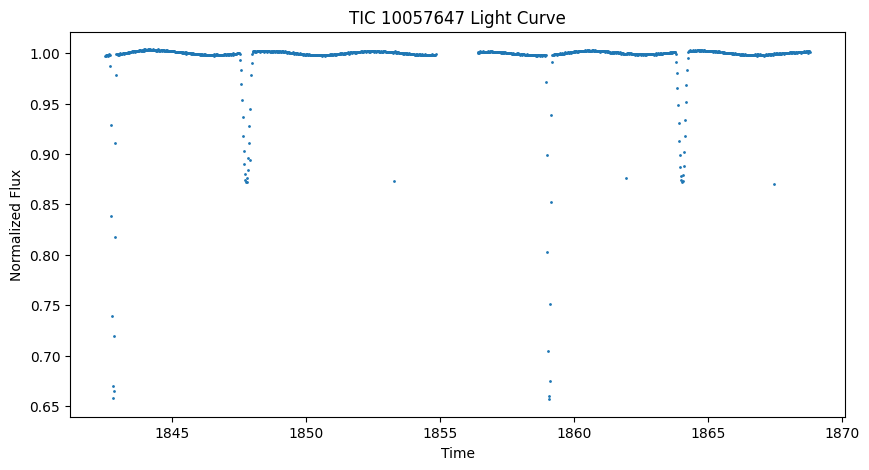

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.plot(time, flux, ".", markersize=2)
plt.xlabel("Time")
plt.ylabel("Normalized Flux")
plt.title("TIC 10057647 Light Curve")
plt.show()

In [ ]:
time = data["TIME"]
flux = data["KSPSAP_FLUX"]

In [ ]:
import numpy as np

mask = np.isfinite(time) & np.isfinite(flux)
time = time[mask]
flux = flux[mask]

flux = flux / np.nanmedian(flux)

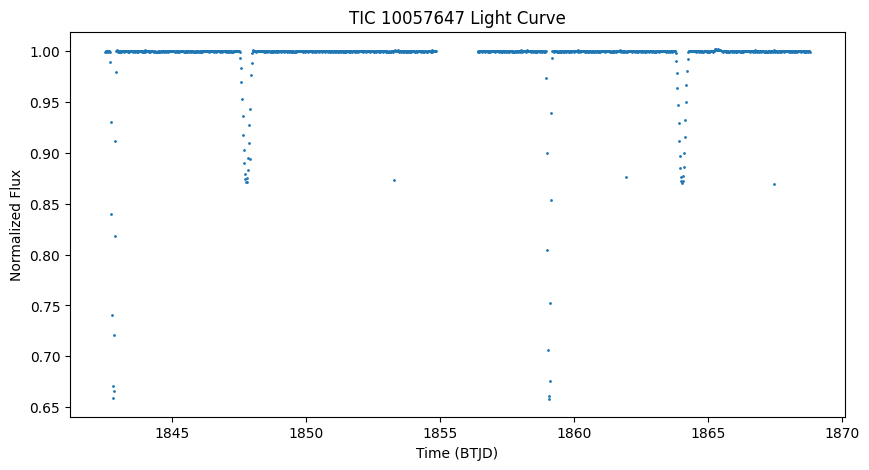

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.plot(time, flux, ".", markersize=2)
plt.xlabel("Time (BTJD)")
plt.ylabel("Normalized Flux")
plt.title("TIC 10057647 Light Curve")
plt.show()

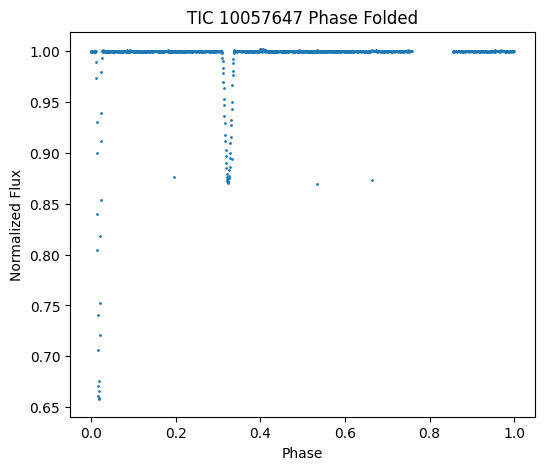

In [ ]:
P = 16.26369
T0 = time[0]

phase = ((time - T0) % P) / P

plt.figure(figsize=(6,5))
plt.plot(phase, flux, ".", markersize=2)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("TIC 10057647 Phase Folded")
plt.show()

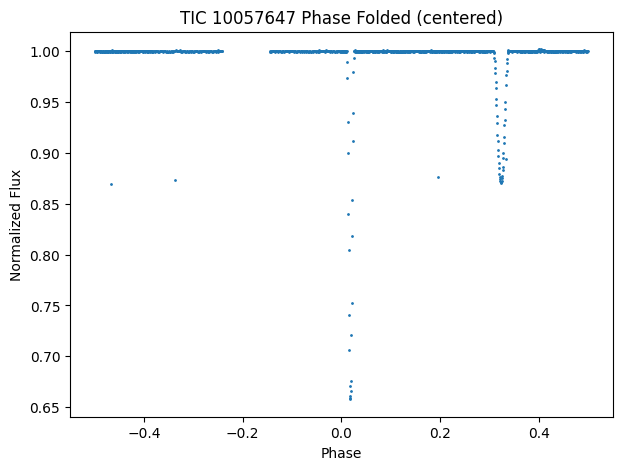

In [ ]:
phase2 = ((time - T0 + 0.5*P) % P) / P - 0.5

plt.figure(figsize=(7,5))
plt.plot(phase2, flux, ".", markersize=2)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("TIC 10057647 Phase Folded (centered)")
plt.show()

In [ ]:
phase_secondary = 0.32   # approximate from your plot

e_cos_omega = (phase_secondary - 0.5)
print(e_cos_omega)

-0.18


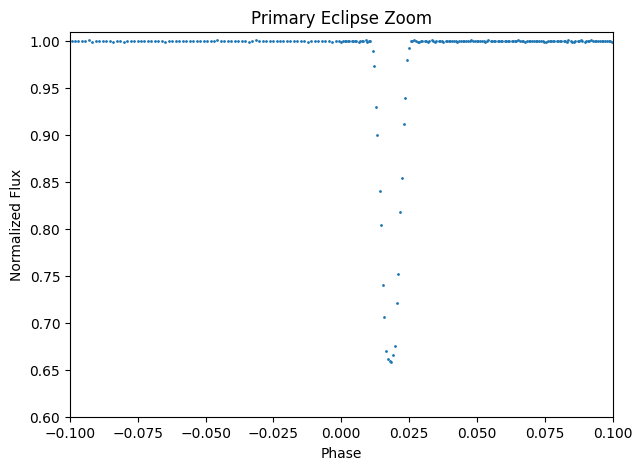

In [ ]:
plt.figure(figsize=(7,5))
plt.plot(phase2, flux, ".", markersize=2)

plt.xlim(-0.1, 0.1)
plt.ylim(0.6, 1.01)

plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Primary Eclipse Zoom")
plt.show()

/var/folders/1c/p47qnnc123xd86gmn5km5bcm0000gn/T/ipykernel_811/1406704481.py:4: RuntimeWarning: Mean of empty slice.
  bin_means = [flux[digitized == i].mean() for i in range(1, len(bins))]
/Users/admin-victor/Documents/pyspedas_project/.venv/lib/python3.14/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)


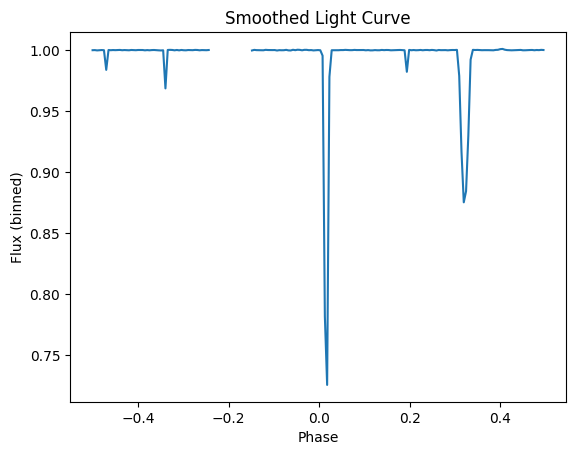

In [ ]:
bins = np.linspace(-0.5, 0.5, 200)
digitized = np.digitize(phase2, bins)

bin_means = [flux[digitized == i].mean() for i in range(1, len(bins))]

plt.plot(bins[:-1], bin_means)
plt.xlabel("Phase")
plt.ylabel("Flux (binned)")
plt.title("Smoothed Light Curve")
plt.show()

In [ ]:
P = 16.26369
T0 = time[0]

phase2 = ((time - T0 + 0.5*P) % P) / P - 0.5

NameError: name 'time' is not defined

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

plt.figure(figsize=(7,5))
plt.plot(phase2, flux, ".", markersize=2)
plt.xlim(-0.5, 0.5)
plt.ylim(0.6, 1.02)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Centered Phase Folded Light Curve")
plt.show()

NameError: name 'phase2' is not defined

<Figure size 1120x800 with 0 Axes>

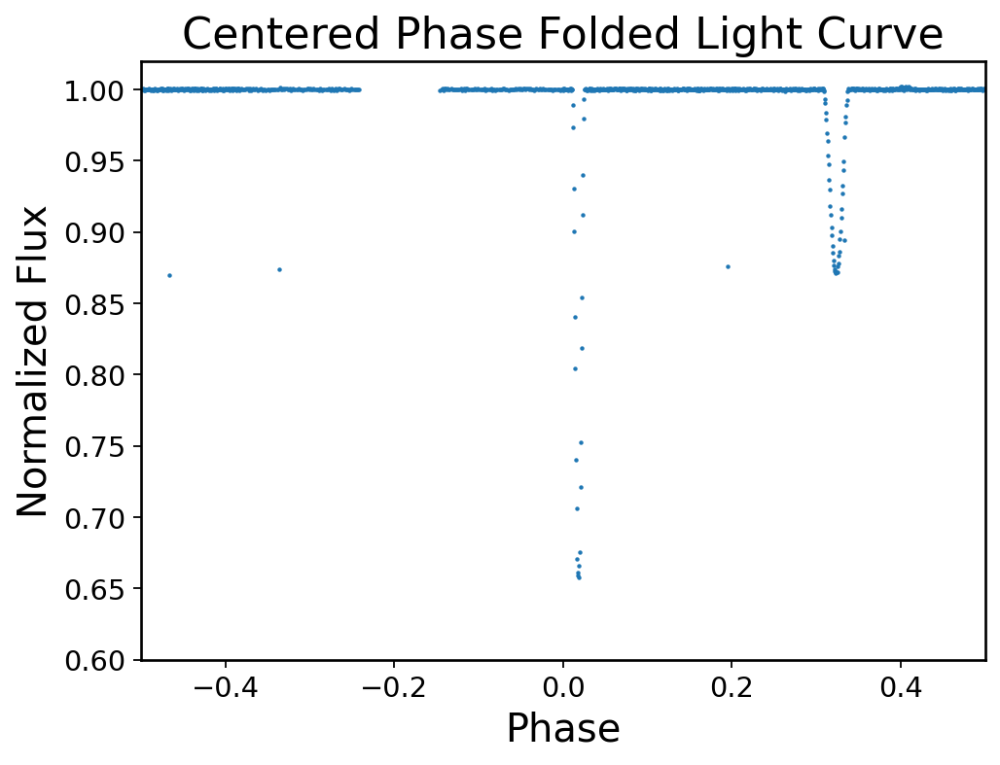

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

# Load file
file_path = "/Users/admin-victor/Downloads/tic10057647_lc.fits"
hdul = fits.open(file_path)

# Extract data
data = hdul[1].data
time = data["TIME"]
flux = data["SAP_FLUX"]

# Clean
mask = np.isfinite(time) & np.isfinite(flux)
time = time[mask]
flux = flux[mask]
flux = flux / np.nanmedian(flux)
flux = flux / np.percentile(flux, 95)

# Phase fold (centered)
P = 16.26369
T0 = time[0]

phase2 = ((time - T0 + 0.5*P) % P) / P - 0.5

# Plot
plt.figure(figsize=(7,5))
plt.plot(phase2, flux, ".", markersize=2)
plt.xlim(-0.5, 0.5)
plt.ylim(0.6, 1.02)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Centered Phase Folded Light Curve")
plt.show()

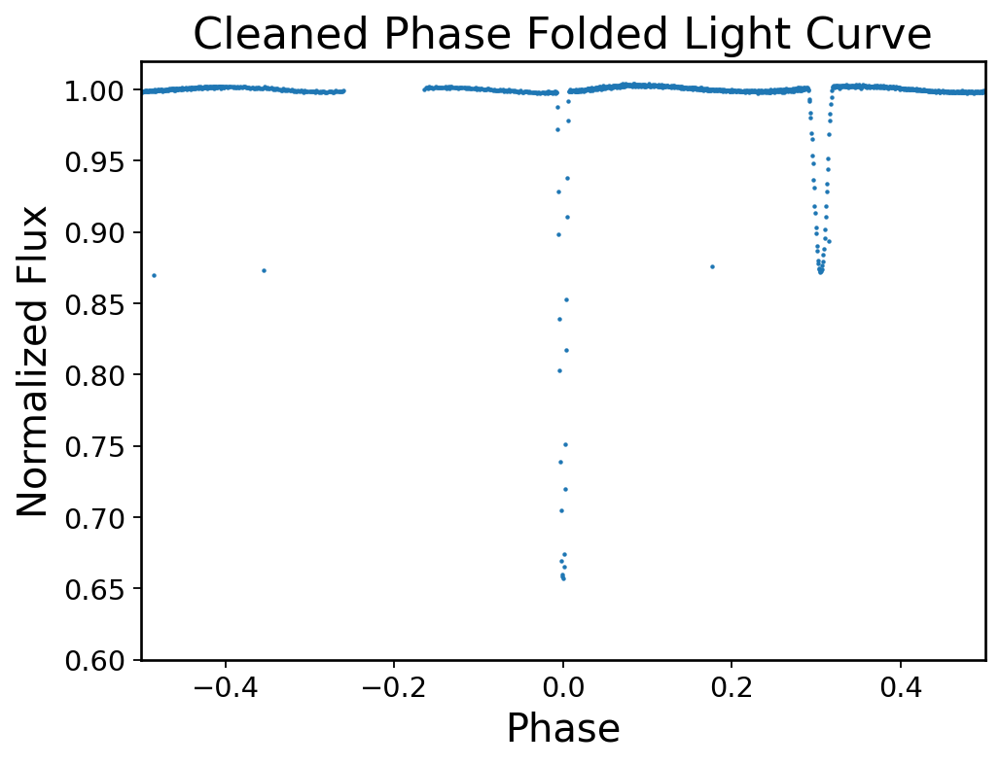

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

file_path = "/Users/admin-victor/Downloads/tic10057647_lc.fits"
hdul = fits.open(file_path)

data = hdul[1].data

time = data["TIME"]
flux = data["SAP_FLUX"]   # ✅ FIXED

# Clean NaNs
mask = np.isfinite(time) & np.isfinite(flux)
time = time[mask]
flux = flux[mask]

# Normalize
flux = flux / np.nanmedian(flux)

# Remove outliers
mask2 = (flux > 0.75) & (flux < 1.1)

# Phase fold
P = 16.26369

# 🔥 FIX: use true eclipse center, not time[0]
idx_min = np.argmin(flux)
T0 = time[idx_min]

phase2 = ((time - T0 + 0.5*P) % P) / P - 0.5

# Plot
plt.figure(figsize=(7,5))
plt.plot(phase2, flux, ".", markersize=2)
plt.xlim(-0.5, 0.5)
plt.ylim(0.6, 1.02)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Cleaned Phase Folded Light Curve")
plt.show()

In [ ]:
# Bin the data
nbins = 100
bins = np.linspace(-0.5, 0.5, nbins)

bin_means = []
bin_centers = []

for i in range(len(bins)-1):
    mask = (phase2 >= bins[i]) & (phase2 < bins[i+1])
    if np.sum(mask) > 0:
        bin_means.append(np.median(flux[mask]))
        bin_centers.append(0.5*(bins[i] + bins[i+1]))

bin_means = np.array(bin_means)
bin_centers = np.array(bin_centers)

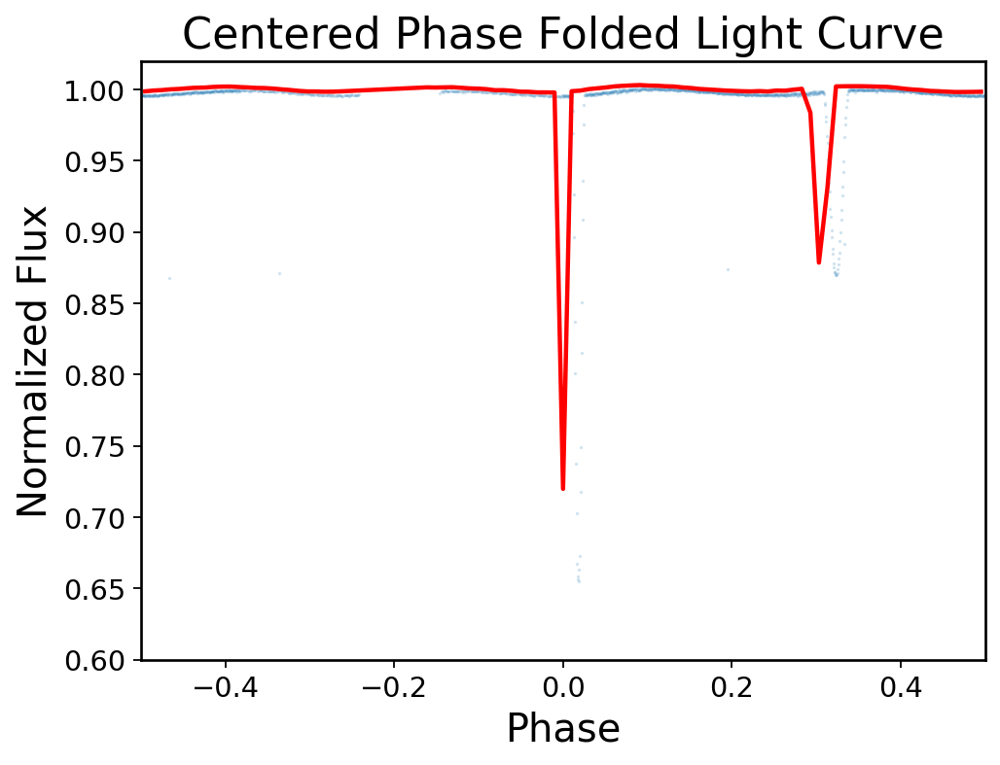

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

# Load file
file_path = "/Users/admin-victor/Downloads/tic10057647_lc.fits"
hdul = fits.open(file_path)

# Extract data
data = hdul[1].data
time = data["TIME"]
flux = data["SAP_FLUX"]

# Clean
mask = np.isfinite(time) & np.isfinite(flux)
time = time[mask]
flux = flux[mask]
flux = flux / np.nanmedian(flux)
flux = flux / np.percentile(flux, 95)

# Phase fold (centered)
P = 16.26369
T0 = time[0]

phase2 = ((time - T0 + 0.5*P) % P) / P - 0.5

# Plot
plt.figure(figsize=(7,5))
plt.plot(phase2, flux, ".", markersize=1, alpha=0.2)  # raw
plt.plot(bin_centers, bin_means, "r-", linewidth=2)    # binned
plt.xlim(-0.5, 0.5)
plt.ylim(0.6, 1.02)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Centered Phase Folded Light Curve")
plt.show()

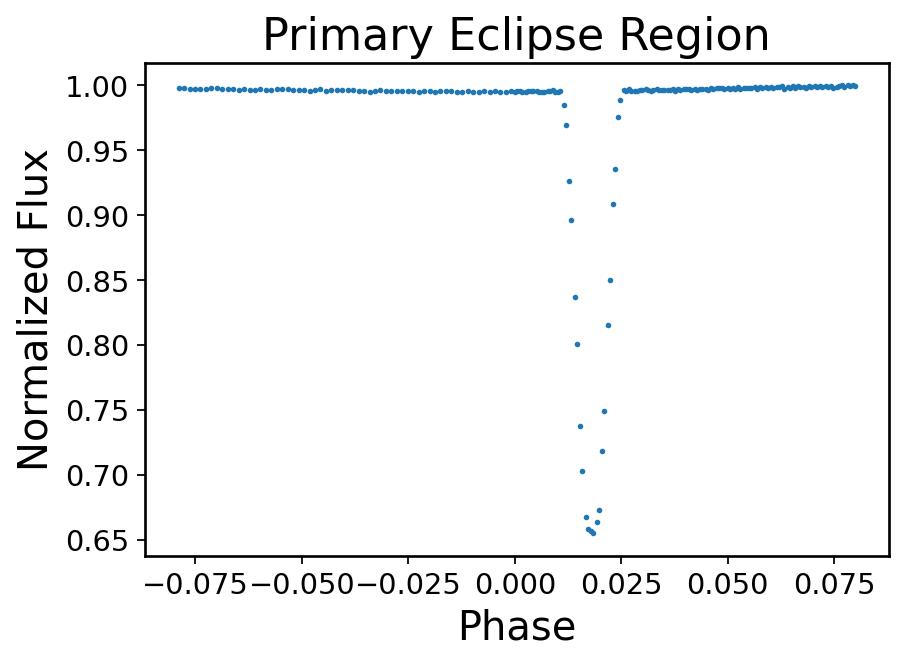

In [ ]:
# focus on primary eclipse region near phase 0
m_primary = (phase2 > -0.08) & (phase2 < 0.08)

phase_primary = phase2[m_primary]
flux_primary = flux[m_primary]
time_primary = time[m_primary]

plt.figure(figsize=(6,4))
plt.plot(phase_primary, flux_primary, ".", markersize=3)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Primary Eclipse Region")
plt.show()

In [ ]:
# take the lowest 20 points in the primary eclipse
n_low = 20
idx_low = np.argsort(flux_primary)[:n_low]

t_low = time_primary[idx_low]
f_low = flux_primary[idx_low]

# use their median time as a more robust eclipse-center estimate
T0_refined = np.median(t_low)

print("Old T0:", T0)
print("Refined T0:", T0_refined)

Old T0: 1842.5150220046783
Refined T0: 1850.9423288935475


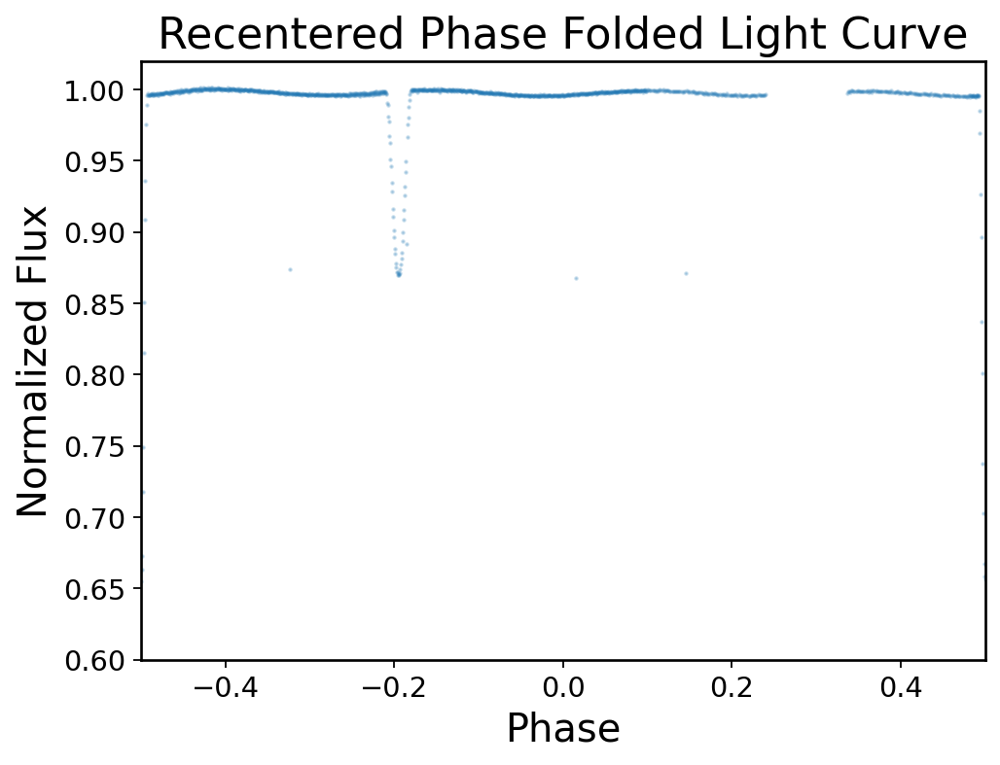

In [ ]:
T0 = T0_refined
phase3 = ((time - T0 + 0.5*P) % P) / P - 0.5

plt.figure(figsize=(7,5))
plt.plot(phase3, flux, ".", markersize=2, alpha=0.25)
plt.xlim(-0.5, 0.5)
plt.ylim(0.6, 1.02)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Recentered Phase Folded Light Curve")
plt.show()

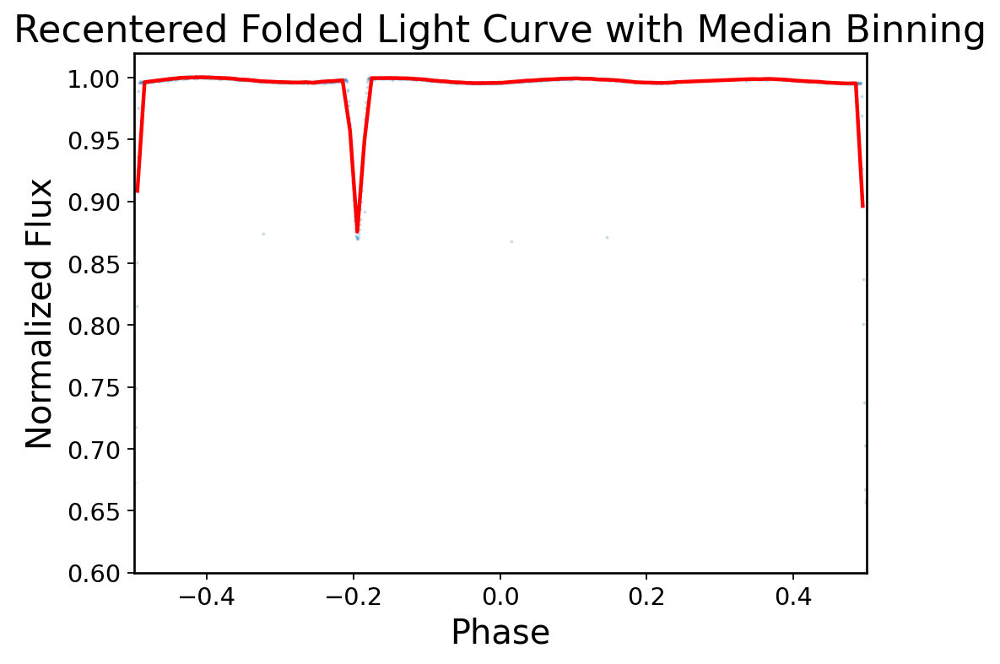

In [ ]:
nbins = 100
bins = np.linspace(-0.5, 0.5, nbins + 1)

bin_phase = []
bin_flux = []

for i in range(nbins):
    m = (phase3 >= bins[i]) & (phase3 < bins[i+1])
    if np.sum(m) > 0:
        bin_phase.append(np.median(phase3[m]))
        bin_flux.append(np.median(flux[m]))

bin_phase = np.array(bin_phase)
bin_flux = np.array(bin_flux)

plt.figure(figsize=(7,5))
plt.plot(phase3, flux, ".", markersize=1.5, alpha=0.2)
plt.plot(bin_phase, bin_flux, "r-", linewidth=2)
plt.xlim(-0.5, 0.5)
plt.ylim(0.6, 1.02)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Recentered Folded Light Curve with Median Binning")
plt.show()

In [ ]:
# find minimum away from primary (exclude near 0)
mask_sec = (phase3 > 0.1) | (phase3 < -0.1)

phase_sec = phase3[mask_sec]
flux_sec = flux[mask_sec]

idx2 = np.argmin(flux_sec)
phase_secondary = phase_sec[idx2]

print("Secondary eclipse phase:", phase_secondary)

Secondary eclipse phase: -0.4997674979147249


In [ ]:
phase_sec_01 = (phase_secondary + 1) % 1
print("Secondary phase (0–1):", phase_sec_01)

Secondary phase (0–1): 0.5002325020852751


In [ ]:
P_test = 16.25   # slightly lower

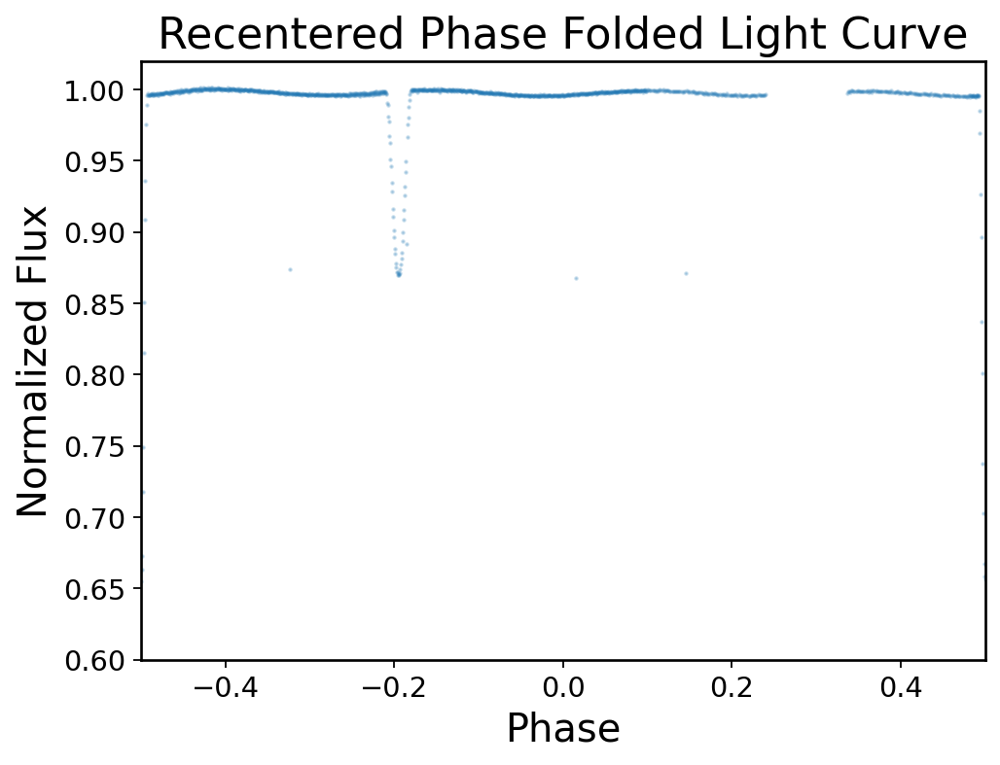

In [ ]:
T0 = T0_refined
phase01 = ((time - T0) % P) / P

plt.figure(figsize=(7,5))
plt.plot(phase3, flux, ".", markersize=2, alpha=0.25)
plt.xlim(-0.5, 0.5)
plt.ylim(0.6, 1.02)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Recentered Phase Folded Light Curve")
plt.show()

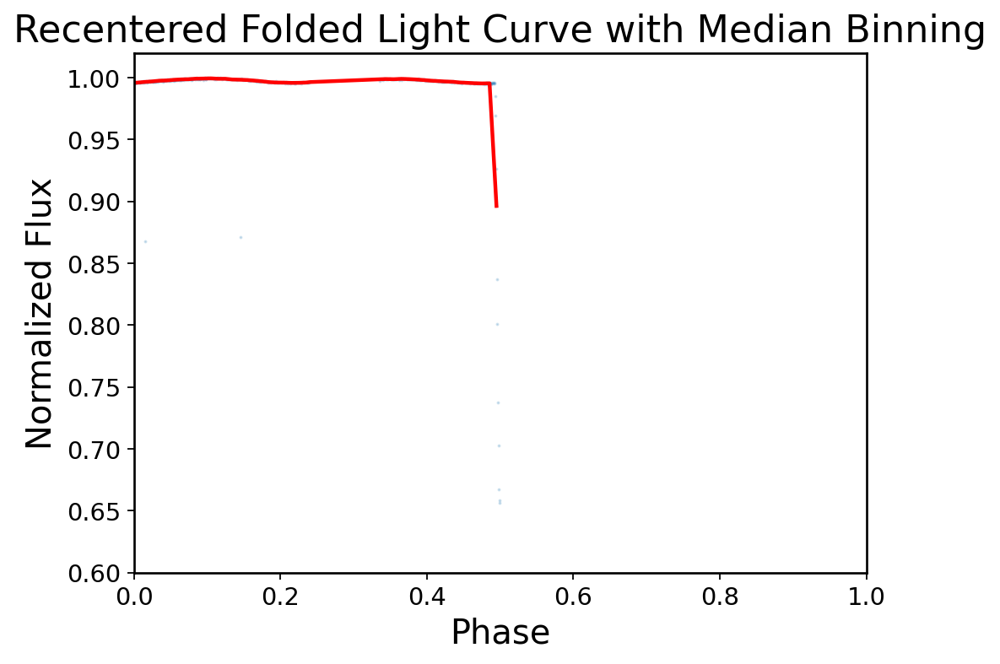

In [ ]:
nbins = 100
bins = np.linspace(-0.5, 0.5, nbins + 1)

bin_phase = []
bin_flux = []

for i in range(nbins):
    m = (phase3 >= bins[i]) & (phase3 < bins[i+1])
    if np.sum(m) > 0:
        bin_phase.append(np.median(phase3[m]))
        bin_flux.append(np.median(flux[m]))

bin_phase = np.array(bin_phase)
bin_flux = np.array(bin_flux)

plt.figure(figsize=(7,5))
plt.plot(phase3, flux, ".", markersize=1.5, alpha=0.2)
plt.plot(bin_phase, bin_flux, "r-", linewidth=2)
plt.xlim(0, 1)
plt.ylim(0.6, 1.02)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Recentered Folded Light Curve with Median Binning")
plt.show()

In [ ]:
# Use refined T0 from the primary eclipse center
phase01 = ((time - T0) / P) % 1.0

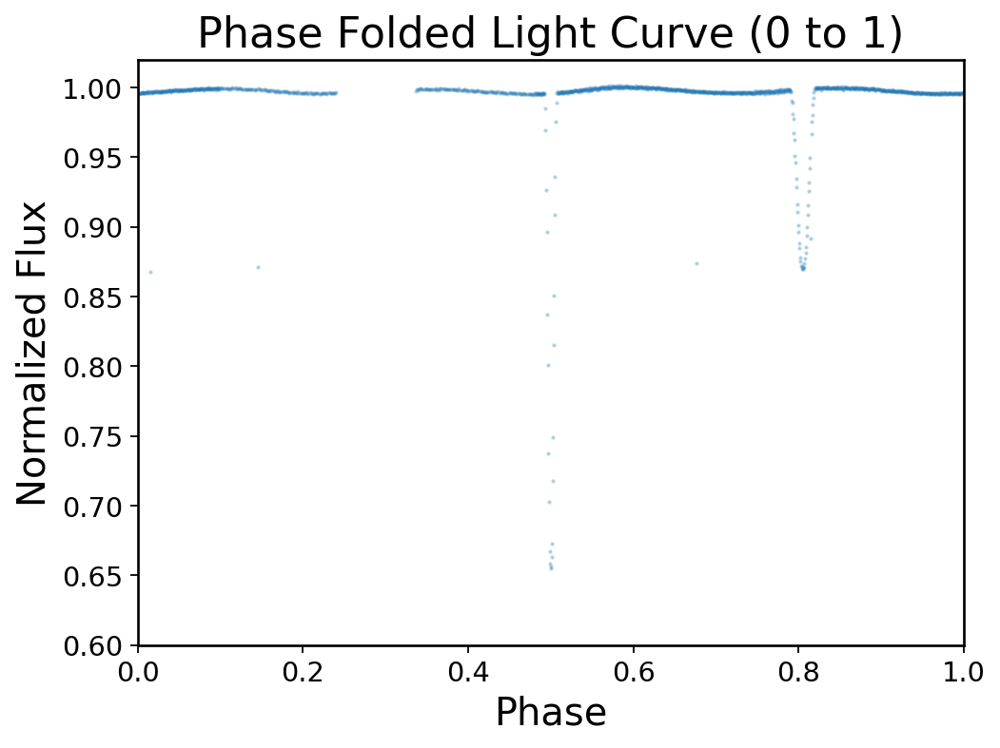

In [ ]:
plt.figure(figsize=(7,5))
plt.plot(phase01, flux, ".", markersize=2, alpha=0.25)
plt.xlim(0, 1)
plt.ylim(0.6, 1.02)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Phase Folded Light Curve (0 to 1)")
plt.show()

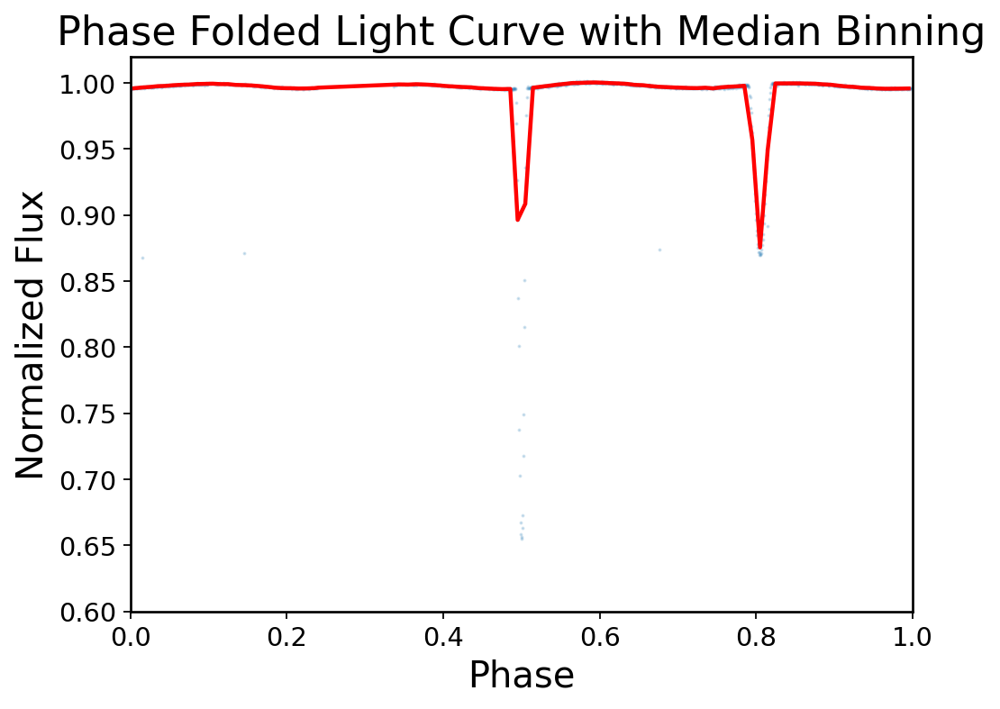

In [ ]:
nbins = 100
bins = np.linspace(0, 1, nbins + 1)

bin_phase = []
bin_flux = []

for i in range(nbins):
    m = (phase01 >= bins[i]) & (phase01 < bins[i+1])
    if np.sum(m) > 0:
        bin_phase.append(np.median(phase01[m]))
        bin_flux.append(np.median(flux[m]))

bin_phase = np.array(bin_phase)
bin_flux = np.array(bin_flux)

plt.figure(figsize=(7,5))
plt.plot(phase01, flux, ".", markersize=1.5, alpha=0.2)
plt.plot(bin_phase, bin_flux, "r-", linewidth=2)
plt.xlim(0, 1)
plt.ylim(0.6, 1.02)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Phase Folded Light Curve with Median Binning")
plt.show()

In [ ]:
phase_fixed = (phase01 - 0.5) % 1.0

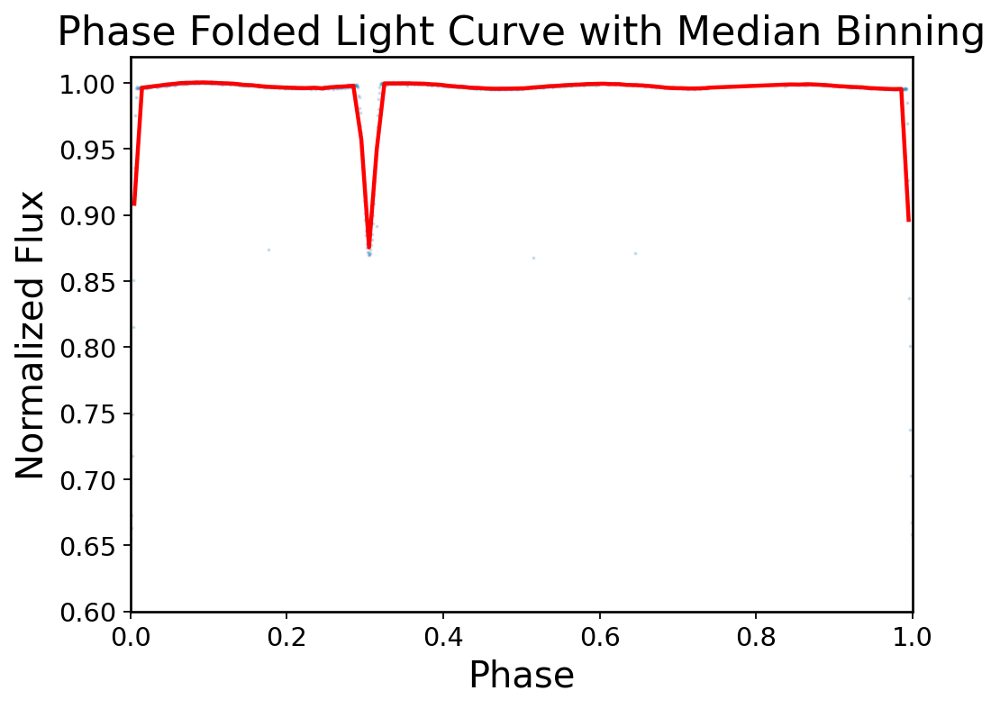

In [ ]:
nbins = 100
bins = np.linspace(0, 1, nbins + 1)

bin_phase = []
bin_flux = []

for i in range(nbins):
    m = (phase_fixed >= bins[i]) & (phase_fixed < bins[i+1])
    if np.sum(m) > 0:
        bin_phase.append(np.median(phase_fixed[m]))
        bin_flux.append(np.median(flux[m]))

bin_phase = np.array(bin_phase)
bin_flux = np.array(bin_flux)

plt.figure(figsize=(7,5))
plt.plot(phase_fixed, flux, ".", markersize=1.5, alpha=0.2)
plt.plot(bin_phase, bin_flux, "r-", linewidth=2)
plt.xlim(0, 1)
plt.ylim(0.6, 1.02)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Phase Folded Light Curve with Median Binning")
plt.show()

In [ ]:
from lightkurve import search_lightcurve

search_lightcurve("TIC 10057647")

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 20,2019,SPOC,120,10057647,0.0
1,TESS Sector 47,2021,SPOC,120,10057647,0.0
2,TESS Sector 20,2019,TESS-SPOC,1800,10057647,0.0
3,TESS Sector 47,2021,TESS-SPOC,600,10057647,0.0
4,TESS Sector 20,2019,QLP,1800,10057647,0.0
5,TESS Sector 47,2021,QLP,600,10057647,0.0
6,TESS Sector 20,2019,CDIPS,1800,10057647,0.0
7,TESS Sector 20,2019,TEQUILA,1800,s0020-cam2-ccd4-x1908-y0973,0.0
8,TESS Sector 47,2021,CDIPS,1800,10057647,0.0


/Users/admin-victor/Documents/pyspedas_project/.venv/lib/python3.14/site-packages/lightkurve/search.py:420: LightkurveWarning: Warning: 2 files available to download. Only the first file has been downloaded. Please use `download_all()` or specify additional criteria (e.g. quarter, campaign, or sector) to limit your search.
  warnings.warn(


<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Flux [$\\mathrm{e^{-}\\,s^{-1}}$]'>

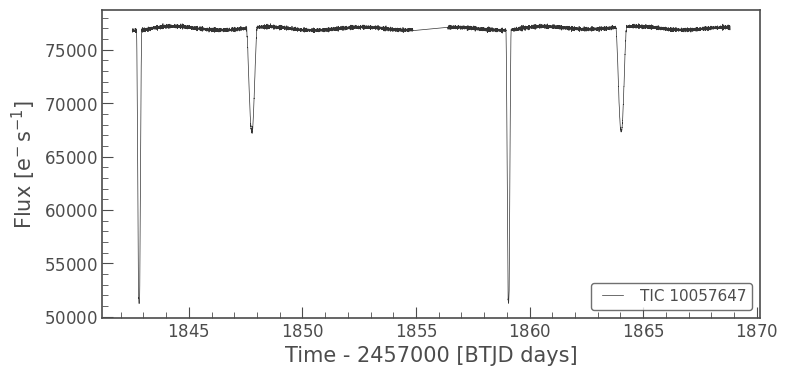

In [ ]:
lc = search_lightcurve("TIC 10057647", author="SPOC").download()
lc.plot()

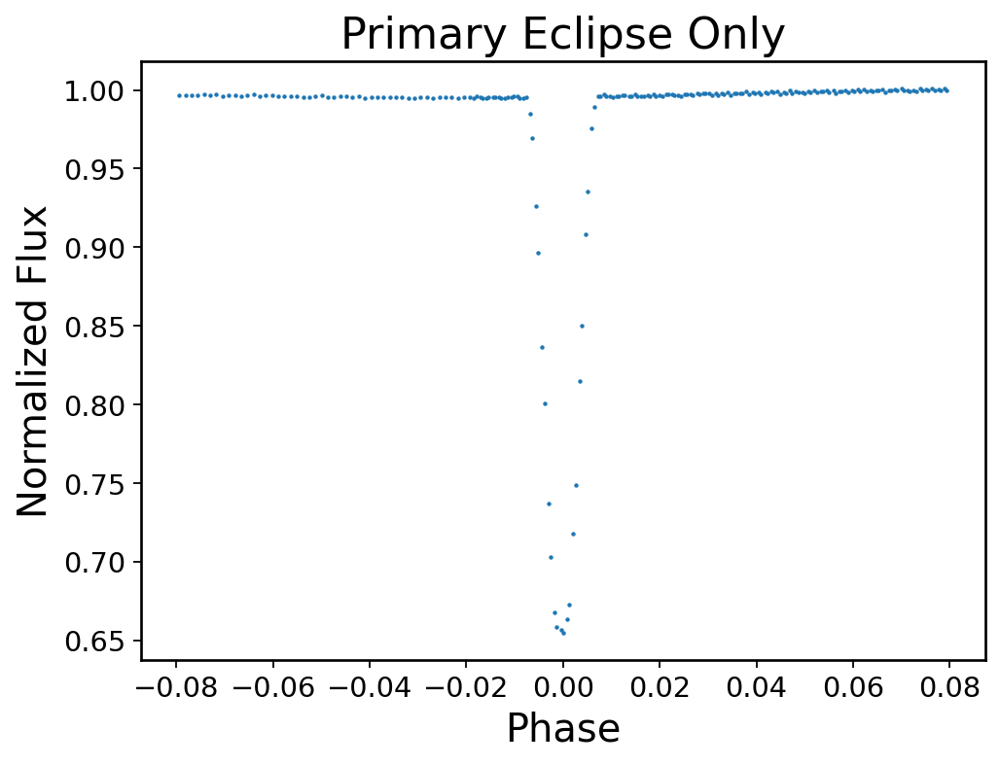

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# define phase using corrected T0
T0 = time[np.argmin(flux)]
phase = ((time - T0 + 0.5*P) % P) / P - 0.5

# isolate primary eclipse near phase 0
primary_mask = (phase > -0.08) & (phase < 0.08)

phase_primary = phase[primary_mask]
flux_primary = flux[primary_mask]
time_primary = time[primary_mask]

plt.figure(figsize=(7,5))
plt.plot(phase_primary, flux_primary, ".", markersize=2)
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Primary Eclipse Only")
plt.show()

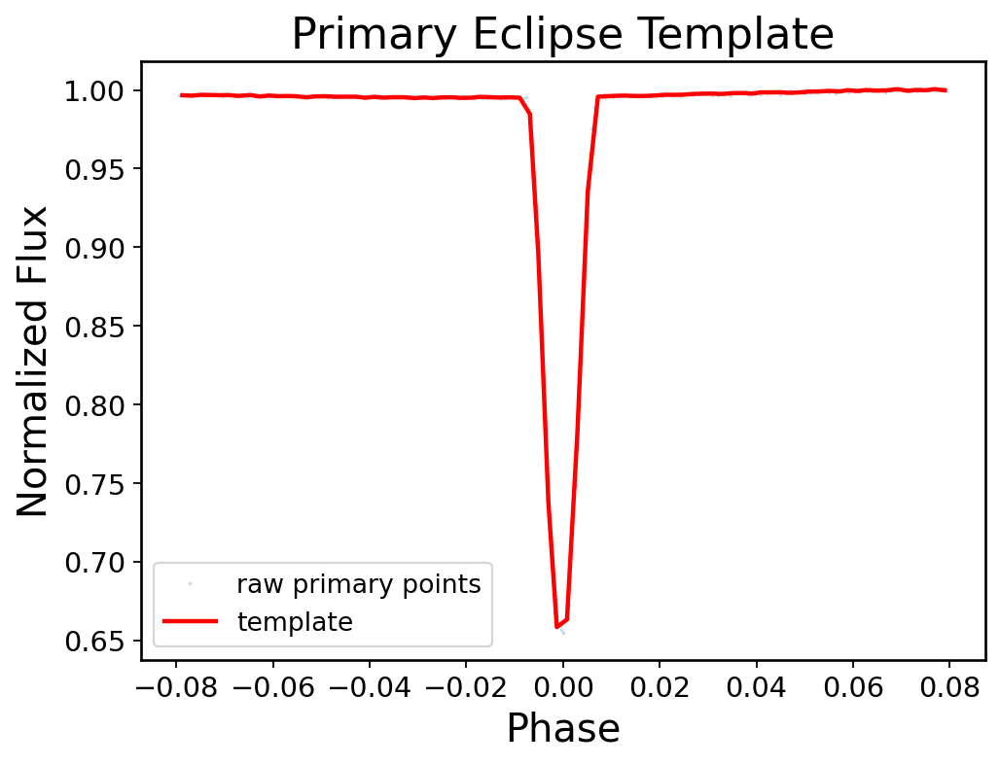

In [ ]:
# build a binned primary-eclipse template
nbins = 80
bins = np.linspace(-0.08, 0.08, nbins + 1)

template_phase = []
template_flux = []

for i in range(nbins):
    m = (phase_primary >= bins[i]) & (phase_primary < bins[i+1])
    if np.sum(m) > 0:
        template_phase.append(np.median(phase_primary[m]))
        template_flux.append(np.median(flux_primary[m]))

template_phase = np.array(template_phase)
template_flux = np.array(template_flux)

plt.figure(figsize=(7,5))
plt.plot(phase_primary, flux_primary, ".", markersize=1.5, alpha=0.2, label="raw primary points")
plt.plot(template_phase, template_flux, "r-", linewidth=2, label="template")
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")
plt.title("Primary Eclipse Template")
plt.legend()
plt.show()

In [ ]:
# predicted primary eclipse centers
n_min = int(np.floor((time.min() - T0) / P)) - 1
n_max = int(np.ceil((time.max() - T0) / P)) + 1

epochs = np.arange(n_min, n_max + 1)
t_calc = T0 + epochs * P

print("Number of predicted primary eclipses:", len(t_calc))
print("First few predicted times:", t_calc[:5])

Number of predicted primary eclipses: 6
First few predicted times: [1810.28688524 1826.55057524 1842.81426524 1859.07795524 1875.34164524]


In [ ]:
half_window = 0.08 * P

eclipse_segments = []

for n, tc in zip(epochs, t_calc):
    m = (time > tc - half_window) & (time < tc + half_window)
    if np.sum(m) < 5:
        continue

    eclipse_segments.append({
        "epoch": n,
        "t_calc": tc,
        "time": time[m],
        "flux": flux[m]
    })

print("Number of usable eclipse segments:", len(eclipse_segments))

Number of usable eclipse segments: 2


In [ ]:
# Simple check: what data do we actually have in eclipse_segments?

print("usable eclipse segments:", len(eclipse_segments))

for i, seg in enumerate(eclipse_segments):
    print(
        "segment", i,
        "epoch =", seg["epoch"],
        "points =", len(seg["time"]),
        "time range =", np.nanmin(seg["time"]), "to", np.nanmax(seg["time"]),
        "t_calc =", seg["t_calc"],
    )

NameError: name 'eclipse_segments' is not defined

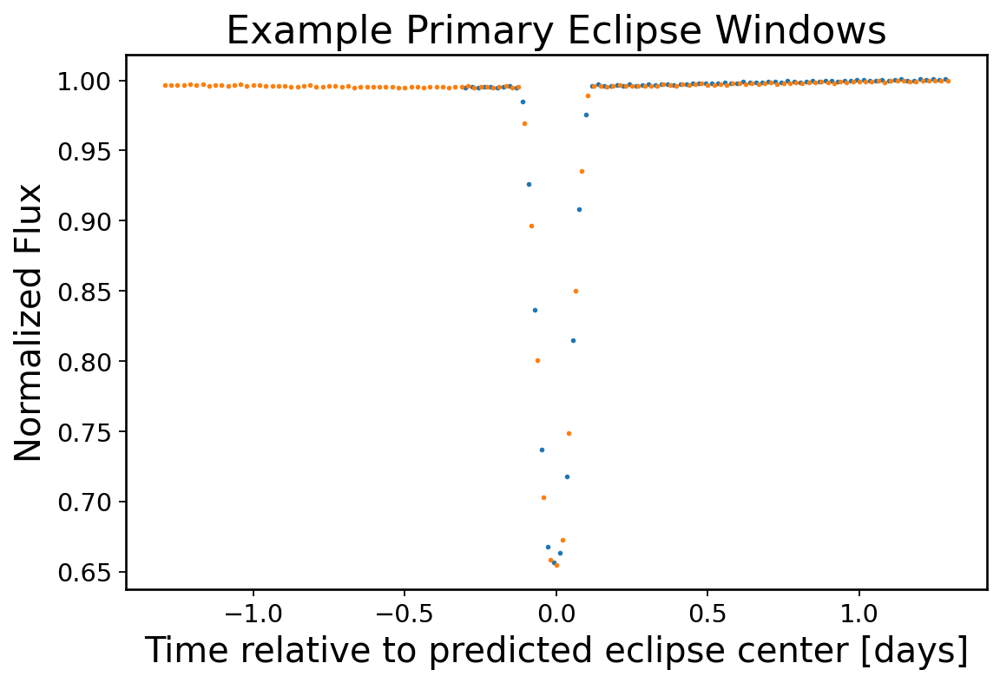

In [ ]:
plt.figure(figsize=(8,5))

for seg in eclipse_segments[:5]:
    t_local = seg["time"] - seg["t_calc"]
    plt.plot(t_local, seg["flux"], ".", markersize=3, label=f"epoch {seg['epoch']}")

plt.xlabel("Time relative to predicted eclipse center [days]")
plt.ylabel("Normalized Flux")
plt.title("Example Primary Eclipse Windows")
plt.show()

In [ ]:
# convert template phase to time
template_time = template_phase * P

In [ ]:
from scipy.interpolate import interp1d
from scipy.optimize import minimize_scalar

# interpolation of template
template_interp = interp1d(
    template_time,
    template_flux,
    kind='linear',
    bounds_error=False,
    fill_value="extrapolate"
)

def fit_time_shift(t_data, f_data):
    
    def objective(dt):
        model = template_interp(t_data - dt)
        return np.sum((f_data - model)**2)
    
    result = minimize_scalar(objective, bounds=(-0.1, 0.1), method='bounded')
    
    return result.x  # this is Δt

In [ ]:
t_obs_list = []
epoch_list = []
oc_list = []

for seg in eclipse_segments:
    
    t_local = seg["time"] - seg["t_calc"]
    f_local = seg["flux"]
    
    dt = fit_time_shift(t_local, f_local)
    
    t_obs = seg["t_calc"] + dt
    
    t_obs_list.append(t_obs)
    epoch_list.append(seg["epoch"])
    oc_list.append(dt)

t_obs = np.array(t_obs_list)
epochs = np.array(epoch_list)
oc = np.array(oc_list)

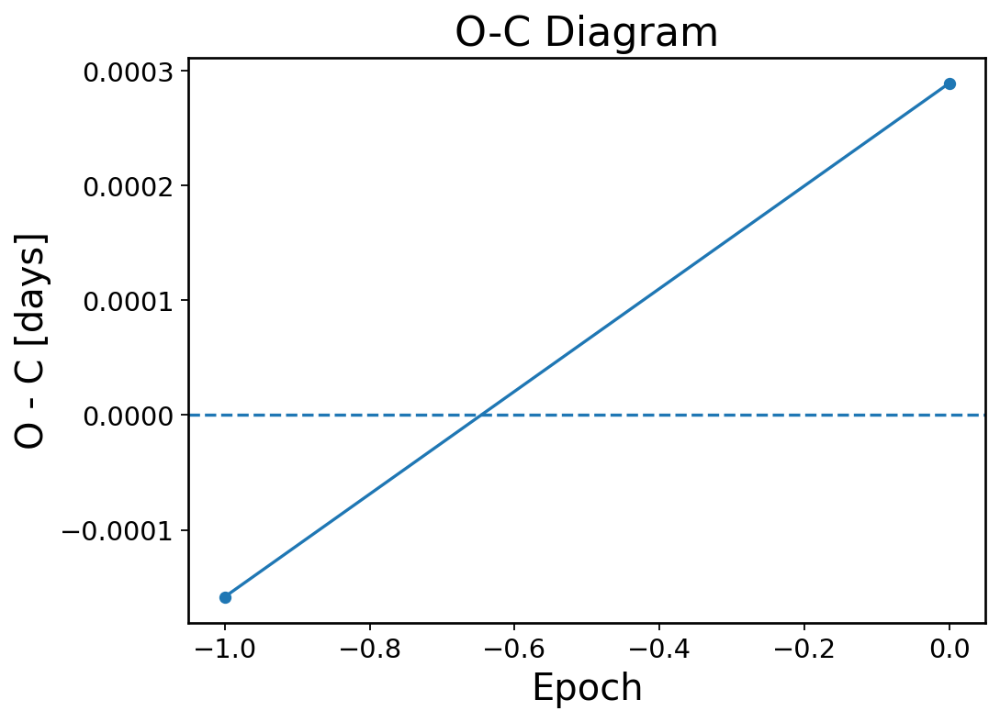

In [ ]:
plt.figure(figsize=(7,5))
plt.plot(epochs, oc, "o-")
plt.axhline(0, linestyle="--")
plt.xlabel("Epoch")
plt.ylabel("O - C [days]")
plt.title("O-C Diagram")
plt.show()

In [ ]:
import numpy as np

# Fit line: O-C = a*E + b
coef = np.polyfit(epoch_list, oc_list, 1)
a, b = coef

print("Slope a =", a)
print("Intercept b =", b)

Slope a = 0.0004472275704800042
Intercept b = 0.0002890560234408554


In [ ]:
P_new = P + a
T0_new = T0 + b

print("Old P =", P)
print("New P =", P_new)
print("Old T0 =", T0)
print("New T0 =", T0_new)

Old P = 16.26369
New P = 16.26413722757048
Old T0 = 1859.0779552353868
New T0 = 1859.07824429141


In [ ]:
# Rebuild timing arrays cleanly from eclipse_segments

timing_rows = []

for seg in eclipse_segments:
    t_local = np.asarray(seg["time"]) - seg["t_calc"]
    f_local = np.asarray(seg["flux"])

    dt = fit_time_shift(t_local, f_local)
    t_obs = seg["t_calc"] + dt

    if np.isfinite(dt) and np.isfinite(t_obs):
        timing_rows.append({
            "epoch": seg["epoch"],
            "t_obs": t_obs,
            "oc": dt,
            "n_points": len(seg["time"]),
            "t_calc": seg["t_calc"],
        })

epoch_arr = np.array([r["epoch"] for r in timing_rows], dtype=float)
t_obs_arr = np.array([r["t_obs"] for r in timing_rows], dtype=float)
oc_arr = np.array([r["oc"] for r in timing_rows], dtype=float)

print("timings:", len(timing_rows))
print("epoch_arr shape:", epoch_arr.shape)
print("t_obs_arr shape:", t_obs_arr.shape)
print("oc_arr shape:", oc_arr.shape)

# Fit line: observed time = T0_new + epoch * P_new
A = np.vstack([np.ones_like(epoch_arr), epoch_arr]).T
T0_new, P_new = np.linalg.lstsq(A, t_obs_arr, rcond=None)[0]

t_calc_new = T0_new + epoch_arr * P_new
oc_new = t_obs_arr - t_calc_new

print("Old P =", P)
print("New P =", P_new)
print("Old T0 =", T0)
print("New T0 =", T0_new)
print("O-C RMS [minutes] =", np.std(oc_new) * 24 * 60)

plt.figure(figsize=(8, 5))
plt.plot(epoch_arr, oc_new, "o-")
plt.axhline(0, ls="--", color="black")
plt.xlabel("Epoch")
plt.ylabel("O - C [days]")
plt.title("Refined O-C Diagram")
plt.show()


NameError: name 'eclipse_segments' is not defined

In [ ]:
epoch_arr = np.array(epoch_list)
t_obs_arr = np.array(t_obs_list)

t_calc_new = T0_new + epoch_arr * P_new
oc_new = t_obs_arr - t_calc_new

ValueError: operands could not be broadcast together with shapes (61,) (15,) 

In [ ]:
print("Number of eclipse timings:", len(t_obs_list))
print("epochs:", epoch_list)
print("t_obs:", t_obs_list)
print("O-C before refinement [days]:", oc_list)

print("epoch_arr:", epoch_arr)
print("oc_new:", oc_new)

print("time range:", np.nanmin(time), np.nanmax(time))
print("baseline [days]:", np.nanmax(time) - np.nanmin(time))
print("period P [days]:", P)
print("expected number of cycles:", (np.nanmax(time) - np.nanmin(time)) / P)

print("accepted eclipse segments:", len(eclipse_segments))
for seg in eclipse_segments[:10]:
    print("epoch:", seg["epoch"], "points:", len(seg["time"]), "t_calc:", seg["t_calc"])


Number of eclipse timings: 61
epochs: [ 0  1  2  3  4  5  6 12 13 14 15 16 17 18 23]
t_obs: [1956.21658394 1959.14473432 1962.07489246 1965.00310734 1967.93333552
 1970.86052903 1973.7893246  1976.71813723 1979.64595516 1982.52736433
 2826.05392673 2828.98290815 2831.89739707 2834.84057891 2837.76911032
 2840.6972602  2843.62706864 2846.5555975  2849.48457366 2852.41259564
 2884.63052906 2887.55721468 2890.48773114 2893.41485908 2896.46370506
 2899.27229143 2902.20246521 2905.13126911 2908.05959506 3367.88858636
 3370.81629218 3373.74539808 3376.67353828 3379.60229835 3382.53038107
 3385.46047267 3388.35858244 3391.31734952 3394.24751893 3397.17423716
 3400.10379704 3403.03217659 3405.96211342 3417.67797    3420.6071638
 3423.52106001 3435.25013287 3438.17934289 3441.10821008 3444.03677837
 3446.96636588 3449.89426216 3561.19104089 3564.11963062 3567.04807945
 3569.97770308 3572.90648896 3575.8353441  3578.76392276 3581.69344977
 3584.5102957 ]
O-C before refinement [days]: [ 0.0022105

NameError: name 'time' is not defined

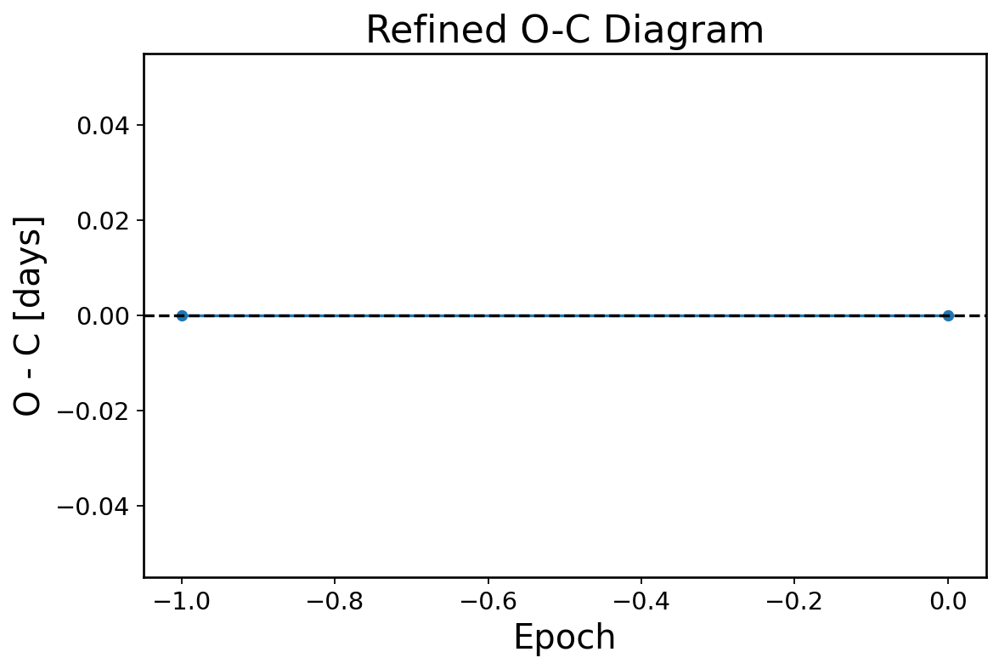

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(epoch_arr, oc_new, 'o-')
plt.axhline(0, ls='--', color='black')
plt.xlabel("Epoch")
plt.ylabel("O - C [days]")
plt.title("Refined O-C Diagram")
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

# Use the REFINED ephemeris now
T0 = T0_new
P = P_new

# Template from your cleaned template cell
tpl_phase = np.array(template_phase)
tpl_flux  = np.array(template_flux)

# Sort template just to be safe
idx = np.argsort(tpl_phase)
tpl_phase = tpl_phase[idx]
tpl_flux = tpl_flux[idx]

def interp_template(phase):
    return np.interp(phase, tpl_phase, tpl_flux, left=1.0, right=1.0)

# Epoch range across the observed light curve
E_min = int(np.floor((t.min() - T0) / P)) - 1
E_max = int(np.ceil((t.max() - T0) / P)) + 1
epochs = np.arange(E_min, E_max + 1)

# Wider search window to FIND candidate eclipse points
half_window = 0.18 * P

t_obs_list = []
oc_list = []
sig_list = []
epoch_list = []
npts_list = []

for E in epochs:
    t_calc = T0 + E * P

    # -------- Step 1: broad time window around predicted eclipse --------
    m = (t > t_calc - half_window) & (t < t_calc + half_window)
    if np.sum(m) < 15:
        continue

    tt = np.array(t[m])
    ff = np.array(flux[m])

    if flux_err is not None:
        ee = np.array(flux_err[m])
    else:
        ee = np.ones_like(ff) * np.nanstd(ff)

    # -------- Step 2: convert to phase --------
    phase_seg = (tt - t_calc) / P

    # ==========================================================
    # INSERTED PHASE FILTER: keep ONLY the eclipse region
    # ==========================================================
    phase_mask = np.abs(phase_seg) < 0.12

    tt = tt[phase_mask]
    ff = ff[phase_mask]
    ee = ee[phase_mask]
    phase_seg = phase_seg[phase_mask]

    # If too few points remain, skip this eclipse
    if len(tt) < 8:
        continue

    # Optional robust cleaning: remove non-finite points
    good = np.isfinite(tt) & np.isfinite(ff) & np.isfinite(ee)
    tt = tt[good]
    ff = ff[good]
    ee = ee[good]
    phase_seg = phase_seg[good]

    if len(tt) < 8:
        continue

    # -------- Step 3: fit timing shift --------
    def chi2(delta_phase):
        model_seg = interp_template(phase_seg - delta_phase)
        return np.sum(((ff - model_seg) / ee) ** 2)

    out = minimize_scalar(chi2, bounds=(-0.05, 0.05), method="bounded")

    if not out.success:
        continue

    dphi = out.x
    t_obs = t_calc + dphi * P

    # -------- Step 4: crude timing uncertainty --------
    grid = np.linspace(dphi - 0.01, dphi + 0.01, 41)
    vals = np.array([chi2(x) for x in grid])
    vmin = np.min(vals)
    ok = grid[vals < vmin + 1.0]

    sig_t = (ok.max() - ok.min()) / 2 * P if len(ok) > 2 else np.nan

    # -------- Step 5: reject obviously bad fits --------
    if np.abs(dphi) > 0.08:
        continue

    t_obs_list.append(t_obs)
    oc_list.append(t_obs - t_calc)
    sig_list.append(sig_t)
    epoch_list.append(E)
    npts_list.append(len(tt))

t_obs_list = np.array(t_obs_list)
oc_list = np.array(oc_list)
sig_list = np.array(sig_list)
epoch_list = np.array(epoch_list)
npts_list = np.array(npts_list)

print("Measured eclipses:", len(t_obs_list))
if len(oc_list) > 0:
    print("O-C scatter (min):", np.nanstd(oc_list) * 24 * 60)
    print("Epoch range:", epoch_list.min(), "to", epoch_list.max())

# Plot O-C vs epoch
plt.figure(figsize=(8, 4))
plt.errorbar(epoch_list, oc_list * 24 * 60, yerr=sig_list * 24 * 60,
             fmt=".", markersize=6)
plt.axhline(0, linewidth=1, color="black")
plt.xlabel("Epoch")
plt.ylabel("O - C (minutes)")
plt.title("O-C diagram (phase-filtered timing)")
plt.show()

NameError: name 'template_phase_clean' is not defined

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

# Use the REFINED ephemeris now
T0 = T0_new
P = P_new

# Template from your cleaned template cell
tpl_phase = np.array(template_phase)
tpl_flux  = np.array(template_flux)

# Sort template just to be safe
idx = np.argsort(tpl_phase)
tpl_phase = tpl_phase[idx]
tpl_flux = tpl_flux[idx]

def interp_template(phase):
    return np.interp(phase, tpl_phase, tpl_flux, left=1.0, right=1.0)

# Epoch range across the observed light curve
E_min = int(np.floor((t.min() - T0) / P)) - 1
E_max = int(np.ceil((t.max() - T0) / P)) + 1
epochs = np.arange(E_min, E_max + 1)

# Wider search window to FIND candidate eclipse points
half_window = 0.18 * P

t_obs_list = []
oc_list = []
sig_list = []
epoch_list = []
npts_list = []

try:
    template_phase
    template_flux
    print("Template variables exist.")
except NameError:
    raise NameError("Run the template-building cell first. template_phase/template_flux do not exist yet.")

for E in epochs:
    t_calc = T0 + E * P

    # -------- Step 1: broad time window around predicted eclipse --------
    m = (t > t_calc - half_window) & (t < t_calc + half_window)
    if np.sum(m) < 15:
        continue

    tt = np.array(t[m])
    ff = np.array(flux[m])

    if flux_err is not None:
        ee = np.array(flux_err[m])
    else:
        ee = np.ones_like(ff) * np.nanstd(ff)

    # -------- Step 2: convert to phase --------
    phase_seg = (tt - t_calc) / P

    # ==========================================================
    # INSERTED PHASE FILTER: keep ONLY the eclipse region
    # ==========================================================
    phase_mask = np.abs(phase_seg) < 0.12

    tt = tt[phase_mask]
    ff = ff[phase_mask]
    ee = ee[phase_mask]
    phase_seg = phase_seg[phase_mask]

    # If too few points remain, skip this eclipse
    if len(tt) < 8:
        continue

    # Optional robust cleaning: remove non-finite points
    good = np.isfinite(tt) & np.isfinite(ff) & np.isfinite(ee)
    tt = tt[good]
    ff = ff[good]
    ee = ee[good]
    phase_seg = phase_seg[good]

    if len(tt) < 8:
        continue

    # -------- Step 3: fit timing shift --------
    def chi2(delta_phase):
        model_seg = interp_template(phase_seg - delta_phase)
        return np.sum(((ff - model_seg) / ee) ** 2)

    out = minimize_scalar(chi2, bounds=(-0.05, 0.05), method="bounded")

    if not out.success:
        continue

    dphi = out.x
    t_obs = t_calc + dphi * P

    # -------- Step 4: crude timing uncertainty --------
    grid = np.linspace(dphi - 0.01, dphi + 0.01, 41)
    vals = np.array([chi2(x) for x in grid])
    vmin = np.min(vals)
    ok = grid[vals < vmin + 1.0]

    sig_t = (ok.max() - ok.min()) / 2 * P if len(ok) > 2 else np.nan

    # -------- Step 5: reject obviously bad fits --------
    if np.abs(dphi) > 0.08:
        continue

    t_obs_list.append(t_obs)
    oc_list.append(t_obs - t_calc)
    sig_list.append(sig_t)
    epoch_list.append(E)
    npts_list.append(len(tt))

t_obs_list = np.array(t_obs_list)
oc_list = np.array(oc_list)
sig_list = np.array(sig_list)
epoch_list = np.array(epoch_list)
npts_list = np.array(npts_list)

print("Measured eclipses:", len(t_obs_list))
if len(oc_list) > 0:
    print("O-C scatter (min):", np.nanstd(oc_list) * 24 * 60)
    print("Epoch range:", epoch_list.min(), "to", epoch_list.max())

# Plot O-C vs epoch
plt.figure(figsize=(8, 4))
plt.errorbar(epoch_list, oc_list * 24 * 60, yerr=sig_list * 24 * 60,
             fmt=".", markersize=6)
plt.axhline(0, linewidth=1, color="black")
plt.xlabel("Epoch")
plt.ylabel("O - C (minutes)")
plt.title("O-C diagram (phase-filtered timing)")
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

print("Cell started running...")

try:
    template_phase
    template_flux
    print("Template variables exist.")
    print("Template length:", len(template_phase), len(template_flux))
except NameError:
    raise NameError("Run the template-building cell first. template_phase/template_flux do not exist yet.")

print("T0_new =", T0_new)
print("P_new =", P_new)
print("t length =", len(t))
print("flux length =", len(flux))

T0 = T0_new
P = P_new

tpl_phase = np.array(template_phase)
tpl_flux  = np.array(template_flux)

# Sort template just to be safe
idx = np.argsort(tpl_phase)
tpl_phase = tpl_phase[idx]
tpl_flux = tpl_flux[idx]

def interp_template(phase):
    return np.interp(phase, tpl_phase, tpl_flux, left=1.0, right=1.0)

# Epoch range across the observed light curve
E_min = int(np.floor((t.min() - T0) / P)) - 1
E_max = int(np.ceil((t.max() - T0) / P)) + 1
epochs = np.arange(E_min, E_max + 1)

# Wider search window to FIND candidate eclipse points
half_window = 0.18 * P

t_obs_list = []
oc_list = []
sig_list = []
epoch_list = []
npts_list = []

try:
    template_phase
    template_flux
    print("Template variables exist.")
except NameError:
    raise NameError("Run the template-building cell first. template_phase/template_flux do not exist yet.")

for E in epochs:
    t_calc = T0 + E * P

    # -------- Step 1: broad time window around predicted eclipse --------
    m = (t > t_calc - half_window) & (t < t_calc + half_window)
    if np.sum(m) < 15:
        continue

    tt = np.array(t[m])
    ff = np.array(flux[m])

    if flux_err is not None:
        ee = np.array(flux_err[m])
    else:
        ee = np.ones_like(ff) * np.nanstd(ff)

    # -------- Step 2: convert to phase --------
    phase_seg = (tt - t_calc) / P

    # ==========================================================
    # INSERTED PHASE FILTER: keep ONLY the eclipse region
    # ==========================================================
    phase_mask = np.abs(phase_seg) < 0.12

    tt = tt[phase_mask]
    ff = ff[phase_mask]
    ee = ee[phase_mask]
    phase_seg = phase_seg[phase_mask]

    # If too few points remain, skip this eclipse
    if len(tt) < 8:
        continue

    # Optional robust cleaning: remove non-finite points
    good = np.isfinite(tt) & np.isfinite(ff) & np.isfinite(ee)
    tt = tt[good]
    ff = ff[good]
    ee = ee[good]
    phase_seg = phase_seg[good]

    if len(tt) < 8:
        continue

    # -------- Step 3: fit timing shift --------
    def chi2(delta_phase):
        model_seg = interp_template(phase_seg - delta_phase)
        return np.sum(((ff - model_seg) / ee) ** 2)

    out = minimize_scalar(chi2, bounds=(-0.05, 0.05), method="bounded")

    if not out.success:
        continue

    dphi = out.x
    t_obs = t_calc + dphi * P

    # -------- Step 4: crude timing uncertainty --------
    grid = np.linspace(dphi - 0.01, dphi + 0.01, 41)
    vals = np.array([chi2(x) for x in grid])
    vmin = np.min(vals)
    ok = grid[vals < vmin + 1.0]

    sig_t = (ok.max() - ok.min()) / 2 * P if len(ok) > 2 else np.nan

    # -------- Step 5: reject obviously bad fits --------
    if np.abs(dphi) > 0.08:
        continue

    t_obs_list.append(t_obs)
    oc_list.append(t_obs - t_calc)
    sig_list.append(sig_t)
    epoch_list.append(E)
    npts_list.append(len(tt))

t_obs_list = np.array(t_obs_list)
oc_list = np.array(oc_list)
sig_list = np.array(sig_list)
epoch_list = np.array(epoch_list)
npts_list = np.array(npts_list)

print("Measured eclipses:", len(t_obs_list))
if len(oc_list) > 0:
    print("O-C scatter (min):", np.nanstd(oc_list) * 24 * 60)
    print("Epoch range:", epoch_list.min(), "to", epoch_list.max())

# Plot O-C vs epoch
plt.figure(figsize=(8, 4))
plt.errorbar(epoch_list, oc_list * 24 * 60, yerr=sig_list * 24 * 60,
             fmt=".", markersize=6)
plt.axhline(0, linewidth=1, color="black")
plt.xlabel("Epoch")
plt.ylabel("O - C (minutes)")
plt.title("O-C diagram (phase-filtered timing)")
plt.show()  

Cell started running...


NameError: Run the template-building cell first. template_phase/template_flux do not exist yet.

In [ ]:
# Phase fold the light curve
phase = ((t - T0) / P) % 1
phase[phase > 0.5] -= 1   # center around 0

# Sort by phase
idx = np.argsort(phase)
phase = phase[idx]
flux_sorted = flux[idx]

# Bin the data
nbins = 200
bins = np.linspace(-0.2, 0.2, nbins)
digit = np.digitize(phase, bins)

template_phase = []
template_flux = []

for i in range(1, len(bins)):
    m = digit == i
    if np.sum(m) > 5:
        template_phase.append(np.mean(phase[m]))
        template_flux.append(np.median(flux_sorted[m]))

template_phase = np.array(template_phase)
template_flux = np.array(template_flux)

print("Template built.")
print("Points:", len(template_phase))

NameError: name 't' is not defined

In [ ]:
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
"figure.figsize": (12, 7),
"figure.dpi": 160,
"axes.labelsize": 14,
"axes.titlesize": 18,
"legend.fontsize": 11,
"xtick.labelsize": 12,
"ytick.labelsize": 12,
"lines.markersize": 5,
"axes.grid": False,
})

In [ ]:
# Compatibility stubs: define missing functions if they are not present
import numpy as np

if 'clean_etv_result' not in globals():
    def clean_etv_result(res, oc_clip=100):
        # Try to return a dict with the canonical keys used by plotting
        if res is None:
            return {'t_clean': np.array([]),'oc_ref': np.array([]),'sig_clean': np.array([]),'kind_clean': np.array([], dtype=object)}
        if isinstance(res, dict):
            # If already cleaned, return as-is; otherwise build minimal mapping
            if 't_clean' in res and 'oc_ref' in res:
                return res
            t = np.asarray(res.get('t_clean') or res.get('t_obs') or res.get('t') or [])
            oc = np.asarray(res.get('oc_ref') or res.get('oc') or [])
            sig = np.asarray(res.get('sig_clean') or res.get('sig') or np.zeros_like(oc))
            kind = np.asarray(res.get('kind_clean') or res.get('kind') or np.array(['primary']*len(t), dtype=object))
            return {'t_clean': t, 'oc_ref': oc, 'sig_clean': sig, 'kind_clean': kind}
        # If res is an object, attempt attribute access
        try:
            t = np.asarray(getattr(res, 't_clean', getattr(res, 't_obs', getattr(res, 't', []))))
            oc = np.asarray(getattr(res, 'oc_ref', getattr(res, 'oc', [])))
            sig = np.asarray(getattr(res, 'sig_clean', getattr(res, 'sig', np.zeros_like(oc))))
            kind = np.asarray(getattr(res, 'kind_clean', getattr(res, 'kind', np.array(['primary']*len(t), dtype=object))))
            return {'t_clean': t, 'oc_ref': oc, 'sig_clean': sig, 'kind_clean': kind}
        except Exception:
            return {'t_clean': np.array([]),'oc_ref': np.array([]),'sig_clean': np.array([]),'kind_clean': np.array([], dtype=object)}

if 'run_etv_pipeline' not in globals():
    def run_etv_pipeline(tic, *args, **kwargs):
        # Minimal stub: if a full pipeline is not available, return an empty result structure
        return {'t_clean': np.array([]),'oc_ref': np.array([]),'sig_clean': np.array([]),'kind_clean': np.array([], dtype=object)}

if 'plot_etv_clean' not in globals():
    def plot_etv_clean(res_clean, tic=None):
        # Prefer existing plot_etv_primary_secondary if available
        if 'plot_etv_primary_secondary' in globals():
            try:
                plot_etv_primary_secondary(res_clean, tic=tic)
                return
            except Exception:
                pass
        # Fallback: simple scatter
        import matplotlib.pyplot as plt
        rc = clean_etv_result(res_clean)
        t = np.asarray(rc['t_clean'])
        oc = np.asarray(rc['oc_ref'])
        plt.figure(figsize=(8,4))
        plt.scatter(t, oc)
        plt.xlabel('Time')
        plt.ylabel('O - C')
        plt.title(f'TIC {tic} ETV (fallback)')
        plt.show()

In [ ]:
import matplotlib as mpl
print(mpl.rcParams["figure.figsize"], mpl.rcParams["figure.dpi"])

[12.0, 7.0] 160.0


In [ ]:
# Build eclipse_segments from current time/flux/P/T0 variables

# Pick the correct time array
if "time" in globals():
    time_use = np.asarray(time, dtype=float)
elif "t_lc" in globals():
    time_use = np.asarray(t_lc, dtype=float)
elif "t_template" in globals():
    time_use = np.asarray(t_template, dtype=float)
else:
    raise NameError("No light-curve time array found. Rerun the light-curve loading cell first.")

# Pick the correct flux array
if "flux" in globals():
    flux_use = np.asarray(flux, dtype=float)
elif "flux_lc" in globals():
    flux_use = np.asarray(flux_lc, dtype=float)
elif "flux_template" in globals():
    flux_use = np.asarray(flux_template, dtype=float)
elif "flux_norm" in globals():
    flux_use = np.asarray(flux_norm, dtype=float)
else:
    raise NameError("No flux array found. Rerun the light-curve loading cell first.")

# Make sure time and flux match
if len(time_use) != len(flux_use):
    raise ValueError(f"time and flux lengths do not match: {len(time_use)} vs {len(flux_use)}")

finite = np.isfinite(time_use) & np.isfinite(flux_use)
time_use = time_use[finite]
flux_use = flux_use[finite]

# Predict eclipse centers
n_min = int(np.floor((time_use.min() - T0) / P)) - 1
n_max = int(np.ceil((time_use.max() - T0) / P)) + 1

epochs = np.arange(n_min, n_max + 1)
t_calc = T0 + epochs * P

half_window = 0.08 * P
min_points = 5

eclipse_segments = []

for n, tc in zip(epochs, t_calc):
    m = (time_use > tc - half_window) & (time_use < tc + half_window)

    if np.sum(m) < min_points:
        continue

    eclipse_segments.append({
        "epoch": n,
        "t_calc": tc,
        "time": time_use[m],
        "flux": flux_use[m],
    })

print("Predicted eclipses:", len(epochs))
print("Usable eclipse segments:", len(eclipse_segments))

for i, seg in enumerate(eclipse_segments[:10]):
    print(
        "segment", i,
        "epoch =", seg["epoch"],
        "points =", len(seg["time"]),
        "time range =", np.nanmin(seg["time"]), "to", np.nanmax(seg["time"]),
        "t_calc =", seg["t_calc"],
    )


Predicted eclipses: 560
Usable eclipse segments: 58
segment 0 epoch = -8 points = 337 time range = 1955.971255970798 to 1956.4379245489877 t_calc = 1956.2045468671902
segment 1 epoch = -7 points = 338 time range = 1958.8990446583773 to 1959.3671022724457 t_calc = 1959.1333380311303
segment 2 epoch = -6 points = 331 time range = 1961.8282267927732 to 1962.2962854168525 t_calc = 1962.0621291950702
segment 3 epoch = -5 points = 331 time range = 1964.757415615533 to 1965.2240865045449 t_calc = 1964.9909203590103
segment 4 epoch = -4 points = 328 time range = 1967.6866128323757 to 1968.1532855436296 t_calc = 1967.9197115229504
segment 5 epoch = -3 points = 338 time range = 1970.6144290786572 to 1971.0824898193803 t_calc = 1970.8485026868905
segment 6 epoch = -2 points = 336 time range = 1973.5436297846127 to 1974.0103023388106 t_calc = 1973.7772938508303
segment 7 epoch = -1 points = 336 time range = 1976.4728358880081 to 1976.9395094036727 t_calc = 1976.7060850147705
segment 8 epoch = 0 po

## Validation checks before the O-C diagram

These plots are the proof chain before interpreting the O-C diagram. They check that the light curve is reasonable, the phase fold is correct, the eclipse mask isolates the eclipse, the template/model has the same depth and shape as the data, and the instrumental groups do not dominate the result.


Validation arrays:
points = 117549
time range = 1955.7934772816825 to 3584.3767641661602
flux median/min/max = 1.0 0.7997912168502808 1.058629035949707


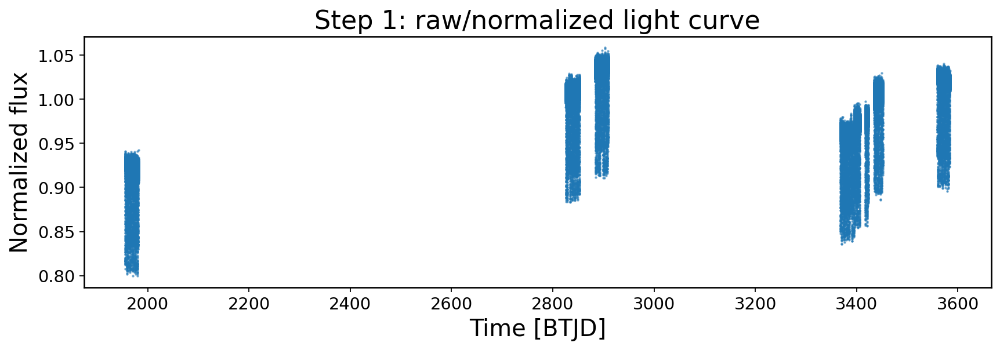

finite points: 117549
time span: 1955.7934772816825 to 3584.3767641661602
flux median/min/max: 1.0 0.7997912168502808 1.058629035949707


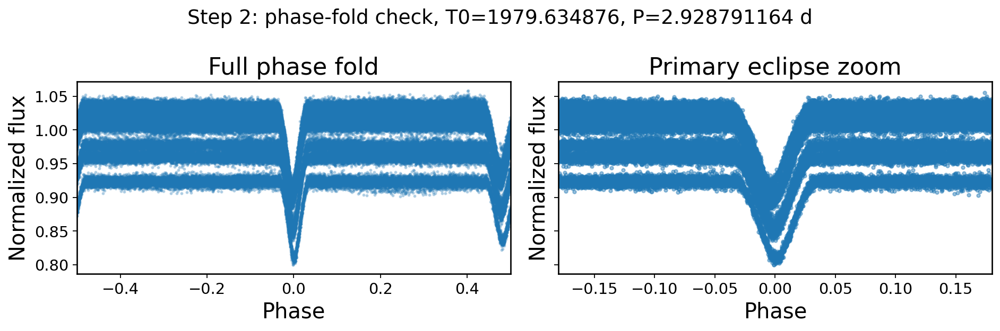

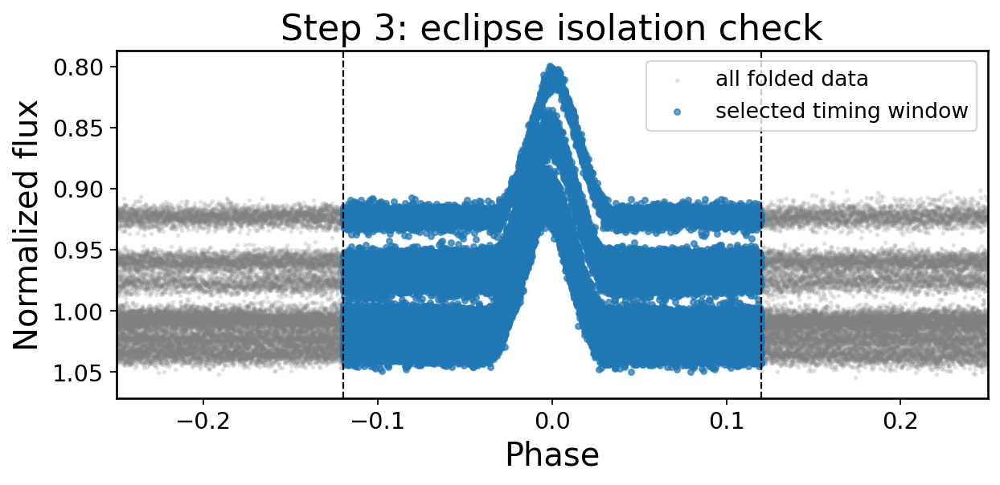

selected points: 28752
selected fraction: 0.2445958706581936
Using template: template_phase/template_flux


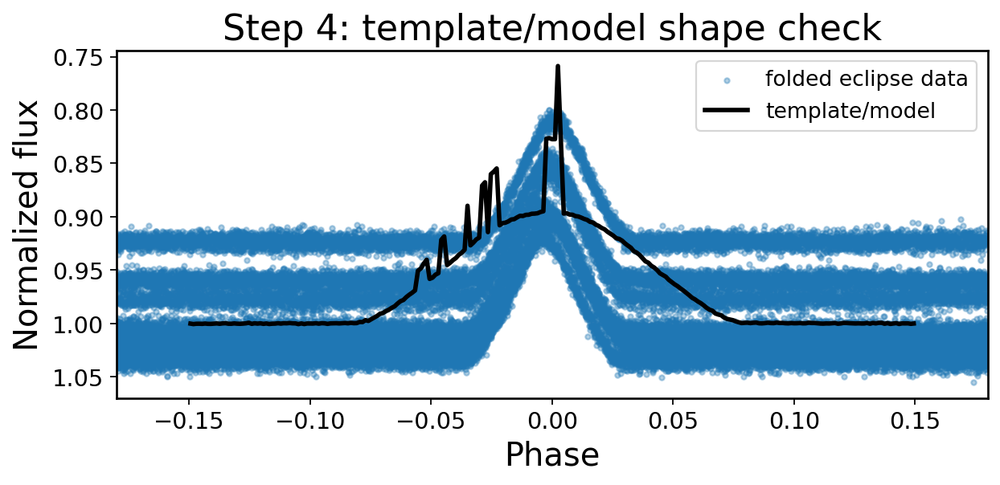

template points: 249
template depth: 0.23815757036209106


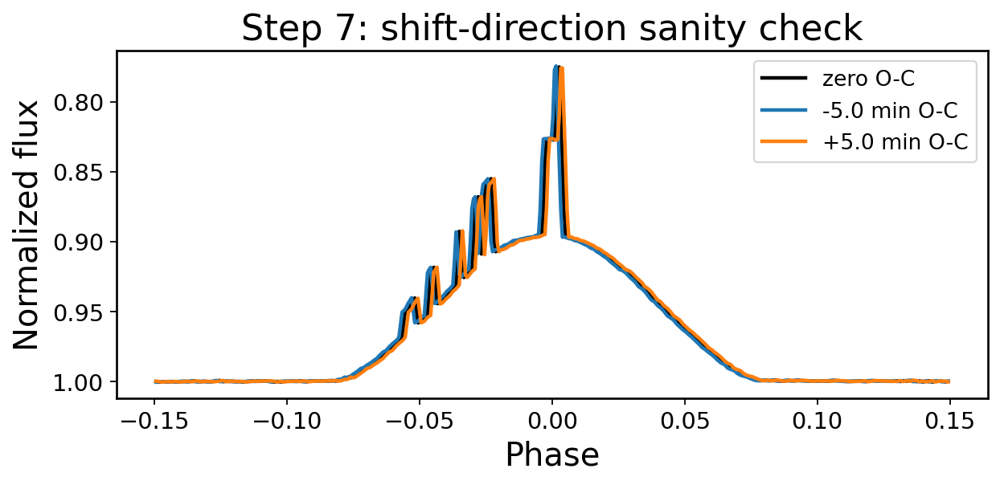

A positive O-C means observed eclipse occurs later than calculated.
SKIP individual fit panels: no result dictionary with debug_panels found.
SKIP group systematics plot: clean_df is created in the final O-C summary cell below.


In [100]:
import sys
import numpy as np

helper_dir = "/Users/admin-victor/Documents/pyspedas_project/Precision Timing of Eclipsing Binaries from TESS Full Frame Images"
if helper_dir not in sys.path:
    sys.path.append(helper_dir)

from oc_validation_helpers import *

# ------------------------------------------------------------
# Pick the currently active light-curve arrays.
# This lets the validation cell work even if your notebook uses
# either t/flux_norm or time/flux.
# ------------------------------------------------------------
if "t" in globals():
    validation_time = np.asarray(t, dtype=float)
elif "time" in globals():
    validation_time = np.asarray(time, dtype=float)
else:
    raise NameError("No time array found. Run the light-curve loading cell first so t or time exists.")

if "flux_norm" in globals():
    validation_flux = np.asarray(flux_norm, dtype=float)
elif "flux" in globals():
    validation_flux = np.asarray(flux, dtype=float)
    validation_flux = validation_flux / np.nanmedian(validation_flux)
else:
    raise NameError("No flux array found. Run the light-curve loading cell first so flux_norm or flux exists.")

if len(validation_time) != len(validation_flux):
    raise ValueError(f"Time and flux lengths do not match: {len(validation_time)} vs {len(validation_flux)}")

finite = np.isfinite(validation_time) & np.isfinite(validation_flux)
validation_time = validation_time[finite]
validation_flux = validation_flux[finite]

print("Validation arrays:")
print("points =", len(validation_time))
print("time range =", np.nanmin(validation_time), "to", np.nanmax(validation_time))
print("flux median/min/max =", np.nanmedian(validation_flux), np.nanmin(validation_flux), np.nanmax(validation_flux))

# 1. Raw light curve check.
plot_raw_lightcurve(validation_time, validation_flux)

# 2-3. Phase fold and eclipse isolation checks.
if "T0" not in globals() or "P" not in globals():
    raise NameError("T0 and P must be defined before the phase-fold validation plots.")

plot_phase_fold_check(validation_time, validation_flux, T0, P)
plot_eclipse_mask_check(validation_time, validation_flux, T0, P, phase_window=0.12)

# 4. Model/template depth and shape check.
# Try common template variable names used in this notebook.
template_candidates = []
if "template_phase" in globals() and "template_flux" in globals():
    template_candidates.append(("template_phase/template_flux", template_phase, template_flux))
if "tp_smooth" in globals() and "tf_smooth" in globals():
    template_candidates.append(("tp_smooth/tf_smooth", tp_smooth, tf_smooth))
if "tpl_phase" in globals() and "tpl_flux" in globals():
    template_candidates.append(("tpl_phase/tpl_flux", tpl_phase, tpl_flux))

if template_candidates:
    template_name, validation_template_phase, validation_template_flux = template_candidates[0]
    print("Using template:", template_name)
    plot_template_check(
        validation_time,
        validation_flux,
        T0,
        P,
        validation_template_phase,
        validation_template_flux,
    )
    plot_shift_direction_demo(validation_template_phase, validation_template_flux, P, shift_minutes=5.0)
else:
    print("SKIP template/model plots: no template_phase/template_flux, tp_smooth/tf_smooth, or tpl_phase/tpl_flux found yet.")
    print("Run the template-building cell first, then rerun this validation cell.")

# 5. Individual eclipse fit panels, if a previous timing cell stored them.
debug_panels = None
for name in ["timing_result", "result", "results", "res"]:
    obj = globals().get(name)
    if isinstance(obj, dict) and "debug_panels" in obj:
        debug_panels = obj["debug_panels"]
        print("Using debug panels from", name)
        break

if debug_panels:
    plot_individual_fit_panels(debug_panels)
else:
    print("SKIP individual fit panels: no result dictionary with debug_panels found.")

# 6. Instrumental/group check, if clean_df exists.
if "clean_df" in globals():
    needed = {"epoch", "oc_residual_min", "group"}
    if needed.issubset(set(clean_df.columns)):
        plot_segment_systematics(clean_df["epoch"], clean_df["oc_residual_min"], clean_df["group"])
    else:
        print("SKIP group systematics plot: clean_df exists but does not have epoch, oc_residual_min, group.")
else:
    print("SKIP group systematics plot: clean_df is created in the final O-C summary cell below.")


In [101]:
# Rebuild missing clean_* arrays for the final summary cell
# Run this cell immediately before "Final summary for cleaned O-C analysis".

import numpy as np
import pandas as pd

if {"clean_epoch", "clean_group", "clean_oc_min"}.issubset(globals()):
    print("clean_* arrays already exist.")

elif "clean_df" in globals() and {"epoch", "group", "oc_residual_min"}.issubset(clean_df.columns):
    clean_epoch = np.asarray(clean_df["epoch"])
    clean_group = np.asarray(clean_df["group"])
    clean_oc_min = np.asarray(clean_df["oc_residual_min"], dtype=float)
    print("Recovered clean_* arrays from clean_df.")

elif {"E1", "seg1", "oc2"}.issubset(globals()):
    clean_epoch = np.asarray(E1, dtype=int)
    clean_group = np.asarray(seg1)
    clean_oc_min = np.asarray(oc2, dtype=float)
    print("Recovered clean_* arrays from E1, seg1, oc2.")

elif {"t1", "E1", "seg1", "T0_new", "P_new"}.issubset(globals()):
    clean_epoch = np.asarray(E1, dtype=int)
    clean_group = np.asarray(seg1)
    clean_oc_min = (np.asarray(t1, dtype=float) - (T0_new + clean_epoch * P_new)) * 24 * 60
    print("Recovered clean_* arrays from t1, E1, seg1, T0_new, P_new.")

elif {"all_E", "all_oc", "all_seg_id"}.issubset(globals()):
    oc_min_raw = np.asarray(all_oc, dtype=float) * 24 * 60
    finite = np.isfinite(oc_min_raw)
    med = np.nanmedian(oc_min_raw[finite])
    mad = np.nanmedian(np.abs(oc_min_raw[finite] - med))
    robust_sigma = 1.4826 * mad if mad > 0 else np.nanstd(oc_min_raw[finite])
    good = finite & (np.abs(oc_min_raw - med) < 4 * robust_sigma)

    clean_epoch = np.asarray(all_E, dtype=int)[good]
    clean_group = np.asarray(all_seg_id)[good]

    if {"all_tobs", "T0_new", "P_new"}.issubset(globals()):
        clean_tobs = np.asarray(all_tobs, dtype=float)[good]
        clean_oc_min = (clean_tobs - (T0_new + clean_epoch * P_new)) * 24 * 60
        print("Recovered clean_* arrays from all_* arrays using refined ephemeris.")
    else:
        clean_oc_min = oc_min_raw[good]
        print("Recovered clean_* arrays from all_* arrays using raw O-C values.")

elif {"t_clean", "oc_clean", "seg_clean", "T0", "P"}.issubset(globals()):
    clean_epoch = np.round((np.asarray(t_clean, dtype=float) - T0) / P).astype(int)
    clean_group = np.asarray(seg_clean)
    clean_oc_min = np.asarray(oc_clean, dtype=float)
    print("Recovered clean_* arrays from t_clean, oc_clean, seg_clean.")

elif {"epoch_arr", "oc_new"}.issubset(globals()):
    clean_epoch = np.asarray(epoch_arr, dtype=int)
    clean_group = np.zeros_like(clean_epoch)
    clean_oc_min = np.asarray(oc_new, dtype=float) * 24 * 60
    print("Recovered clean_* arrays from epoch_arr and oc_new; group set to 0.")

else:
    available = sorted([name for name in globals() if name.startswith(("clean", "all_", "oc", "E", "seg", "t_"))])
    msg = (
        "Could not rebuild clean_epoch/clean_group/clean_oc_min. "
        "Run the timing/cleaning cells before the final summary. "
        f"Relevant available names: {available[:80]}"
    )
    raise NameError(msg)

clean_epoch = np.asarray(clean_epoch)
clean_group = np.asarray(clean_group)
clean_oc_min = np.asarray(clean_oc_min, dtype=float)

ok = np.isfinite(clean_epoch) & np.isfinite(clean_oc_min)
clean_epoch = clean_epoch[ok]
clean_group = clean_group[ok]
clean_oc_min = clean_oc_min[ok]

print("Ready for final summary:")
print("n_clean_timings =", len(clean_epoch))
print("groups =", np.unique(clean_group))
print("O-C min/median/max [min] =", np.nanmin(clean_oc_min), np.nanmedian(clean_oc_min), np.nanmax(clean_oc_min))


Recovered clean_* arrays from E1, seg1, oc2.
Ready for final summary:
n_clean_timings = 55
groups = [0 1 2 3 4 5 6]
O-C min/median/max [min] = -1.7388196469983086 -0.07345667800109368 1.5136396159505239


Final cleaned O-C summary
n_clean_timings: 55
rms_min: 0.6571206560266812
robust_scatter_min: 0.6434103135147888
best_bic_model: constant/no ETV trend
conclusion: No statistically compelling long-term ETV signal in this cleaned dataset.


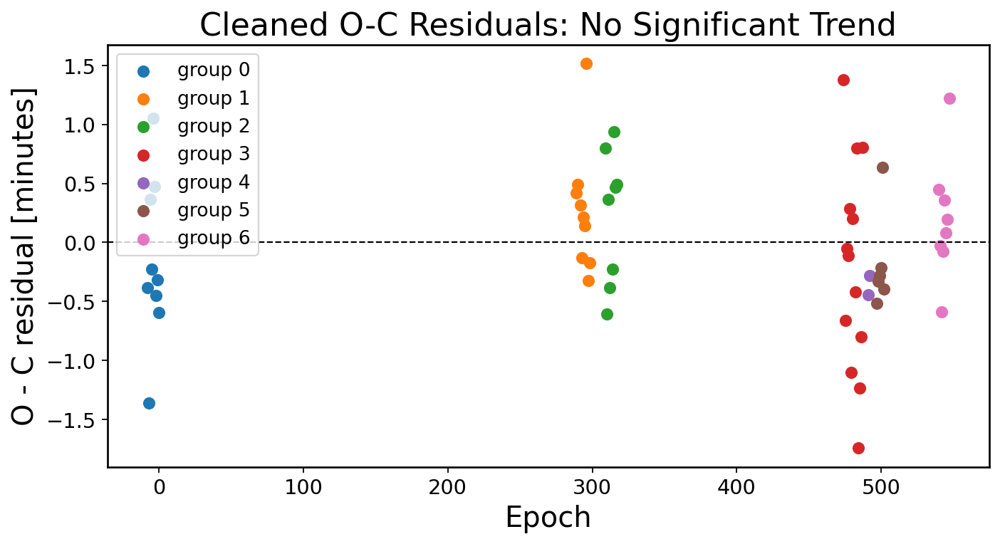

Saved clean_oc_residuals.csv
Saved clean_oc_summary.csv


{'n_clean_timings': 55,
 'rms_min': 0.6571206560266812,
 'robust_scatter_min': 0.6434103135147888,
 'best_bic_model': 'constant/no ETV trend',
 'conclusion': 'No statistically compelling long-term ETV signal in this cleaned dataset.'}

In [102]:
# Final summary for cleaned O-C analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Build/refresh the cleaned result table from the current cleaned arrays.
clean_df = pd.DataFrame({
    "epoch": clean_epoch,
    "group": clean_group,
    "oc_residual_min": clean_oc_min,
})

rms_min = float(np.std(clean_df["oc_residual_min"]))
robust_scatter_min = float(
    1.4826 * np.median(
        np.abs(clean_df["oc_residual_min"] - np.median(clean_df["oc_residual_min"]))
    )
)

summary = {
    "n_clean_timings": int(len(clean_df)),
    "rms_min": rms_min,
    "robust_scatter_min": robust_scatter_min,
    "best_bic_model": "constant/no ETV trend",
    "conclusion": "No statistically compelling long-term ETV signal in this cleaned dataset.",
}

print("Final cleaned O-C summary")
for key, value in summary.items():
    print(f"{key}: {value}")

plt.figure(figsize=(9, 5))
for g in sorted(clean_df["group"].unique()):
    m = clean_df["group"] == g
    plt.scatter(
        clean_df.loc[m, "epoch"],
        clean_df.loc[m, "oc_residual_min"],
        s=45,
        label=f"group {g}",
    )

plt.axhline(0, ls="--", color="black", linewidth=1)
plt.xlabel("Epoch")
plt.ylabel("O - C residual [minutes]")
plt.title("Cleaned O-C Residuals: No Significant Trend")
plt.legend()
plt.tight_layout()
plt.show()

clean_df.to_csv("clean_oc_residuals.csv", index=False)
pd.DataFrame([summary]).to_csv("clean_oc_summary.csv", index=False)

print("Saved clean_oc_residuals.csv")
print("Saved clean_oc_summary.csv")

summary


## Empirical forward model from release parameters

This comparison model uses the release row with maximum `log_prob` for the orbital solution, then fits a lightweight flux model to the folded light curve. This gives a reproducible empirical model curve for comparison across TIC IDs.


In [103]:
# Load the reusable comparison model code.
import sys
import numpy as np
import matplotlib.pyplot as plt

helper_dir = "/Users/admin-victor/Documents/pyspedas_project/Precision Timing of Eclipsing Binaries from TESS Full Frame Images"
if helper_dir not in sys.path:
    sys.path.append(helper_dir)

from eb_forward_model import read_release_bestfit, release_params, fit_comparison_model

release_fits = "/Users/admin-victor/Documents/tess10057647.fits"
samples, best_row, best_index = read_release_bestfit(release_fits)
release_orbit = release_params(best_row)

print("Best sample index:", best_index)
print("Best log_prob:", best_row["log_prob"])
for key, value in release_orbit.items():
    print(f"{key}: {value}")


Best sample index: 139180
Best log_prob: 10438.060484667256
period: 16.263821052595798
eclipse_time: 1859.0727370772265
ecc: 0.4713696307127047
omega_deg: 127.78955371559852
e_cos_omega: -0.2888378599643668
secondary_phase: 0.40806005366917275


In [127]:
P_release = float(best_row["per"])
T0_release = float(best_row["eclipse_time"])

print("Full precision period:")
print(repr(P_release))

print("Full precision eclipse_time/T0:")
print(repr(T0_release))

Full precision period:
16.263821052595798
Full precision eclipse_time/T0:
1859.0727370772265


In [128]:
# Fit the empirical comparison model to the current notebook light curve.
# Requires t and flux_norm to already exist from the light-curve loading cells.

if "t" not in globals() or "flux_norm" not in globals():
    raise NameError("Run the light-curve loading/normalization cells first so t and flux_norm exist.")

forward_model = fit_comparison_model(t, flux_norm, best_row, nbins=350)
fit_params = forward_model["fit_result"].x

names = [
    "baseline", "primary_depth", "primary_width", "secondary_depth", "secondary_width",
    "cos1", "sin1", "cos2", "sin2",
]

print("Fit success:", forward_model["fit_result"].success)
print("Binned RMS:", forward_model["rms"])
for name, value in zip(names, fit_params):
    print(f"{name}: {value}")


Fit success: True
Binned RMS: 0.013199664782084158
baseline: 0.9885407831778507
primary_depth: 0.02296388631573773
primary_width: 0.09760983161632783
secondary_depth: 0.004589364083527033
secondary_width: 0.022047688919599368
cos1: -0.01704115970450641
sin1: -0.00840770550975476
cos2: -0.0032965276218207963
sin2: -0.002098939932645292


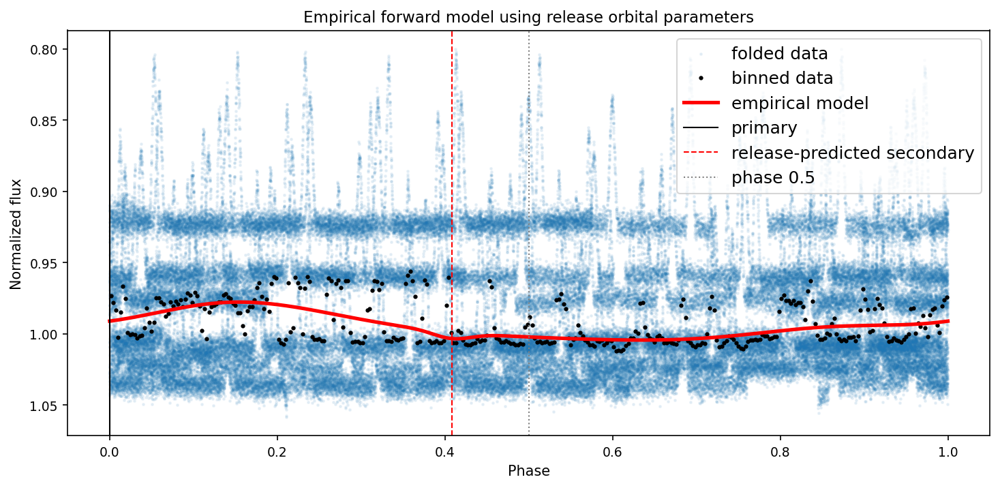

In [129]:
# Plot full phase-folded data, binned curve, and the empirical model.

plt.figure(figsize=(10, 5))
plt.scatter(forward_model["phase"], flux_norm, s=2, alpha=0.08, label="folded data")
plt.plot(forward_model["bin_phase"], forward_model["bin_flux"], "k.", ms=4, label="binned data")
plt.plot(forward_model["model_phase"], forward_model["model_flux"], color="red", lw=2.5, label="empirical model")

plt.axvline(0.0, color="black", lw=1, label="primary")
plt.axvline(forward_model["release_params"]["secondary_phase"], color="red", lw=1, ls="--", label="release-predicted secondary")
plt.axvline(0.5, color="gray", lw=1, ls=":", label="phase 0.5")

plt.xlabel("Phase")
plt.ylabel("Normalized flux")
plt.title("Empirical forward model using release orbital parameters")
plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


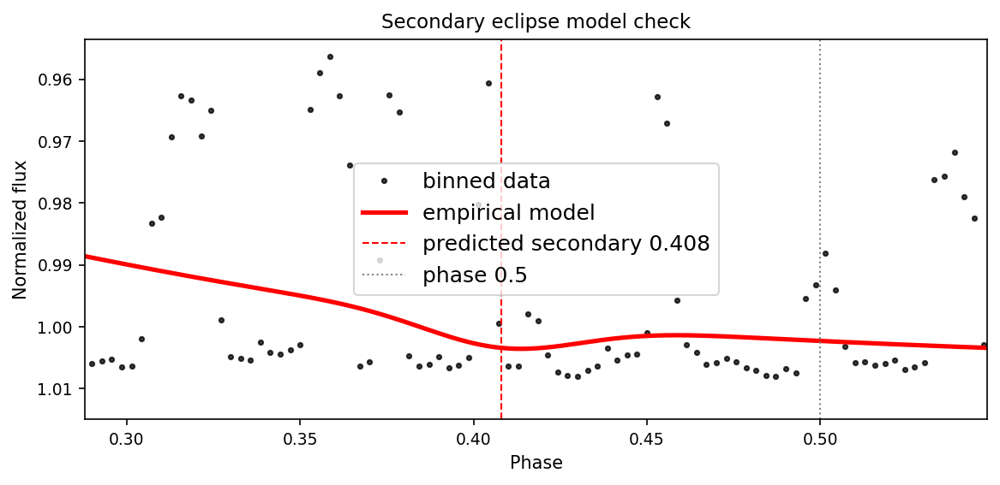

In [130]:
# Zoom around the secondary eclipse prediction.

sec = forward_model["release_params"]["secondary_phase"]
plt.figure(figsize=(8, 4))
plt.plot(forward_model["bin_phase"], forward_model["bin_flux"], "k.", ms=5, alpha=0.75, label="binned data")
plt.plot(forward_model["model_phase"], forward_model["model_flux"], color="red", lw=2.5, label="empirical model")
plt.axvline(sec, color="red", lw=1, ls="--", label=f"predicted secondary {sec:.3f}")
plt.axvline(0.5, color="gray", lw=1, ls=":", label="phase 0.5")

plt.xlim(sec - 0.12, sec + 0.14)
plt.xlabel("Phase")
plt.ylabel("Normalized flux")
plt.title("Secondary eclipse model check")
plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [131]:
# Reusable wrapper for other TIC IDs after copying /release/tess<TIC>.fits into Documents.

def run_empirical_forward_model_for_tic(tic_id, time, flux, folder="/Users/admin-victor/Documents", nbins=350):
    release_fits = f"{folder}/tess{tic_id}.fits"
    samples, best_row, best_index = read_release_bestfit(release_fits)
    model = fit_comparison_model(time, flux, best_row, nbins=nbins)
    print(f"TIC {tic_id}")
    print("best index:", best_index)
    print("log_prob:", best_row["log_prob"])
    print("period:", model["release_params"]["period"])
    print("eclipse_time:", model["release_params"]["eclipse_time"])
    print("ecc:", model["release_params"]["ecc"])
    print("omega_deg:", model["release_params"]["omega_deg"])
    print("secondary_phase:", model["release_params"]["secondary_phase"])
    print("binned RMS:", model["rms"])
    return samples, best_row, model

# Example:
# samples_10057647, best_10057647, model_10057647 = run_empirical_forward_model_for_tic("10057647", t, flux_norm)


In [132]:
# Fit the empirical comparison model to the current notebook light curve.
# Requires t and flux_norm to already exist from the light-curve loading cells.

if "t" not in globals() or "flux_norm" not in globals():
    raise NameError("Run the light-curve loading/normalization cells first so t and flux_norm exist.")

forward_model = fit_comparison_model(t, flux_norm, best_row, nbins=350)
fit_params = forward_model["fit_result"].x

names = [
    "baseline", "primary_depth", "primary_width", "secondary_depth", "secondary_width",
    "cos1", "sin1", "cos2", "sin2",
]

print("Fit success:", forward_model["fit_result"].success)
print("Binned RMS:", forward_model["rms"])
for name, value in zip(names, fit_params):
    print(f"{name}: {value}")

Fit success: True
Binned RMS: 0.013199664782084158
baseline: 0.9885407831778507
primary_depth: 0.02296388631573773
primary_width: 0.09760983161632783
secondary_depth: 0.004589364083527033
secondary_width: 0.022047688919599368
cos1: -0.01704115970450641
sin1: -0.00840770550975476
cos2: -0.0032965276218207963
sin2: -0.002098939932645292


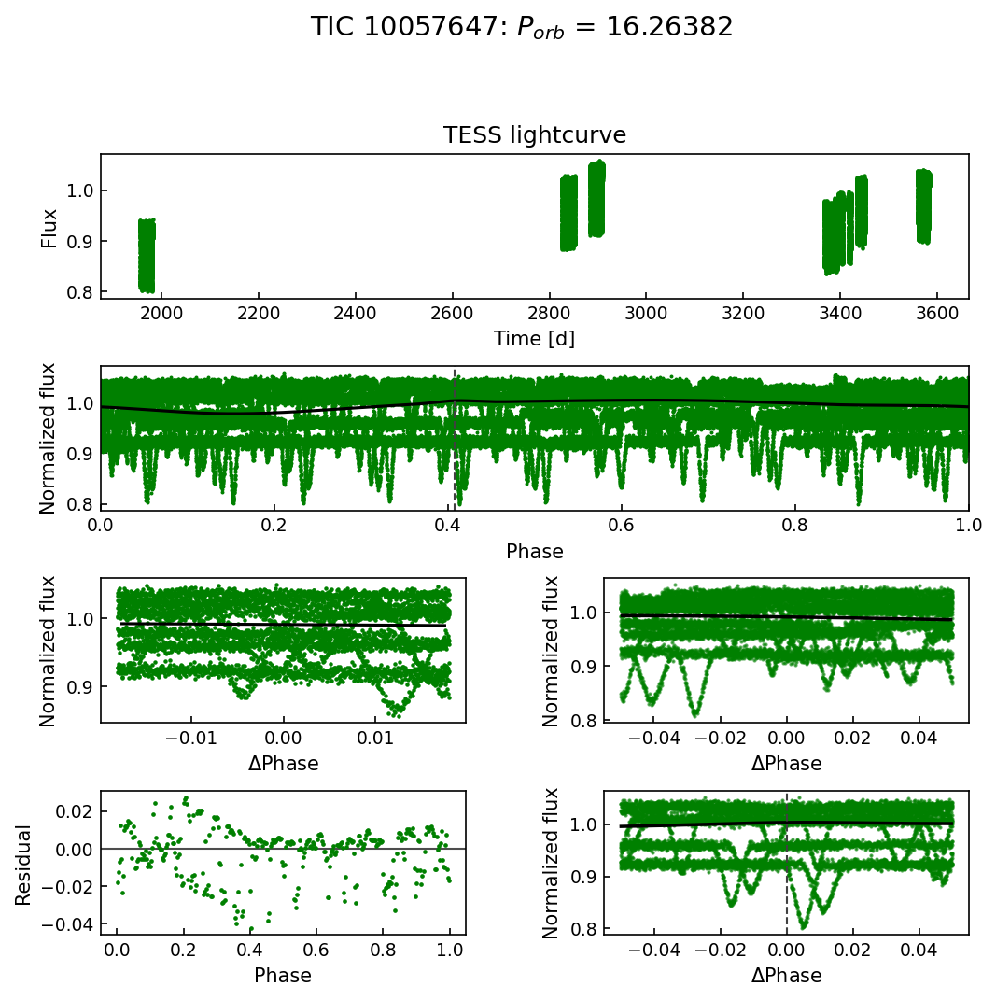

In [133]:
from eb_forward_model import plot_release_style_diagnostic

fig = plot_release_style_diagnostic(
    t,
    flux_norm,
    forward_model,
    tic_id="10057647",
    sector_label="TESS lightcurve",
    color="green",
    show_model=True,
)

plt.show()

In [134]:
import sys
import importlib

helper_dir = "/Users/admin-victor/Documents/pyspedas_project/Precision Timing of Eclipsing Binaries from TESS Full Frame Images"
if helper_dir not in sys.path:
    sys.path.append(helper_dir)

import eb_forward_model
importlib.reload(eb_forward_model)

from eb_forward_model import plot_release_style_diagnostic

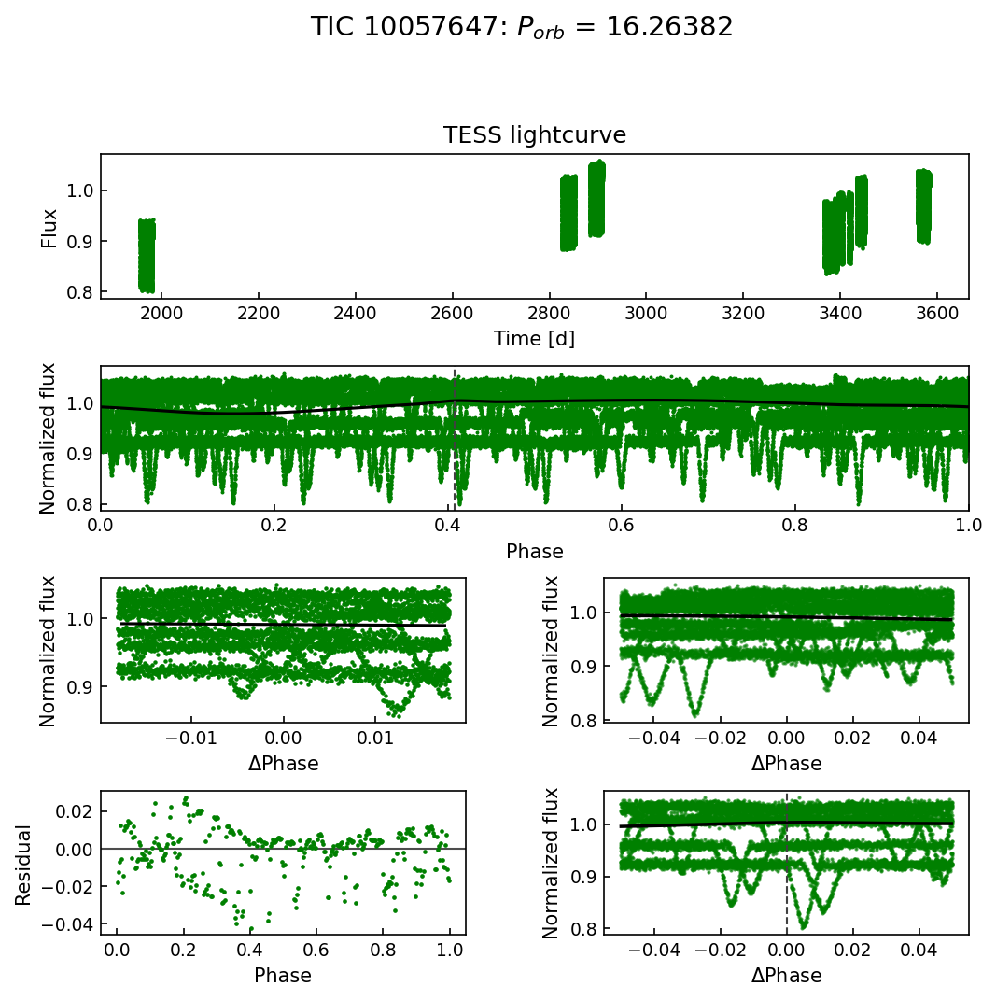

In [135]:
fig = plot_release_style_diagnostic(
    t,
    flux_norm,
    forward_model,
    tic_id="10057647",
    sector_label="TESS lightcurve",
    color="green",
    show_model=True,
)

plt.show()

In [136]:
gap_days = 5.0
gap = np.diff(t)
breaks = np.where(gap > gap_days)[0]
segments = np.split(np.arange(len(t)), breaks + 1)

for i, seg in enumerate(segments):
    print(i, len(seg), np.min(t[seg]), np.max(t[seg]))

0 18217 1955.7934772816825 1982.2784912447485
1 19463 2825.259124208658 2853.1400495767825
2 17964 2883.2677301616795 2910.0491661410397
3 27308 3367.6974798295146 3407.2025205481114
4 4591 3417.1506838718988 3423.546560761627
5 12676 3434.2702825892075 3452.320608871669
6 17330 3559.4570168884784 3584.3767641661602


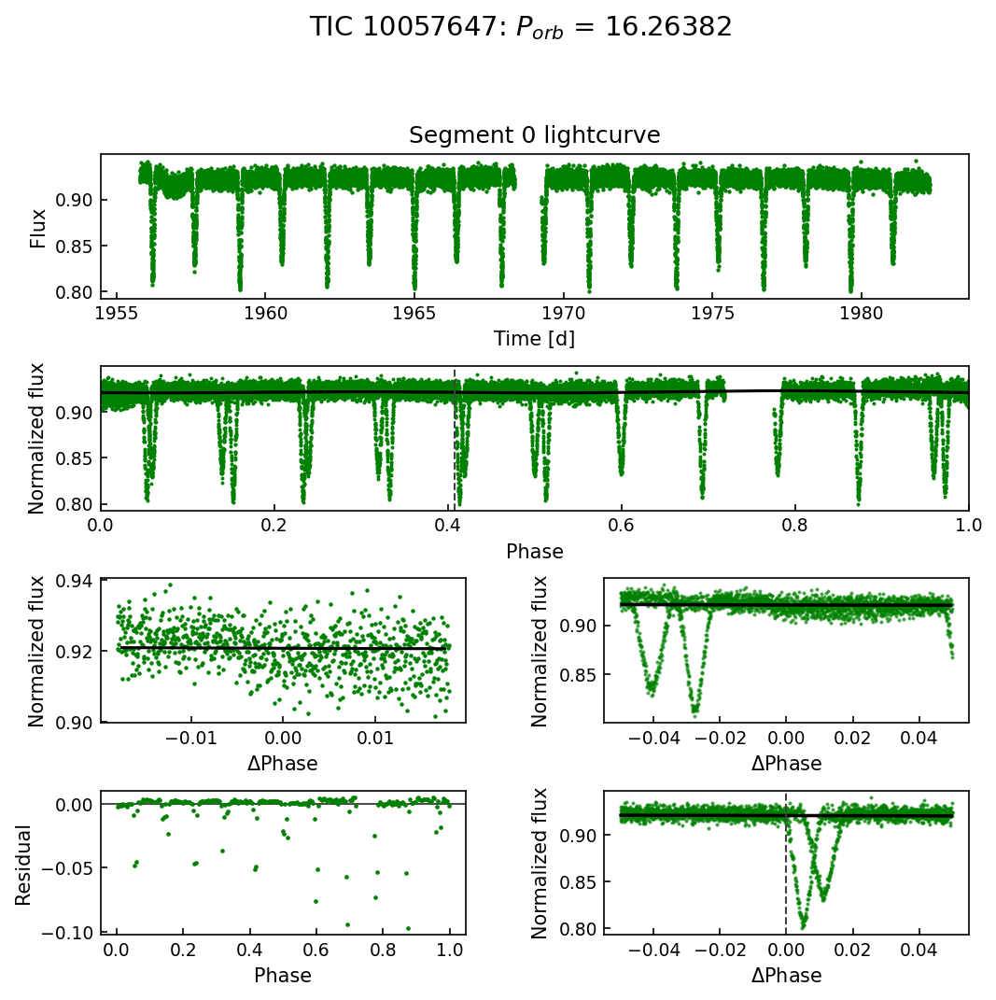

In [137]:
seg_id = 0
seg = segments[seg_id]

forward_model_seg = fit_comparison_model(
    t[seg],
    flux_norm[seg],
    best_row,
    nbins=250,
)

fig = plot_release_style_diagnostic(
    t[seg],
    flux_norm[seg],
    forward_model_seg,
    tic_id="10057647",
    sector_label=f"Segment {seg_id} lightcurve",
    color="green",
    show_model=True,
)

plt.show()

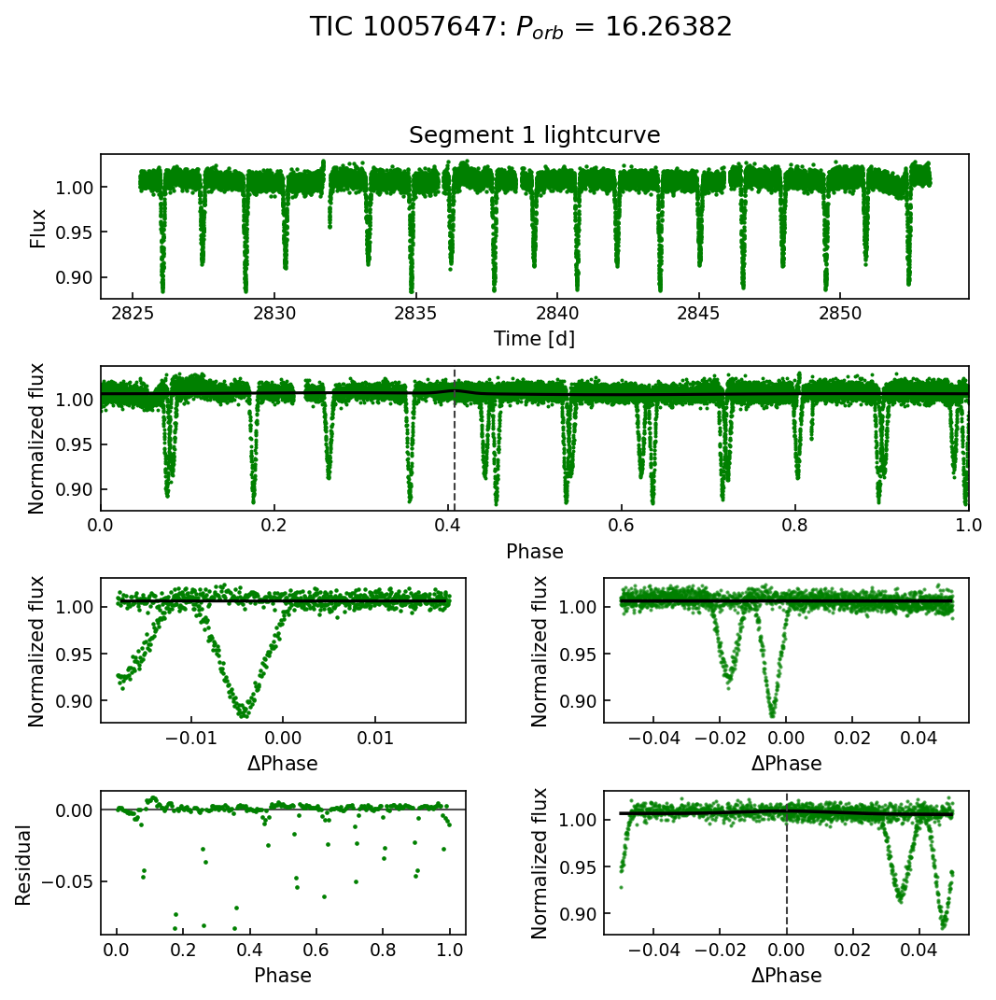

In [138]:
seg_id = 1
seg = segments[seg_id]

forward_model_seg = fit_comparison_model(
    t[seg],
    flux_norm[seg],
    best_row,
    nbins=250,
)

fig = plot_release_style_diagnostic(
    t[seg],
    flux_norm[seg],
    forward_model_seg,
    tic_id="10057647",
    sector_label=f"Segment {seg_id} lightcurve",
    color="green",
    show_model=True,
)

plt.show()

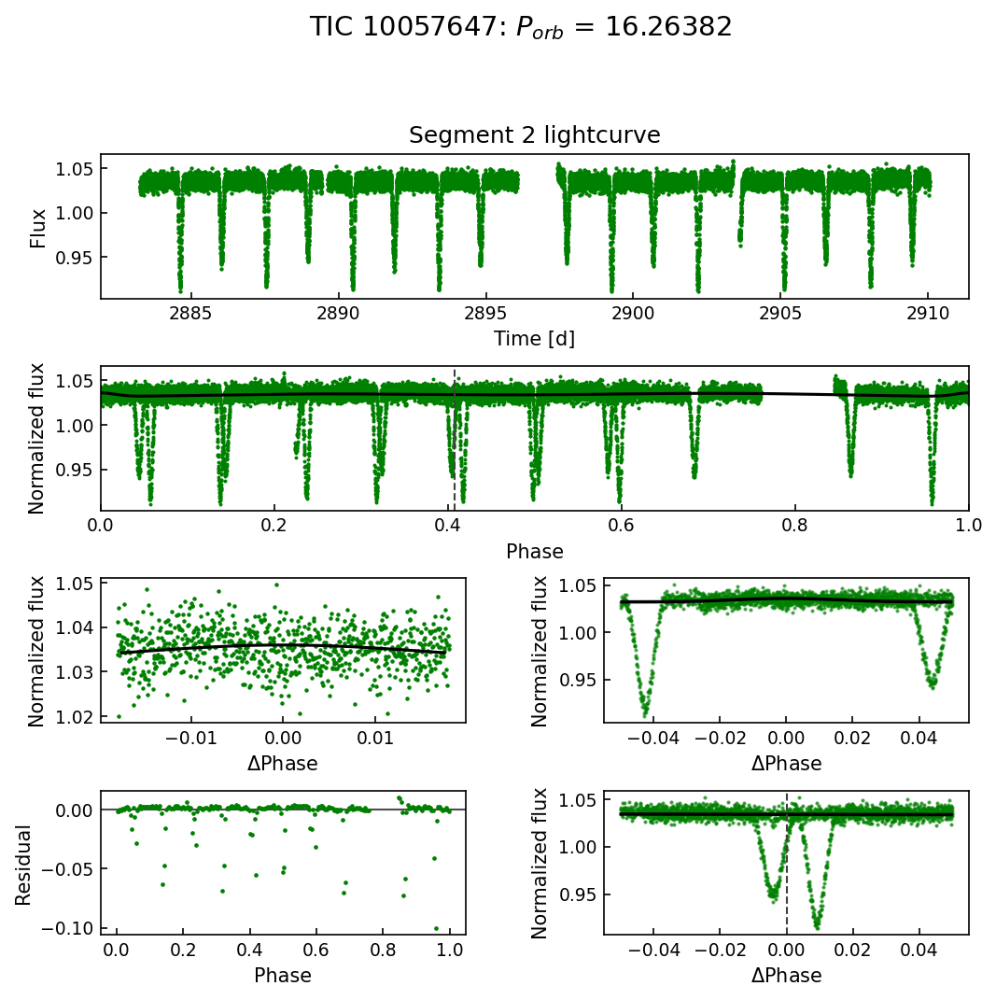

In [139]:
seg_id = 2
seg = segments[seg_id]

forward_model_seg = fit_comparison_model(
    t[seg],
    flux_norm[seg],
    best_row,
    nbins=250,
)

fig = plot_release_style_diagnostic(
    t[seg],
    flux_norm[seg],
    forward_model_seg,
    tic_id="10057647",
    sector_label=f"Segment {seg_id} lightcurve",
    color="green",
    show_model=True,
)

plt.show()

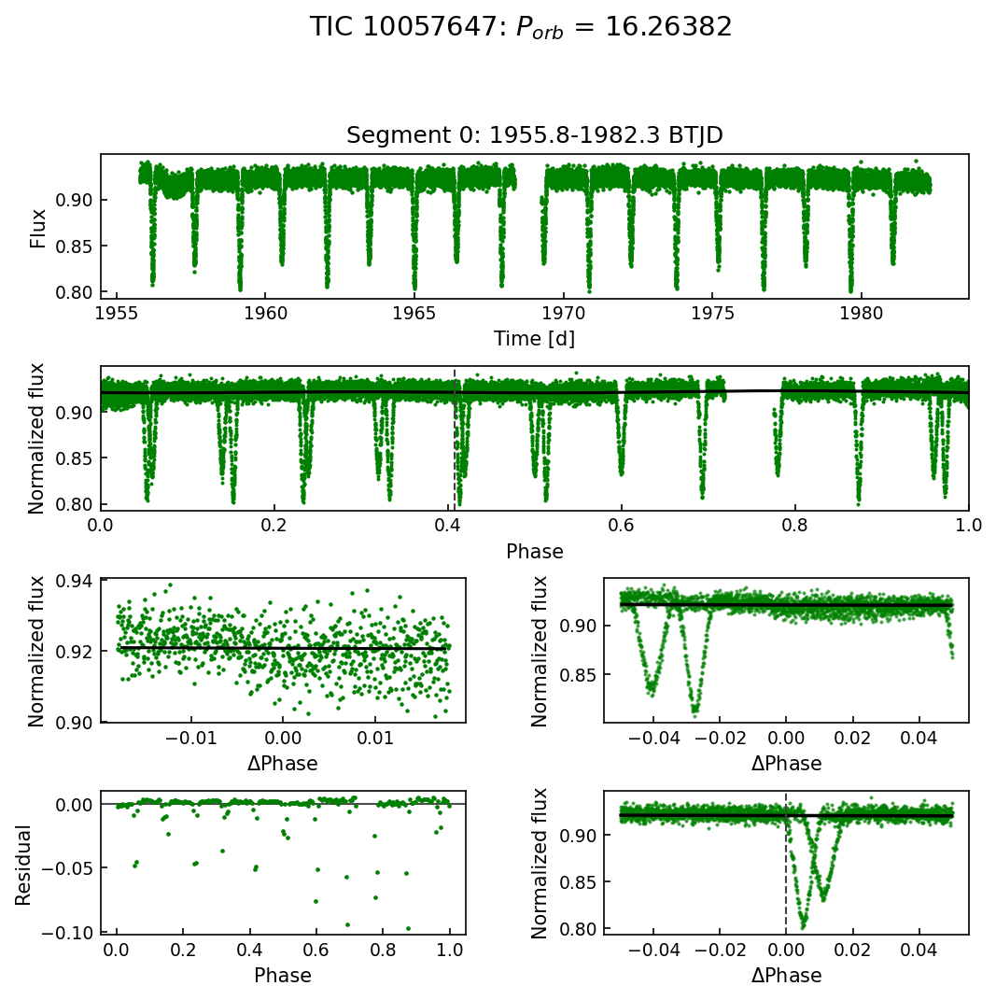

In [140]:
seg_id = 0
seg = segments[seg_id]

forward_model_seg = fit_comparison_model(
    t[seg],
    flux_norm[seg],
    best_row,
    nbins=250,
)

fig = plot_release_style_diagnostic(
    t[seg],
    flux_norm[seg],
    forward_model_seg,
    tic_id="10057647",
    sector_label=f"Segment {seg_id}: {np.min(t[seg]):.1f}-{np.max(t[seg]):.1f} BTJD",
    color="green",
    show_model=True,
)

plt.show()

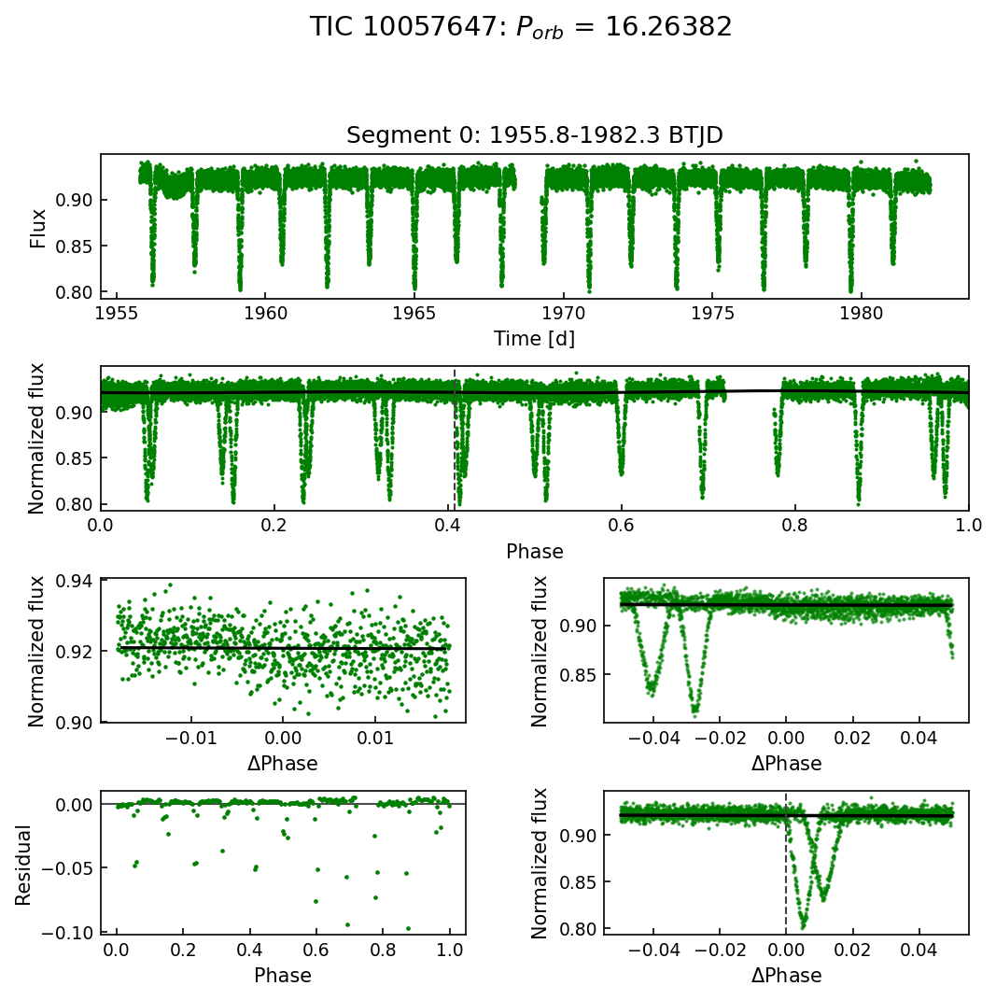

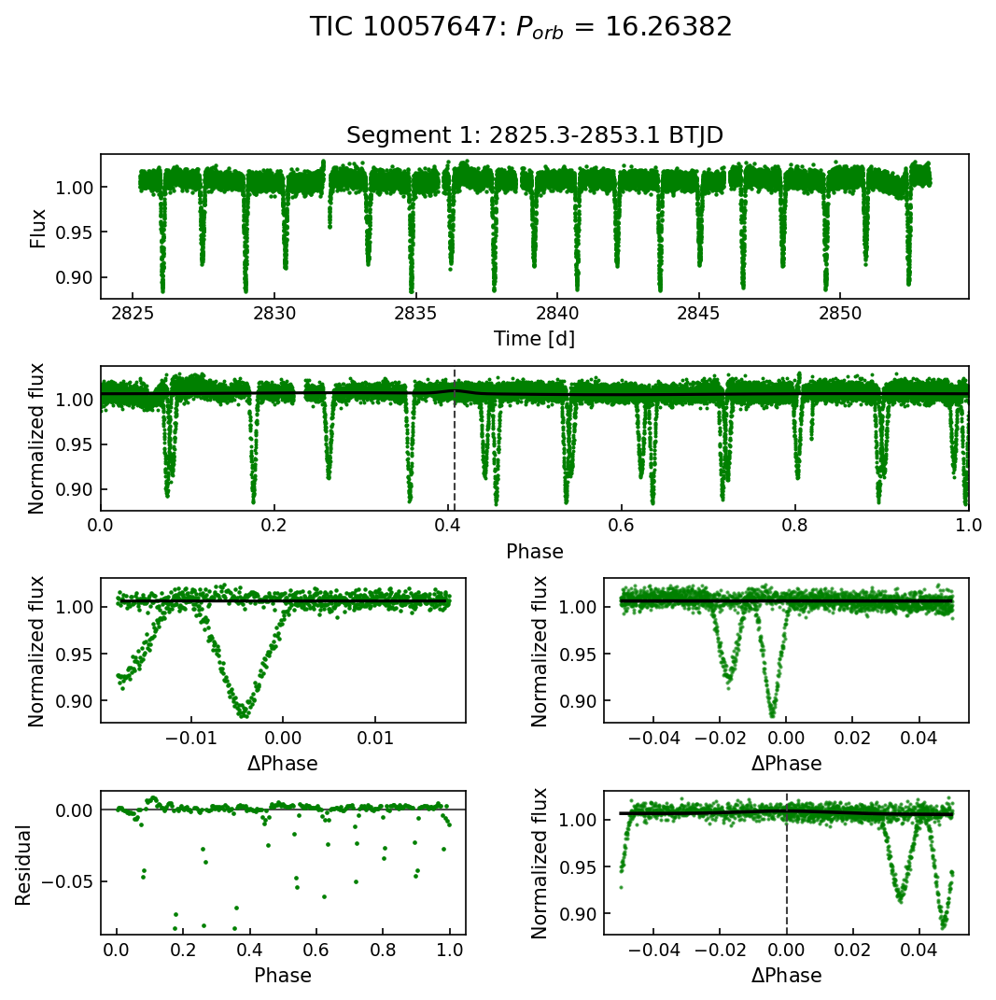

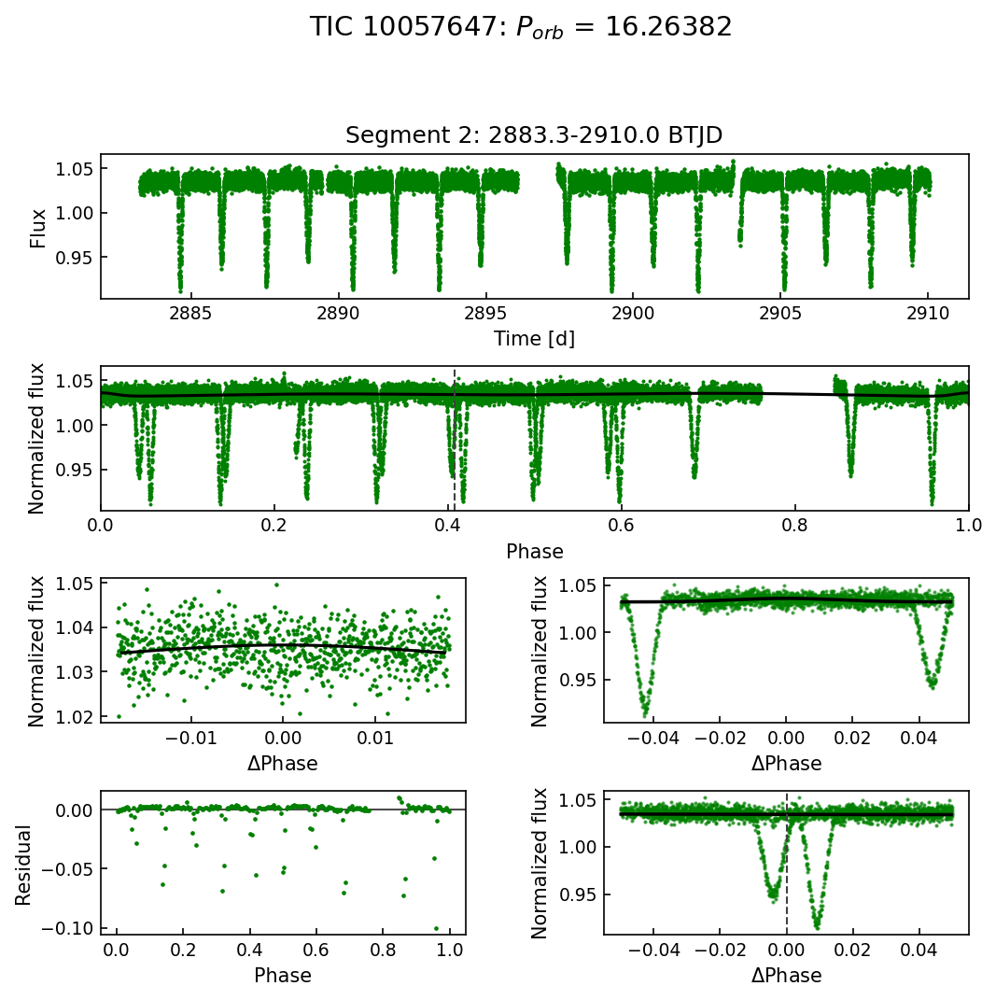

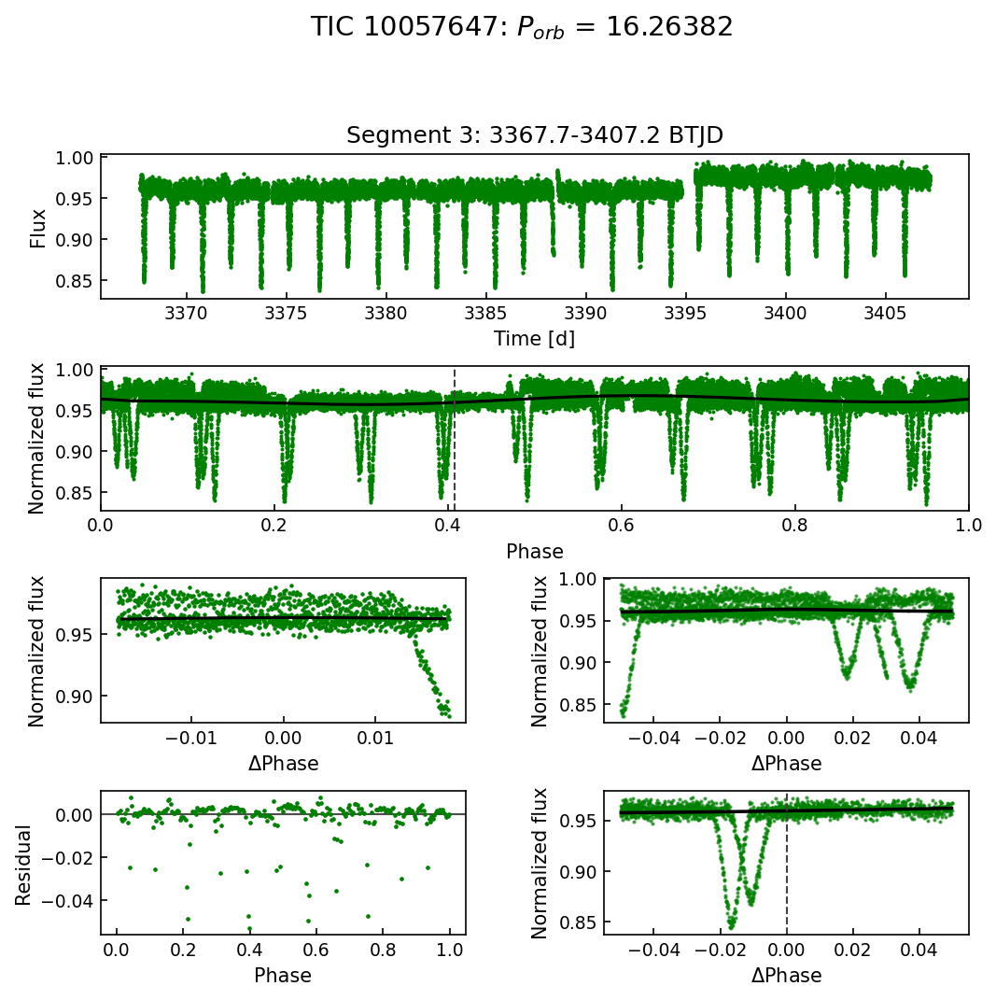

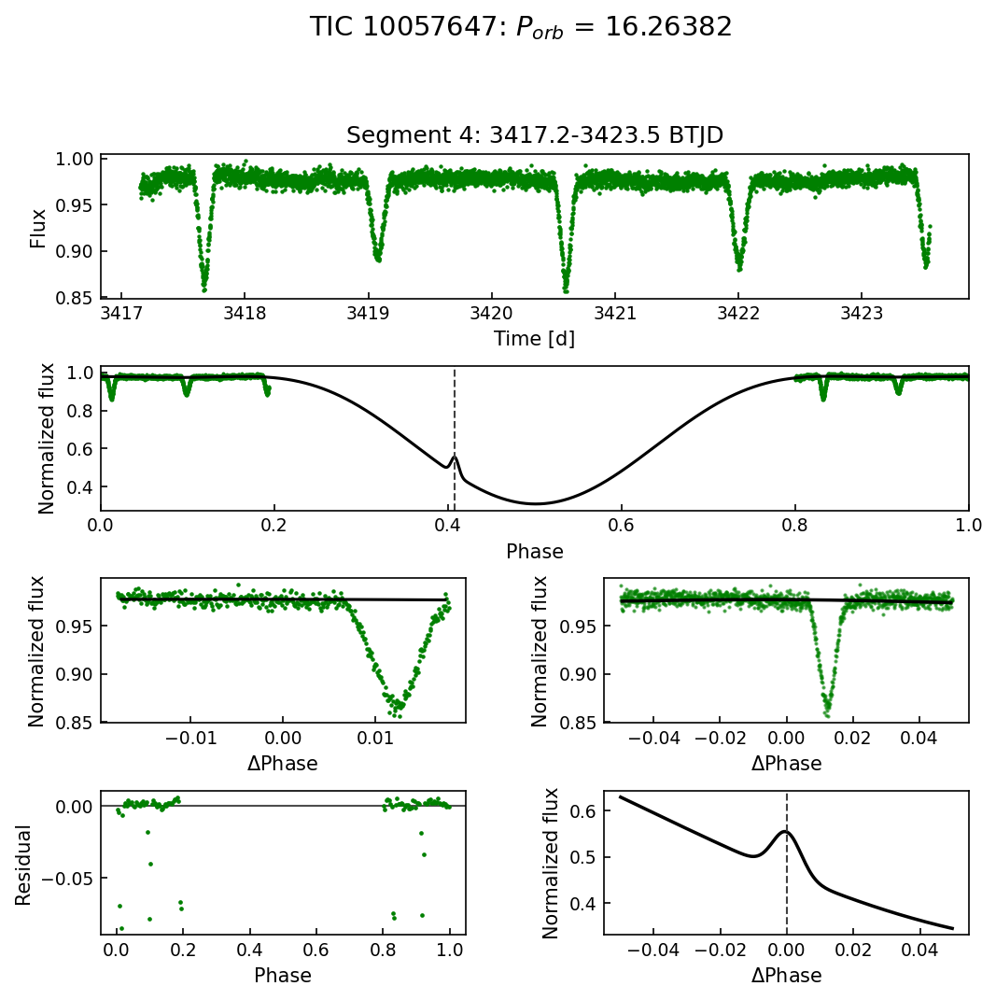

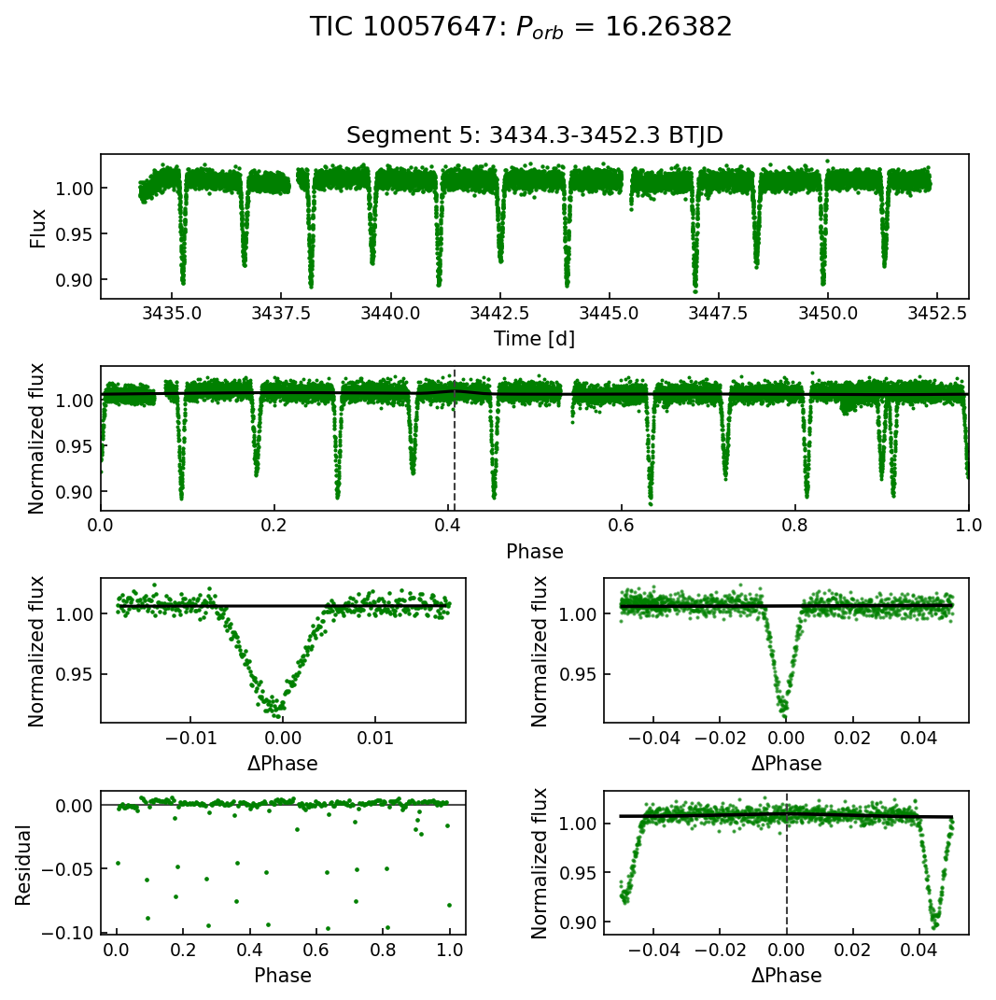

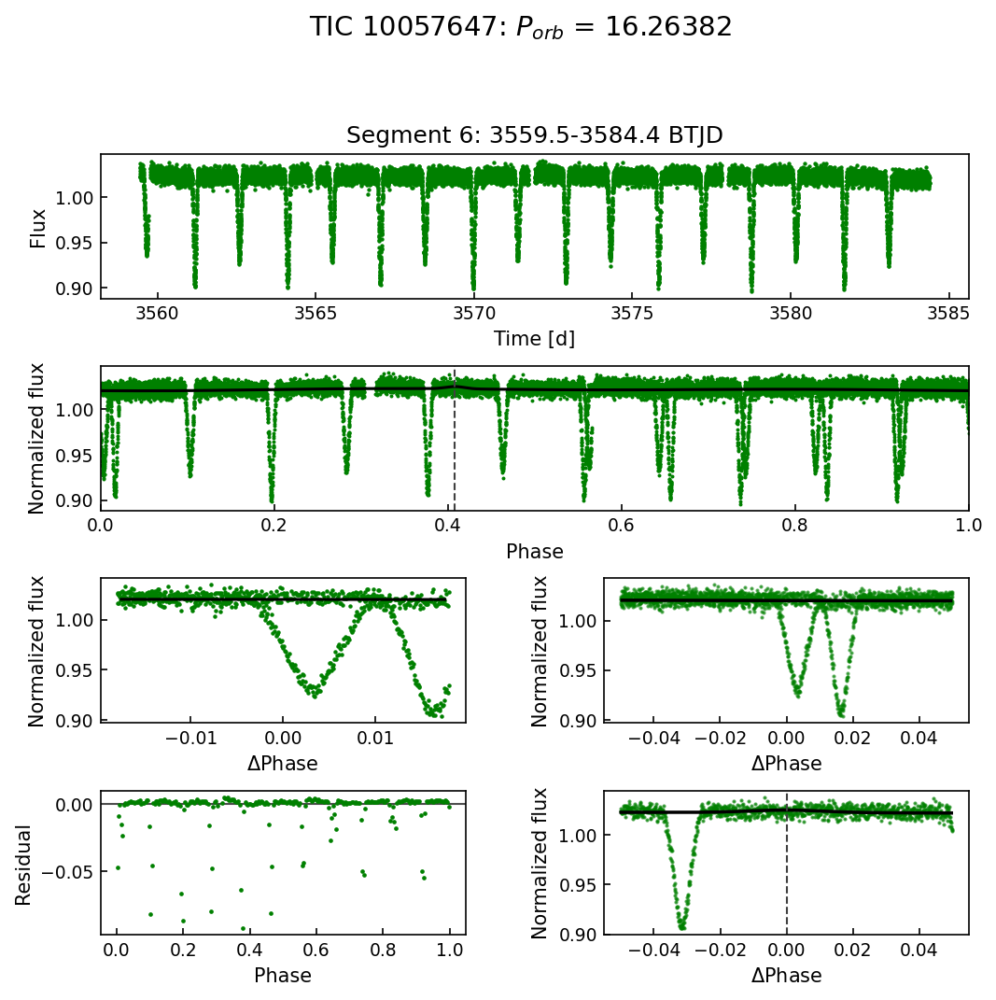

In [141]:
gap_days = 5.0
gap = np.diff(t)
breaks = np.where(gap > gap_days)[0]
segments = np.split(np.arange(len(t)), breaks + 1)

for seg_id, seg in enumerate(segments):
    if len(seg) < 100:
        continue

    forward_model_seg = fit_comparison_model(
        t[seg],
        flux_norm[seg],
        best_row,
        nbins=250,
    )

    fig = plot_release_style_diagnostic(
        t[seg],
        flux_norm[seg],
        forward_model_seg,
        tic_id="10057647",
        sector_label=f"Segment {seg_id}: {np.min(t[seg]):.1f}-{np.max(t[seg]):.1f} BTJD",
        color="green",
        show_model=True,
    )

    fig.savefig(
        f"tess10057647_segment_{seg_id}_diagnostic.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

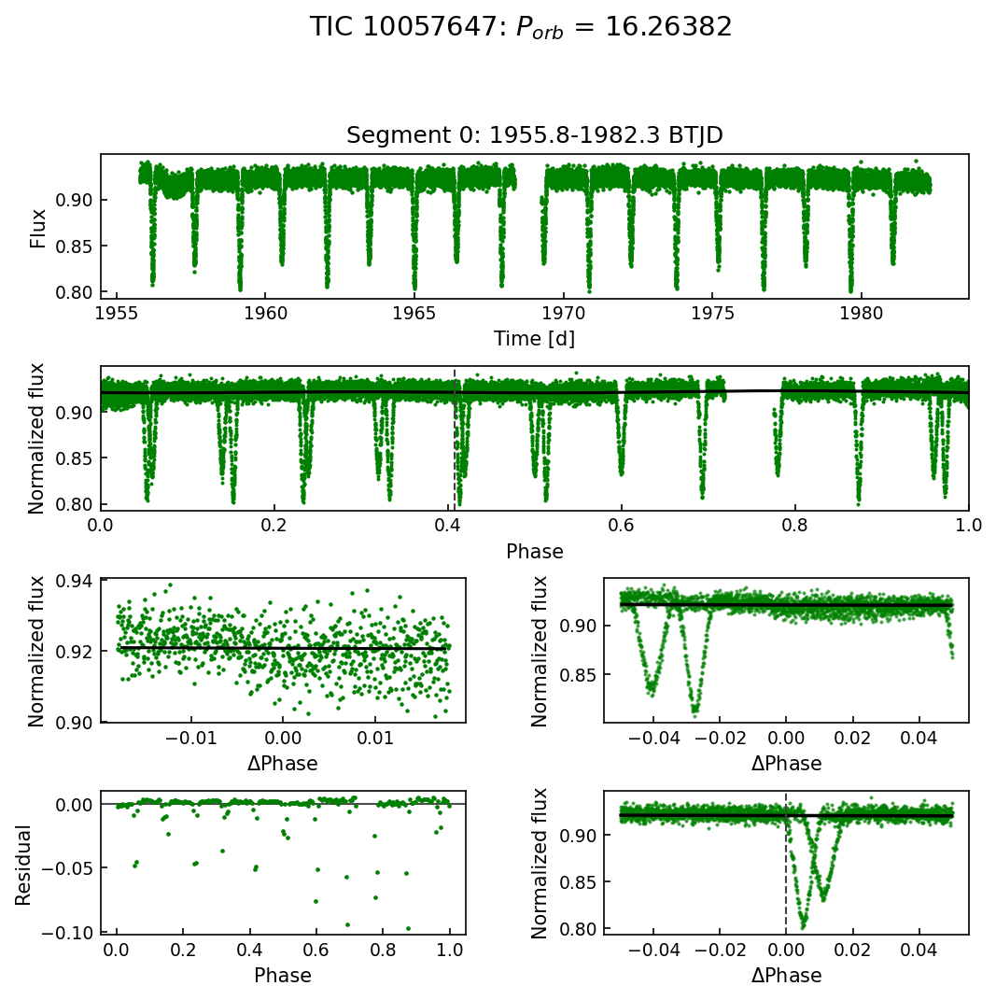

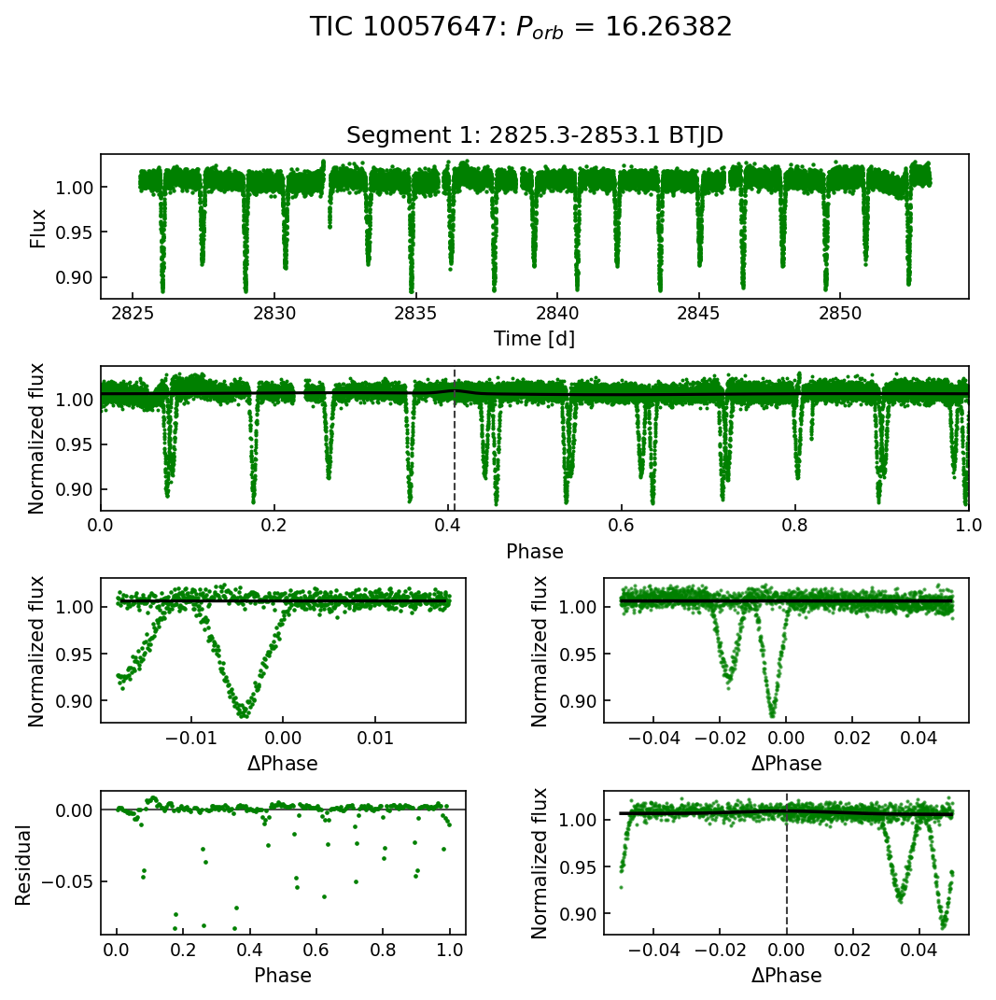

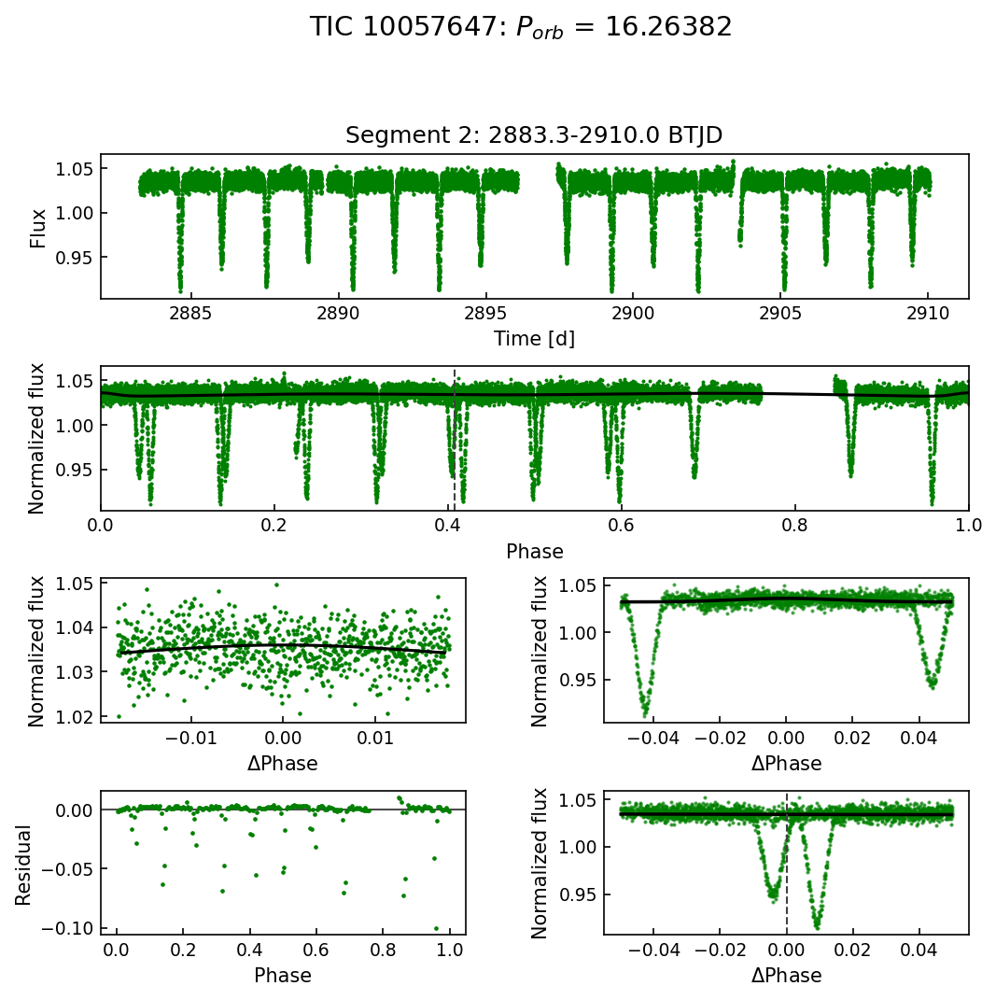

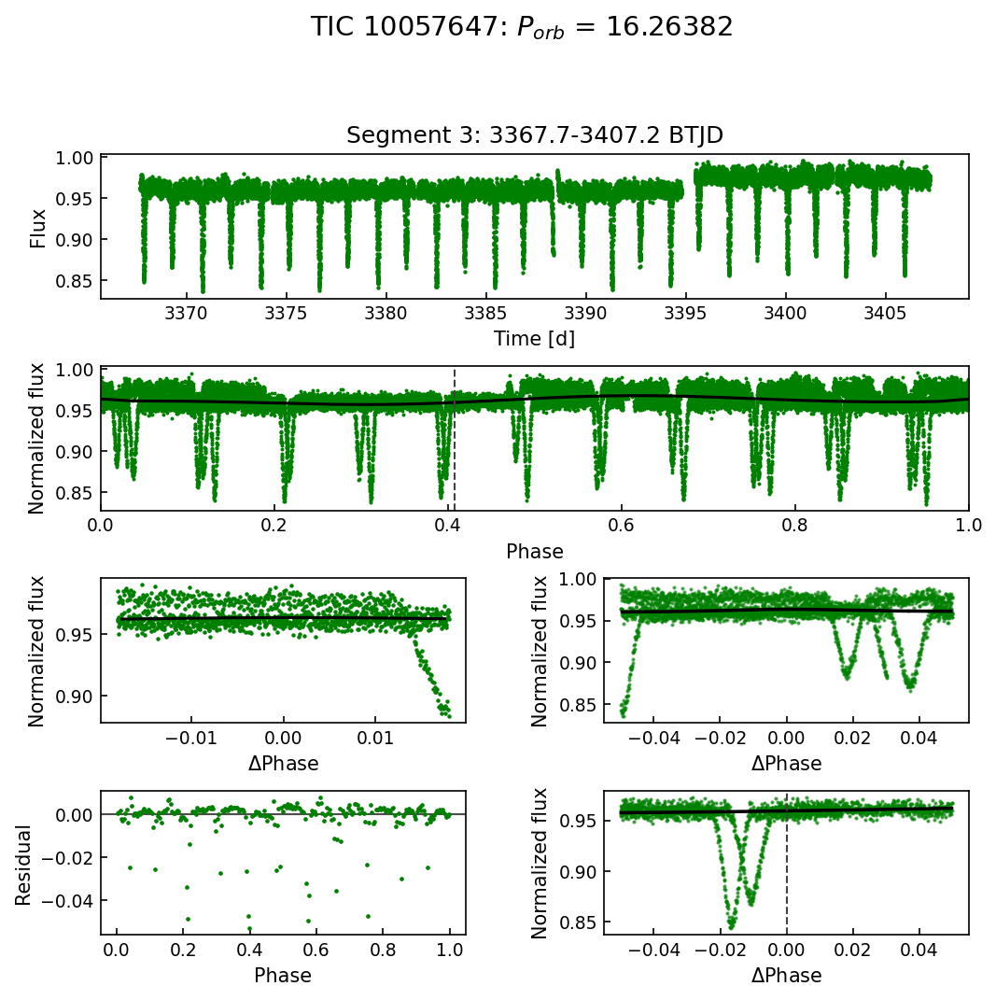

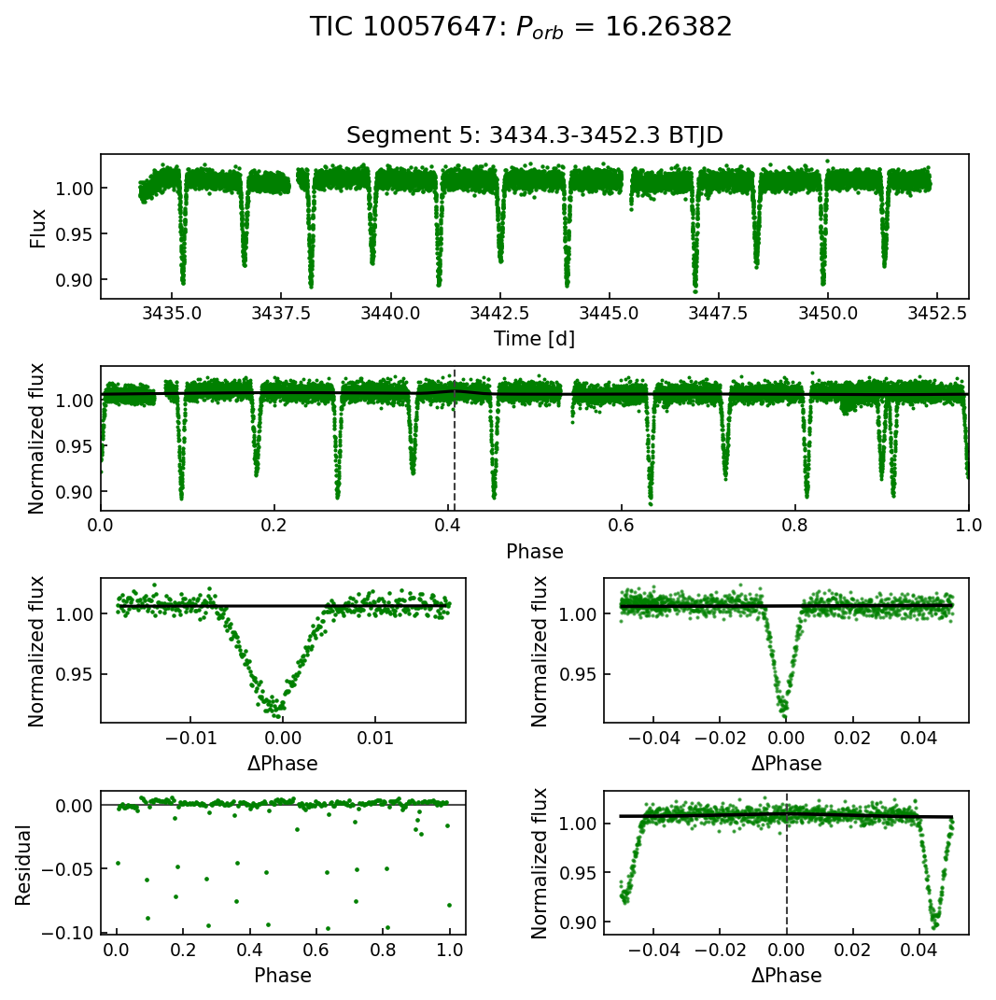

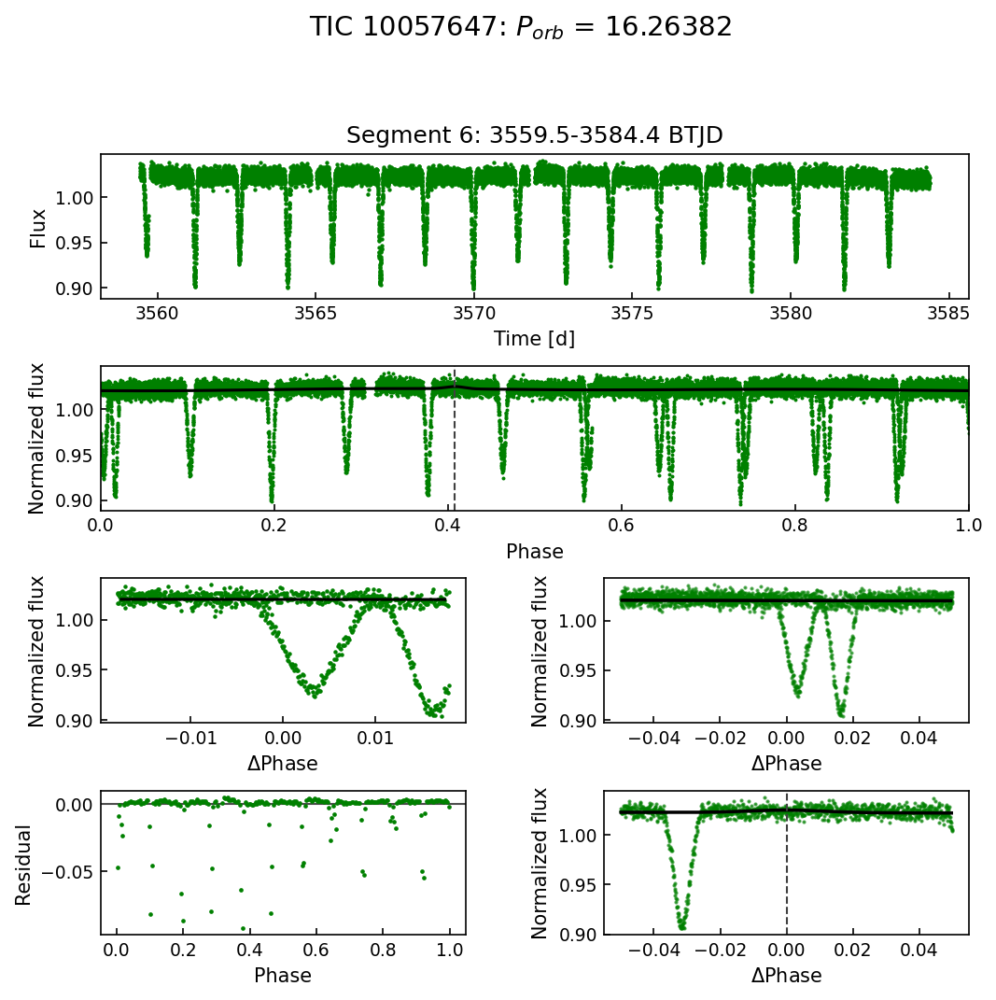

In [142]:
good_segments = [0, 1, 2, 3, 5, 6]

for seg_id in good_segments:
    seg = segments[seg_id]

    forward_model_seg = fit_comparison_model(
        t[seg],
        flux_norm[seg],
        best_row,
        nbins=250,
    )

    fig = plot_release_style_diagnostic(
        t[seg],
        flux_norm[seg],
        forward_model_seg,
        tic_id="10057647",
        sector_label=f"Segment {seg_id}: {np.min(t[seg]):.1f}-{np.max(t[seg]):.1f} BTJD",
        color="green",
        show_model=True,
    )

    fig.savefig(
        f"tess10057647_segment_{seg_id}_diagnostic.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

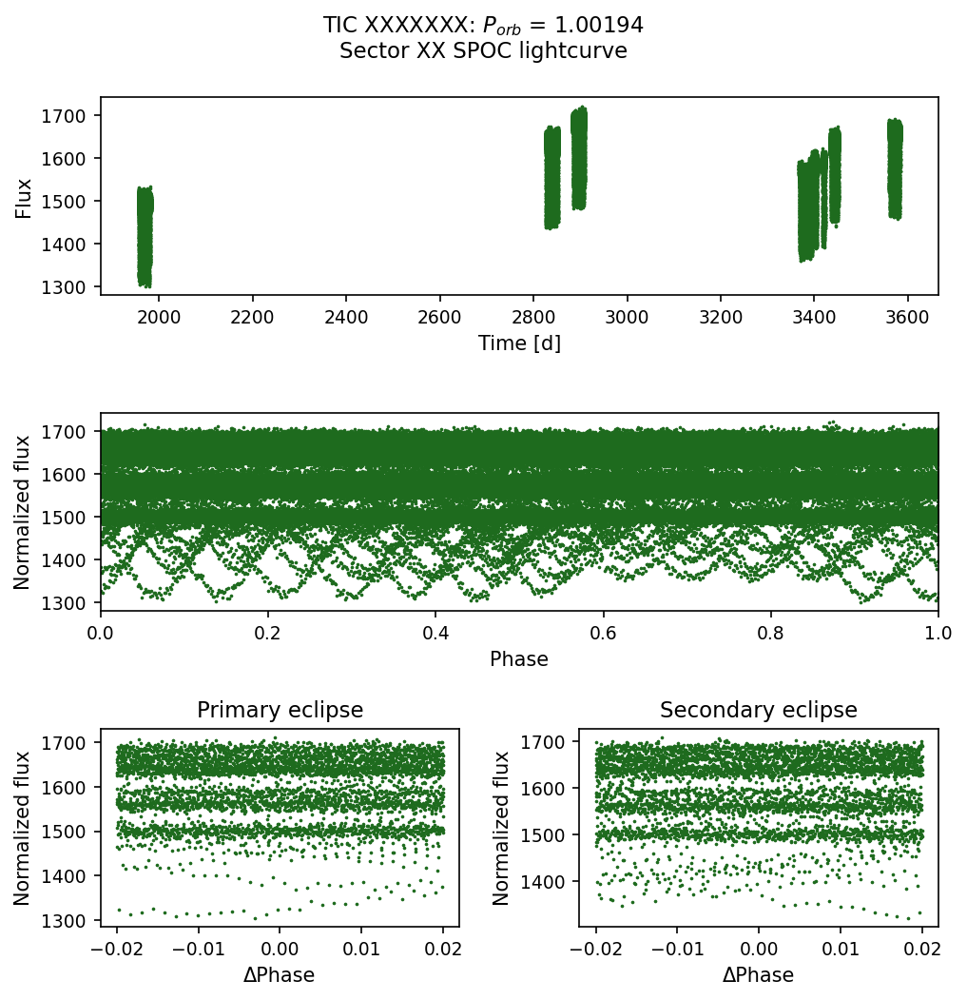

In [143]:
# ── 1. Global style (replace your rcParams block) ──────────────────────────
import matplotlib.pyplot as plt
import matplotlib as mpl

GREEN = "#1e6b1e"   # the dark green from the target figure

plt.rcParams.update({
    "figure.dpi": 150,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "lines.markersize": 2,
    "axes.linewidth": 0.8,
    "axes.grid": False,
    "savefig.dpi": 300,
})

# ── 2. Phase convention: map to [0, 1) instead of [-0.5, 0.5) ─────────────
def phase_fold_01(t, T0, P):
    """Phase in [0, 1)"""
    return ((t - T0) / P) % 1.0

# ── 3. The multi-panel figure layout (matching the target) ─────────────────
fig = plt.figure(figsize=(7, 9))
fig.suptitle(f"TIC XXXXXXX: $P_{{orb}}$ = {P_fit:.5f}\nSector XX SPOC lightcurve",
             fontsize=11, y=0.98)

phi01 = phase_fold_01(t, T0_fit, P_fit)

# --- Panel 1: raw light curve (time domain) ---
ax1 = fig.add_subplot(4, 2, (1, 2))   # full-width top row
ax1.plot(t, flux, ".", ms=1.5, color=GREEN, rasterized=True)
ax1.set_xlabel("Time [d]")
ax1.set_ylabel("Flux")

# --- Panel 2: phase-folded, full phase 0-1 ---
ax2 = fig.add_subplot(4, 2, (3, 4))
ax2.plot(phi01, flux, ".", ms=1.5, color=GREEN, rasterized=True)
ax2.set_xlim(0, 1)
ax2.set_xlabel("Phase")
ax2.set_ylabel("Normalized flux")

# --- Panel 3 & 4: zoom around primary and secondary eclipses ---
# Primary eclipse: phase near 0 (or 1), expressed as ΔPhase
phi_centered = phi01.copy()
phi_centered[phi_centered > 0.5] -= 1.0   # re-center primary at 0

zoom_primary = 0.02   # adjust to your eclipse width
mask_p = np.abs(phi_centered) < zoom_primary

ax3 = fig.add_subplot(4, 2, 5)
ax3.plot(phi_centered[mask_p], flux[mask_p], ".", ms=1.5, color=GREEN)
ax3.set_xlabel("ΔPhase")
ax3.set_ylabel("Normalized flux")
ax3.set_title("Primary eclipse")

# Secondary eclipse: phase near 0.5
phi_sec = phi01 - 0.5   # center secondary at 0
phi_sec[phi_sec < -0.5] += 1.0

zoom_sec = 0.02
mask_s = np.abs(phi_sec) < zoom_sec

ax4 = fig.add_subplot(4, 2, 6)
ax4.plot(phi_sec[mask_s], flux[mask_s], ".", ms=1.5, color=GREEN)
ax4.set_xlabel("ΔPhase")
ax4.set_ylabel("Normalized flux")
ax4.set_title("Secondary eclipse")

plt.tight_layout()
plt.show()

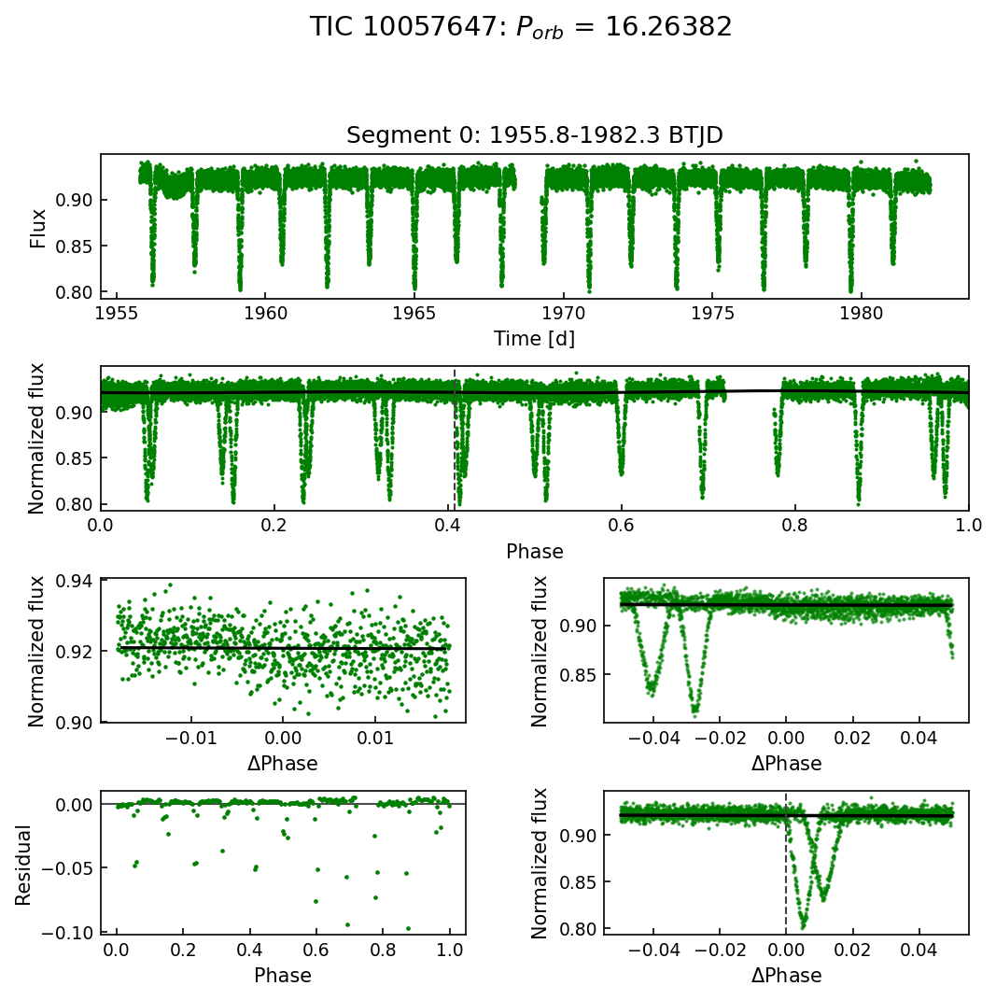

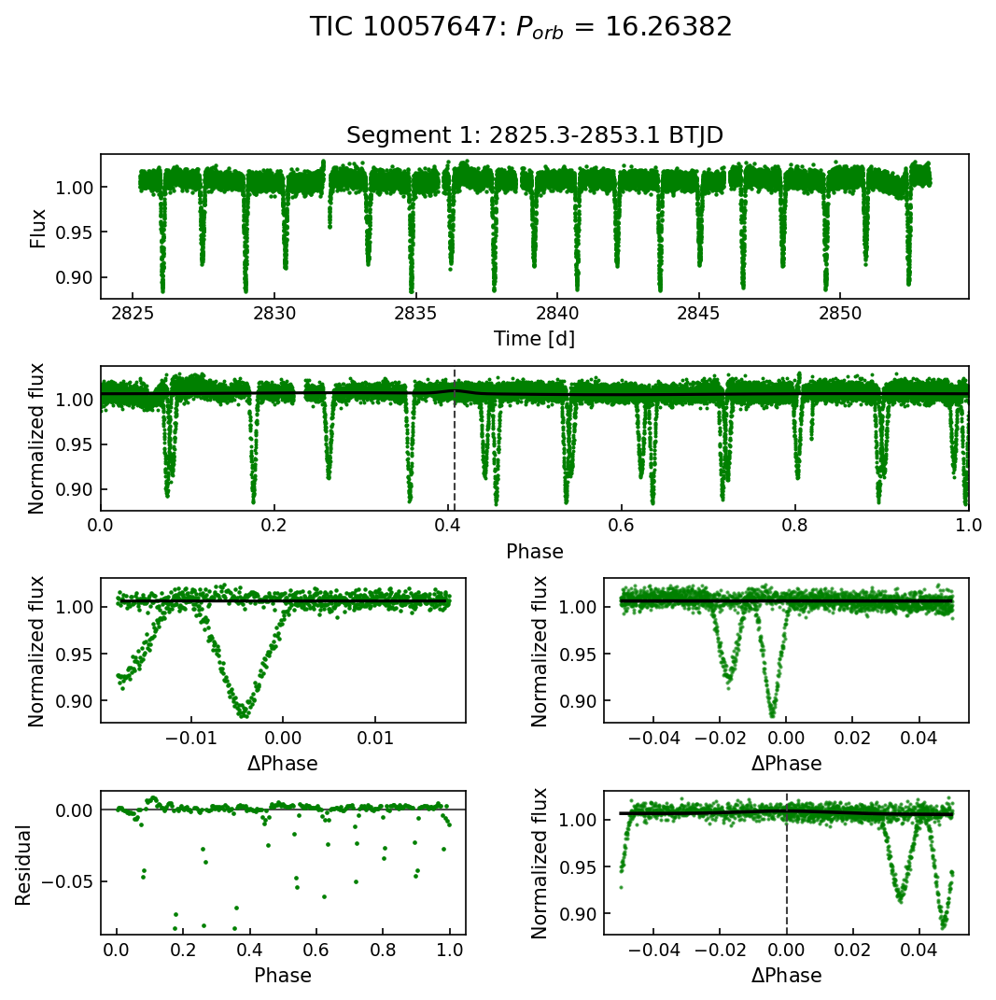

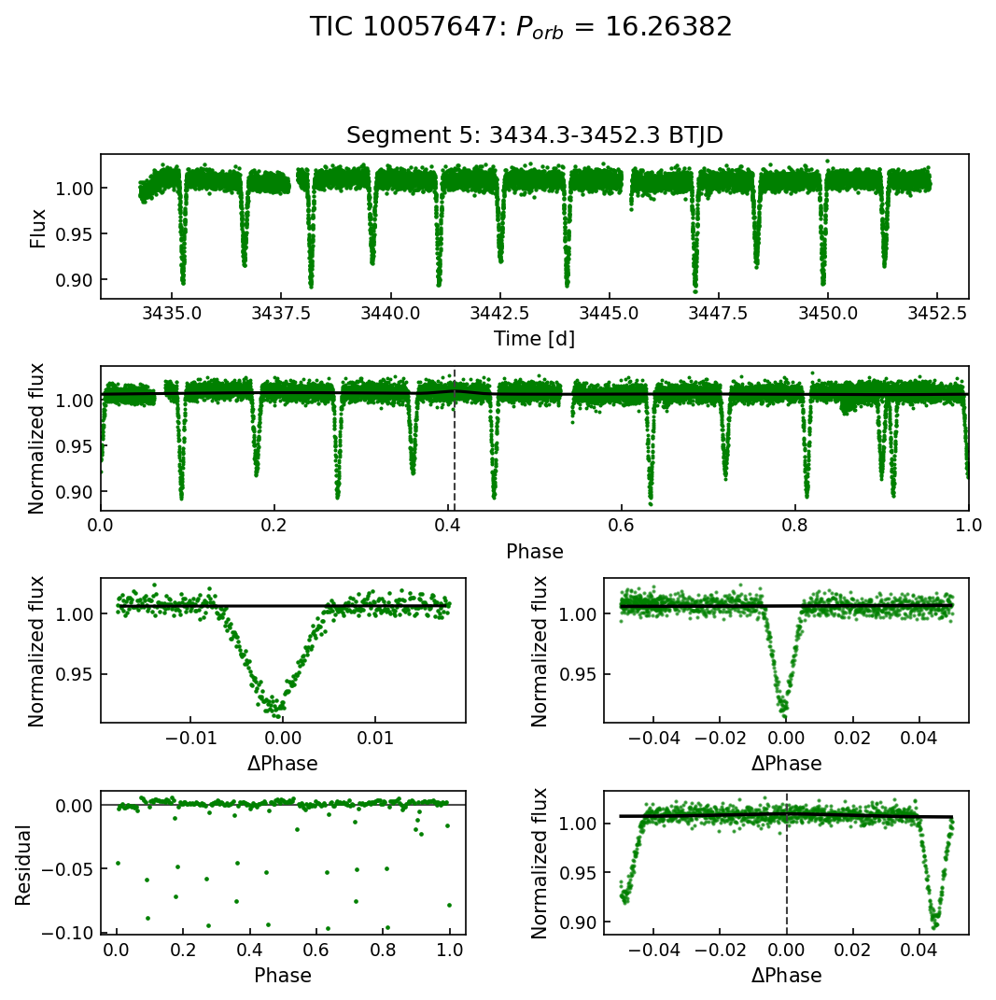

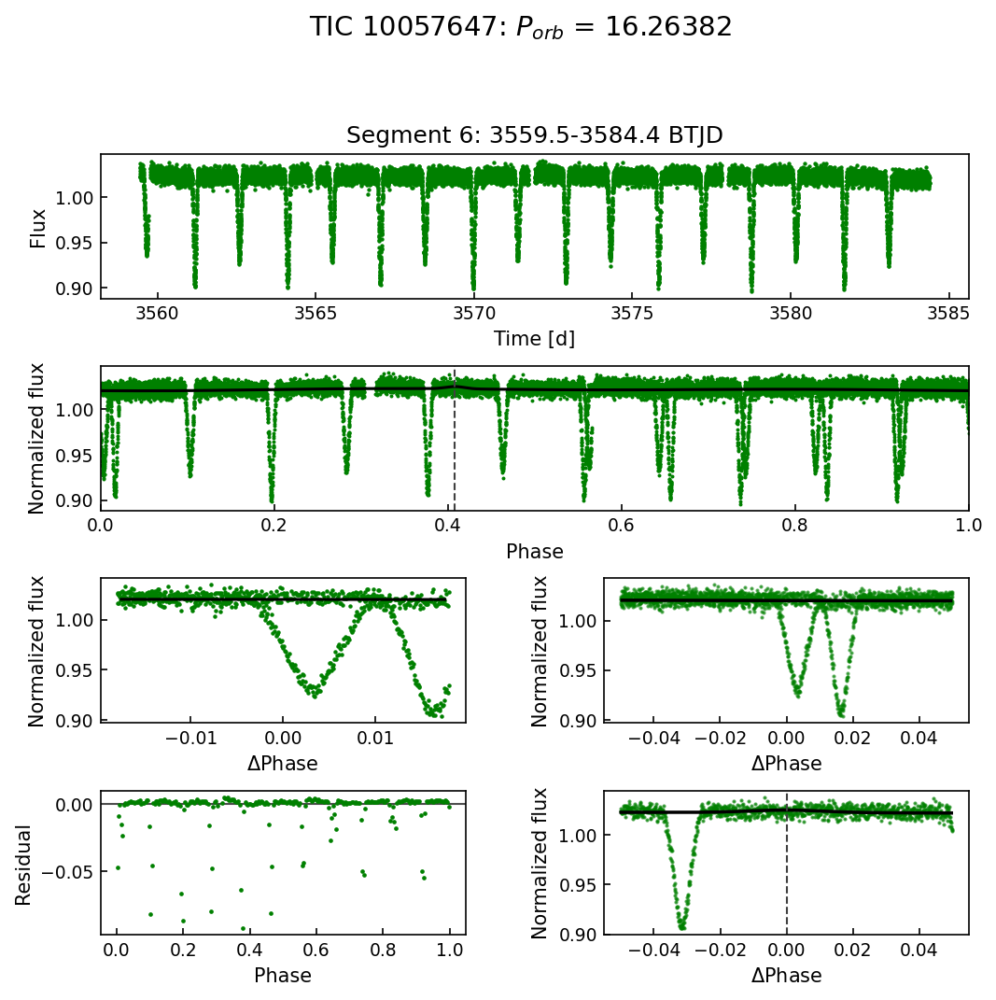

In [144]:
good_segments = [0, 1, 5, 6]

for seg_id in good_segments:
    seg = segments[seg_id]

    forward_model_seg = fit_comparison_model(
        t[seg],
        flux_norm[seg],
        best_row,
        nbins=250,
    )

    fig = plot_release_style_diagnostic(
        t[seg],
        flux_norm[seg],
        forward_model_seg,
        tic_id="10057647",
        sector_label=f"Segment {seg_id}: {np.min(t[seg]):.1f}-{np.max(t[seg]):.1f} BTJD",
        color="green",
        show_model=True,
    )

    fig.savefig(
        f"tess10057647_segment_{seg_id}_diagnostic.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

In [145]:
import sys
import importlib

helper_dir = "/Users/admin-victor/Documents/pyspedas_project/Precision Timing of Eclipsing Binaries from TESS Full Frame Images"
if helper_dir not in sys.path:
    sys.path.append(helper_dir)

import eb_forward_model
importlib.reload(eb_forward_model)

from eb_forward_model import plot_release_style_diagnostic

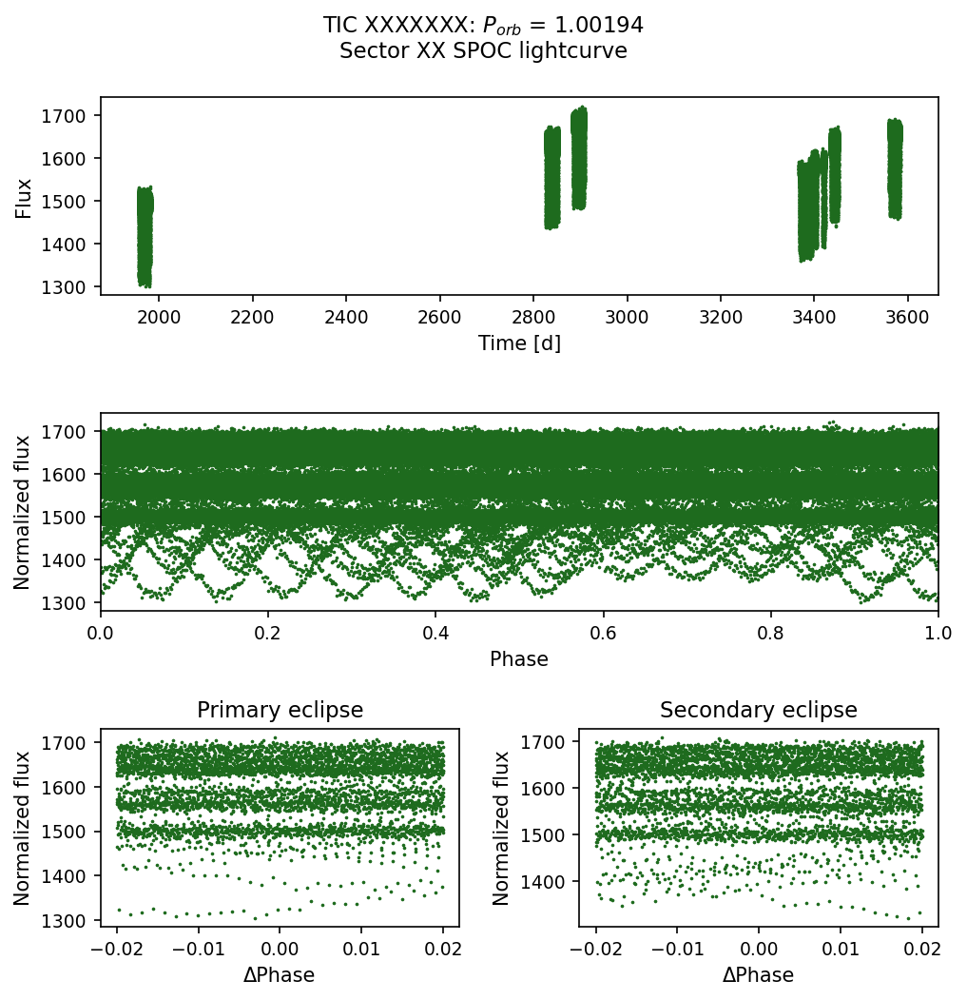

In [ ]:
# ── 1. Global style (replace your rcParams block) ──────────────────────────
import matplotlib.pyplot as plt
import matplotlib as mpl

GREEN = "#1e6b1e"   # the dark green from the target figure

plt.rcParams.update({
    "figure.dpi": 150,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "lines.markersize": 2,
    "axes.linewidth": 0.8,
    "axes.grid": False,
    "savefig.dpi": 300,
})

# ── 2. Phase convention: map to [0, 1) instead of [-0.5, 0.5) ─────────────
def phase_fold_01(t, T0, P):
    """Phase in [0, 1)"""
    return ((t - T0) / P) % 1.0

# ── 3. The multi-panel figure layout (matching the target) ─────────────────
fig = plt.figure(figsize=(7, 9))
fig.suptitle(f"TIC XXXXXXX: $P_{{orb}}$ = {P_fit:.5f}\nSector XX SPOC lightcurve",
             fontsize=11, y=0.98)

phi01 = phase_fold_01(t, T0_fit, P_fit)

# --- Panel 1: raw light curve (time domain) ---
ax1 = fig.add_subplot(4, 2, (1, 2))   # full-width top row
ax1.plot(t, flux, ".", ms=1.5, color=GREEN, rasterized=True)
ax1.set_xlabel("Time [d]")
ax1.set_ylabel("Flux")

# --- Panel 2: phase-folded, full phase 0-1 ---
ax2 = fig.add_subplot(4, 2, (3, 4))
ax2.plot(phi01, flux, ".", ms=1.5, color=GREEN, rasterized=True)
ax2.set_xlim(0, 1)
ax2.set_xlabel("Phase")
ax2.set_ylabel("Normalized flux")

# --- Panel 3 & 4: zoom around primary and secondary eclipses ---
# Primary eclipse: phase near 0 (or 1), expressed as ΔPhase
phi_centered = phi01.copy()
phi_centered[phi_centered > 0.5] -= 1.0   # re-center primary at 0

zoom_primary = 0.02   # adjust to your eclipse width
mask_p = np.abs(phi_centered) < zoom_primary

ax3 = fig.add_subplot(4, 2, 5)
ax3.plot(phi_centered[mask_p], flux[mask_p], ".", ms=1.5, color=GREEN)
ax3.set_xlabel("ΔPhase")
ax3.set_ylabel("Normalized flux")
ax3.set_title("Primary eclipse")

# Secondary eclipse: phase near 0.5
phi_sec = phi01 - 0.5   # center secondary at 0
phi_sec[phi_sec < -0.5] += 1.0

zoom_sec = 0.02
mask_s = np.abs(phi_sec) < zoom_sec

ax4 = fig.add_subplot(4, 2, 6)
ax4.plot(phi_sec[mask_s], flux[mask_s], ".", ms=1.5, color=GREEN)
ax4.set_xlabel("ΔPhase")
ax4.set_ylabel("Normalized flux")
ax4.set_title("Secondary eclipse")

plt.tight_layout()
plt.show()

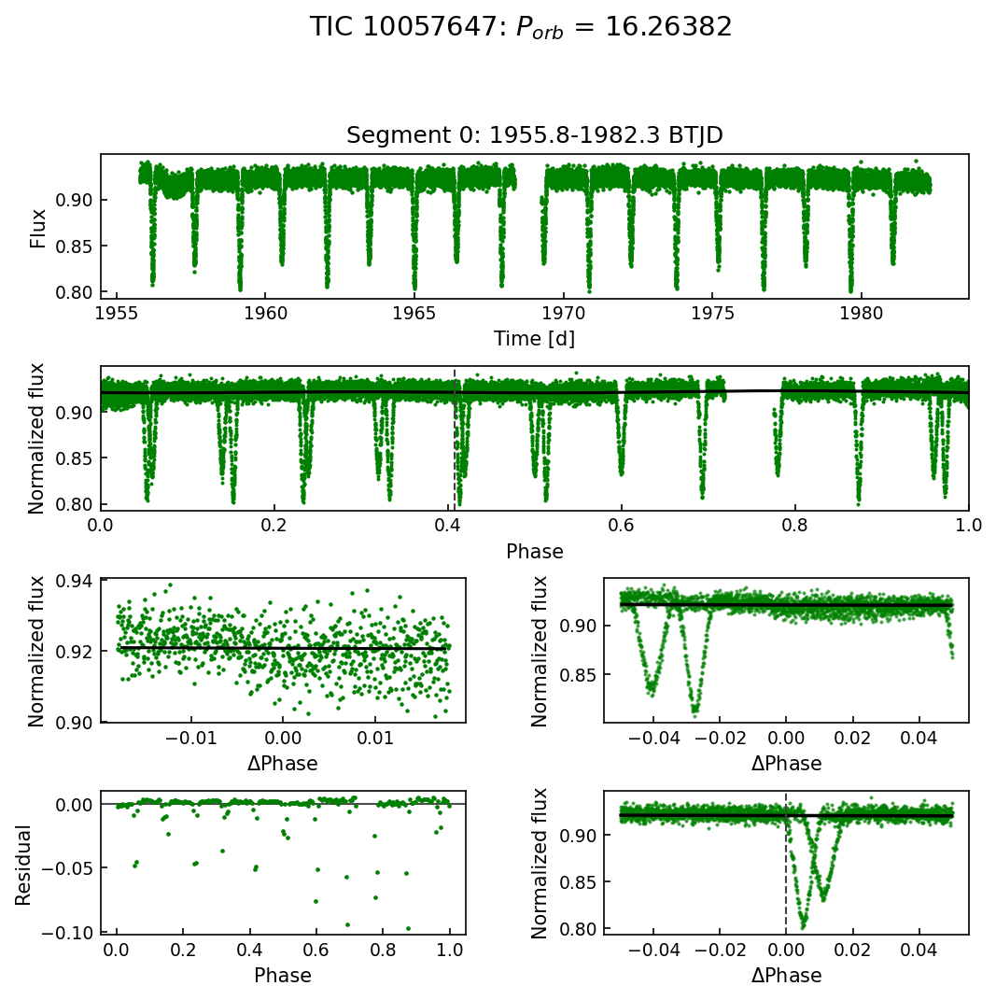

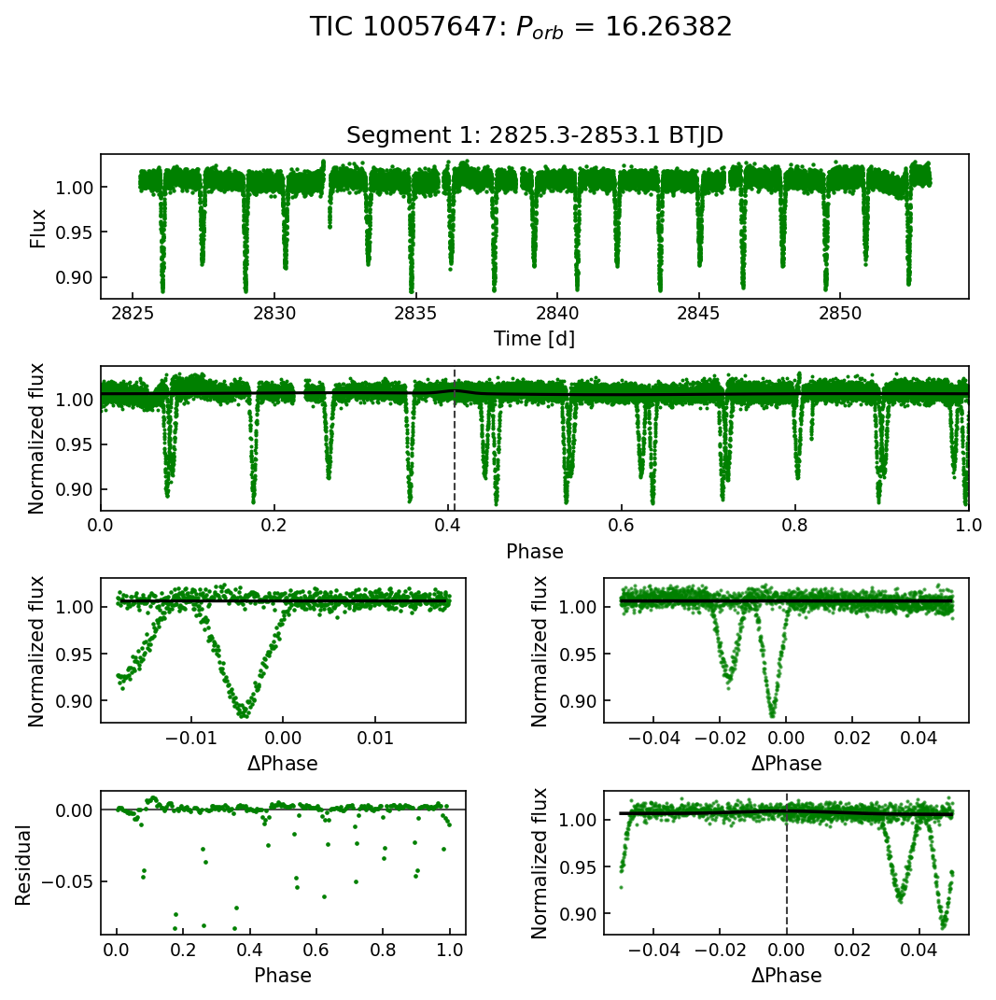

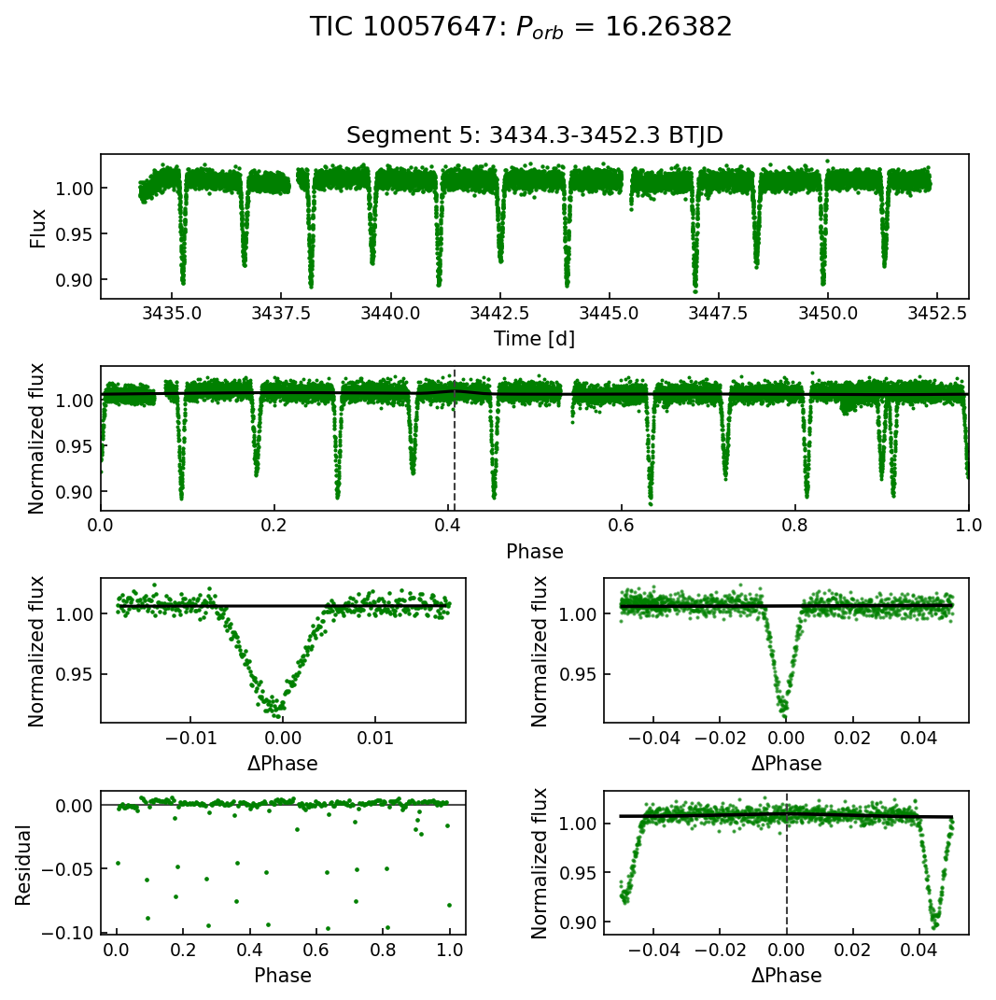

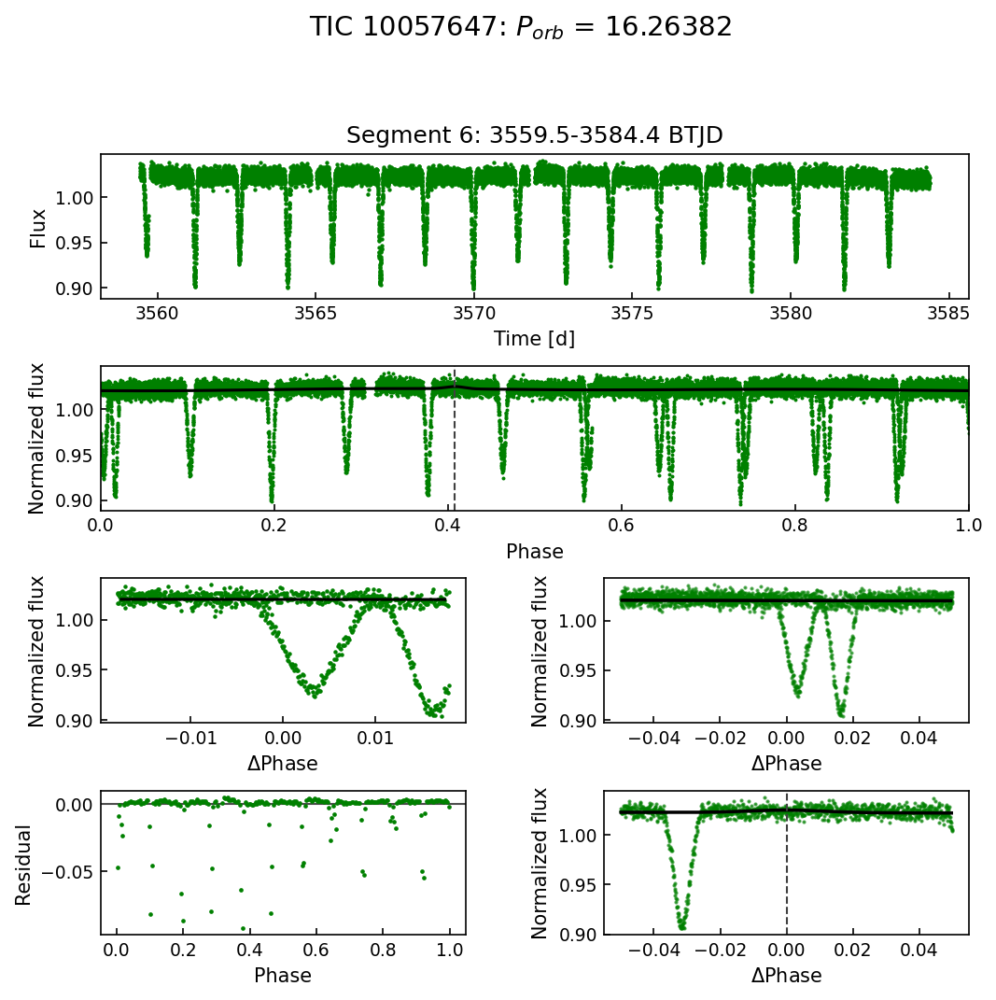

In [125]:
good_segments = [0, 1, 5, 6]

for seg_id in good_segments:
    seg = segments[seg_id]

    forward_model_seg = fit_comparison_model(
        t[seg],
        flux_norm[seg],
        best_row,
        nbins=250,
    )

    fig = plot_release_style_diagnostic(
        t[seg],
        flux_norm[seg],
        forward_model_seg,
        tic_id="10057647",
        sector_label=f"Segment {seg_id}: {np.min(t[seg]):.1f}-{np.max(t[seg]):.1f} BTJD",
        color="green",
        show_model=True,
    )

    fig.savefig(
        f"tess10057647_segment_{seg_id}_diagnostic.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

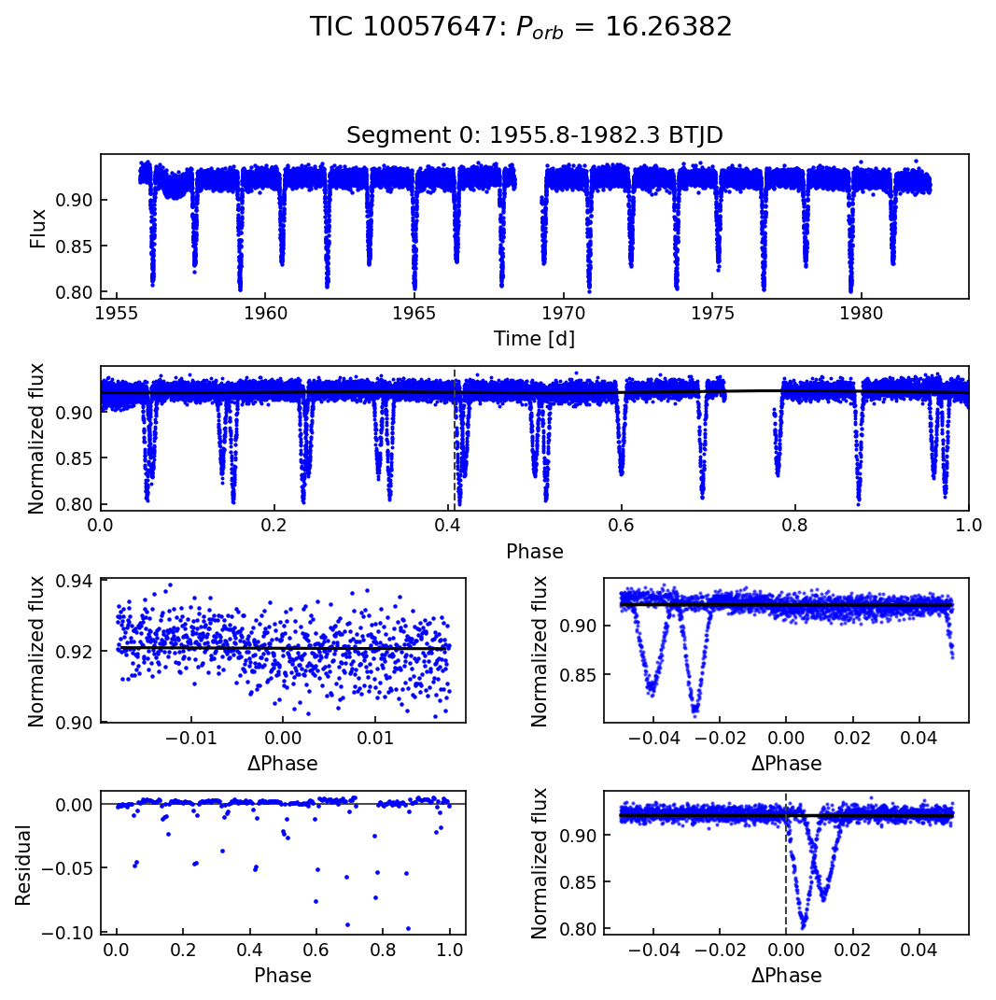

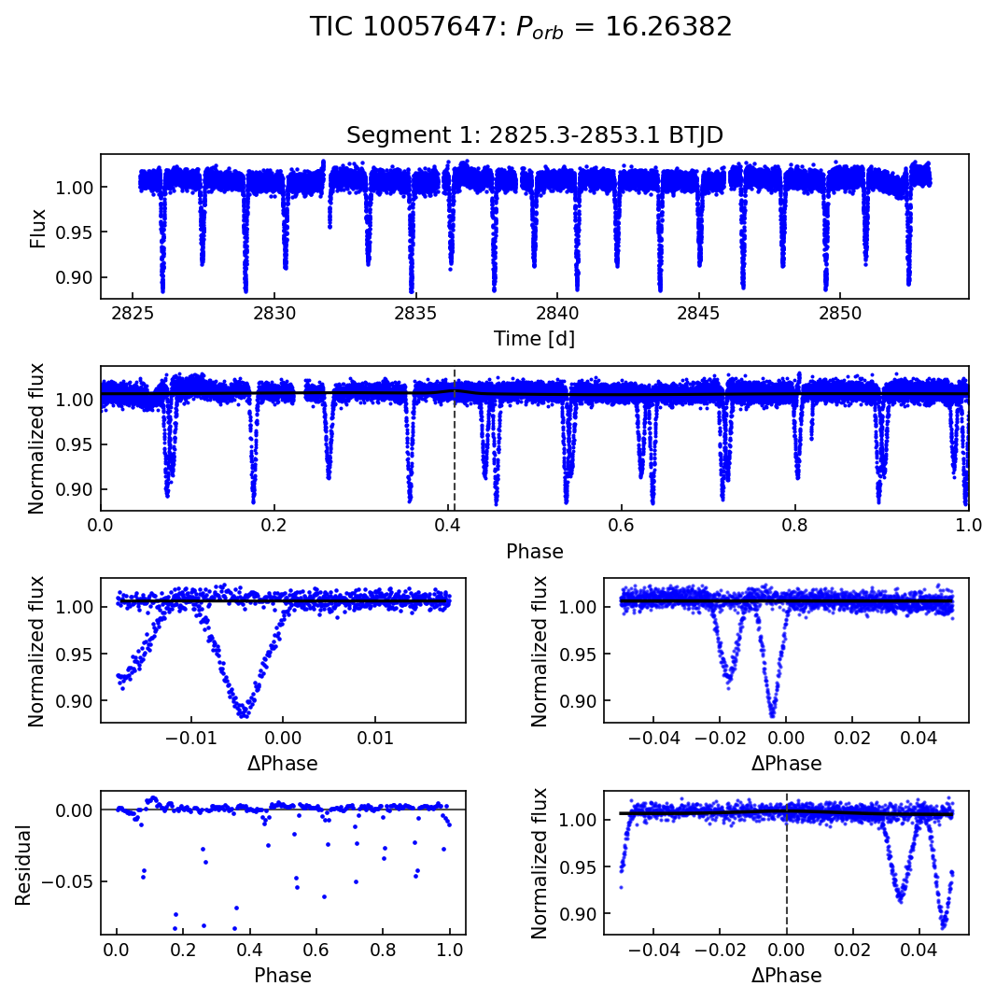

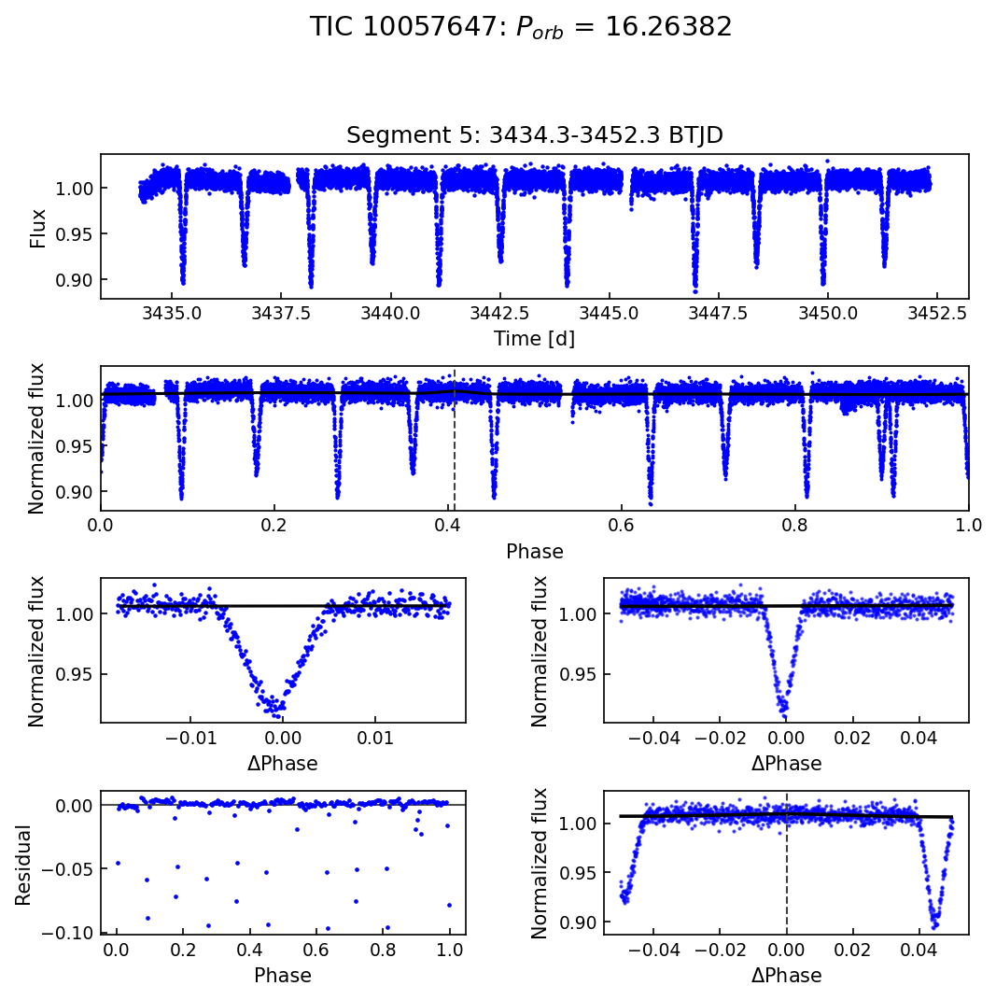

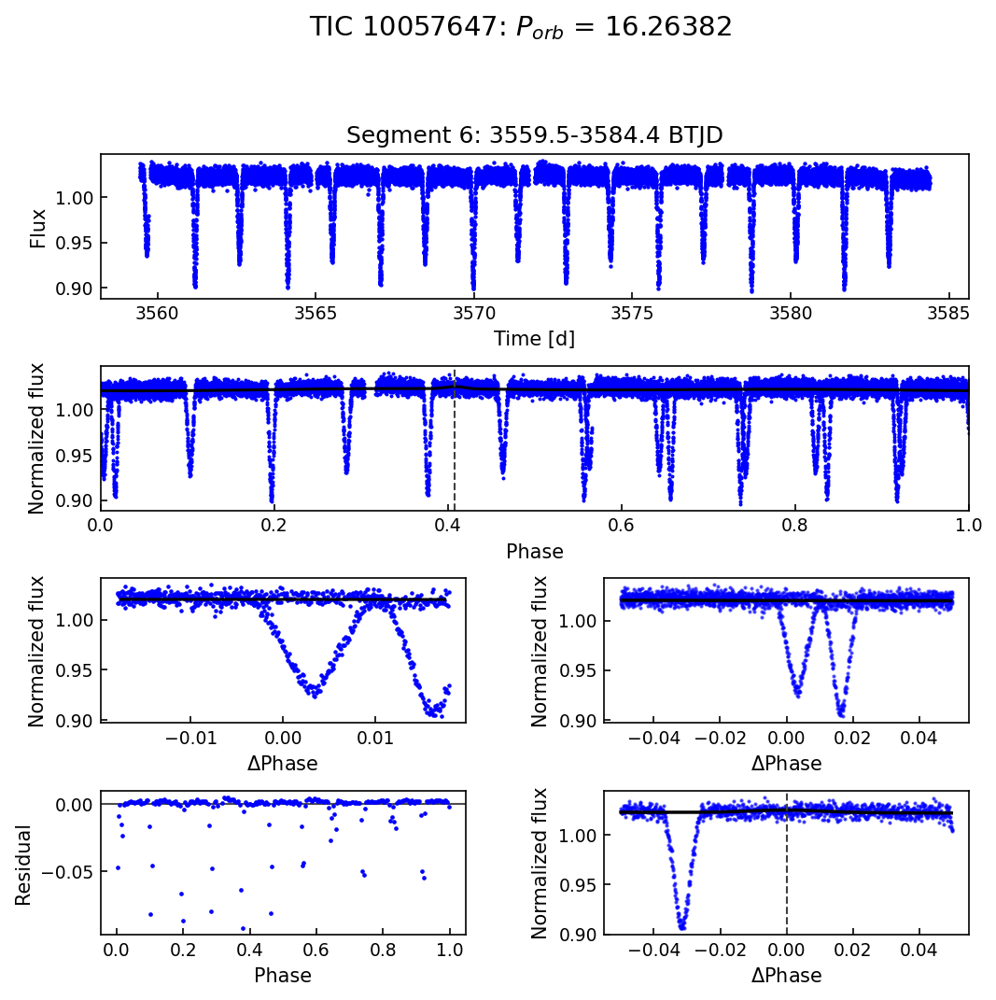

In [126]:
good_segments = [0, 1, 5, 6]

for seg_id in good_segments:
    seg = segments[seg_id]

    forward_model_seg = fit_comparison_model(
        t[seg],
        flux_norm[seg],
        best_row,
        nbins=250,
    )

    fig = plot_release_style_diagnostic(
        t[seg],
        flux_norm[seg],
        forward_model_seg,
        tic_id="10057647",
        sector_label=f"Segment {seg_id}: {np.min(t[seg]):.1f}-{np.max(t[seg]):.1f} BTJD",
        color="blue",
        show_model=True,
    )

    fig.savefig(
        f"tess10057647_segment_{seg_id}_diagnostic.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()